In [1]:
# 0.1 Settings: the notebook can be copied into any scenario folder
from pathlib import Path
import re
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

SCENARIO_DIR = Path.cwd()                              # folder containing this notebook
RUN_DIR  = SCENARIO_DIR / "model"                      # folder containing the results GDX
# Data-centre comparison with CHRONOHOUR = 1 (one step = one real hour) in both runs:
RESULTS  = "MainResults.gdx"           # results file name of this scenario
SCENARIO = SCENARIO_DIR.name               # scenario label

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from pybalmorel import MainResults
from IPython.display import display

res = MainResults(files=RESULTS, paths=str(RUN_DIR), scenario_names=[SCENARIO])

# Load the comparison/base results once; all later sections reuse base_res.
BASE_FOLDER   = "base_dc"     # base scenario folder (next to this one)
BASE_RESULTS  = "MainResults_fullweek.gdx"      # results file name of the base scenario
BASE_SCENARIO = BASE_FOLDER                # base label
BASE_DIR = SCENARIO_DIR.parent / BASE_FOLDER           # base inputs (data/) are read from here
BASE_RESULTS_DIR = BASE_DIR / "model"
if not (BASE_RESULTS_DIR / BASE_RESULTS).exists():
    raise FileNotFoundError(f"Base scenario results {BASE_RESULTS} not found in {BASE_RESULTS_DIR}")
base_res = MainResults(files=BASE_RESULTS, paths=str(BASE_RESULTS_DIR), scenario_names=[BASE_SCENARIO])

# Full-model GDX written next to the results: the one matching RESULTS for this scenario (MainResults_12h.gdx ->
# all_endofmodel_12h.gdx), BASE_ENDOFMODEL for the base. Used by 1.8 (data-centre flexibility), 9 and 12.
ENDOFMODEL = RESULTS.replace("MainResults", "all_endofmodel")
BASE_ENDOFMODEL = "all_endofmodel_fullweek.gdx"   # full-model GDX of the base scenario

def endofmodel_path(run_dir):
    """all_endofmodel GDX of the run in run_dir (this scenario or the base)."""
    return Path(run_dir) / (ENDOFMODEL if Path(run_dir) == RUN_DIR else BASE_ENDOFMODEL)

Loading /work3/s243704/Balmorel/Flex_1_1h/model/MainResults.gdx
Loading /work3/s243704/Balmorel/base_dc/model/MainResults_fullweek.gdx


In [2]:
# 0.2 Helpers shared by all sections

# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category",
          "SUBCATEGORY": "Subcategory", "UNITS": "Unit"}

def split_wind_fuel(df):
    """Fuel WIND is both onshore and offshore wind: split it by technology so that every chart and table says which one it shows."""
    if {"Fuel", "Technology"} <= set(df.columns):
        tech, fuel = df["Technology"].astype(str).str.upper(), df["Fuel"].astype(str)
        df = df.copy()
        df.loc[fuel.eq("WIND") & tech.str.contains("WIND_OFF|WIND-OFF"), "Fuel"] = "WIND_OFFSHORE"
        df.loc[fuel.eq("WIND") & tech.str.contains("WIND_ON|WIND-ON"), "Fuel"] = "WIND_ONSHORE"
    return df

def get(symbol):
    """Result symbol for SCENARIO as a DataFrame with standard column names."""
    df = res.get_result(symbol).rename(columns=RENAME)
    return split_wind_fuel(df[df["Scenario"] == SCENARIO])

# Technology types folded into groups (8 colours + grey for anything else)
TECH_GROUP = {
    "WIND-ON": "Onshore wind", "WIND-OFF": "Offshore wind",
    "SOLAR-PV": "Solar", "SOLAR-HEATING": "Solar",
    "HYDRO-RESERVOIRS": "Hydro", "HYDRO-RUN-OF-RIVER": "Hydro",
    "GNR_ST_NUCL_CND_E-33": "Nuclear",
    "GNR_BO_HYDROGEN_E-90": "Hydrogen", "GNR_ST_HYDROGEN_BP_CB-30": "Hydrogen",
    "CHP-BACK-PRESSURE": "CHP", "CHP-EXTRACTION": "CHP",
    "CONDENSING": "Condensing",
    "BOILERS": "Boilers",
    "ELECT-TO-HEAT": "Conversion", "ELECTROLYZER": "Conversion",
    "STEAMREFORMING": "Conversion", "BIOGASUPGRADING": "Conversion",
    "INTRASEASONAL-HEAT-STORAGE": "Storage", "INTERSEASONAL-HEAT-STORAGE": "Storage",
    "INTRASEASONAL-ELECT-STORAGE": "Storage", "H2-STORAGE": "Storage",
}
GROUP_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#1769aa", "Solar": "#eb6834", "Hydro": "#1baf7a", "Nuclear": "#6f42c1",
                "Biogas": "#8c6bb1", "Biomass": "#5a9e3d", "Heat": "#d1495b", "Hydrogen": "#00a6a6", "Natgas-CCS": "#7f7f7f", "CHP": "#eda100",
                "Condensing": "#e87ba4", "Boilers": "#008300", "Conversion": "#4a3aa7", "Storage": "#e34948",
                "Other": "#9a9992"}

# The members of the "Conversion" group, unpacked into their own segments (used by the hydrogen charts)
CONVERSION_TECH = {"ELECTROLYZER": "Electrolyzer", "STEAMREFORMING": "Steam reforming",
                   "BIOGASUPGRADING": "Biogas upgrading", "ELECT-TO-HEAT": "Electric-to-heat"}
CONVERSION_COLORS = {"Electrolyzer": "#4a3aa7", "Steam reforming": "#a24fb8",
                     "Biogas upgrading": "#7fb5e0", "Electric-to-heat": "#3aa7a0"}
GROUP_COLORS_UNPACKED = {**{g: c for g, c in GROUP_COLORS.items() if g != "Conversion"}, **CONVERSION_COLORS}

def tech_group(df, unpack=False):
    """Technology group per row; with unpack=True the Conversion technologies keep their own name."""
    technology = df["Technology"].fillna("").astype(str).str.upper()
    group = df["Technology"].map(TECH_GROUP).fillna("Other")
    group = group.mask(technology.str.contains("NGASCCS|NATGASCCS"), "Natgas-CCS")
    group = group.mask(technology.str.contains("WIND_OFF|WIND-OFF"), "Offshore wind")
    group = group.mask(technology.str.contains("WIND_ON|WIND-ON"), "Onshore wind")
    group = group.mask(technology.str.contains("BGAS|BIOGAS"), "Biogas")
    group = group.mask(technology.str.contains("WOOD|STRAW|BIOIL|BIOFUEL|PELLET|CHIP"), "Biomass")
    group = group.mask(technology.str.contains("HYDROGEN|GH2"), "Hydrogen")
    group = group.mask(technology.str.contains("HEAT") & ~technology.str.contains("STORAGE"), "Heat")
    if unpack:
        group = df["Technology"].map(CONVERSION_TECH).fillna(group)
    return group

def xrot(n_years):
    """Year tick-label rotation: horizontal for a few years, vertical when many years are solved."""
    return 0 if n_years <= 8 else 90

def stacked_bar(table, colors, title, ylabel, ax=None):
    """Stacked bar chart: one bar per row of `table` (years), one stack segment per column."""
    ax = ax or plt.subplots(figsize=(max(9, 0.5 * len(table) + 5), 4.5))[1]     # wider when many years are solved
    cols = [c for c in colors if c in table.columns]
    table[cols].plot.bar(stacked=True, ax=ax, color=[colors[c] for c in cols], width=0.7, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(table)))
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    return ax

def mix_by_year(df, commodity, unpack=False):
    """Year x technology-group table of df['Value'] for one commodity (unpack=True splits out Conversion)."""
    d = df[df["Commodity"] == commodity]
    return d.assign(Group=tech_group(d, unpack)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)


# One fixed colour order for everything that is not a technology group (years, fuels, countries)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY = "#9a9992"

def year_colors(n):
    """One colour per simulated year: the fixed palette for up to 8 years, a sequential colormap beyond that."""
    return PALETTE[:n] if n <= len(PALETTE) else [plt.cm.viridis(i / (n - 1)) for i in range(n)]

WIND_LABEL = {"WIND_ONSHORE": "Onshore wind", "WIND_OFFSHORE": "Offshore wind"}      # fuel WIND split by split_wind_fuel

def clean_name(s):
    return WIND_LABEL.get(str(s), str(s).replace("_", " ").title())

def country_bars(table, title, unit, n=10, ax=None):
    """Horizontal grouped bars: the n largest countries (by total over the years), one bar per year."""
    t = table.loc[table.sum(axis=1).sort_values(ascending=False).head(n).index].iloc[::-1]   # largest on top
    ax = ax or plt.subplots(figsize=(8, max(5, 0.12 * t.shape[1] * len(t) + 2)))[1]          # taller when many years
    t.plot.barh(ax=ax, color=year_colors(t.shape[1]), width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticklabels([clean_name(c) for c in t.index])
    ax.set_title(title, loc="left"); ax.set_xlabel(unit); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right", ncol=1 if t.shape[1] <= 10 else 2)
    return ax

def stacked_by_label(table, title, ylabel, n=7, ax=None):
    """Stacked bars per year; the n largest columns keep their own colour, the rest is summed as 'Other'."""
    order = table.sum().sort_values(ascending=False).index
    t = table[order[:n]].copy()
    if len(order) > n:
        t["Other"] = table[order[n:]].sum(axis=1)
    colors = dict(zip(t.columns, PALETTE[:n] + [GREY]))
    return stacked_bar(t, colors, title, ylabel, ax=ax)


In [3]:
# 0.3 Flexible loads: settings and the time-step results of this scenario in SFLEX_YEAR (used by the data-centre checks of 1.6.1 and by section 2.8)
import gams.transfer as gt
import geopandas as gpd
import pybalmorel
from matplotlib.colors import Normalize

SFLEX_LOADS = {"ENDOGENOUS_ELECT2HEAT": "Power-to-heat", "ENDO_H2": "Electrolysis", "ENDO_EV": "EV charging",
               "ENDO_INTRASTO": "Storage charging"}          # flexible categories of EL_DEMAND_YCR / EL_DEMAND_YCRST
SFLEX_ORDER = list(SFLEX_LOADS.values()) + ["DC shifted in"]   # stacking order; V2G and DC shifted out are drawn below zero
SFLEX_COLORS = {"Power-to-heat": "#1baf7a", "Electrolysis": "#4a3aa7", "EV charging": "#eb6834",
                "Storage charging": "#e34948", "V2G": "#f2a477", "DC shifted in": "#eda100", "DC shifted out": "#f6d27a"}
SFLEX_SOC = {"INTRASEASONAL-HEAT-STORAGE": "Heat storage (intra-seasonal)", "H2-STORAGE": "H2 storage",
             "INTRASEASONAL-ELECT-STORAGE": "Electricity storage"}   # storage types with a level in STORAGE_LEVEL
SFLEX_VRE = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]
SFLEX_SYMBOLS = ["EL_DEMAND_YCRST", "EL_PRICE_YCRST", "PRO_YCRAGFST", "STORAGE_LEVEL"]
SFLEX_RENAME = {**RENAME, "SSS": "Season", "TTT": "Time", "VARIABLE_CATEGORY": "Category", "value": "Value"}
SFLEX_KEYS = ["Region", "Season", "Time"]

sflex_years = sorted(get("EL_DEMAND_YCR")["Year"].astype(str).unique(), key=int)
SFLEX_YEAR = "2035" if "2035" in sflex_years else sflex_years[-1]

def sflex_style(ax, title, ylabel, axis="y"):
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.grid(axis=axis, alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)

# Time-step results of SFLEX_YEAR, with string labels and the column names of 0.2
sflex_c = gt.Container()
sflex_c.read(str(RUN_DIR / RESULTS), symbols=SFLEX_SYMBOLS)
sflex_raw = {}
for s in SFLEX_SYMBOLS:
    r = sflex_c[s].records
    r = r.loc[r["Y"].astype(str).eq(SFLEX_YEAR)]
    sflex_raw[s] = r.astype({col: str for col in r.columns[:-1]}).rename(columns=SFLEX_RENAME)
sflex_raw["PRO_YCRAGFST"] = sflex_raw["PRO_YCRAGFST"].loc[lambda d: d["Technology"].isin(SFLEX_VRE)]
del sflex_c
SFLEX_SEASONS = sorted(sflex_raw["EL_PRICE_YCRST"]["Season"].unique())
SFLEX_TIMES = sorted(sflex_raw["EL_PRICE_YCRST"]["Time"].unique())

# Hours per time step = CHRONOHOUR(S,T) of this scenario (data/CHRONOHOUR.inc), with card(T) filled in
SFLEX_STEP_H = 168 / len(SFLEX_TIMES)
inc = SCENARIO_DIR / "data" / "CHRONOHOUR.inc"
m = re.search(r"(?im)^\s*CHRONOHOUR\(S,T\)\s*=\s*([^;]+);", inc.read_text()) if inc.exists() else None
if m:
    expr = re.sub(r"(?i)card\(T\)", str(len(SFLEX_TIMES)), m.group(1))
    if re.fullmatch(r"[\d.\s+\-*/()]+", expr):
        SFLEX_STEP_H = float(eval(expr))

# Data-centre load shifting (dcflex add-on, DCFLEX = yes). MainResults.gdx only holds the net shift folded into the EXOGENOUS
# demand, so the shift variables are read from ENDOFMODEL (the all_endofmodel GDX matching RESULTS), for all solved years (MW per region and step):
# baseline DC load L (IDCF_L), shifted load served S (VDCF_S), deferred load D (VDCF_D) and backlog Y (VDCF_Y, + deferred,
# - advanced), plus the capacity C (IDCF_C) and IHOURSINST (hours per step in a year) to turn MW per step into annual energy
SFLEX_DC_SYMBOLS = {"IDCF_L": "Baseline", "VDCF_S": "Shifted in", "VDCF_D": "Deferred", "VDCF_Y": "Backlog"}
SFLEX_DC_KEYS = ["Year", "Region", "Season", "Time"]
try:
    sflex_c = gt.Container()
    sflex_c.read(str(RUN_DIR / ENDOFMODEL),
                 symbols=[*SFLEX_DC_SYMBOLS, "IDCF_C", "IHOURSINST", "DC_FLEXSHARE", "DC_SHIFTHORIZON", "DC_CAPFACTOR"])
    dc_rec = lambda s: sflex_c[s].records.astype({col: str for col in sflex_c[s].domain_names}).set_index(sflex_c[s].domain_names)
    sflex_dc_all = pd.concat({name: dc_rec(s)["value" if s == "IDCF_L" else "level"] for s, name in SFLEX_DC_SYMBOLS.items()},
                             axis=1).fillna(0).rename_axis(SFLEX_DC_KEYS)
    hours = dc_rec("IHOURSINST")["value"]
    sflex_dc_all["Hours"] = hours.reindex(sflex_dc_all.index.droplevel(["Year", "Region"])).to_numpy()
    sflex_dc_cap = dc_rec("IDCF_C")["value"].rename_axis(["Year", "Region"])                          # MW
    SFLEX_DC_PAR = {n: float(sflex_c[n].records["value"].iloc[0]) for n in ["DC_FLEXSHARE", "DC_SHIFTHORIZON", "DC_CAPFACTOR"]}
    del sflex_c
except Exception as exc:                                     # no ENDOFMODEL, or no dcflex add-on in this run
    print(f"No data-centre flexibility read from {RUN_DIR / ENDOFMODEL}: {exc}")
    sflex_dc_all = pd.DataFrame(columns=[*SFLEX_DC_SYMBOLS.values(), "Hours"], dtype=float,
                                index=pd.MultiIndex.from_tuples([], names=SFLEX_DC_KEYS))
    sflex_dc_cap = pd.Series(dtype=float, index=pd.MultiIndex.from_tuples([], names=["Year", "Region"]))
    SFLEX_DC_PAR = {}
sflex_dc_all["Net shift"] = sflex_dc_all["Shifted in"] - sflex_dc_all["Deferred"]
sflex_dc_all["Net in"] = sflex_dc_all["Net shift"].clip(lower=0)          # load moved into the step
sflex_dc_all["Net out"] = -sflex_dc_all["Net shift"].clip(upper=0)        # load moved out of the step
SFLEX_HAS_DC = sflex_dc_all["Baseline"].sum() > 0
sflex_dc = sflex_dc_all.loc[sflex_dc_all.index.get_level_values("Year") == SFLEX_YEAR].droplevel("Year")

def sflex_dc_twh(col, by=("Year",)):
    """Annual energy (TWh) of a column of sflex_dc_all (MW per step x hours per step), summed by the levels in `by`."""
    return (sflex_dc_all[col] * sflex_dc_all["Hours"]).groupby(level=list(by)).sum() / 1e6

# Per region, season and time step (MW): the flexible loads (EV charging and V2G = positive and negative part of the
# regional net EV demand), the total electricity demand, onshore + offshore wind + solar generation; and the price (Money/MWh)
sflex_price = sflex_raw["EL_PRICE_YCRST"].set_index(SFLEX_KEYS)["Value"]
sflex_dem = sflex_raw["EL_DEMAND_YCRST"].pivot_table(index=SFLEX_KEYS, columns="Category", values="Value", aggfunc="sum", fill_value=0)
sflex_dem = sflex_dem.reindex(sflex_price.index, fill_value=0)
# sflex_ prefix: section 8.1 reads the annual EV totals in `ev` (from 2.1), so this cell must not overwrite it
sflex_ev = sflex_dem["ENDO_EV"] if "ENDO_EV" in sflex_dem else pd.Series(0.0, index=sflex_dem.index)
sflex_h = pd.DataFrame({name: sflex_dem[cat] if cat in sflex_dem else 0.0 for cat, name in SFLEX_LOADS.items() if cat != "ENDO_EV"},
                       index=sflex_dem.index)
sflex_h["EV charging"] = sflex_ev.clip(lower=0)
sflex_h["V2G"] = -sflex_ev.clip(upper=0)
sflex_h["DC shifted in"] = sflex_dc["Net in"].reindex(sflex_h.index, fill_value=0)
sflex_h["DC shifted out"] = sflex_dc["Net out"].reindex(sflex_h.index, fill_value=0)
sflex_h["Total demand"] = sflex_dem.sum(axis=1)
sflex_h["Onshore + offshore wind + solar"] = sflex_raw["PRO_YCRAGFST"].groupby(SFLEX_KEYS)["Value"].sum().reindex(sflex_h.index, fill_value=0)
sflex_h["Price"] = sflex_price
print(f"{SCENARIO}: {SFLEX_STEP_H:.3f} h per time step, {len(SFLEX_SEASONS)} seasons x {len(SFLEX_TIMES)} steps; "
      f"hourly charts for {SFLEX_YEAR}")
print(f"Data-centre flexibility (dcflex): {SFLEX_DC_PAR if SFLEX_HAS_DC else 'not in this run'}")

Flex_1_1h: 1.000 h per time step, 4 seasons x 168 steps; hourly charts for 2035
Data-centre flexibility (dcflex): {'DC_FLEXSHARE': 0.2, 'DC_SHIFTHORIZON': 1.0, 'DC_CAPFACTOR': 1.2}


## 1. Validation: do the results make sense?
Checks that the solution is internally consistent and physically plausible. Every check is recorded as `PASS`, `WARN`, `FAIL` or `INFO` and collected in the summary table of 1.8.

| Section | What is checked |
|---|---|
| 1.1 Run | years and time resolution of the results |
| 1.2 - 1.4 Balance | supply = demand + net export for electricity (per region and time slice) and heat (per country and year); the electricity demand of every country is served |
| 1.5 Energy | annual energy dispatched = energy demand for electricity, heat, hydrogen and EV charging (net of storage and network losses, listed per year) |
| 1.6 Limits | no negative capacity or production, dispatch within capacity x 8760 h, transmission within capacity, storage levels within bounds, no negative onshore/offshore wind and solar curtailment |
| 1.6.1 Data centres | flexibility bounds of the `dcflex` add-on (Eq. 1-5 of Senga et al. 2026), annual data-centre energy = input `DE_DATACENTER`, peak power within the capacity, largest shift in one time step |
| 1.7 Plausibility | price range, implied plant efficiencies, missing values |

`FAIL` means the results are inconsistent and should not be used. `WARN` means something deserves a look but may be a property of the input data. Thresholds are set in each cell.

In [4]:
# 1.1 Run configuration (years and time resolution)
CHECKS = []          # every validation result is collected here and summarised in 1.8

def record(section, check, status, detail=""):
    """Register one validation result; status is PASS, WARN, FAIL or INFO."""
    CHECKS.append({"Section": section, "Check": check, "Status": status, "Detail": detail})

def grade(value, warn, fail):
    """PASS up to `warn`, WARN up to `fail`, FAIL above (value = size of the violation)."""
    return "PASS" if value <= warn else "WARN" if value <= fail else "FAIL"

MIN_SLICES = 24      # fewer time slices per year than this is flagged as a (probably test) coarse resolution

years = sorted(get("EL_DEMAND_YCR")["Year"].unique())
slices = get("EL_DEMAND_YCRST")[["Season", "Time"]].drop_duplicates()
resolution = f"{slices['Season'].nunique()} seasons x {slices['Time'].nunique()} time steps = {len(slices)} slices per year"
print(f"Years in the results : {', '.join(map(str, years))}")
print(f"Time resolution      : {resolution}")
record("Run", "Time resolution", "WARN" if len(slices) < MIN_SLICES else "INFO",
       resolution + (" - very coarse, compare only with runs at the same resolution" if len(slices) < MIN_SLICES else ""))

Years in the results : 2025, 2030, 2035
Time resolution      : 4 seasons x 168 time steps = 672 slices per year


In [5]:
# 1.2 Electricity balance per region and time slice (MWh): supply = demand + net export, so no demand is left unserved
def balance(df, area):
    """Per area and time slice (MWh): Supply, Demand, NetExport and Residual = Supply - Demand - NetExport.
    CURTAILMENT rows are informational (onshore/offshore wind and solar are reported net of curtailment) and PRICE rows are skipped."""
    df = df[df["Unit"] == "MWh"]
    t = df["Technology"]
    is_dem, is_exp, is_curt = t.str.startswith("DEMAND"), t.eq("NETEXPORT"), t.eq("CURTAILMENT")
    keys = ["Year", "Country", area, "Season", "Time"]
    out = df[keys].assign(Supply=df["Value"].where(~(is_dem | is_exp | is_curt), 0),
                          Demand=df["Value"].where(is_dem, 0),
                          NetExport=df["Value"].where(is_exp, 0)).groupby(keys).sum()
    out["Residual"] = out["Supply"] - out["Demand"] - out["NetExport"]
    return out

el_bal = balance(get("EL_BALANCE_YCRST"), "Region")
rel = el_bal["Residual"].abs() / el_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Electricity: supply = demand + net export in every region and time slice",
       grade(rel.max(), 1e-6, 1e-3), f"largest residual {el_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)")
unmet = el_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Electricity: no region-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(el_bal)} region-slices short of supply")


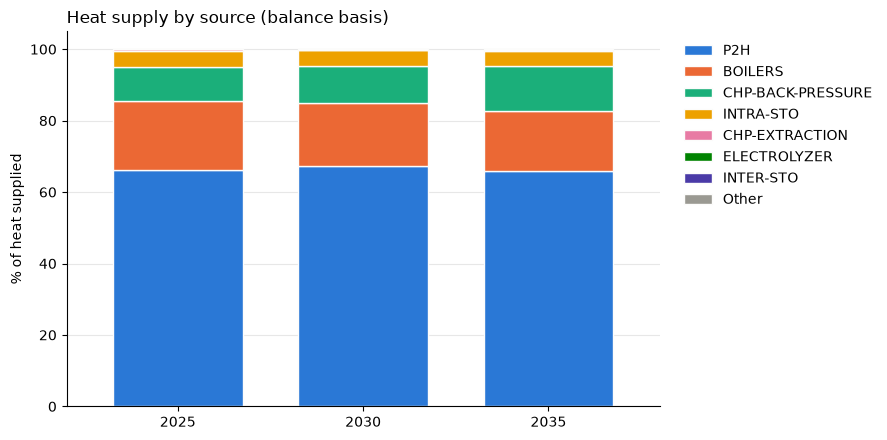

In [6]:
# 1.3 Heat balance per area and time slice (MWh): supply = demand + net export
# H_BALANCE_YCRAST has no row for the waste heat of electrolysers (a heat producer in PRO_YCRAGFST), so it is added to
# the supply here. Without it the balance is short by 1 - 3 % of the heat in countries with electrolysis.
h_bal = balance(get("H_BALANCE_YCRAST"), "Area")
elz = get("PRO_YCRAGFST").query("Commodity == 'HEAT' and Technology == 'ELECTROLYZER'")
elz = elz.groupby(["Year", "Country", "Area", "Season", "Time"])["Value"].sum()
h_bal["Supply"] += elz.reindex(h_bal.index).fillna(0)
h_bal["Residual"] = h_bal["Supply"] - h_bal["Demand"] - h_bal["NetExport"]
orphan = (~elz.index.isin(h_bal.index)).sum()                  # electrolyser heat in an area with no balance row

rel = h_bal["Residual"].abs() / h_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice",
       "FAIL" if orphan else grade(rel.max(), 1e-6, 1e-3),
       f"largest residual {h_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)"
       + (f"; {orphan} electrolyser heat entries have no matching balance row" if orphan else ""))
unmet = h_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Heat: no area-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(h_bal)} area-slices short of supply")

# Heat supply by source on the balance basis (% of all heat supplied); the balance closes, so this is also the demand mix
h_raw = get("H_BALANCE_YCRAST")
h_raw = h_raw[(h_raw["Unit"] == "MWh") & ~h_raw["Technology"].str.startswith("DEMAND")
              & ~h_raw["Technology"].isin(["NETEXPORT", "CURTAILMENT"])]
h_src = h_raw.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
h_src["ELECTROLYZER"] = elz.groupby("Year").sum().reindex(h_src.index).fillna(0)       # the source missing in the table
stacked_by_label(h_src.div(h_src.sum(axis=1), axis=0) * 100, "Heat supply by source (balance basis)", "% of heat supplied", n=7)
plt.tight_layout(); plt.show()


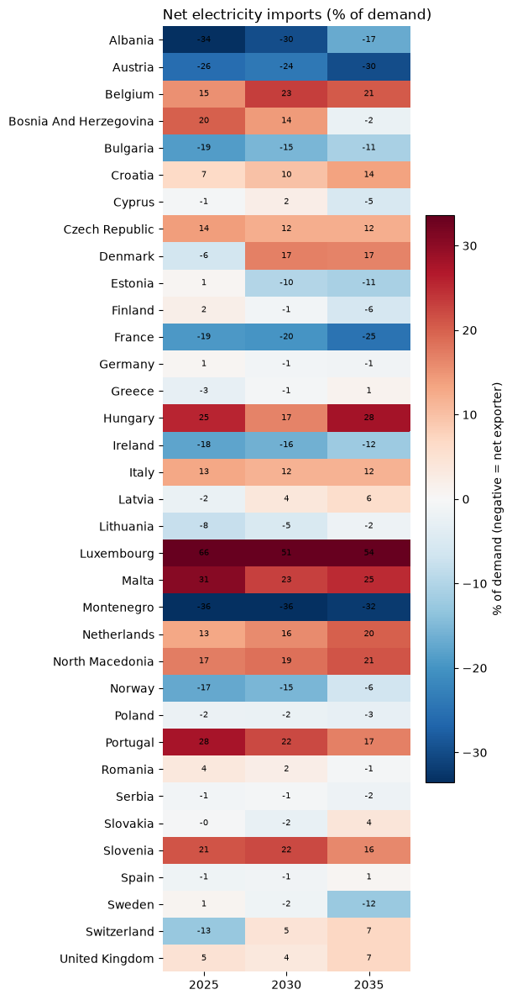

In [7]:
# 1.4 Is the electricity demand of every country supplied? Coverage = (domestic supply - net export) / demand
el_cy = el_bal.groupby(["Year", "Country"])[["Supply", "Demand", "NetExport"]].sum()
coverage = ((el_cy["Supply"] - el_cy["NetExport"]) / el_cy["Demand"] * 100).unstack("Year")        # % of demand served
imports = (-el_cy["NetExport"] / el_cy["Demand"] * 100).unstack("Year")                           # >0 net importer, <0 net exporter
record("Balance", "Electricity: demand of every country served (domestic supply + net imports)",
       grade((coverage - 100).abs().max().max() / 100, 1e-6, 1e-3),
       f"coverage {coverage.min().min():.4f} - {coverage.max().max():.4f} % across {len(coverage)} countries and {coverage.shape[1]} years")

# Net import dependence per country and year (% of electricity demand): red = importer, blue = exporter
fig, ax = plt.subplots(figsize=(max(6, 1.0 * imports.shape[1] + 3), 0.3 * len(imports) + 1.5))
lim = max(10, np.nanpercentile(imports.abs().values, 95))
im = ax.imshow(imports.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(imports.shape[1])); ax.set_xticklabels(imports.columns)
ax.set_yticks(range(len(imports))); ax.set_yticklabels([clean_name(c) for c in imports.index])
for i in range(imports.shape[0]):
    for j in range(imports.shape[1]):
        ax.text(j, i, f"{imports.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Net electricity imports (% of demand)", loc="left")
for side in ax.spines.values(): side.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of demand (negative = net exporter)")
plt.tight_layout(); plt.show()


In [8]:
# 1.5 Energy dispatched = energy demand per carrier and year (TWh): electricity, heat, hydrogen and EV charging
# Dispatched = production of the carrier in PRO_YCRAGF without storage discharge. Demand = every category of the
# annual demand table (final demand, endogenous demand, net storage loss = charging - discharging, network losses). Net export is not added: the
# system-wide NETEXPORT of the balance tables is the transmission loss, which is already a demand category.
ENERGY_WARN, ENERGY_FAIL = 1e-3, 1e-2        # relative gap (of the larger of dispatch and demand) for PASS / WARN; above is FAIL

def annual(symbol):
    """Annual total per year of a result symbol, or None when the symbol is missing or empty in this run."""
    try:
        table = get(symbol)
    except Exception:
        return None
    return table.groupby("Year")["Value"].sum() if len(table) else None

dispatch = get("PRO_YCRAGF")
CARRIERS = {"Electricity": ("ELECTRICITY", "EL_DEMAND_YCR"), "Heat": ("HEAT", "H_DEMAND_YCRA"), "Hydrogen": ("HYDROGEN", "H2_DEMAND_YCR")}
parts = {}
for name, (commodity, symbol) in CARRIERS.items():
    p = dispatch[dispatch["Commodity"] == commodity]
    is_sto = p["Technology"].str.contains("STORAGE")
    parts[name] = pd.DataFrame({"Dispatched": p[~is_sto].groupby("Year")["Value"].sum(),
                                "Demand": get(symbol).groupby("Year")["Value"].sum(),
                                "Storage output": p[is_sto].groupby("Year")["Value"].sum()}).fillna(0)

# EV: energy delivered to the vehicles from the grid (charging minus discharging back) = EV charging demand (ENDO_EV)
ev_demand = get("EL_DEMAND_YCR").query("Category == 'ENDO_EV'").groupby("Year")["Value"].sum()
g2v, v2g, ev_net = annual("EV_G2V_Y"), annual("EV_V2G_Y"), annual("EV_NET_Y")
if g2v is None:
    ev_status = "INFO" if ev_demand.abs().max() < 1e-9 else "WARN"
    record("Energy", "EV: grid energy delivered = EV charging demand", ev_status,
           "no EV demand in this run" if ev_status == "INFO" else "EV_G2V_Y is missing - rerun the scenario after updating OUTPUT_SUMMARY.inc")
else:
    delivered = g2v.sub(v2g if v2g is not None else 0, fill_value=0)
    parts["EV charging"] = pd.DataFrame({"Dispatched": delivered, "Demand": ev_demand, "Storage output": 0.0}).fillna(0)

energy = pd.concat(parts, names=["Carrier"])
energy["Residual"] = energy["Dispatched"] - energy["Demand"]
energy["Gap"] = energy["Residual"].abs() / energy[["Dispatched", "Demand"]].max(axis=1).clip(lower=1e-9)

for name in CARRIERS:
    e = energy.loc[name]
    worst = e["Gap"].idxmax()
    detail = f"largest gap {e.loc[worst, 'Residual']:+.2f} TWh ({e['Gap'].max():.2%} of the flow, {worst})"
    if e["Gap"].max() > 1e-6 and ((e["Residual"] - e["Storage output"]).abs() <= 1e-3 * e[["Dispatched", "Demand"]].max(axis=1)).all():
        detail += (" - equals the storage discharge in every year, so the storage charging in the annual demand table looks incomplete"
                   " (the time-sliced balances in 1.2 / 1.3 close)")
    record("Energy", f"{name}: energy dispatched = energy demand (all years)", grade(e["Gap"].max(), ENERGY_WARN, ENERGY_FAIL), detail)

if "EV charging" in energy.index.get_level_values("Carrier"):
    e = energy.loc["EV charging"]
    net_gap = (ev_net.reindex(e.index).fillna(0) - e["Demand"]).abs().max() if ev_net is not None else np.nan
    record("Energy", "EV: grid energy delivered (charging - discharging) = EV charging demand",
           grade(max(e["Gap"].max(), 0 if np.isnan(net_gap) else net_gap / max(e["Demand"].max(), 1e-9)), 1e-6, 1e-3),
           f"largest gap {e['Residual'].abs().max():.3g} TWh on {e['Demand'].sum():.1f} TWh of EV demand"
           + ("" if ev_net is not None else "; EV_NET_Y missing, net exchange not cross-checked"))

display(energy.drop(columns="Gap").assign(**{"Residual %": energy["Residual"] / energy[["Dispatched", "Demand"]].max(axis=1).clip(lower=1e-9) * 100}).round(3))

Dispatched    Demand  Storage output  Residual  Residual %
Carrier     Year                                                            
Electricity 2025    4589.194  4589.194          26.293      -0.0        -0.0
            2030    4786.321  4786.321          20.339      -0.0        -0.0
            2035    4951.038  4951.038          18.141      -0.0        -0.0
Heat        2025    6130.303  6130.303         299.996       0.0         0.0
            2030    6129.674  6129.674         280.891      -0.0        -0.0
            2035    6130.241  6130.241         274.055      -0.0        -0.0
Hydrogen    2025     144.942   144.942           8.816       0.0         0.0
            2030     358.068   358.068          56.307       0.0         0.0
            2035     717.524   717.524          52.788      -0.0        -0.0
EV charging 2030      82.717    82.717           0.000       0.0         0.0
            2035     170.268   170.268           0.000       0.0         0.0

In [9]:
# 1.6 Physical limits: capacity, dispatch, transmission, storage and curtailment must respect their bounds
cap, pro = get("G_CAP_YCRAF"), get("PRO_YCRAGF")

cap_gen = cap.groupby(["Year", "Generation", "Region", "Area"])["Value"].sum()
record("Limits", "Installed capacity never negative", "FAIL" if (cap_gen < -1e-6).any() else "PASS",
       f"{(cap_gen < -1e-6).sum()} generators below zero (smallest {cap_gen.min():.2g} GW)")
record("Limits", "Production never negative", "FAIL" if (pro["Value"] < -1e-6).any() else "PASS",
       f"{(pro['Value'] < -1e-6).sum()} generator rows below zero")

# Annual production <= installed capacity x 8760 h. Hydrogen is skipped: reforming capacity is stated on a fuel basis
for commodity in ["ELECTRICITY", "HEAT"]:
    c = cap[cap["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    p = pro[pro["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    c = c.reindex(p.index).fillna(0)
    no_cap = ((p > 1e-6) & (c <= 1e-9)).sum()
    util = (p[c > 1e-9] / (c[c > 1e-9] * 8.76))                       # TWh / (GW x 8.76 TWh per GW-year)
    record("Limits", f"{commodity.title()}: production within capacity x 8760 h",
           "FAIL" if no_cap else grade(util.max() - 1, 1e-3, 5e-2),
           f"highest utilisation {util.max():.1%}; {no_cap} generators produce without installed capacity")

# Transmission: annual flow <= capacity x 8760 h (electricity lines and hydrogen pipelines)
for label, flow_sym, cap_sym in [("Electricity", "X_FLOW_YCR", "X_CAP_YCR"), ("Hydrogen", "XH2_FLOW_YCR", "XH2_CAP_YCR")]:
    f = get(flow_sym).groupby(["Year", "From", "To"])["Value"].sum()
    c = get(cap_sym).groupby(["Year", "From", "To"])["Value"].sum().reindex(f.index)
    u = f / (c * 8.76)
    no_cap = (f.gt(1e-6) & c.fillna(0).le(1e-9)).sum()
    record("Limits", f"{label} transmission: flow within capacity x 8760 h",
           "FAIL" if no_cap else grade(u[c > 1e-9].max() - 1, 1e-3, 5e-2),
           f"highest line utilisation {u[c > 1e-9].max():.1%}; {no_cap} links carry flow without capacity")

# Storage: level between zero and the installed storage capacity (level in MWh, capacity in GWh)
lvl = get("STORAGE_LEVEL").groupby(["Year", "Generation", "Area"])["Value"].agg(["min", "max"])
sto = get("G_STO_YCRAF").groupby(["Year", "Generation", "Area"])["Value"].sum() * 1000
lvl["cap"] = sto.reindex(lvl.index).fillna(0)                         # no capacity record = zero capacity
over = lvl["max"] > lvl["cap"] * 1.001 + 1e-3                         # 1e-3 MWh absorbs solver round-off
below = lvl["min"] < -1e-3
record("Limits", "Storage level between zero and capacity", "FAIL" if (over | below).any() else "PASS",
       f"{over.sum()} storages above capacity, {below.sum()} below zero, of {len(lvl)}")

# Curtailment of onshore wind, offshore wind and solar is a positive quantity (hydro reservoirs net to about zero and are excluded)
curt_vre = get("CURT_YCRAGF").query("Technology in ['WIND-ON', 'WIND-OFF', 'SOLAR-PV']")
record("Limits", "Onshore wind, offshore wind and solar curtailment not negative", "FAIL" if (curt_vre["Value"] < -1e-6).any() else "PASS",
       f"{(curt_vre['Value'] < -1e-6).sum()} rows below zero")


#### 1.6.1 Data-centre flexibility: bounds, annual energy, peak power and the largest shift per time step
Checks of the `dcflex` add-on on the shift variables read in 0.3 (`ENDOFMODEL`, all solved years, every region and time step), with *L* = baseline data-centre load, *S* = shifted load served, *D* = deferred load, *Y* = backlog, *C* = capacity, *s* = `DC_FLEXSHARE`, *h* = `DC_SHIFTHORIZON`:
- **Flexibility bounds** (Senga et al. 2026): *D* ≤ *s·L* (Eq. 4); served load *L + S − D* ≤ *C* (Eq. 5); served load ≥ (1 − *s*)·*L*; *S*, *D* ≥ 0; backlog balance *Y*<sub>t</sub> = *Y*<sub>t−1</sub> − *S*<sub>t</sub> + *D*<sub>t</sub> (Eq. 1, circular within each season); deferred load served within *h* steps, Σ<sub>t+1..t+h</sub> *S* ≥ *Y*<sub>t</sub> (Eq. 2); advanced load offset within *h* steps, Σ<sub>t+1..t+h</sub> *D* ≥ −*Y*<sub>t</sub> (Eq. 3).
- **Annual energy**: the shift nets to zero in every season, and the annual data-centre energy served (Σ served load × `IHOURSINST`) equals both the baseline and the input table `DE_DATACENTER.inc` (the scenario's `data/`, otherwise `base/data`).
- **Peak power**: the highest served load per region against the capacity *C* = `DC_CAPFACTOR` × peak baseline load, and for all regions together.
- **Largest shift in one time step**: the most load moved into or out of a single step (net shift, MW and % of the baseline load), against its limits *C − L* (in) and *s·L* (out).

Violations up to `DC_TOL` (MW) are solver tolerance (`PASS`); up to 1 MW `WARN`; above that `FAIL`.

In [10]:
# 1.6.1 Data-centre flexibility (dcflex): flexibility bounds, annual energy, peak power and the largest shift in one time step
DC_TOL = 1e-3                                                # MW: violations up to this size are solver tolerance

def read_gams_table(path):
    """Two-dimensional GAMS TABLE (row labels x column labels) of an .inc file as a DataFrame."""
    lines = path.read_text().splitlines()
    start = next(k for k, line in enumerate(lines) if line.strip().upper().startswith("TABLE"))
    cols = lines[start + 1].split()
    rows = {}
    for line in lines[start + 2:]:
        if line.strip().startswith(";"):
            break
        parts = line.split()
        if len(parts) == len(cols) + 1:
            rows[parts[0]] = [float(x) for x in parts[1:]]
    return pd.DataFrame.from_dict(rows, orient="index", columns=cols)

if not SFLEX_HAS_DC:
    record("DC flexibility", "dcflex results", "INFO", f"no data-centre flexibility read from {ENDOFMODEL} (0.3)")
else:
    s, h, cf = (SFLEX_DC_PAR[k] for k in ["DC_FLEXSHARE", "DC_SHIFTHORIZON", "DC_CAPFACTOR"])
    d = sflex_dc_all.copy()
    d["Served"] = d["Baseline"] + d["Net shift"]
    d["Capacity"] = sflex_dc_cap.reindex(d.index.droplevel(["Season", "Time"])).to_numpy()
    record("DC flexibility", "Parameters", "INFO",
           f"s = {s:g}, h = {h:g} steps ({h * SFLEX_STEP_H:g} h), C = {cf:g} x peak baseline load; {ENDOFMODEL}, years {', '.join(sflex_years)}")

    def check(name, violation, unit="MW"):
        """Record the largest violation (> 0 = bound broken) of one bound over all years, regions and time steps."""
        v = float(np.nanmax(violation))
        record("DC flexibility", name, grade(v, DC_TOL, 1.0), f"largest violation {max(v, 0):.2g} {unit}")

    # --- Bounds per step: Eq. 4, Eq. 5, floor of the served load, non-negativity
    check("Deferred load D <= s x L (Eq. 4)", d["Deferred"] - s * d["Baseline"])
    check("Served load L + S - D <= capacity C (Eq. 5)", d["Served"] - d["Capacity"])
    check("Served load >= (1 - s) x L", (1 - s) * d["Baseline"] - d["Served"])
    check("S and D never negative", -d[["Shifted in", "Deferred"]].min(axis=1))

    # --- Backlog and shifting window, circular within each season (rows: year, region, season; columns: time steps)
    wide = {c: d[c].unstack("Time").reindex(columns=SFLEX_TIMES).fillna(0).to_numpy() for c in ["Shifted in", "Deferred", "Backlog"]}
    S_, D_, Y_ = wide["Shifted in"], wide["Deferred"], wide["Backlog"]
    ahead = lambda a: sum(np.roll(a, -k, axis=1) for k in range(1, int(h) + 1))     # sum over t+1 .. t+h
    check("Backlog balance Y(t) = Y(t-1) - S(t) + D(t) (Eq. 1)", np.abs(Y_ - (np.roll(Y_, 1, axis=1) - S_ + D_)))
    check(f"Deferred load served within h = {h:g} steps (Eq. 2)", Y_ - ahead(S_))
    check(f"Advanced load offset within h = {h:g} steps (Eq. 3)", -Y_ - ahead(D_))
    check("Shift nets to zero in every season", np.abs((S_ - D_).sum(axis=1)), unit="MW x step")

    # --- Annual energy (TWh): served = baseline = input table DE_DATACENTER
    twh = lambda col: (d[col] * d["Hours"]).groupby(level=["Year", "Region"]).sum() / 1e6
    energy = pd.DataFrame({"Served (TWh)": twh("Served"), "Baseline (TWh)": twh("Baseline")})
    de_file = SCENARIO_DIR / "data" / "DE_DATACENTER.inc"
    de_input = read_gams_table(de_file).stack().rename_axis(["Region", "Year"]).swaplevel() / 1e6
    energy["Input DE_DATACENTER (TWh)"] = de_input.reindex(energy.index)
    rel = lambda a, b: float((a - b).abs().max() / max(b.abs().max(), 1e-9))
    record("DC flexibility", "Annual DC energy served = baseline (energy preserved)",
           grade(rel(energy["Served (TWh)"], energy["Baseline (TWh)"]), 1e-6, 1e-3),
           f"largest difference {(energy['Served (TWh)'] - energy['Baseline (TWh)']).abs().max():.2g} TWh in a region-year")
    missing = int(energy["Input DE_DATACENTER (TWh)"].isna().sum())
    record("DC flexibility", f"Annual DC energy = input {de_file.parent.parent.name}/data/{de_file.name}",
           "FAIL" if missing else grade(rel(energy["Served (TWh)"], energy["Input DE_DATACENTER (TWh)"]), 1e-6, 1e-3),
           f"largest difference {(energy['Served (TWh)'] - energy['Input DE_DATACENTER (TWh)']).abs().max():.2g} TWh; "
           f"{missing} modelled region-years missing in the input")

    # --- Peak power and the largest shift in one step, per region and year (MW)
    d["Headroom C - L"] = d["Capacity"] - d["Baseline"]
    g = d.groupby(level=["Year", "Region"])
    region = pd.DataFrame({
        "Peak baseline L (MW)": g["Baseline"].max(),
        "Peak served load (MW)": g["Served"].max(),
        "Capacity C (MW)": g["Capacity"].first(),
        "Max shifted in, 1 step (MW)": g["Net in"].max(),
        "Max shifted out, 1 step (MW)": g["Net out"].max(),
        "Max shifted in (% of L)": (100 * d["Net in"] / d["Baseline"].replace(0, np.nan)).groupby(level=["Year", "Region"]).max(),
        "Max shifted out (% of L)": (100 * d["Net out"] / d["Baseline"].replace(0, np.nan)).groupby(level=["Year", "Region"]).max(),
    })
    region["Peak served / peak L"] = region["Peak served load (MW)"] / region["Peak baseline L (MW)"]
    worst = region["Peak served / peak L"].idxmax()
    record("DC flexibility", f"Peak served load <= C = {cf:g} x peak baseline (per region)",
           grade(float((region["Peak served load (MW)"] - region["Capacity C (MW)"]).max()), DC_TOL, 1.0),
           f"highest peak served / peak baseline {region['Peak served / peak L'].max():.3f} ({worst[1]}, {worst[0]})")
    check("Shift into a step <= headroom C - L", d["Net in"] - d["Headroom C - L"])
    check("Shift out of a step <= s x L", d["Net out"] - s * d["Baseline"])
    record("DC flexibility", "Largest shift in one step (per region)", "INFO",
           f"in: {region['Max shifted in, 1 step (MW)'].max():,.0f} MW ({region['Max shifted in (% of L)'].max():.1f} % of L), "
           f"out: {region['Max shifted out, 1 step (MW)'].max():,.0f} MW ({region['Max shifted out (% of L)'].max():.1f} % of L)")

    # --- All regions together per year (GW): peak power and the largest shift in one step
    eu = d[["Baseline", "Served", "Net shift"]].groupby(level=["Year", "Season", "Time"]).sum() / 1e3
    system = pd.DataFrame({
        "DC energy served (TWh)": energy["Served (TWh)"].groupby(level="Year").sum(),
        "Input DE_DATACENTER (TWh)": energy["Input DE_DATACENTER (TWh)"].groupby(level="Year").sum(),
        "Peak baseline, all regions (GW)": eu["Baseline"].groupby(level="Year").max(),
        "Peak served, all regions (GW)": eu["Served"].groupby(level="Year").max(),
        "Sum of capacities C (GW)": region["Capacity C (MW)"].groupby(level="Year").sum() / 1e3,
        "Max net shift into one step (GW)": eu["Net shift"].groupby(level="Year").max(),
        "Max net shift out of one step (GW)": -eu["Net shift"].groupby(level="Year").min(),
    })
    for y, row in system.iterrows():
        record("DC flexibility", f"All regions {y}: peak power and largest shift", "INFO",
               f"peak served {row['Peak served, all regions (GW)']:.1f} GW (baseline {row['Peak baseline, all regions (GW)']:.1f}, "
               f"sum of C {row['Sum of capacities C (GW)']:.1f}); max {row['Max net shift into one step (GW)']:.2f} GW in / "
               f"{row['Max net shift out of one step (GW)']:.2f} GW out of one step")

    dc_checks = pd.DataFrame([c for c in CHECKS if c["Section"] == "DC flexibility"])
    print(f"Data-centre flexibility checks, {SCENARIO} ({ENDOFMODEL})")
    display(dc_checks.drop(columns="Section"))
    print("All regions per year")
    display(system.round(2))
    print(f"Per region, {SFLEX_YEAR} (largest data-centre demand first)")
    display(region.xs(SFLEX_YEAR, level="Year").join(energy.xs(SFLEX_YEAR, level="Year"))
            .sort_values("Peak baseline L (MW)", ascending=False).round(2))

Data-centre flexibility checks, Flex_1_1h (all_endofmodel.gdx)


,Check,Status,Detail
0,Parameters,INFO,"s = 0.2, h = 1 steps (1 h), C = 1.2 x peak bas..."
1,Deferred load D <= s x L (Eq. 4),PASS,largest violation 1.1e-13 MW
2,Served load L + S - D <= capacity C (Eq. 5),PASS,largest violation 4.5e-13 MW
3,Served load >= (1 - s) x L,PASS,largest violation 4.5e-13 MW
4,S and D never negative,PASS,largest violation 3.4e-13 MW
5,Backlog balance Y(t) = Y(t-1) - S(t) + D(t) (E...,PASS,largest violation 1.1e-13 MW
6,Deferred load served within h = 1 steps (Eq. 2),PASS,largest violation 3.4e-13 MW
7,Advanced load offset within h = 1 steps (Eq. 3),PASS,largest violation 2.3e-13 MW
8,Shift nets to zero in every season,PASS,largest violation 1.4e-12 MW x step
9,Annual DC energy served = baseline (energy pre...,PASS,largest difference 3.6e-15 TWh in a region-year


All regions per year


,DC energy served (TWh),Input DE_DATACENTER (TWh),"Peak baseline, all regions (GW)","Peak served, all regions (GW)",Sum of capacities C (GW),Max net shift into one step (GW),Max net shift out of one step (GW)
Year,,,,,,,
2025,95.13,95.13,10.86,12.95,13.03,2.09,1.94
2030,133.80,133.80,15.27,18.06,18.33,2.78,2.77
2035,226.50,226.50,25.86,30.56,31.03,4.70,4.67


Per region, 2035 (largest data-centre demand first)


,Peak baseline L (MW),Peak served load (MW),Capacity C (MW),"Max shifted in, 1 step (MW)","Max shifted out, 1 step (MW)",Max shifted in (% of L),Max shifted out (% of L),Peak served / peak L,Served (TWh),Baseline (TWh),Input DE_DATACENTER (TWh)
Region,,,,,,,,,,,
FR,3025.11,3630.14,3630.14,605.02,605.02,20.0,20.0,1.2,26.50,26.50,26.50
UK,2910.96,3493.15,3493.15,582.19,582.19,20.0,20.0,1.2,25.50,25.50,25.50
IE,1712.33,2054.79,2054.79,342.47,342.47,20.0,20.0,1.2,15.00,15.00,15.00
NL,1598.17,1917.81,1917.81,319.63,319.63,20.0,20.0,1.2,14.00,14.00,14.00
ES,1569.63,1883.56,1883.56,313.93,313.93,20.0,20.0,1.2,13.75,13.75,13.75
DE4-E,1084.47,1301.37,1301.37,216.89,216.89,20.0,20.0,1.2,9.50,9.50,9.50
DE4-S,1084.47,1301.37,1301.37,216.89,216.89,20.0,20.0,1.2,9.50,9.50,9.50
DE4-W,1084.47,1301.37,1301.37,216.89,216.89,20.0,20.0,1.2,9.50,9.50,9.50
DE4-N,1084.47,1301.37,1301.37,216.89,216.89,20.0,20.0,1.2,9.50,9.50,9.50


In [11]:
# 1.7 Plausibility: prices, plant efficiencies and missing values
price = get("EL_PRICE_YCR")
ok = price["Value"].between(-50, 500)
record("Plausibility", "Electricity prices in -50 .. 500 Money/MWh", "PASS" if ok.all() else "WARN",
       f"range {price['Value'].min():.1f} .. {price['Value'].max():.1f}, mean {price['Value'].mean():.1f}; "
       f"{(~ok).sum()} of {len(price)} region-years outside")

# Implied efficiency of combustion plants = output (all commodities) / fuel input. Above 100 % is a WARN, not a FAIL:
# it repeats identically in every year and area, so it comes from the technology input data, not from the solution
COMBUSTION = ["CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION", "BOILERS"]
out = pro.groupby(["Year", "Generation", "Technology"])["Value"].sum()
fuel_in = get("F_CONS_YCRA").groupby(["Year", "Generation", "Technology"])["Value"].sum()
eff = (out / fuel_in).replace([np.inf], np.nan).dropna()
eff = eff[eff.index.get_level_values("Technology").isin(COMBUSTION)]
above = sorted(set(eff[eff > 1.001].index.get_level_values("Generation")))
record("Plausibility", "Combustion plants: output / fuel input <= 100 %", "WARN" if above else "PASS",
       f"highest implied efficiency {eff.max():.1%} ({eff.idxmax()[1]}, {eff.idxmax()[0]}); median {eff.median():.1%}"
       + (f"; above 100 %: {', '.join(above[:5])}{' ...' if len(above) > 5 else ''} - check the technology data (condensing boilers can exceed 100 % on an LHV basis)" if above else ""))

# Missing values in the result tables used above
frames = {"production": pro, "capacity": cap, "price": price, "electricity balance": el_bal.reset_index(),
          "heat balance": h_bal.reset_index()}
numeric = ["Value", "Supply", "Demand", "NetExport", "Residual"]
nans = {k: int(v[[c for c in numeric if c in v]].isna().sum().sum()) for k, v in frames.items()}
record("Plausibility", "No missing values in the result tables", "FAIL" if any(nans.values()) else "PASS",
       ", ".join(f"{k}: {n}" for k, n in nans.items() if n) or "none found")


In [12]:
# 1.8 Summary of all validation checks
checks = pd.DataFrame(CHECKS)
print(checks["Status"].value_counts().reindex(["PASS", "INFO", "WARN", "FAIL"]).dropna().astype(int).to_dict())
colors = {"PASS": "#d8f0e3", "INFO": "#e6e6e6", "WARN": "#fbe9b7", "FAIL": "#f6c9c8"}
styler = checks.style.hide(axis="index").set_properties(subset=["Check", "Detail"], **{"text-align": "left"})
paint = getattr(styler, "map", None) or styler.applymap                  # Styler.map needs pandas >= 2.1
display(paint(lambda s: f"background-color: {colors.get(s, '')}", subset=["Status"]))


{'PASS': 32, 'INFO': 6, 'WARN': 1}


Section,Check,Status,Detail
Run,Time resolution,INFO,4 seasons x 168 time steps = 672 slices per year
Balance,Electricity: supply = demand + net export in every region and time slice,PASS,largest residual 7.48e-08 MWh (3.6e-11 of the flow)
Balance,Electricity: no region-slice with unmet demand,PASS,0 of 92736 region-slices short of supply
Balance,Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice,PASS,largest residual 2.44e-07 MWh (3.1e-08 of the flow)
Balance,Heat: no area-slice with unmet demand,PASS,0 of 832526 area-slices short of supply
Balance,Electricity: demand of every country served (domestic supply + net imports),PASS,coverage 100.0000 - 100.0000 % across 35 countries and 3 years
Energy,Electricity: energy dispatched = energy demand (all years),PASS,"largest gap -0.00 TWh (0.00% of the flow, 2025)"
Energy,Heat: energy dispatched = energy demand (all years),PASS,"largest gap +0.00 TWh (0.00% of the flow, 2025)"
Energy,Hydrogen: energy dispatched = energy demand (all years),PASS,"largest gap +0.00 TWh (0.00% of the flow, 2025)"
Energy,EV: grid energy delivered (charging - discharging) = EV charging demand,PASS,largest gap 4.83e-13 TWh on 253.0 TWh of EV demand


## 2. Total demand
Annual demand per carrier, split by the `Category` column of each result:
`EXOGENOUS` is the final demand given as input, the `ENDO_*` categories are demand created inside the model
(EV charging, electric heating, electrolysis, CCS, storage charging, fuel cells), and the `*_LOSSES` categories are network losses.
EV charging is part of the electricity demand (`ENDO_EV`) and is also shown on its own.

In [13]:
# 2.0 Demand categories folded into groups (shared colours across the carriers)
DEMAND_GROUP = {
    "EXOGENOUS": "Final demand",
    "ENDO_EV": "EV charging",
    "ENDOGENOUS_ELECT2HEAT": "Electric heating",
    "ENDO_H2": "Electrolysis",
    "ENDO_CCS": "CCS",
    "ENDO_INTRASTO": "Storage charging", "ENDO_INTERSTO": "Storage charging",
    "ENDO_FUELCELL": "Fuel cell / other", "ENDO_OTHERTRANS": "Fuel cell / other",
    "DIST_LOSSES": "Losses", "TRANS_LOSSES": "Losses",
}
DEMAND_COLORS = {"Final demand": "#2a78d6", "EV charging": "#eb6834", "Electric heating": "#1baf7a",
                 "Electrolysis": "#eda100", "CCS": "#e87ba4", "Storage charging": "#008300",
                 "Fuel cell / other": "#4a3aa7", "Losses": "#9a9992", "Data centers": "#6f42c1"}

In [14]:
# 2.1 Load and aggregate demand by carrier and category
demand_sources = {
    "Electricity": get("EL_DEMAND_YCR"),
    "Heat": get("H_DEMAND_YCRA"),
    "Hydrogen": get("H2_DEMAND_YCR"),
}

demand = {}
for name, df in demand_sources.items():
    demand[name] = (
        df.assign(Group=df["Category"].map(DEMAND_GROUP))
          .groupby(["Year", "Group"])["Value"]
          .sum()
          .unstack("Group")
          .fillna(0)
    )

# Split data-center demand out of EXOGENOUS electricity demand
dc_input = SCENARIO_DIR / "data" / "DE_DATACENTER.inc"
if not dc_input.exists():
    raise FileNotFoundError(f"Data-center input file not found: {dc_input}")
dc_text = dc_input.read_text(encoding="utf-8", errors="ignore")
header = re.search(r"(?m)^\s*((?:20\d{2}\s+){2,}20\d{2})\s*$", dc_text)
if header is None:
    raise ValueError(f"Could not find year columns in {dc_input}")
dc_years = [int(year) for year in header.group(1).split()]
dc_rows = []
for line in dc_text[header.end():].splitlines():
    parts = line.split()
    if len(parts) < len(dc_years) + 1 or not re.fullmatch(r"[A-Za-z][\w\-]*", parts[0]):    # region names may contain - or _ (e.g. DE4-E)
        continue
    try:
        values = [float(value) for value in parts[1:len(dc_years) + 1]]
    except ValueError:
        continue
    dc_rows.append(values)
if not dc_rows:
    raise ValueError(f"No data-center demand rows found in {dc_input}")
dc_by_year = pd.Series(pd.DataFrame(dc_rows, columns=dc_years).sum(axis=0) / 1e6, name="Data centers")
dc_input_years = pd.to_numeric(pd.Index(demand["Electricity"].index), errors="raise")
dc_by_year = dc_by_year.reindex(dc_input_years, fill_value=0)
dc_by_year.index = demand["Electricity"].index
demand["Electricity"]["Final demand"] = demand["Electricity"]["Final demand"] - dc_by_year
demand["Electricity"]["Data centers"] = dc_by_year
ev = (
    demand_sources["Electricity"]
    .loc[lambda d: d["Category"] == "ENDO_EV"]
    .groupby("Year")["Value"]
    .sum()
    .rename("EV charging")
    .reindex(demand["Electricity"].index, fill_value=0)      # years without EV demand count as 0
)

summary_demand = pd.DataFrame({
    name: table.sum(axis=1)
    for name, table in demand.items()
})
summary_demand["EV charging (part of electricity)"] = ev

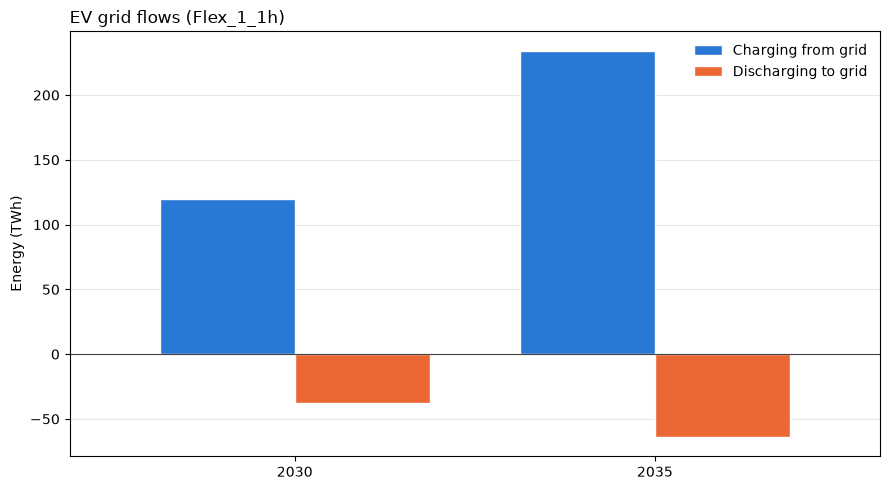

In [15]:
# 2.2 EV grid exchange components: charging from the grid, discharging to the grid, and net exchange
EV_COMPONENTS = {"Charging from grid": ("EV_G2V_Y", 1), "Discharging to grid": ("EV_V2G_Y", -1), "Net grid exchange": ("EV_NET_Y", 1)}
ev_components = {}
missing_ev_components = []
for label, (symbol, sign) in EV_COMPONENTS.items():
    try:
        table = get(symbol)
    except Exception as exc:
        missing_ev_components.append(f"{symbol}: {exc}")
        continue
    if table.empty:
        missing_ev_components.append(f"{symbol}: no rows for scenario {SCENARIO}")
        continue
    ev_components[label] = sign * table.groupby("Year")["Value"].sum()
if missing_ev_components:
    raise RuntimeError("Missing EV component outputs. Rerun the scenario after updating OUTPUT_SUMMARY.inc: " + "; ".join(missing_ev_components))
ev_components = pd.DataFrame(ev_components).sort_index()
ev_grid_flows = ev_components[["Charging from grid", "Discharging to grid"]]
ax = ev_grid_flows.plot.bar(figsize=(max(9, 0.5 * len(ev_grid_flows) + 5), 5), color=["#2a78d6", "#eb6834"], width=0.75, edgecolor="#fcfcfb")
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_title(f"EV grid flows ({SCENARIO})", loc="left")
ax.set_ylabel("Energy (TWh)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=xrot(len(ev_grid_flows)))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

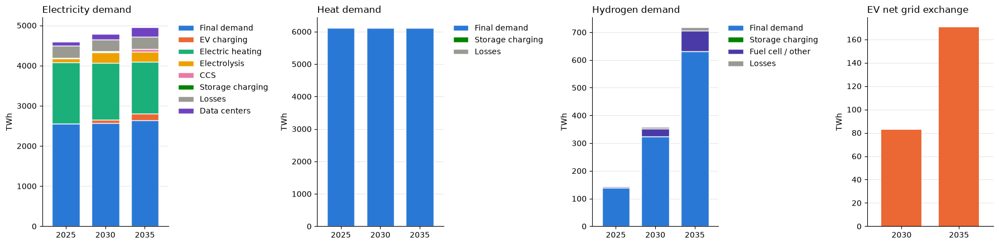

In [16]:
# 2.3 Total demand per carrier and category (TWh), plus net EV grid exchange
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, table) in zip(axes[:3], demand.items()):
    stacked_bar(table, DEMAND_COLORS, f"{name} demand", "TWh", ax=ax)
ev_components["Net grid exchange"].plot.bar(ax=axes[3], color=DEMAND_COLORS["EV charging"], width=0.7)
axes[3].axhline(0, color="#444444", linewidth=0.8)
axes[3].set_title("EV net grid exchange", loc="left"); axes[3].set_ylabel("TWh"); axes[3].set_xlabel("")
axes[3].tick_params(axis="x", rotation=xrot(len(ev_components))); axes[3].grid(axis="y", alpha=0.3); axes[3].set_axisbelow(True)
for side in ("top", "right"): axes[3].spines[side].set_visible(False)
plt.tight_layout()
plt.show()

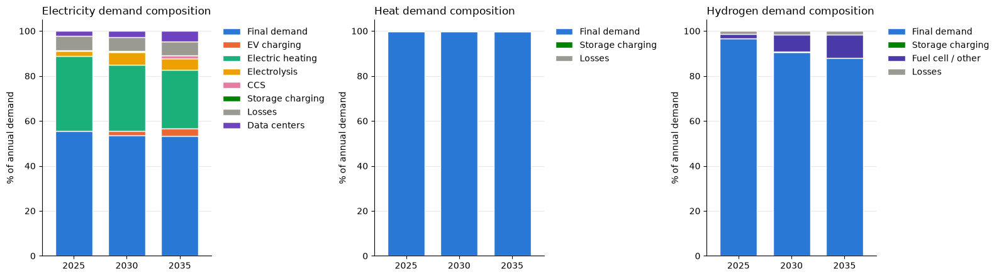

In [17]:
# 2.4 Demand composition (% of each carrier's annual demand)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, table) in zip(axes, demand.items()):
    share = table.div(table.sum(axis=1), axis=0) * 100
    stacked_bar(share, DEMAND_COLORS, f"{name} demand composition", "% of annual demand", ax=ax)
plt.tight_layout(); plt.show()

#### 2.4.1 How the electricity demand is met, hour by hour
The electricity generation per time step by technology type, all regions summed (GW), in the last solved year (2035 if solved), one panel per modelled season block. The dashed line is the total electricity demand (all categories of 2.0; storage charging counts as demand and the V2G discharge as negative EV load), so the stack meets the demand exactly in every step: transmission between the modelled regions nets out in the sum.
- **Technology types** (`Technology` column of `PRO_YCRAGFST`): onshore wind, offshore wind, solar PV, hydro (reservoirs and run-of-river), CHP (back-pressure and extraction), condensing plants, and storage discharge. Nuclear is a condensing plant with the fuel `NUCLEAR`, shown on its own; "Condensing (fuel-fired)" is every other condensing plant.
- Only the types that exist in the run are drawn. The model has no chronological year: the profile is the representative season blocks of the run, not the 8,760 hours of a year.
- The table gives the mean, share of the generation, peak and lowest output of each type over the modelled hours.

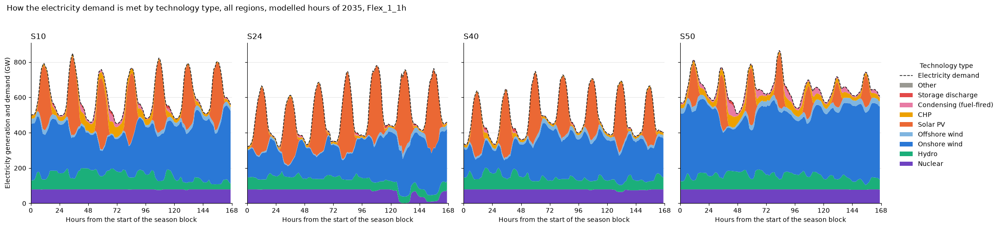

,Mean (GW),Share of generation (%),Peak (GW),Lowest (GW)
Type,,,,
Nuclear,75.60,13.33,79.14,1.18
Hydro,70.52,12.43,123.16,26.79
Onshore wind,259.36,45.72,430.23,60.59
Offshore wind,17.76,3.13,30.41,1.17
Solar PV,113.96,20.09,448.97,0.00
CHP,20.10,3.54,71.09,1.21
Condensing (fuel-fired),7.87,1.39,65.36,1.17
Storage discharge,2.07,0.37,17.44,0.00
Other,0.00,0.00,0.02,-0.00


Demand: mean 567.3 GW, peak 865.4 GW. Generation minus demand: largest difference in a step 0.00 GW (storage charging and V2G are counted in the demand, so the stack meets it exactly)


In [18]:
# 2.4.1 How the electricity demand is met hour by hour: generation by technology type, all regions (GW), one panel per modelled season block
PROFILE_YEAR = "2035" if "2035" in get("EL_DEMAND_YCR")["Year"].astype(str).unique() else sorted(get("EL_DEMAND_YCR")["Year"].astype(str).unique(), key=int)[-1]
PROFILE_STEP_H = globals().get("SFLEX_STEP_H")                                  # hours per time step (None: label the axis in time steps)
# Technology types, bottom to top of the stack (nuclear is a CONDENSING plant with fuel NUCLEAR, shown on its own)
PROFILE_COLORS = {"Nuclear": "#6f42c1", "Hydro": "#1baf7a", "Onshore wind": "#2a78d6", "Offshore wind": "#7fb5e0", "Solar PV": "#eb6834",
                  "CHP": "#eda100", "Condensing (fuel-fired)": "#e87ba4", "Storage discharge": "#e34948", "Other": "#9a9992"}
def profile_type(pro):
    tech, fuel = pro["Technology"].astype(str).str.upper(), pro["Fuel"].astype(str).str.upper()
    kind = pd.Series("Other", index=pro.index)
    kind[tech.str.contains("HYDRO")] = "Hydro"
    kind[tech.str.contains("WIND_ON|WIND-ON")] = "Onshore wind"
    kind[tech.str.contains("WIND_OFF|WIND-OFF")] = "Offshore wind"
    kind[tech.str.contains("SOLAR-PV|SOLAR_PV")] = "Solar PV"
    kind[tech.str.contains("CHP")] = "CHP"
    kind[tech.str.contains("CONDENSING")] = "Condensing (fuel-fired)"
    kind[tech.str.contains("CONDENSING") & fuel.str.contains("NUCLEAR")] = "Nuclear"
    kind[tech.str.contains("STORAGE")] = "Storage discharge"
    return kind

pro = get("PRO_YCRAGFST")
pro = pro.loc[pro["Year"].astype(str).eq(PROFILE_YEAR) & pro["Commodity"].eq("ELECTRICITY")].copy()
pro["Type"] = profile_type(pro)
dem = get("EL_DEMAND_YCRST")
dem = dem.loc[dem["Year"].astype(str).eq(PROFILE_YEAR)]
prof_seasons, prof_times = sorted(dem["Season"].unique()), sorted(dem["Time"].unique())
prof_index = pd.MultiIndex.from_product([prof_seasons, prof_times], names=["Season", "Time"])
supply = pro.groupby(["Season", "Time", "Type"])["Value"].sum().unstack("Type").reindex(prof_index).fillna(0) / 1e3          # GW per step
supply = supply.reindex(columns=list(PROFILE_COLORS), fill_value=0)
supply = supply[[t for t in supply.columns if supply[t].abs().max() > 1e-9]]                                                  # types that exist in this run
demand = dem.groupby(["Season", "Time"])["Value"].sum().reindex(prof_index).fillna(0) / 1e3                                  # all categories, V2G as negative EV load
gap = (supply.sum(axis=1) - demand).abs().max()

fig, axes = plt.subplots(1, len(prof_seasons), figsize=(4.6 * len(prof_seasons) + 1, 5), sharey=True, squeeze=False)
for k, (ax, season) in enumerate(zip(axes[0], prof_seasons)):
    e, d = supply.xs(season, level="Season").reindex(prof_times), demand.xs(season, level="Season").reindex(prof_times)
    hours = np.arange(len(e)) * (PROFILE_STEP_H or 1)
    ax.stackplot(hours, e.to_numpy().T, colors=[PROFILE_COLORS[t] for t in e.columns], labels=list(e.columns), linewidth=0)
    ax.plot(hours, d, color="#1a1a1a", linewidth=1.1, linestyle="--", label="Electricity demand")
    ax.set_xlim(0, hours[-1] + (PROFILE_STEP_H or 1))
    if PROFILE_STEP_H:
        ax.set_xticks(np.arange(0, len(e) * PROFILE_STEP_H + 1, 24))
    ax.set_title(season, loc="left"); ax.set_ylabel("Electricity generation and demand (GW)" if k == 0 else "")
    ax.set_xlabel("Hours from the start of the season block" if PROFILE_STEP_H else "Time step")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, title="Technology type")
fig.suptitle(f"How the electricity demand is met by technology type, all regions, modelled hours of {PROFILE_YEAR}, {SCENARIO}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

# Mean and peak output per technology type over the modelled hours (GW)
display(pd.DataFrame({"Mean (GW)": supply.mean(), "Share of generation (%)": 100 * supply.mean() / supply.sum(axis=1).mean(),
                      "Peak (GW)": supply.max(), "Lowest (GW)": supply.min()}).round(2))
print(f"Demand: mean {demand.mean():.1f} GW, peak {demand.max():.1f} GW. Generation minus demand: largest difference in a step {gap:.2f} GW "
      f"(storage charging and V2G are counted in the demand, so the stack meets it exactly)")

### 2.5 Data-center demand over time

Annual data-center electricity demand aggregated across all regions.

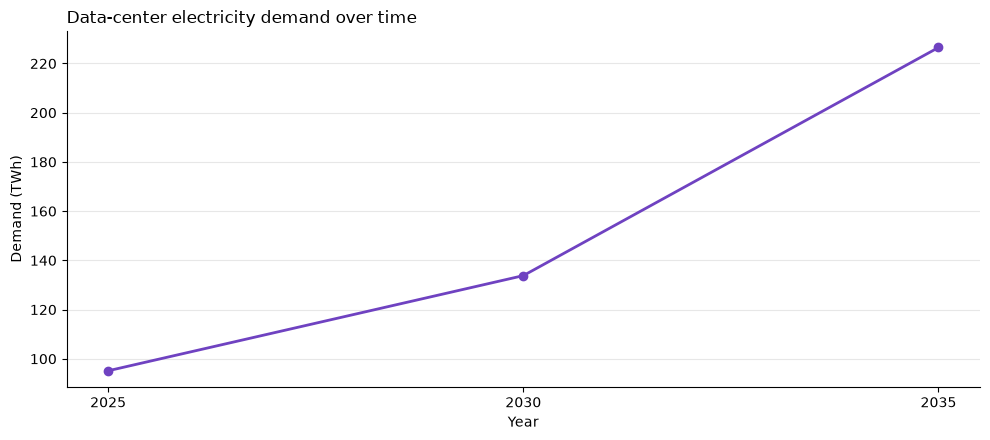

Data-center demand: 95.13 TWh in 2025, 226.50 TWh in 2035, change +131.37 TWh (+138.1 %)


In [19]:
# 2.5 Data-center electricity demand (TWh)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dc_by_year.index, dc_by_year.values, marker="o", linewidth=2, color=DEMAND_COLORS["Data centers"])
ax.set_title("Data-center electricity demand over time", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Demand (TWh)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

# Change in yearly data-center demand between 2025 and 2035 (years are matched as text, whatever the index type)
dc_years = pd.Series(dc_by_year.values, index=dc_by_year.index.astype(str))
if {"2025", "2035"} <= set(dc_years.index):
    dc_change = dc_years["2035"] - dc_years["2025"]
    print(f"Data-center demand: {dc_years['2025']:.2f} TWh in 2025, {dc_years['2035']:.2f} TWh in 2035, "
          f"change {dc_change:+.2f} TWh ({dc_change / dc_years['2025'] * 100:+.1f} %)")
else:
    print("Data-center demand change 2025-2035 not available: 2025 and/or 2035 is not a solved year")


In [20]:
# 2.6 Annual energy-balance Sankey diagram (TWh)
# Technology groups feed carriers, which feed final demand.
SANKEY_YEAR = max(get("PRO_YCRAGF")["Year"])
sankey_carriers = ["ELECTRICITY", "HEAT", "HYDROGEN"]
sankey_names = {"ELECTRICITY": "Electricity", "HEAT": "Heat", "HYDROGEN": "Hydrogen"}

sankey_pro = get("PRO_YCRAGF").query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers").copy()
sankey_pro["Source"] = tech_group(sankey_pro, unpack=True)
sankey_pro = sankey_pro.groupby(["Commodity", "Source"])["Value"].sum().reset_index()

sankey_dem = pd.concat([
    get("EL_DEMAND_YCR").assign(Commodity="ELECTRICITY"),
    get("H_DEMAND_YCRA").assign(Commodity="HEAT"),
    get("H2_DEMAND_YCR").assign(Commodity="HYDROGEN"),
], ignore_index=True).query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers")
sankey_dem = sankey_dem.groupby("Commodity")["Value"].sum()

source_labels = [f"{row.Commodity.title()}: {row.Source}" for row in sankey_pro.itertuples()]
carrier_labels = [sankey_names[c] for c in sankey_carriers]
sink_labels = [f"{sankey_names[c]} final demand" for c in sankey_carriers]
labels = source_labels + carrier_labels + sink_labels
carrier_index = {c: len(source_labels) + i for i, c in enumerate(sankey_carriers)}
sink_index = {c: len(source_labels) + len(carrier_labels) + i for i, c in enumerate(sankey_carriers)}
source_index = {(row.Commodity, row.Source): i for i, row in enumerate(sankey_pro.itertuples())}

links = [(source_index[(row.Commodity, row.Source)], carrier_index[row.Commodity], row.Value) for row in sankey_pro.itertuples() if row.Value > 0]
for commodity in sankey_carriers:
    supply = sankey_pro.loc[sankey_pro["Commodity"] == commodity, "Value"].sum()
    demand_value = float(sankey_dem.get(commodity, 0))
    if demand_value > 0:
        links.append((carrier_index[commodity], sink_index[commodity], demand_value))
    residual = supply - demand_value
    if residual > 1e-9:
        labels.append(f"{sankey_names[commodity]} surplus / exports")
        links.append((carrier_index[commodity], len(labels) - 1, residual))
    elif residual < -1e-9:
        labels.append(f"{sankey_names[commodity]} net imports")
        links.append((len(labels) - 1, carrier_index[commodity], -residual))

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=labels, pad=18, thickness=18, line=dict(color="rgba(80,80,80,0.35)", width=0.5)),
    link=dict(source=[x[0] for x in links], target=[x[1] for x in links], value=[x[2] for x in links]),
))
fig.update_layout(title=f"Annual energy balance, {SANKEY_YEAR} ({SCENARIO})", height=720, width=1250,
                  font=dict(size=11), margin=dict(l=10, r=10, t=55, b=10))
fig.show()


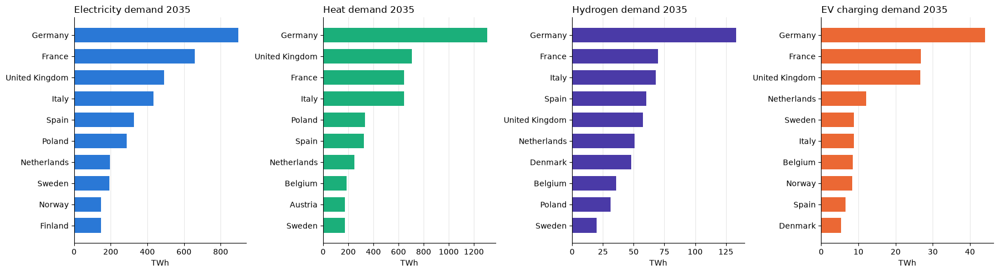

In [21]:
# 2.7 Demand per country in the last solved year (TWh): the 10 largest countries for each carrier
el_d, h_d, h2_d = get("EL_DEMAND_YCR"), get("H_DEMAND_YCRA"), get("H2_DEMAND_YCR")
last = el_d["Year"].max()
per_country = {
    "Electricity": (el_d[el_d["Year"] == last].groupby("Country")["Value"].sum(), "#2a78d6"),
    "Heat": (h_d[h_d["Year"] == last].groupby("Country")["Value"].sum(), "#1baf7a"),
    "Hydrogen": (h2_d[h2_d["Year"] == last].groupby("Country")["Value"].sum(), "#4a3aa7"),
    "EV charging": (el_d[(el_d["Year"] == last) & (el_d["Category"] == "ENDO_EV")].groupby("Country")["Value"].sum(),
                    DEMAND_COLORS["EV charging"]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, (series, color)) in zip(axes, per_country.items()):
    s = series.sort_values(ascending=False).head(10).iloc[::-1]          # largest on top
    ax.barh([clean_name(c) for c in s.index], s.values, color=color, height=0.7)
    ax.set_title(f"{name} demand {last}", loc="left"); ax.set_xlabel("TWh")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### 2.8 Flexible loads of this scenario
The electricity demands whose timing is chosen by the model (the flexible loads of `base/model/balopt.opt`), for this scenario only; the flexible-loads comparison at the end of the notebook shows how they differ from the base.

| Flexible load | Category in `EL_DEMAND_YCR(ST)` | Where the flexibility comes from |
|---|---|---|
| Power-to-heat | `ENDOGENOUS_ELECT2HEAT` | Heat pumps and electric boilers (`ELECT-TO-HEAT`) with heat storage |
| Electrolysis | `ENDO_H2` | Electrolysers with H2 storage and the H2 grid; the H2 demand itself is fixed |
| EV charging and V2G | `ENDO_EV` (net of V2G) | Smart charging within the EV battery limits (`EV`, `EV_INTERSEASONAL`), discharging to the grid (`V2G`) |
| Storage charging | `ENDO_INTRASTO` | Charging of the electricity storage (`INTRASEASONAL-ELECT-STORAGE`) |
| Data-centre load shifting | Inside `EXOGENOUS` (net shift `VDCF_S - VDCF_D`); read from `all_endofmodel.gdx` | `dcflex` add-on (`DCFLEX`): up to `DC_FLEXSHARE` of the data-centre load deferred or advanced by at most `DC_SHIFTHORIZON` steps, served load below the capacity `DC_CAPFACTOR` × peak load |

Not flexible: the exogenous demand (fixed profile, apart from the data-centre shift when `DCFLEX` is on), CCS (follows the CCS plants), and the switched-off options `DEMANDRESPONSE`, `DFLEXQUANT` and `flexible_h2_space`.

The time-step results (`*_YCRST`) are MWh per hour of the step, i.e. average MW; one step lasts `SFLEX_STEP_H` hours (`CHRONOHOUR`, read from `data/CHRONOHOUR.inc`, otherwise `base/data`). The regional EV demand per step is net of V2G, so its positive part is shown as charging and its negative part as V2G. The data-centre shift is treated the same way: per region and step, the net shift (shifted load served minus deferred load) is load moved *into* the step when positive (**DC shifted in**, counted as flexible demand) and load moved *out of* the step when negative (**DC shifted out**, drawn below zero like V2G). Over a season the two are equal, as the shifted energy is preserved. The hourly charts, the price metrics and the maps are for `SFLEX_YEAR` (2035, or the last solved year).

#### 2.8.1 How much energy goes through the flexible loads?
Annual results per solved year: the electricity used by each flexible load, the EV energy charged from and discharged to the grid, the data-centre load shifted (net shifted-in energy) against its potential `DC_FLEXSHARE` × data-centre demand, the capacity of the power-to-heat units and electrolysers, the storage volume behind the flexibility, and the flexible share of the electricity demand (now including the shifted data-centre load).

Flexible loads per year, Flex_1_1h


Year,2025,2030,2035
Power-to-heat (TWh),1519.05,1418.30,1287.13
Electrolysis (TWh),107.89,257.90,253.08
Storage charging (TWh),9.43,7.29,6.50
EV charging from the grid (TWh),0.00,120.11,234.29
V2G (TWh),0.00,37.39,64.02
EV net demand = charging - V2G (TWh),0.00,82.72,170.27
Data-centre demand (TWh),95.13,133.80,226.50
Data-centre load shifted (TWh),4.00,5.71,9.54
Data-centre shiftable potential = s x demand (TWh),19.03,26.76,45.30
Data-centre shift used (% of potential),21.04,21.32,21.05


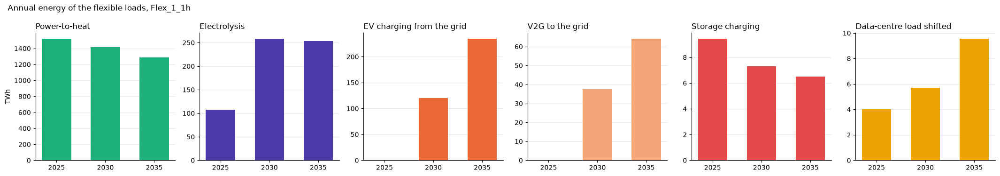

In [22]:
# 2.8.1 Annual energy of the flexible loads (TWh), the capacity (GW) and storage volume (GWh) behind them, flexible share (%)
def sflex_total(symbol, query=None):
    """Sum of Value per solved year (0 when the symbol is not in this run, e.g. without the EV add-on)."""
    try:
        t = get(symbol)
    except Exception:
        return pd.Series(0.0, index=sflex_years)
    t = t.query(query) if query else t
    return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(sflex_years, fill_value=0)

sflex_dc_ann = lambda col: sflex_dc_twh(col).reindex(sflex_years, fill_value=0)   # data-centre shift, from 0.3

sflex_ann = pd.DataFrame({
    **{f"{name} (TWh)": sflex_total("EL_DEMAND_YCR", f"Category == '{cat}'") for cat, name in SFLEX_LOADS.items() if cat != "ENDO_EV"},
    "EV charging from the grid (TWh)": sflex_total("EV_G2V_Y"),
    "V2G (TWh)": sflex_total("EV_V2G_Y"),
    "EV net demand = charging - V2G (TWh)": sflex_total("EL_DEMAND_YCR", "Category == 'ENDO_EV'"),
    "Data-centre demand (TWh)": sflex_dc_ann("Baseline"),
    "Data-centre load shifted (TWh)": sflex_dc_ann("Net in"),
    "Data-centre shiftable potential = s x demand (TWh)": SFLEX_DC_PAR.get("DC_FLEXSHARE", 0) * sflex_dc_ann("Baseline"),
    "Data-centre shift used (% of potential)": 100 * sflex_dc_ann("Net in") / (SFLEX_DC_PAR.get("DC_FLEXSHARE", 0) * sflex_dc_ann("Baseline")).replace(0, np.nan),
    "Data-centre capacity C (GW)": sflex_dc_cap.groupby(level="Year").sum().reindex(sflex_years, fill_value=0) / 1e3,
    "Flexible share of electricity demand (%)": 100 * (sflex_total("EL_DEMAND_YCR", "Category in @SFLEX_LOADS") + sflex_dc_ann("Net in"))
                                                / sflex_total("EL_DEMAND_YCR"),
    "Power-to-heat capacity (GW)": sflex_total("G_CAP_YCRAF", "Technology == 'ELECT-TO-HEAT'"),
    "Electrolyser capacity (GW)": sflex_total("G_CAP_YCRAF", "Technology == 'ELECTROLYZER'"),
    "Heat storage volume (GWh)": sflex_total("G_STO_YCRAF", "Technology.str.contains('HEAT-STORAGE')"),
    "H2 storage volume (GWh)": sflex_total("G_STO_YCRAF", "Technology == 'H2-STORAGE'"),
    "Electricity storage volume (GWh)": sflex_total("G_STO_YCRAF", "Technology == 'INTRASEASONAL-ELECT-STORAGE'"),
}).T
print(f"Flexible loads per year, {SCENARIO}")
display(sflex_ann.round(2))

panels = [("Power-to-heat (TWh)", "Power-to-heat", "Power-to-heat"), ("Electrolysis (TWh)", "Electrolysis", "Electrolysis"),
          ("EV charging from the grid (TWh)", "EV charging from the grid", "EV charging"), ("V2G (TWh)", "V2G to the grid", "V2G"),
          ("Storage charging (TWh)", "Storage charging", "Storage charging")]
if SFLEX_HAS_DC:
    panels.append(("Data-centre load shifted (TWh)", "Data-centre load shifted", "DC shifted in"))
fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels) + 1, 3.8))
for ax, (row, title, color) in zip(axes, panels):
    ax.bar(sflex_years, sflex_ann.loc[row], 0.6, color=SFLEX_COLORS[color])
    sflex_style(ax, title, "TWh" if ax is axes[0] else "")
fig.suptitle(f"Annual energy of the flexible loads, {SCENARIO}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

#### 2.8.2 Hour by hour: when do the flexible loads run?
The flexible loads summed over all regions per time step in `SFLEX_YEAR` (GW, stacked; V2G and the data-centre load shifted out of a step below zero), with the demand-weighted European electricity price (black line, right axis) and the onshore + offshore wind + solar generation (dashed line, left axis, scaled to fit). One panel per season; the x-axis is real hours from the start of the season block.

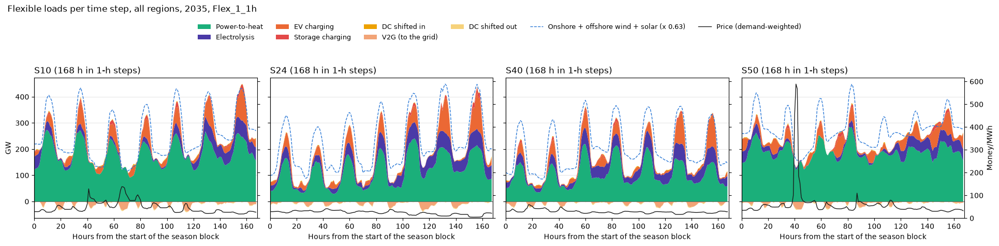

In [23]:
# 2.8.2 Flexible loads per time step, all of Europe, in SFLEX_YEAR (GW), with the price and the onshore + offshore wind + solar generation
eu = sflex_h.drop(columns="Price").groupby(level=["Season", "Time"]).sum() / 1e3                       # GW
eu_price = (sflex_h["Price"] * sflex_h["Total demand"]).groupby(level=["Season", "Time"]).sum() / eu["Total demand"] / 1e3
vre_scale = eu[SFLEX_ORDER].sum(axis=1).max() / max(eu["Onshore + offshore wind + solar"].max(), 1e-9)   # onshore + offshore wind + solar scaled to the flexible-load peak
fig, axes = plt.subplots(1, len(SFLEX_SEASONS), figsize=(4.6 * len(SFLEX_SEASONS) + 1, 4.8), sharey=True, squeeze=False)
twins = []
for ax, season in zip(axes.ravel(), SFLEX_SEASONS):
    e = eu.xs(season, level="Season").reindex(SFLEX_TIMES, fill_value=0)
    hours = np.arange(len(e)) * SFLEX_STEP_H
    ax.stackplot(hours, *[e[c] for c in SFLEX_ORDER], colors=[SFLEX_COLORS[c] for c in SFLEX_ORDER], labels=SFLEX_ORDER, linewidth=0)
    ax.fill_between(hours, 0, -e["V2G"], color=SFLEX_COLORS["V2G"], linewidth=0, label="V2G (to the grid)")
    if SFLEX_HAS_DC:
        ax.fill_between(hours, -e["V2G"], -e["V2G"] - e["DC shifted out"], color=SFLEX_COLORS["DC shifted out"], linewidth=0,
                        label="DC shifted out")
    ax.plot(hours, e["Onshore + offshore wind + solar"] * vre_scale, color="#2a78d6", linewidth=1, linestyle="--", label=f"Onshore + offshore wind + solar (x {vre_scale:.2f})")
    ax.axhline(0, color="#52514e", linewidth=0.6)
    tw = ax.twinx()
    tw.plot(hours, eu_price.xs(season, level="Season").reindex(SFLEX_TIMES), color="#1a1a1a", linewidth=1, label="Price (demand-weighted)")
    twins.append(tw)
    ax.set_xlim(0, len(e) * SFLEX_STEP_H)
    sflex_style(ax, f"{season} ({len(e) * SFLEX_STEP_H:.0f} h in {SFLEX_STEP_H:g}-h steps)", "GW" if ax is axes[0, 0] else "")
    ax.set_xlabel("Hours from the start of the season block")
lo, hi = min(t.get_ylim()[0] for t in twins), max(t.get_ylim()[1] for t in twins)
for k, tw in enumerate(twins):
    tw.set_ylim(min(lo, 0), hi)
    tw.set_ylabel("Money/MWh" if k == len(twins) - 1 else "")
    if k < len(twins) - 1:
        tw.tick_params(labelright=False)
handles = axes[0, 0].get_legend_handles_labels()[0] + twins[0].get_legend_handles_labels()[0]
labels = axes[0, 0].get_legend_handles_labels()[1] + twins[0].get_legend_handles_labels()[1]
fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), frameon=False, bbox_to_anchor=(0.5, 0.93), fontsize=9)
fig.suptitle(f"Flexible loads per time step, all regions, {SFLEX_YEAR}, {SCENARIO}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.83)); plt.show()

#### 2.8.3 Do the flexible loads use cheap and renewable hours?
Per flexible load in `SFLEX_YEAR`, over all regions and time steps:
- **Average price** paid (Money/MWh) = Σ load × regional price / Σ load, and the same **relative to the average price of all electricity demand** (below 100 % = the load runs in cheaper hours than demand on average). For V2G it is the price received, and for the data-centre load shifted out it is the price of the steps the load leaves (the cost avoided), so above 100 % is good for both.
- **Share in below-median-price hours**: the share of the load's energy in time steps where the regional price is below that region's median price (50 % = no preference).
- **Correlation with the net load** (total demand minus onshore wind, offshore wind and solar, European sum per step): negative = the load runs when onshore wind, offshore wind and solar are plentiful.

Price and timing of the flexible loads, Flex_1_1h, 2035 (V2G: price received; DC shifted out: price avoided)


,Average price (Money/MWh),Relative to all demand (%),Share in below-median-price hours (%),Correlation with the net load
Power-to-heat,37.91,95.97,54.37,-0.08
Electrolysis,21.29,53.89,87.49,-0.80
EV charging,27.87,70.56,67.43,-0.50
Storage charging,23.70,60.01,69.64,-0.43
DC shifted in,31.63,80.09,59.25,-0.25
V2G,69.81,176.75,22.46,0.51
DC shifted out,51.07,129.31,38.96,0.26
Total demand,39.50,100.00,52.06,-0.12


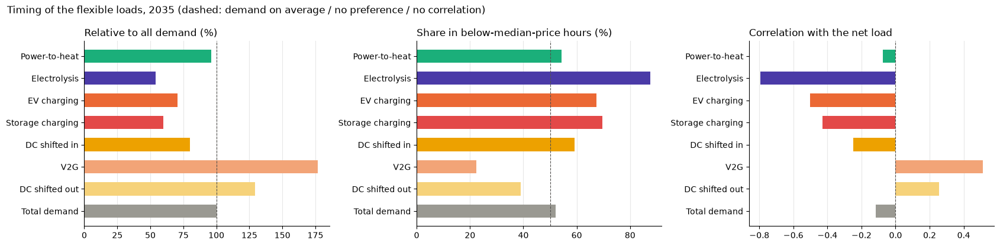

In [24]:
# 2.8.3 Price paid per MWh, share in below-median-price hours and correlation with the net load, per flexible load
p = sflex_h["Price"]
avg_price = (p * sflex_h["Total demand"]).sum() / sflex_h["Total demand"].sum()
cheap = p < p.groupby(level="Region").transform("median")
eu = sflex_h.groupby(level=["Season", "Time"]).sum()
net_load = eu["Total demand"] - eu["Onshore + offshore wind + solar"]
rows = {}
for load in SFLEX_ORDER + ["V2G", "DC shifted out", "Total demand"]:
    e = sflex_h[load]
    if e.sum() <= 0:
        continue
    paid = (p * e).sum() / e.sum()
    rows[load] = {"Average price (Money/MWh)": paid, "Relative to all demand (%)": 100 * paid / avg_price,
                  "Share in below-median-price hours (%)": 100 * e[cheap].sum() / e.sum(),
                  "Correlation with the net load": eu[load].corr(net_load)}
sflex_metrics = pd.DataFrame(rows).T
print(f"Price and timing of the flexible loads, {SCENARIO}, {SFLEX_YEAR} (V2G: price received; DC shifted out: price avoided)")
display(sflex_metrics.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
loads = list(sflex_metrics.index)
colors = [SFLEX_COLORS.get(l, GREY) for l in loads]
for ax, col, ref in [(axes[0], "Relative to all demand (%)", 100), (axes[1], "Share in below-median-price hours (%)", 50),
                     (axes[2], "Correlation with the net load", 0)]:
    ax.barh(loads, sflex_metrics[col], color=colors, height=0.6)
    ax.axvline(ref, color="#52514e", linewidth=0.8, linestyle="--")
    ax.invert_yaxis()
    sflex_style(ax, col, "", axis="x")
fig.suptitle(f"Timing of the flexible loads, {SFLEX_YEAR} (dashed: demand on average / no preference / no correlation)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

#### 2.8.4 Electric vehicles: daily profile and V2G per region
Left: the average EV charging and V2G (below zero) over the hours of the day, all regions, `SFLEX_YEAR` (GW); each step is placed at its real starting hour. Right: the annual V2G energy per region (`V2G_FLEX_YCR`, TWh); regions without V2G are hatched.

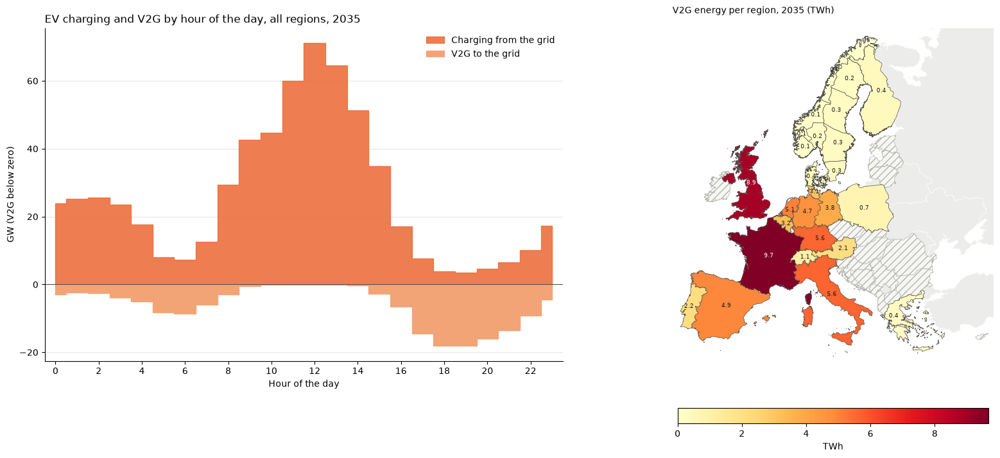

In [25]:
# 2.8.4 EVs: average daily charging and V2G profile (GW) and V2G energy per region (TWh), SFLEX_YEAR
sflex_geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
sflex_modelled = sflex_geo["id"].isin(sflex_h.index.unique("Region"))
sflex_mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)
SFLEX_BOUNDS = sflex_geo.loc[sflex_modelled].geometry.apply(sflex_mainland).total_bounds

def sflex_map(ax, values, cmap, norm, fmt, title):
    """Choropleth of `values` (indexed by region) on the modelled regions; regions without a value are hatched."""
    g = sflex_geo[sflex_modelled].assign(Value=lambda d: d["id"].map(values))
    sflex_geo[~sflex_modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    if g["Value"].isna().any():
        g[g["Value"].isna()].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5, hatch="///")
    if g["Value"].notna().any():
        g[g["Value"].notna()].plot(ax=ax, column="Value", cmap=cmap, norm=norm, edgecolor="#52514e", linewidth=0.5)
    for _, row in g[g["Value"].notna()].iterrows():
        pt = sflex_mainland(row.geometry).representative_point()
        ax.annotate(fmt.format(row["Value"]), (pt.x, pt.y), ha="center", va="center", fontsize=6.5,
                    color="white" if norm(row["Value"]) > 0.75 else "#1a1a1a")
    minx, miny, maxx, maxy = SFLEX_BOUNDS
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off(); ax.set_title(title, loc="left", fontsize=10)

try:
    v2g = get("V2G_FLEX_YCR")
    v2g = v2g.loc[v2g["Year"].astype(str).eq(SFLEX_YEAR)].groupby("Region")["Value"].sum()
except Exception:                                            # no V2G in this run
    v2g = pd.Series(dtype=float)
v2g = v2g[v2g > 1e-6]

fig = plt.figure(figsize=(17, 7), layout="constrained")
ax, ax_map = fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)
eu = sflex_h[["EV charging", "V2G"]].groupby(level=["Season", "Time"]).sum() / 1e3
hour = np.floor(eu.groupby(level="Season").cumcount().to_numpy() * SFLEX_STEP_H % 24).astype(int)
prof = eu.groupby(hour).mean()
ax.fill_between(prof.index, 0, prof["EV charging"], color=SFLEX_COLORS["EV charging"], alpha=0.85, label="Charging from the grid", step="mid")
ax.fill_between(prof.index, 0, -prof["V2G"], color=SFLEX_COLORS["V2G"], label="V2G to the grid", step="mid")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5)
sflex_style(ax, f"EV charging and V2G by hour of the day, all regions, {SFLEX_YEAR}", "GW (V2G below zero)")
ax.set_xlabel("Hour of the day"); ax.legend(frameon=False)
norm = Normalize(0, max(v2g.max() if len(v2g) else 0, 1e-6))
sflex_map(ax_map, v2g, "YlOrRd", norm, "{:.1f}", f"V2G energy per region, {SFLEX_YEAR} (TWh)")
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm), ax=ax_map, orientation="horizontal", shrink=0.6, label="TWh")
plt.show()

#### 2.8.5 The storage behind the flexibility
State of charge (% of the installed volume, all regions) per time step in `SFLEX_YEAR` of the heat storage that lets power-to-heat shift, the H2 storage behind the electrolysers, and the electricity storage, one line per season. Storage that cycles within a day shows the flexibility is used daily; a slow drift shows it is used across days.

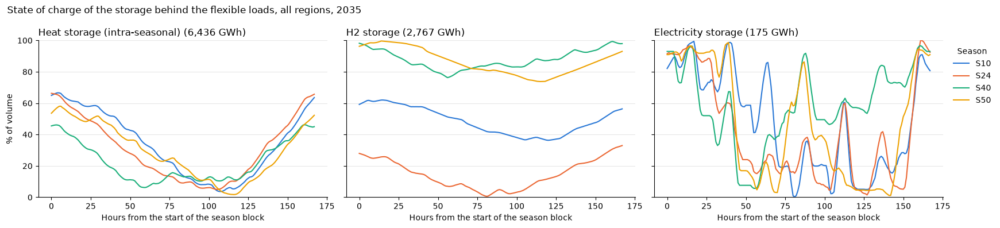

In [26]:
# 2.8.5 State of charge (% of volume) of the heat, H2 and electricity storage per time step, all regions, SFLEX_YEAR
vol = get("G_STO_YCRAF")
vol = vol.loc[vol["Year"].astype(str).eq(SFLEX_YEAR) & vol["Technology"].isin(SFLEX_SOC)].groupby("Technology")["Value"].sum() * 1e3   # MWh
lvl = sflex_raw["STORAGE_LEVEL"].groupby(["Technology", "Season", "Time"])["Value"].sum()
fig, axes = plt.subplots(1, len(SFLEX_SOC), figsize=(5.5 * len(SFLEX_SOC) + 1, 4), sharey=True)
for ax, (tech, name) in zip(axes, SFLEX_SOC.items()):
    for k, season in enumerate(SFLEX_SEASONS):
        l = lvl.reindex(pd.MultiIndex.from_product([[tech], [season], SFLEX_TIMES]), fill_value=0).to_numpy()
        ax.plot(np.arange(len(l)) * SFLEX_STEP_H, 100 * l / vol.get(tech, np.nan), color=PALETTE[k], linewidth=1.5, label=season)
    ax.set_ylim(0, 100)
    sflex_style(ax, f"{name} ({vol.get(tech, 0) / 1e3:,.0f} GWh)", "% of volume" if ax is axes[0] else "")
    ax.set_xlabel("Hours from the start of the season block")
axes[-1].legend(title="Season", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle(f"State of charge of the storage behind the flexible loads, all regions, {SFLEX_YEAR}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

#### 2.8.6 Map: flexible share of the electricity demand per region
The flexible loads (power-to-heat, electrolysis, net EV demand, storage charging and the data-centre load shifted) as a share of each region's annual electricity demand (`EL_DEMAND_YCR`) in `SFLEX_YEAR`, next to the flexible electricity demand itself (TWh).

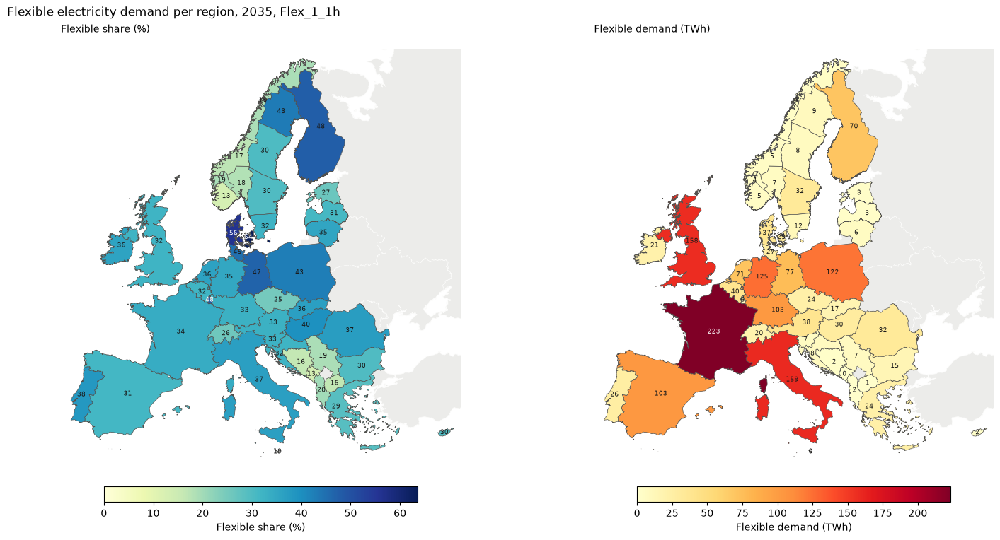

Flexible electricity demand per region, 2035, largest share first


,Flexible demand (TWh),Electricity demand (TWh),Flexible share (%)
Region,,,
DK2,29.3,46.1,63.5
DK1,37.2,66.5,56.0
LU,5.9,12.2,48.2
FIN,70.0,147.1,47.6
DE4-E,76.5,163.8,46.7
DE4-N,27.0,60.3,44.8
SE1,9.3,21.5,43.1
PL,122.2,286.8,42.6
HU,29.6,74.5,39.7


In [27]:
# 2.8.6 Flexible share of the annual electricity demand (%) and flexible demand (TWh) per region, SFLEX_YEAR
el = get("EL_DEMAND_YCR")
el = el.loc[el["Year"].astype(str).eq(SFLEX_YEAR)]
flex_twh = el.loc[el["Category"].isin(SFLEX_LOADS)].groupby("Region")["Value"].sum()
dc_twh = sflex_dc_twh("Net in", ("Year", "Region"))                              # data-centre load shifted (0.3)
flex_twh = flex_twh.add(dc_twh.loc[dc_twh.index.get_level_values("Year") == SFLEX_YEAR].droplevel("Year"), fill_value=0)
sflex_share = pd.DataFrame({"Flexible demand (TWh)": flex_twh, "Electricity demand (TWh)": el.groupby("Region")["Value"].sum()})
sflex_share["Flexible share (%)"] = 100 * sflex_share["Flexible demand (TWh)"] / sflex_share["Electricity demand (TWh)"]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), layout="constrained")
for ax, col, cmap, fmt in [(axes[0], "Flexible share (%)", "YlGnBu", "{:.0f}"), (axes[1], "Flexible demand (TWh)", "YlOrRd", "{:.0f}")]:
    norm = Normalize(0, sflex_share[col].max())
    sflex_map(ax, sflex_share[col], cmap, norm, fmt, col)
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, orientation="horizontal", shrink=0.6, label=col)
fig.suptitle(f"Flexible electricity demand per region, {SFLEX_YEAR}, {SCENARIO}", x=0.01, ha="left")
plt.show()
print(f"Flexible electricity demand per region, {SFLEX_YEAR}, largest share first")
display(sflex_share.sort_values("Flexible share (%)", ascending=False).round(1))

#### 2.8.7 Data centres: how the load-shifting flexibility is used hour by hour
The `dcflex` add-on in `SFLEX_YEAR`, from `all_endofmodel.gdx`:
- **Top row**, all regions summed per time step (GW): only the net shift *S − D* relative to the baseline data-centre load *L* (zero line, dashed), shaded green where load is shifted into the step and red where it is shifted out, between the limits −`DC_FLEXSHARE` × *L* (maximum shift out) and *C* − *L* (maximum shift in, dotted), with the price weighted by the data-centre load (right axis).
- **Bottom row**: the backlog *Y* (GWh): above zero = load deferred and still to be served within `DC_SHIFTHORIZON` steps, below zero = load served in advance.
- **Heatmap**: the net shift per region and time step as % of the region's baseline load (red = load shifted in, blue = shifted out), regions ordered by data-centre demand.
- **Table**: per region, the energy shifted against the potential and the average price of the load shifted in and out; the spread is the price saved per MWh shifted.

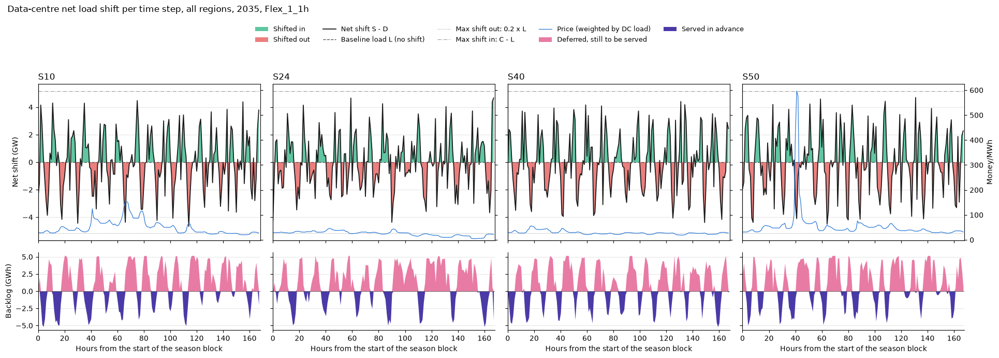

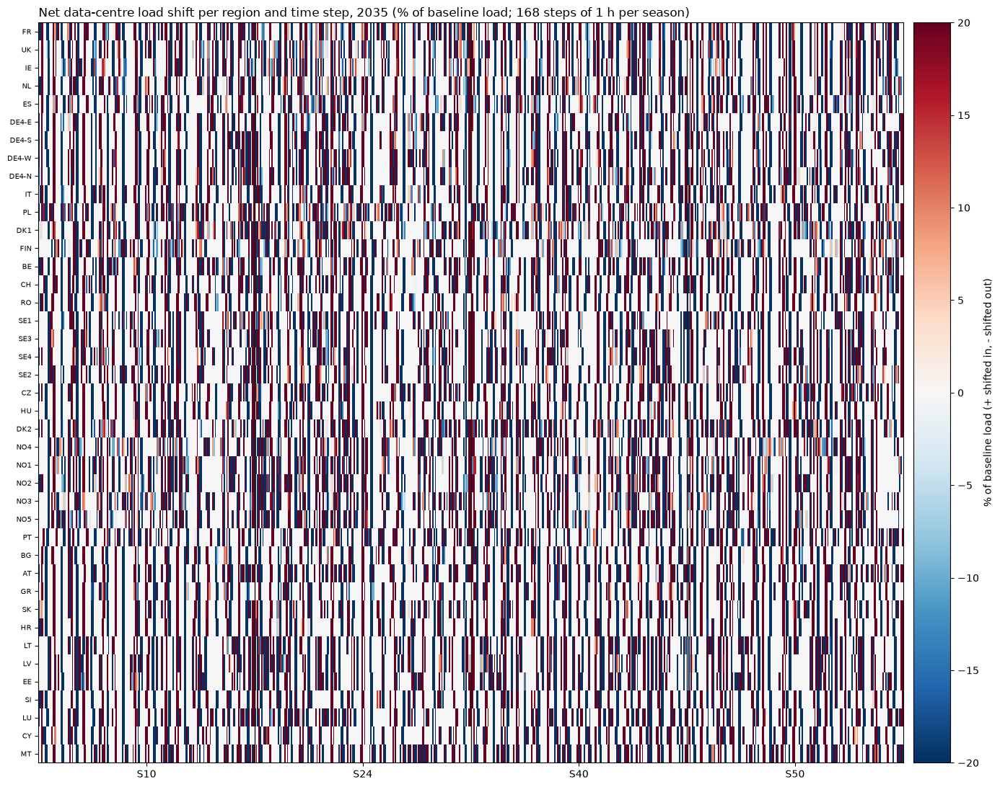

Data-centre load shifting per region, 2035, Flex_1_1h (largest data-centre demand first)


,Data-centre demand (TWh),Load shifted (TWh),Potential s x demand (TWh),Used (% of potential),Price of load shifted in (Money/MWh),Price of load shifted out (Money/MWh),Spread = price saved (Money/MWh)
Region,,,,,,,
FR,26.50,1.22,5.30,22.95,26.52,40.79,14.27
UK,25.50,1.10,5.10,21.54,35.20,55.93,20.73
IE,15.00,0.61,3.00,20.20,33.02,54.09,21.06
NL,14.00,0.59,2.80,21.16,35.60,60.53,24.92
ES,13.75,0.55,2.75,20.12,29.32,53.73,24.41
DE4-E,9.50,0.37,1.90,19.34,30.09,53.82,23.73
DE4-S,9.50,0.38,1.90,20.23,34.14,61.39,27.25
DE4-W,9.50,0.40,1.90,21.11,33.12,56.93,23.81
DE4-N,9.50,0.42,1.90,22.10,31.09,51.32,20.23


In [28]:
# 2.8.7 Data-centre net load shift per time step, all regions (GW), with the backlog (GWh) and the price; per-region heatmap and table
from matplotlib.colors import TwoSlopeNorm

if not SFLEX_HAS_DC:
    print(f"No data-centre flexibility (dcflex add-on) in {SCENARIO}, {SFLEX_YEAR}: nothing to show")
else:
    s_share = SFLEX_DC_PAR["DC_FLEXSHARE"]
    dc_price = sflex_h["Price"].reindex(sflex_dc.index)
    dc_eu = sflex_dc[["Baseline", "Net shift", "Backlog"]].groupby(level=["Season", "Time"]).sum() / 1e3       # GW (backlog: GW x step)
    dc_eu["Served"] = dc_eu["Baseline"] + dc_eu["Net shift"]
    dc_eu["Price"] = (dc_price * sflex_dc["Baseline"]).groupby(level=["Season", "Time"]).sum() / (dc_eu["Baseline"] * 1e3)
    dc_cap = sflex_dc_cap.loc[sflex_dc_cap.index.get_level_values("Year") == SFLEX_YEAR].sum() / 1e3             # GW

    # --- Time series: served vs baseline load, and the backlog, one column per season
    fig, axes = plt.subplots(2, len(SFLEX_SEASONS), figsize=(4.6 * len(SFLEX_SEASONS) + 1, 7), sharex="col", sharey="row",
                             squeeze=False, gridspec_kw={"height_ratios": [2, 1]})
    twins = []
    for k, season in enumerate(SFLEX_SEASONS):
        e = dc_eu.xs(season, level="Season").reindex(SFLEX_TIMES)
        hours = np.arange(len(e)) * SFLEX_STEP_H
        ax, ax_b = axes[0, k], axes[1, k]
        net = e["Net shift"]                                                                                   # net shift S - D (GW)
        ax.fill_between(hours, 0, net, where=net >= 0, interpolate=True, color="#1baf7a", alpha=0.7, linewidth=0, label="Shifted in")
        ax.fill_between(hours, 0, net, where=net < 0, interpolate=True, color="#e34948", alpha=0.7, linewidth=0, label="Shifted out")
        ax.plot(hours, net, color="#1a1a1a", linewidth=1.3, label="Net shift S - D")
        ax.axhline(0, color="#52514e", linewidth=1, linestyle="--", label="Baseline load L (no shift)")
        ax.plot(hours, -s_share * e["Baseline"], color=GREY, linewidth=0.8, linestyle=":", label=f"Max shift out: {s_share:g} x L")
        ax.plot(hours, dc_cap - e["Baseline"], color=GREY, linewidth=0.8, linestyle="-.", label="Max shift in: C - L")
        tw = ax.twinx()
        tw.plot(hours, e["Price"], color="#2a78d6", linewidth=0.9, label="Price (weighted by DC load)")
        twins.append(tw)
        sflex_style(ax, f"{season}", "Net shift (GW)" if k == 0 else "")
        backlog = e["Backlog"] * SFLEX_STEP_H                                                                  # GWh
        ax_b.fill_between(hours, 0, backlog.clip(lower=0), color="#e87ba4", linewidth=0, label="Deferred, still to be served")
        ax_b.fill_between(hours, 0, backlog.clip(upper=0), color="#4a3aa7", linewidth=0, label="Served in advance")
        ax_b.axhline(0, color="#52514e", linewidth=0.6)
        ax_b.set_xlim(0, len(e) * SFLEX_STEP_H)
        sflex_style(ax_b, "", "Backlog (GWh)" if k == 0 else "")
        ax_b.set_xlabel("Hours from the start of the season block")
    lo, hi = min(t.get_ylim()[0] for t in twins), max(t.get_ylim()[1] for t in twins)
    for k, tw in enumerate(twins):
        tw.set_ylim(min(lo, 0), hi)
        tw.set_ylabel("Money/MWh" if k == len(twins) - 1 else "")
        if k < len(twins) - 1:
            tw.tick_params(labelright=False)
    handles, labels = [sum(x, []) for x in zip(*(a.get_legend_handles_labels() for a in [axes[0, 0], twins[0], axes[1, 0]]))]
    fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.94), fontsize=9)
    fig.suptitle(f"Data-centre net load shift per time step, all regions, {SFLEX_YEAR}, {SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.86)); plt.show()

    # --- Heatmap: net shift per region and time step (% of the region's baseline load), seasons side by side
    regions = sflex_dc_twh("Baseline", ("Year", "Region")).xs(SFLEX_YEAR, level="Year").sort_values(ascending=False)
    regions = regions[regions > 0].index
    pct = (100 * sflex_dc["Net shift"] / sflex_dc["Baseline"].replace(0, np.nan)).unstack(["Season", "Time"])
    pct = pct.reindex(index=regions, columns=pd.MultiIndex.from_product([SFLEX_SEASONS, SFLEX_TIMES]))
    lim = max(np.nanmax(np.abs(pct.to_numpy())), 1e-6)
    fig, ax = plt.subplots(figsize=(15, 0.22 * len(regions) + 2))
    im = ax.imshow(pct.to_numpy(), aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), interpolation="nearest")
    n_t = len(SFLEX_TIMES)
    for k in range(1, len(SFLEX_SEASONS)):
        ax.axvline(k * n_t - 0.5, color="#1a1a1a", linewidth=1)
    ax.set_xticks([k * n_t + (n_t - 1) / 2 for k in range(len(SFLEX_SEASONS))]); ax.set_xticklabels(SFLEX_SEASONS)
    ax.set_yticks(range(len(regions))); ax.set_yticklabels(regions, fontsize=7)
    ax.set_title(f"Net data-centre load shift per region and time step, {SFLEX_YEAR} (% of baseline load; "
                 f"{len(SFLEX_TIMES)} steps of {SFLEX_STEP_H:g} h per season)", loc="left")
    fig.colorbar(im, ax=ax, pad=0.01, label="% of baseline load (+ shifted in, - shifted out)")
    plt.tight_layout(); plt.show()

    # --- Table per region: energy shifted, potential, and the price of the load shifted in and out
    w = sflex_dc["Hours"]
    by_r = lambda x: x.groupby(level="Region").sum()
    dc_tab = pd.DataFrame({
        "Data-centre demand (TWh)": by_r(sflex_dc["Baseline"] * w) / 1e6,
        "Load shifted (TWh)": by_r(sflex_dc["Net in"] * w) / 1e6,
        "Potential s x demand (TWh)": s_share * by_r(sflex_dc["Baseline"] * w) / 1e6,
        "Price of load shifted in (Money/MWh)": by_r(dc_price * sflex_dc["Net in"] * w) / by_r(sflex_dc["Net in"] * w).replace(0, np.nan),
        "Price of load shifted out (Money/MWh)": by_r(dc_price * sflex_dc["Net out"] * w) / by_r(sflex_dc["Net out"] * w).replace(0, np.nan),
    }).reindex(regions)
    dc_tab.insert(3, "Used (% of potential)", 100 * dc_tab["Load shifted (TWh)"] / dc_tab["Potential s x demand (TWh)"])
    dc_tab["Spread = price saved (Money/MWh)"] = dc_tab["Price of load shifted out (Money/MWh)"] - dc_tab["Price of load shifted in (Money/MWh)"]
    tot = {c: dc_tab[c].sum() for c in ["Data-centre demand (TWh)", "Load shifted (TWh)", "Potential s x demand (TWh)"]}
    tot["Used (% of potential)"] = 100 * tot["Load shifted (TWh)"] / tot["Potential s x demand (TWh)"]
    for side, col in [("in", "Net in"), ("out", "Net out")]:
        tot[f"Price of load shifted {side} (Money/MWh)"] = (dc_price * sflex_dc[col] * w).sum() / max((sflex_dc[col] * w).sum(), 1e-9)
    tot["Spread = price saved (Money/MWh)"] = tot["Price of load shifted out (Money/MWh)"] - tot["Price of load shifted in (Money/MWh)"]
    dc_tab.loc["All regions"] = pd.Series(tot)
    print(f"Data-centre load shifting per region, {SFLEX_YEAR}, {SCENARIO} (largest data-centre demand first)")
    display(dc_tab.round(2))

#### 2.8.8 Hourly data-centre load change, as Figure 3 of Senga et al. (2026)
The change in the data-centre electricity demand per hour relative to the baseline without flexibility, summed over all regions (GWh), in `FIG3_YEAR`, laid out as Figure 3 of Senga, Wang & Knittel (2026, *iScience* 116497): hour of the day on the y-axis, day on the x-axis, **red = load added (workload shifted in), green = load reduced (workload shifted out)**.
- **Baseline** = the base scenario of 0.1 (`BASE_RESULTS` of `base_dc`): the same demand, data-centre and time inputs, without data-centre flexibility. The change is the `EXOGENOUS` category of `EL_DEMAND_YCRST` of the flexible run minus that of `base_dc`; all other exogenous demand is identical, so the difference is only the data-centre shift (checked against `VDCF_S - VDCF_D` from `all_endofmodel`).
- **Rows** = one per shifting horizon `DC_SHIFTHORIZON` found in `model/`: every result pair `MainResults<x>.gdx` + `all_endofmodel<x>.gdx` (e.g. `_12h`, `_24`, or the latest run without a suffix); a row is added as soon as its files exist. Flex_1 has a single share of flexible workload (`DC_FLEXSHARE` = 20 %), so there is one column instead of the paper's three.
- **Days** = the modelled days only (4 seasons × 7 days = 28 days of the full-week runs), not the 365 days of the paper. Result files with a different run length than the base (e.g. the 3-day runs) are skipped.

h = 1 h (MainResults.gdx): 551.4 GWh shifted in over the modelled days, largest hourly change 4.70 GWh; check |EXOGENOUS change - (S - D)| <= 5.6e-12 MW


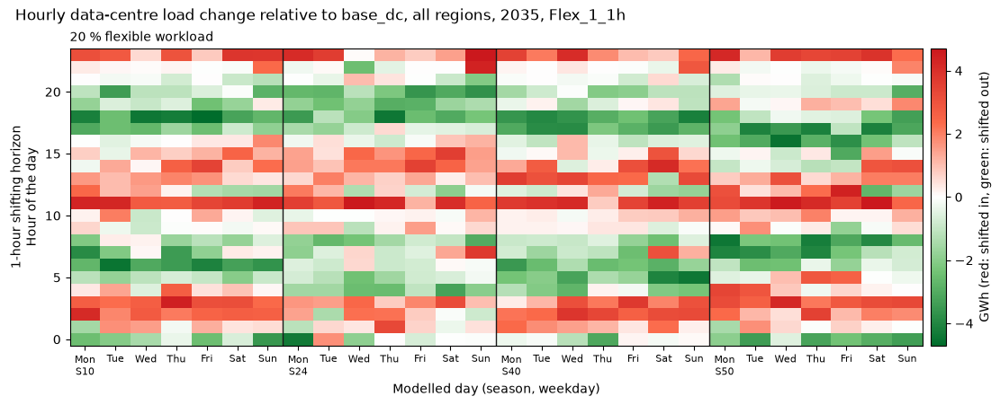

Saved to /work3/s243704/Balmorel/Flex_1_1h/output/fig3_dc_load_change_2035.png


In [29]:
# 2.8.8 Hourly data-centre load change relative to base_dc BASE_RESULTS (GWh), hour of the day x modelled day, one row per shifting horizon,
# all regions, FIG3_YEAR: Figure 3 of Senga et al. (2026) with the Flex_1 results
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

FIG3_YEAR = "2035" if "2035" in sflex_years else sflex_years[-1]
FIG3_BASE = BASE_RESULTS_DIR / BASE_RESULTS                 # baseline of 0.1 (base_dc, same run length): same inputs, no DC flexibility
FIG3_CMAP = LinearSegmentedColormap.from_list("green_white_red", ["#006d2c", "#74c476", "#ffffff", "#fb6a4a", "#cb181d"])
FIG3_DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def fig3_exogenous(path):
    """EXOGENOUS electricity demand per region, season and time step in FIG3_YEAR (MW); includes the served data-centre load."""
    c = gt.Container()
    c.read(str(path), symbols=["EL_DEMAND_YCRST"])
    r = c["EL_DEMAND_YCRST"].records
    r = r.loc[r["Y"].astype(str).eq(FIG3_YEAR) & r["VARIABLE_CATEGORY"].astype(str).eq("EXOGENOUS")]
    return r.astype({k: str for k in ["RRR", "SSS", "TTT"]}).set_index(["RRR", "SSS", "TTT"])["value"].rename_axis(SFLEX_KEYS)

fig3_base = fig3_exogenous(FIG3_BASE)
fig3 = {}                                                    # shifting horizon (h) -> hour-of-day x day table (GWh)
for res_file in sorted(RUN_DIR.glob("MainResults*.gdx")):   # every result pair MainResults<x>.gdx + all_endofmodel<x>.gdx
    eom_file = RUN_DIR / res_file.name.replace("MainResults", "all_endofmodel")
    if not eom_file.exists():
        continue
    exo_run = fig3_exogenous(res_file)
    if set(exo_run.index.get_level_values("Time")) != set(fig3_base.index.get_level_values("Time")):
        print(f"Skipped {res_file.name}: its time steps differ from the base {BASE_RESULTS} (different run length)")
        continue
    c = gt.Container()
    c.read(str(eom_file), symbols=["DC_SHIFTHORIZON", "DC_FLEXSHARE", "VDCF_S", "VDCF_D"])
    h = float(c["DC_SHIFTHORIZON"].records["value"].iloc[0])
    if h in fig3:                                            # the same run under two names
        continue
    s_share = float(c["DC_FLEXSHARE"].records["value"].iloc[0])
    net = {}
    for v in ["VDCF_S", "VDCF_D"]:
        r = c[v].records
        r = r.loc[r["Y"].astype(str).eq(FIG3_YEAR)]
        net[v] = r.astype({k: str for k in ["RRR", "S", "T"]}).set_index(["RRR", "S", "T"])["level"].rename_axis(SFLEX_KEYS)
    del c
    change = exo_run.sub(fig3_base, fill_value=0)                         # MW per region and step
    check = change.sub(net["VDCF_S"].sub(net["VDCF_D"], fill_value=0), fill_value=0).abs().max()
    eu = change.groupby(level=["Season", "Time"]).sum() * SFLEX_STEP_H / 1e3             # GWh per step, all regions
    t = eu.index.get_level_values("Time").str[1:].astype(int) - 1                           # hour of the week (T001 = Monday 00:00)
    grid = pd.DataFrame({"Value": eu.to_numpy(), "Hour": t % 24, "Season": eu.index.get_level_values("Season"),
                         "Day": [FIG3_DAYS[d % 7] for d in t // 24], "DayNo": t // 24})
    grid = grid.pivot_table(index="Hour", columns=["Season", "DayNo", "Day"], values="Value", aggfunc="sum").reindex(range(24))
    fig3[h] = (grid, s_share)
    print(f"h = {h:g} h ({res_file.name}): {eu.clip(lower=0).sum():,.1f} GWh shifted in over the modelled days, "
          f"largest hourly change {eu.abs().max():.2f} GWh; check |EXOGENOUS change - (S - D)| <= {check:.1e} MW")

if not fig3:
    print(f"No flexible results with all_endofmodel in {RUN_DIR}: nothing to show")
else:
    rows = sorted(fig3)
    lim = max(np.nanmax(np.abs(g.to_numpy())) for g, _ in fig3.values())
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    fig, axes = plt.subplots(len(rows), 1, figsize=(11, 3.2 * len(rows) + 1.2), sharex=True, squeeze=False, layout="constrained")
    for ax, h in zip(axes[:, 0], rows):
        grid, s_share = fig3[h]
        im = ax.imshow(grid.to_numpy(), origin="lower", aspect="auto", cmap=FIG3_CMAP, norm=norm, interpolation="nearest")
        seasons = grid.columns.get_level_values("Season")
        for k in range(1, len(seasons)):
            if seasons[k] != seasons[k - 1]:
                ax.axvline(k - 0.5, color="#1a1a1a", linewidth=1)
        ax.set_yticks(range(0, 24, 5))
        ax.set_ylabel(f"{h:g}-hour shifting horizon\nHour of the day")
        ax.set_title(f"{100 * s_share:g} % flexible workload", loc="left", fontsize=10)
    ax.set_xticks(range(grid.shape[1]))
    cols = list(grid.columns)                                # (season, day number, weekday); season named at its first day
    ax.set_xticklabels([f"{d}\n{s}" if k == 0 or s != cols[k - 1][0] else d for k, (s, _, d) in enumerate(cols)], fontsize=8)
    ax.set_xlabel("Modelled day (season, weekday)")
    fig.colorbar(im, ax=axes[:, 0], pad=0.01, label="GWh (red: shifted in, green: shifted out)")
    fig.suptitle(f"Hourly data-centre load change relative to base_dc, all regions, {FIG3_YEAR}, {SCENARIO}", x=0.01, ha="left")
    out = SCENARIO_DIR / "output" / f"fig3_dc_load_change_{FIG3_YEAR}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved to {out}")

#### 2.8.9 EV charging and V2G versus data-centre load shifting: how much flexibility does each add?
A side-by-side comparison of the two demand-side flexibilities of this scenario, both read from the full model (`ENDOFMODEL`), all regions, per region and time step:

| | Electric vehicles (EV add-on) | Data centres (`dcflex`) |
|---|---|---|
| Load the model could not move | the dumb-charging part of the fleet = lower bound of `VEV_G2V` | the floor (1 − `DC_FLEXSHARE`) × *L* |
| Flexibility range (envelope of the grid load) | from fixed charging − maximum V2G (`VEV_V2G.up`) to maximum charging (`VEV_G2V.up`, the connected fleet) | from (1 − *s*)·*L* to the capacity *C* |
| Energy whose timing the model chooses | smart charging (`VEV_G2V` − its lower bound) and V2G | load shifted (net shift into a step) |
| Energy buffer behind it | swing of the fleet battery level `VEV_BE` within a season | swing of the backlog `VDCF_Y` within a season |

Metrics:
- **Energy** (TWh per year, all solved years): EV charging (fixed and smart), V2G, data-centre demand, load shifted and its potential *s* × demand.
- **Power** (GW, all regions per step, `SFLEX_YEAR`): the room to raise the load (up) and to lower it (down) on average and at most, and the largest change actually used.
- **Timing**: the price paid or avoided relative to the average price of all demand, and the average contribution (GW, deviation from the load's own season mean) in the 10 % of steps with the highest and the lowest net load (demand − onshore and offshore wind − solar): negative in the high-net-load steps and positive in the low ones = peak shaving and valley filling.
- **Value**: the cost saved at the marginal prices compared with the same energy as a flat profile in each region and season (Mmoney per year, `SFLEX_YEAR`); for EVs a flat profile is not feasible (cars drive), so this is an upper bound of what their flexibility is worth. For the data centres, the reduction of the total system cost against the base scenario of 0.1 (`base_dc`, identical apart from the data-centre flexibility) is the actual system value.

Energy of the two flexibilities per year, Flex_1_1h


Year,2025,2030,2035
EV charging (TWh),0.00,120.11,234.29
of which fixed (dumb) charging (TWh),0.00,40.12,41.88
of which smart charging (TWh),0.00,79.99,192.41
V2G to the grid (TWh),0.00,37.39,64.02
EV energy with model-chosen timing = smart + V2G (TWh),0.00,117.38,256.43
Data-centre demand (TWh),95.13,133.80,226.50
DC load shifted (TWh),4.00,5.71,9.54
DC shiftable potential = s x demand (TWh),19.03,26.76,45.30


EV flexibility versus data-centre flexibility, all regions, 2035, Flex_1_1h


,EV (smart charging + V2G),Data centres (load shifting)
Energy with model-chosen timing (TWh/yr),256.43,9.54
Room to raise the load: mean / max (GW),138.1 / 230.0,5.2 / 9.8
Room to lower the load: mean / max (GW),49.1 / 167.9,5.2 / 9.9
Largest deviation used: up / down (GW),118.7 / 56.1,4.7 / 4.7
Energy buffer used (GWh),801.09,10.34
Price of smart charging / load shifted in (% of average),68.94,80.09
Price of V2G / load shifted out (% of average),174.53,129.31
Contribution in the 10 % highest net-load steps (GW),-29.39,-1.12
Contribution in the 10 % lowest net-load steps (GW),44.7,0.62
Cost saved vs a flat profile (Mmoney/yr),4307.11,185.4


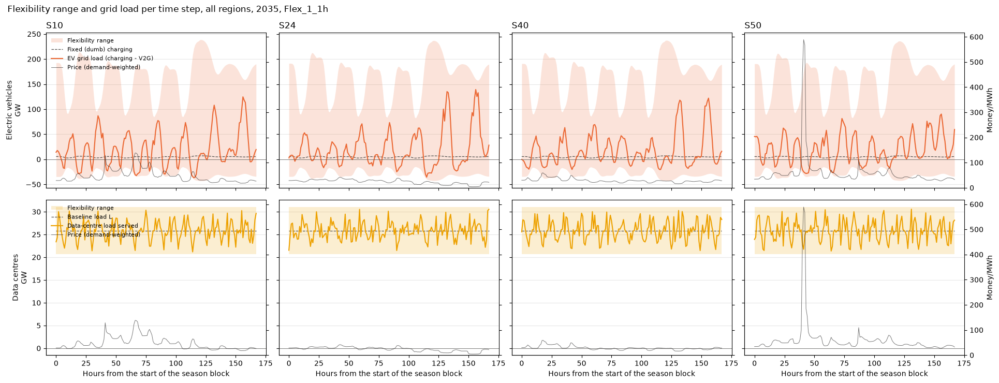

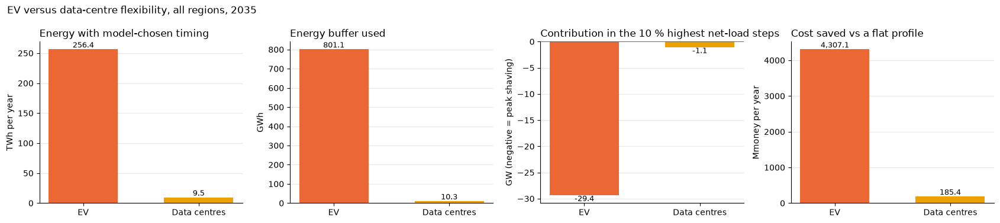

In [30]:
# 2.8.9 EV charging and V2G versus data-centre load shifting: energy, power range, energy buffer, timing and value, all regions
from matplotlib.patches import Patch

# --- EV fleet variables of the full model (BEV and PHEV summed; PHEV or V2G may be absent): level, lower and upper bound (MW)
def ev_var(names):
    c = gt.Container()
    c.read(str(RUN_DIR / ENDOFMODEL), symbols=[n for n in names])
    parts = []
    for n in names:
        r = c[n].records
        if r is not None and len(r):
            parts.append(r.astype({k: str for k in ["Y", "RRR", "S", "T"]}).set_index(["Y", "RRR", "S", "T"])[["level", "lower", "upper"]])
    if not parts:
        return pd.DataFrame(columns=["level", "lower", "upper"], dtype=float, index=pd.MultiIndex.from_tuples([], names=SFLEX_DC_KEYS))
    return pd.concat(parts).groupby(level=[0, 1, 2, 3]).sum().rename_axis(SFLEX_DC_KEYS)

try:
    g2v = ev_var(["VEV_G2V_BEV", "VEV_G2V_PHEV"])
    v2g = ev_var(["VEV_V2G_BEV", "VEV_V2G_PHEV"])
    bat = ev_var(["VEV_BE_BEV", "VEV_BE_PHEV"])
except Exception as exc:                                     # no EV add-on in this run
    print(f"No EV variables in {ENDOFMODEL}: {exc}")
    g2v = v2g = bat = pd.DataFrame(columns=["level", "lower", "upper"], dtype=float, index=pd.MultiIndex.from_tuples([], names=SFLEX_DC_KEYS))

idx = g2v.index.union(v2g.index)
sflex_dc_ev = pd.DataFrame({"Charging": g2v["level"], "Fixed charging": g2v["lower"], "Max charging": g2v["upper"],
                   "V2G": v2g["level"], "Max V2G": v2g["upper"]}).reindex(idx).fillna(0)
sflex_dc_ev["Smart charging"] = sflex_dc_ev["Charging"] - sflex_dc_ev["Fixed charging"]
sflex_dc_ev["Net load"] = sflex_dc_ev["Charging"] - sflex_dc_ev["V2G"]
sflex_dc_ev["Floor"] = sflex_dc_ev["Fixed charging"] - sflex_dc_ev["Max V2G"]               # lowest possible EV grid load (most V2G, only fixed charging)
step_hours = sflex_dc_all["Hours"].groupby(level=["Season", "Time"]).first()
sflex_dc_ev["Hours"] = step_hours.reindex(sflex_dc_ev.index.droplevel(["Year", "Region"])).to_numpy()
dc = sflex_dc_all.copy()
s_share = SFLEX_DC_PAR.get("DC_FLEXSHARE", 0)
dc["Served"] = dc["Baseline"] + dc["Net shift"]
dc["Floor"] = (1 - s_share) * dc["Baseline"]
dc["Capacity"] = sflex_dc_cap.reindex(dc.index.droplevel(["Season", "Time"])).to_numpy() if len(dc) else []

# --- Energy per year (TWh)
twh = lambda df, col: (df[col] * df["Hours"]).groupby(level="Year").sum().reindex(sflex_years, fill_value=0) / 1e6
energy = pd.DataFrame({
    "EV charging (TWh)": twh(sflex_dc_ev, "Charging"),
    "  of which fixed (dumb) charging (TWh)": twh(sflex_dc_ev, "Fixed charging"),
    "  of which smart charging (TWh)": twh(sflex_dc_ev, "Smart charging"),
    "V2G to the grid (TWh)": twh(sflex_dc_ev, "V2G"),
    "EV energy with model-chosen timing = smart + V2G (TWh)": twh(sflex_dc_ev, "Smart charging") + twh(sflex_dc_ev, "V2G"),
    "Data-centre demand (TWh)": twh(dc, "Baseline"),
    "DC load shifted (TWh)": twh(dc, "Net in"),
    "DC shiftable potential = s x demand (TWh)": s_share * twh(dc, "Baseline"),
}).T
print(f"Energy of the two flexibilities per year, {SCENARIO}")
display(energy.round(2))

# --- SFLEX_YEAR, all regions per step (GW): envelope, use, and the deviation from the load's own season mean
Y0 = SFLEX_YEAR
evy = sflex_dc_ev.loc[sflex_dc_ev.index.get_level_values("Year") == Y0].droplevel("Year")
dcy = dc.loc[dc.index.get_level_values("Year") == Y0].droplevel("Year")
eu_ev = evy.drop(columns="Hours").groupby(level=["Season", "Time"]).sum().reindex(step_hours.index, fill_value=0) / 1e3
eu_dc = dcy.drop(columns="Hours").groupby(level=["Season", "Time"]).sum().reindex(step_hours.index, fill_value=0) / 1e3
eu_ev["Up"], eu_ev["Down"] = eu_ev["Max charging"] - eu_ev["Charging"], eu_ev["Net load"] - eu_ev["Floor"]
eu_dc["Up"], eu_dc["Down"] = eu_dc["Capacity"] - eu_dc["Served"], eu_dc["Served"] - eu_dc["Floor"]
dev_ev = eu_ev["Net load"] - eu_ev["Net load"].groupby(level="Season").transform("mean")    # EV grid load around its season mean
dev_dc = eu_dc["Net shift"]                                                                  # DC load around its (flat) baseline
eu_all = sflex_h.groupby(level=["Season", "Time"]).sum().reindex(step_hours.index)
net_load = (eu_all["Total demand"] - eu_all["Onshore + offshore wind + solar"]) / 1e3
hi, lo = net_load >= net_load.quantile(0.9), net_load <= net_load.quantile(0.1)

# Prices: regional marginal cost per step; reference = average price paid by all electricity demand
p = sflex_h["Price"]
p_avg = (p * sflex_h["Total demand"]).sum() / sflex_h["Total demand"].sum()
def price_of(load):
    load = load.reindex(p.index, fill_value=0)
    return (p * load).sum() / load.sum() if load.sum() > 0 else np.nan
# Cost saved at marginal prices against the same energy as a flat profile per region and season (Mmoney per year)
def saving_vs_flat(x, hours):
    x = x.reindex(p.index, fill_value=0)
    w = hours.reindex(p.index.droplevel("Region")).to_numpy()                  # hours of the year each step stands for
    dev = x - x.groupby(level=["Region", "Season"]).transform("mean")           # deviation from the flat profile (same energy)
    return -(p * dev * w).sum() / 1e6
buffer = lambda level, step_h=1.0: (level.groupby(level=["Region", "Season"]).agg(lambda v: v.max() - v.min()) * step_h).groupby(level="Season").sum().max() / 1e3

rows = {
    "EV (smart charging + V2G)": {
        "Energy with model-chosen timing (TWh/yr)": energy.loc["EV energy with model-chosen timing = smart + V2G (TWh)", Y0],
        "Room to raise the load: mean / max (GW)": f"{eu_ev['Up'].mean():.1f} / {eu_ev['Up'].max():.1f}",
        "Room to lower the load: mean / max (GW)": f"{eu_ev['Down'].mean():.1f} / {eu_ev['Down'].max():.1f}",
        "Largest deviation used: up / down (GW)": f"{dev_ev.max():.1f} / {-dev_ev.min():.1f}",
        "Energy buffer used (GWh)": buffer(bat.loc[bat.index.get_level_values("Year") == Y0, "level"].droplevel("Year")) if len(bat) else 0.0,
        "Price paid for smart charging (% of average)": 100 * price_of(evy["Smart charging"]) / p_avg,
        "Price of V2G / load shifted out (% of average)": 100 * price_of(evy["V2G"]) / p_avg,
        "Contribution in the 10 % highest net-load steps (GW)": dev_ev[hi].mean(),
        "Contribution in the 10 % lowest net-load steps (GW)": dev_ev[lo].mean(),
        "Cost saved vs a flat profile (Mmoney/yr)": saving_vs_flat(evy["Net load"], step_hours),
    },
    "Data centres (load shifting)": {
        "Energy with model-chosen timing (TWh/yr)": energy.loc["DC load shifted (TWh)", Y0],
        "Room to raise the load: mean / max (GW)": f"{eu_dc['Up'].mean():.1f} / {eu_dc['Up'].max():.1f}",
        "Room to lower the load: mean / max (GW)": f"{eu_dc['Down'].mean():.1f} / {eu_dc['Down'].max():.1f}",
        "Largest deviation used: up / down (GW)": f"{dev_dc.max():.1f} / {-dev_dc.min():.1f}",
        "Energy buffer used (GWh)": buffer(dcy["Backlog"], SFLEX_STEP_H) if len(dcy) else 0.0,
        "Price paid for smart charging (% of average)": 100 * price_of(dcy["Net in"]) / p_avg,
        "Price of V2G / load shifted out (% of average)": 100 * price_of(dcy["Net out"]) / p_avg,
        "Contribution in the 10 % highest net-load steps (GW)": dev_dc[hi].mean(),
        "Contribution in the 10 % lowest net-load steps (GW)": dev_dc[lo].mean(),
        "Cost saved vs a flat profile (Mmoney/yr)": saving_vs_flat(dcy["Served"], step_hours),
    },
}
cmp_flex = pd.DataFrame(rows)
cmp_flex = cmp_flex.rename(index={"Price paid for smart charging (% of average)": "Price of smart charging / load shifted in (% of average)"})
# Actual system value of the data-centre flexibility: total system cost of the base (no DC flexibility) minus this scenario
try:
    obj = lambda r, scen: r.get_result("OBJ_YCR").rename(columns=RENAME).query("Scenario == @scen").assign(Year=lambda d: d["Year"].astype(str)).groupby("Year")["Value"].sum()
    dc_value = obj(base_res, BASE_SCENARIO) - obj(res, SCENARIO)
    cmp_flex.loc[f"System cost saving vs {BASE_SCENARIO} (Mmoney/yr)"] = ["n/a (no run without EV flexibility)", round(dc_value.get(Y0, np.nan), 1)]
except Exception as exc:
    print(f"System cost comparison skipped: {exc}")
print(f"EV flexibility versus data-centre flexibility, all regions, {Y0}, {SCENARIO}")
display(cmp_flex.map(lambda v: round(v, 2) if isinstance(v, (float, np.floating)) else v))

# --- Figure 1: flexibility envelope and actual grid load per time step, EV (top) and data centres (bottom), GW
fig, axes = plt.subplots(2, len(SFLEX_SEASONS), figsize=(4.6 * len(SFLEX_SEASONS) + 1, 7.5), sharex="col", sharey="row", squeeze=False)
twins = []                                                                   # price axes: one common scale, otherwise each season is stretched to full height
for k, season in enumerate(SFLEX_SEASONS):
    hours = np.arange(len(SFLEX_TIMES)) * SFLEX_STEP_H
    for row, (e, lo_col, hi_col, act, ref, ref_label, color, name) in enumerate([
            (eu_ev, "Floor", "Max charging", "Net load", "Fixed charging", "Fixed (dumb) charging", SFLEX_COLORS["EV charging"], "EV grid load (charging - V2G)"),
            (eu_dc, "Floor", "Capacity", "Served", "Baseline", "Baseline load L", SFLEX_COLORS["DC shifted in"], "Data-centre load served")]):
        ax = axes[row, k]
        x = e.xs(season, level="Season").reindex(SFLEX_TIMES, fill_value=0)
        ax.fill_between(hours, x[lo_col], x[hi_col], color=color, alpha=0.18, linewidth=0, label="Flexibility range")
        ax.plot(hours, x[ref], color="#52514e", linewidth=0.9, linestyle="--", label=ref_label)
        ax.plot(hours, x[act], color=color, linewidth=1.5, label=name)
        ax.axhline(0, color="#52514e", linewidth=0.5)
        tw = ax.twinx()
        tw.plot(hours, (sflex_h["Price"] * sflex_h["Total demand"]).groupby(level=["Season", "Time"]).sum().xs(season, level="Season")
                .reindex(SFLEX_TIMES) / eu_all.xs(season, level="Season")["Total demand"].reindex(SFLEX_TIMES),
                color="#1a1a1a", linewidth=0.7, alpha=0.6, label="Price (demand-weighted)")
        twins.append(tw)
        tw.set_ylabel("Money/MWh" if k == len(SFLEX_SEASONS) - 1 else "")
        if k < len(SFLEX_SEASONS) - 1:
            tw.tick_params(labelright=False)
        sflex_style(ax, season if row == 0 else "", ("Electric vehicles\nGW" if row == 0 else "Data centres\nGW") if k == 0 else "")
        if row == 1:
            ax.set_xlabel("Hours from the start of the season block")
        if k == 0:
            handles = ax.get_legend_handles_labels()
            ax.legend(handles[0] + tw.get_legend_handles_labels()[0], handles[1] + tw.get_legend_handles_labels()[1],
                      frameon=False, fontsize=8, loc="upper left")
lo, hi = min(t.get_ylim()[0] for t in twins), max(t.get_ylim()[1] for t in twins)
for tw in twins:
    tw.set_ylim(min(lo, 0), hi)                                              # same price scale in every season and in both rows
fig.suptitle(f"Flexibility range and grid load per time step, all regions, {Y0}, {SCENARIO}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

# --- Figure 2: the key metrics side by side
metrics = [("Energy with model-chosen timing (TWh/yr)", "TWh per year"),
           ("Energy buffer used (GWh)", "GWh"),
           ("Contribution in the 10 % highest net-load steps (GW)", "GW (negative = peak shaving)"),
           ("Cost saved vs a flat profile (Mmoney/yr)", "Mmoney per year")]
colors = [SFLEX_COLORS["EV charging"], SFLEX_COLORS["DC shifted in"]]
fig, axes = plt.subplots(1, len(metrics), figsize=(17, 3.8))
for ax, (m, unit) in zip(axes, metrics):
    vals = cmp_flex.loc[m].astype(float)
    ax.bar(["EV", "Data centres"], vals.to_numpy(), color=colors, width=0.6)
    ax.axhline(0, color="#52514e", linewidth=0.6)
    for xpos, v in enumerate(vals):
        ax.annotate(f"{v:,.1f}", (xpos, v), ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    sflex_style(ax, m.split(" (")[0], unit)
fig.suptitle(f"EV versus data-centre flexibility, all regions, {Y0}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

#### 2.8.10 Average operations per country by hour of the day, as Figure 5 of Senga et al. (2026)
The average day of a season block (`FIG5_SEASONS`, default S24 = week 24, the summer season; the mean over its 7 days) in `SFLEX_YEAR`, for the countries with the largest data-centre demand (`FIG5_COUNTRIES`), laid out as Figure 5 of Senga, Wang & Knittel (2026, *iScience*): the left column is the base scenario of 0.1 (`base_dc`, no flexibility), the right column this scenario with its `DC_SHIFTHORIZON`-hour shifting horizon. Everything is in GW, summed over the regions of a country.
- **Stacked areas**: the electricity generation by technology type. Every electricity technology of the model is included: nuclear, hydro (reservoirs and run-of-river), onshore and offshore wind, solar PV, CHP and condensing plants split by fuel (natural gas, biomass and biogas, waste), storage discharge, and a last group for oil, oil shale, hydrogen (fuel cells) and others. **Net imports** (grey) complete the supply, so the stack meets the demand of the country exactly; net exports are drawn below zero.
- **Red lines** (left axis): the net load = electricity demand minus wind and solar generation, with flexibility (solid) and in the base scenario without it (dashed).
- **Green lines** (right axis, same scale in the whole row): the data-centre load served with flexibility *L + S − D* (solid) and the baseline load *L* without flexibility (dashed).
- **Black lines** (outer right axis, same scale in the whole row): the electricity price of the country (the regional prices weighted by the regional demand of each step, then averaged over the days), with flexibility (solid) and in the base scenario (dashed).

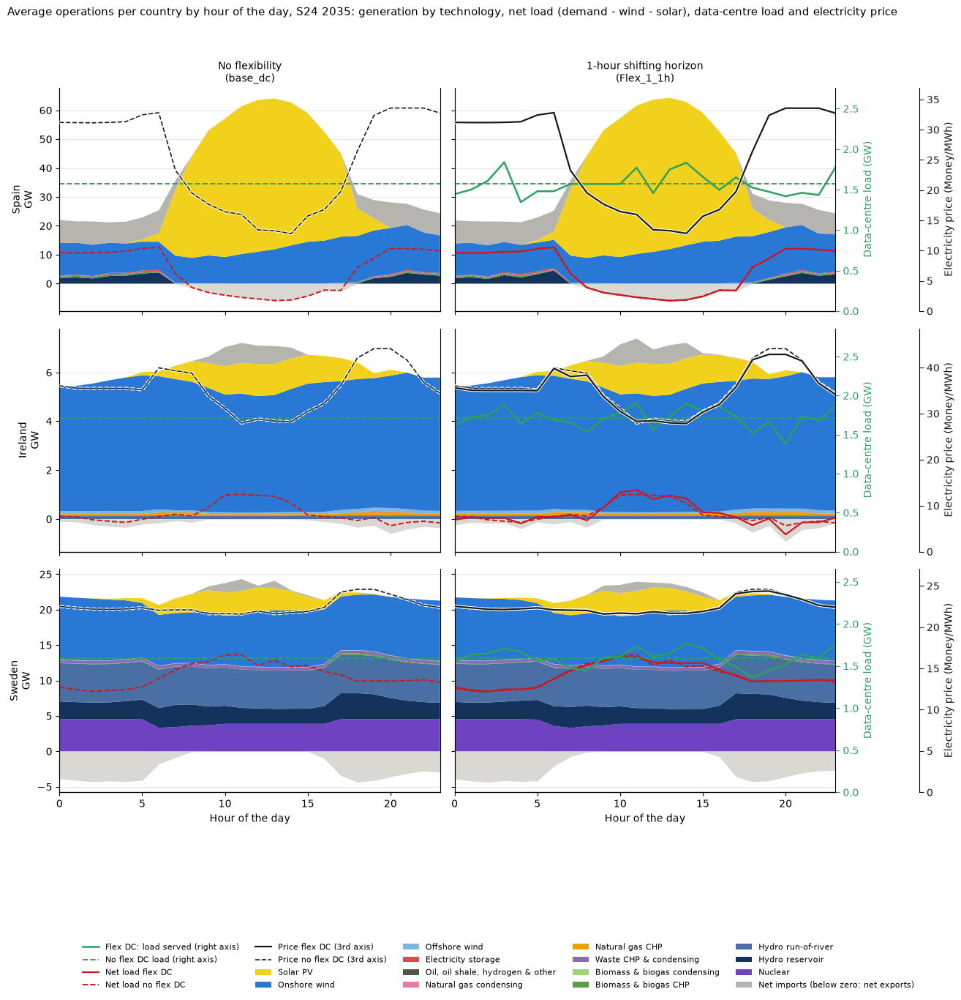

In [88]:
# 2.8.10 Average operations per country by hour of the day, as Figure 5 of Senga et al. (2026): generation by technology, net load and data-centre load
# Columns: base_dc (no flexibility) and this scenario (DC_SHIFTHORIZON shifting horizon); rows: the countries with the largest data-centre demand
FIG5_SEASONS = ["S24"]                 # season block(s) averaged over their days (S24 = week 24, the summer season); e.g. ["S10", "S24", "S40", "S50"] for the whole modelled year
FIG5_COUNTRIES = ["SPAIN", "IRELAND", "SWEDEN"]                   # None = the 3 countries with the largest data-centre demand; or a list such as ["GERMANY", "FRANCE", "UNITED_KINGDOM"]
FIG5_YEAR = SFLEX_YEAR
if not SFLEX_HAS_DC:
    raise RuntimeError("2.8.10 needs a run with data-centre flexibility (dcflex): there is no data-centre load profile in this scenario")
# Technology types in stacking order (bottom to top); every electricity technology of the model falls in one of them
FIG5_COLORS = {"Nuclear": "#6f42c1", "Hydro reservoir": "#14335c", "Hydro run-of-river": "#4a6fa5", "Biomass & biogas CHP": "#5a9e3d",
               "Biomass & biogas condensing": "#9fd37a", "Waste CHP & condensing": "#8c6bb1", "Natural gas CHP": "#eda100",
               "Natural gas condensing": "#e87ba4", "Oil, oil shale, hydrogen & other": "#52514e", "Electricity storage": "#e34948",
               "Offshore wind": "#7fb5e0", "Onshore wind": "#2a78d6", "Solar PV": "#f2d11c"}
FIG5_NET_IMPORTS, FIG5_NET_EXPORTS = "Net imports", "Net exports"

def fig5_type(pro):
    tech, fuel = pro["Technology"].astype(str).str.upper(), pro["Fuel"].astype(str).str.upper()
    chp, cond = tech.str.contains("CHP"), tech.str.contains("CONDENSING")
    kind = pd.Series("Oil, oil shale, hydrogen & other", index=pro.index)
    kind[tech.str.contains("HYDRO-RESERVOIRS")], kind[tech.str.contains("HYDRO-RUN")] = "Hydro reservoir", "Hydro run-of-river"
    kind[tech.str.contains("WIND-ON|WIND_ON")], kind[tech.str.contains("WIND-OFF|WIND_OFF")] = "Onshore wind", "Offshore wind"
    kind[tech.str.contains("SOLAR-PV|SOLAR_PV")] = "Solar PV"
    kind[tech.str.contains("STORAGE")] = "Electricity storage"
    kind[cond & fuel.eq("NUCLEAR")] = "Nuclear"
    bio, waste, gas = fuel.str.contains("WOOD|STRAW|BIOGAS|BIOOIL"), fuel.isin(["MUNIWASTE", "WASTEHEAT", "HEAT"]), fuel.eq("NATGAS")
    kind[chp & bio], kind[cond & bio] = "Biomass & biogas CHP", "Biomass & biogas condensing"
    kind[(chp | cond) & waste] = "Waste CHP & condensing"
    kind[chp & gas], kind[cond & gas] = "Natural gas CHP", "Natural gas condensing"
    return kind

def fig5_table(results, scenario, symbol):
    t = results.get_result(symbol).rename(columns=RENAME)
    t = t.loc[t["Scenario"].eq(scenario) & t["Year"].astype(str).eq(FIG5_YEAR)].copy()
    if "Time" in t:
        t = t.loc[t["Season"].isin(FIG5_SEASONS)]
        t["Hour"] = ((t["Time"].str[1:].astype(int) - 1) * (SFLEX_STEP_H or 1)).astype(int) % 24          # hour of the day (T001 = 00:00)
    return t

def fig5_profiles(results, scenario):
    """Average day per country (by hour of the day, mean over the days of FIG5_SEASONS): generation by type, demand, net imports (GW) and the price (Money/MWh)."""
    pro = fig5_table(results, scenario, "PRO_YCRAGFST")
    pro = pro.loc[pro["Commodity"].eq("ELECTRICITY")].assign(Type=lambda d: fig5_type(d))
    n_days = pro.groupby("Season")["Time"].nunique().mul(SFLEX_STEP_H or 1).div(24).sum()
    day = lambda s: s.groupby(level=[k for k in s.index.names if k != "Season"]).sum() / n_days / 1e3          # sum over the steps of the same hour -> mean day, GW
    gen = day(pro.groupby(["Season", "Country", "Hour", "Type"])["Value"].sum()).unstack("Type", fill_value=0)
    dem = fig5_table(results, scenario, "EL_DEMAND_YCRST")
    demand = day(dem.groupby(["Season", "Country", "Hour"])["Value"].sum())
    # Electricity price of a country: the regional prices of each step weighted by the regional demand, then the mean over the days
    price = fig5_table(results, scenario, "EL_PRICE_YCRST").set_index(["Country", "Region", "Season", "Time", "Hour"])["Value"].rename("Price")
    weight = dem.groupby(["Country", "Region", "Season", "Time", "Hour"])["Value"].sum().rename("Demand")
    pw = pd.concat([price, weight], axis=1).dropna()
    pw["PxD"] = pw["Price"] * pw["Demand"]
    step = pw.groupby(level=["Country", "Season", "Time", "Hour"])[["PxD", "Demand"]].sum()
    price_day = (step["PxD"] / step["Demand"].replace(0, np.nan)).groupby(level=["Country", "Hour"]).mean()
    region_country = fig5_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    flow = fig5_table(results, scenario, "X_FLOW_YCRST").assign(CFrom=lambda d: d["From"].map(region_country), CTo=lambda d: d["To"].map(region_country))
    flow = flow.loc[flow["CFrom"].ne(flow["CTo"])]
    imports = day(flow.groupby(["Season", "CTo", "Hour"])["Value"].sum().rename_axis(["Season", "Country", "Hour"])) \
        .sub(day(flow.groupby(["Season", "CFrom", "Hour"])["Value"].sum().rename_axis(["Season", "Country", "Hour"])), fill_value=0)
    return gen, demand, imports, price_day

gen_s, dem_s, imp_s, price_s = fig5_profiles(res, SCENARIO)
gen_b, dem_b, imp_b, price_b = fig5_profiles(base_res, BASE_SCENARIO)
vre = lambda g: g.reindex(columns=["Onshore wind", "Offshore wind", "Solar PV"], fill_value=0).sum(axis=1)
netload_s, netload_b = dem_s - vre(gen_s), dem_b - vre(gen_b)

# Data-centre load per country: baseline L (no flexibility) and the load served with flexibility L + S - D (scenario)
dc_region = sflex_dc[["Baseline", "Net shift"]].reset_index()
dc_region = dc_region.loc[dc_region["Season"].isin(FIG5_SEASONS)].assign(Hour=lambda d: ((d["Time"].str[1:].astype(int) - 1) * (SFLEX_STEP_H or 1)).astype(int) % 24)
dc_region["Country"] = dc_region["Region"].map(fig5_table(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"])
dc_region["Served"] = dc_region["Baseline"] + dc_region["Net shift"]
dc_day = dc_region.groupby(["Country", "Season", "Time", "Hour"])[["Baseline", "Served"]].sum().groupby(["Country", "Hour"]).mean() / 1e3        # GW (mean day)
countries = FIG5_COUNTRIES or list(dc_day["Baseline"].groupby(level="Country").mean().sort_values(ascending=False).index[:3])

columns = [(f"No flexibility\n({BASE_SCENARIO})", gen_b, imp_b, False), (f"{SFLEX_DC_PAR.get('DC_SHIFTHORIZON', 0):g}-hour shifting horizon\n({SCENARIO})", gen_s, imp_s, True)]
import matplotlib.patheffects as pe
halo = [pe.withStroke(linewidth=3, foreground="white")]                    # keeps the price line readable on top of the dark areas
hours = np.arange(24)
fig, axes = plt.subplots(len(countries), len(columns), figsize=(5.6 * len(columns) + 2.5, 3.6 * len(countries) + 3), sharex=True, sharey="row", squeeze=False)
for r, country in enumerate(countries):
    for c, (title, gen, imp, flexible) in enumerate(columns):
        ax = axes[r, c]
        g = gen.xs(country, level="Country").reindex(hours).fillna(0)
        order = [t for t in FIG5_COLORS if t in g and g[t].abs().max() > 1e-9]
        net_imp = imp.xs(country, level="Country").reindex(hours).fillna(0) if country in imp.index.get_level_values("Country") else pd.Series(0.0, index=hours)
        stack = [g[t] for t in order] + [net_imp.clip(lower=0)]
        ax.stackplot(hours, *stack, colors=[FIG5_COLORS[t] for t in order] + ["#b5b4ae"], linewidth=0)
        ax.fill_between(hours, 0, net_imp.clip(upper=0), color="#d9d8d3", linewidth=0)
        ax.plot(hours, netload_b.xs(country, level="Country").reindex(hours), color="#cb181d", linewidth=1.4, linestyle="--")
        ax2 = ax.twinx()                                   # the data-centre load is small next to the system: own axis, same scale in the whole row
        ax2.plot(hours, dc_day["Baseline"].xs(country, level="Country").reindex(hours), color="#2ca25f", linewidth=1.4, linestyle="--")
        if flexible:
            ax.plot(hours, netload_s.xs(country, level="Country").reindex(hours), color="#cb181d", linewidth=1.6)
            ax2.plot(hours, dc_day["Served"].xs(country, level="Country").reindex(hours), color="#2ca25f", linewidth=1.8)
        ax2.set_ylim(0, 1.5 * dc_day[["Baseline", "Served"]].xs(country, level="Country").max().max())
        ax2.tick_params(axis="y", colors="#2ca25f", labelright=(c == len(columns) - 1), length=4 if c == len(columns) - 1 else 0); ax2.spines["top"].set_visible(False)
        ax2.set_ylabel("Data-centre load (GW)" if c == len(columns) - 1 else "", color="#2ca25f")
        ax3 = ax.twinx()                                   # electricity price: third axis, same scale in the whole row
        ax3.spines["right"].set_position(("axes", 1.22))
        ax3.plot(hours, price_b.xs(country, level="Country").reindex(hours), color="#1a1a1a", linewidth=1.2, linestyle="--", path_effects=halo)
        if flexible:
            ax3.plot(hours, price_s.xs(country, level="Country").reindex(hours), color="#1a1a1a", linewidth=1.6, path_effects=halo)
        ax3.set_ylim(0, 1.1 * max(price_b.xs(country, level="Country").max(), price_s.xs(country, level="Country").max()))
        ax3.tick_params(axis="y", colors="#1a1a1a", labelright=(c == len(columns) - 1), length=4 if c == len(columns) - 1 else 0)
        for side in ("top", "left"): ax3.spines[side].set_visible(False)
        ax3.spines["right"].set_visible(c == len(columns) - 1)      # the extra axis is only drawn at the right edge of the figure
        ax3.set_ylabel("Electricity price (Money/MWh)" if c == len(columns) - 1 else "", color="#1a1a1a")
        ax.set_xlim(0, 23); ax.set_xticks(range(0, 24, 5)); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        if r == 0: ax.set_title(title, fontsize=10)
        if c == 0: ax.set_ylabel(f"{clean_name(country)}\nGW")
        if r == len(countries) - 1: ax.set_xlabel("Hour of the day")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
used = [t for t in FIG5_COLORS if any(t in g.columns and g[t].abs().max() > 1e-9 for g in (gen_s, gen_b))]
handles = [Line2D([], [], color="#2ca25f", lw=1.8, label="Flex DC: load served (right axis)"), Line2D([], [], color="#2ca25f", lw=1.4, ls="--", label="No flex DC load (right axis)"),
           Line2D([], [], color="#cb181d", lw=1.6, label="Net load flex DC"), Line2D([], [], color="#cb181d", lw=1.4, ls="--", label="Net load no flex DC"),
           Line2D([], [], color="#1a1a1a", lw=1.6, label="Price flex DC (3rd axis)"), Line2D([], [], color="#1a1a1a", lw=1.2, ls="--", label="Price no flex DC (3rd axis)")] \
          + [Patch(facecolor=FIG5_COLORS[t], label=t) for t in used[::-1]] + [Patch(facecolor="#b5b4ae", label=FIG5_NET_IMPORTS + " (below zero: net exports)")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"Average operations per country by hour of the day, {'+'.join(FIG5_SEASONS)} {FIG5_YEAR}: generation by technology, net load (demand - wind - solar), data-centre load and electricity price", x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0.16, 0.96, 0.96)); plt.show()

## 3. Total capacity mix
`G_CAP_YCRAF` splits capacity into `EXOGENOUS` (existing / given), `ENDOGENOUS` (investments) and `DECOMMISSIONING` (negative).
The installed capacity of a year is the sum of the three. One chart per output commodity.

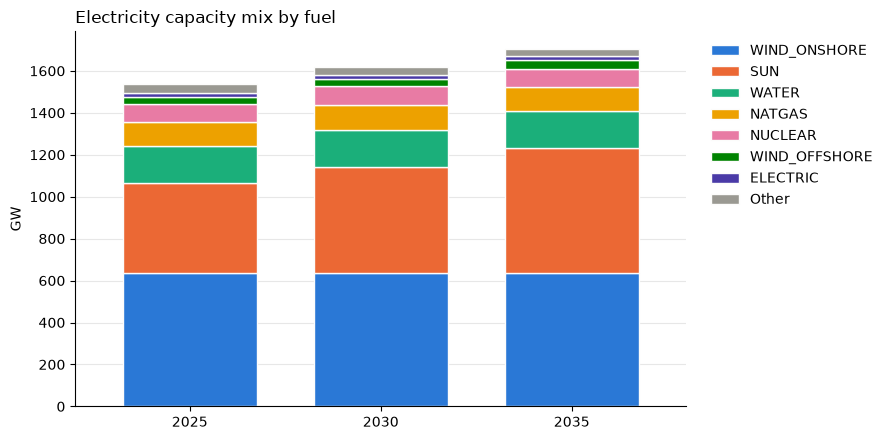

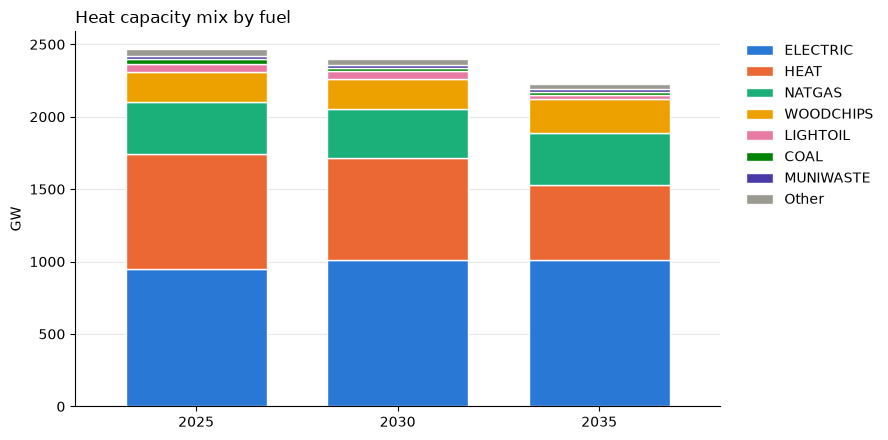

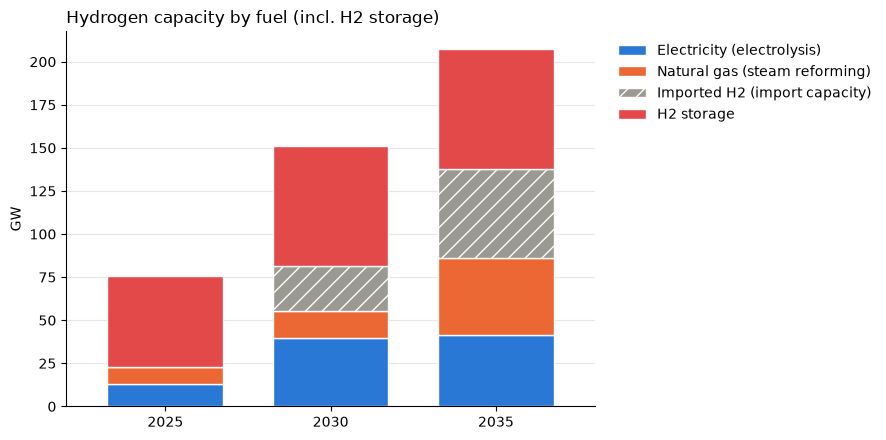

Label,Electricity (electrolysis),H2 storage,Imported H2 (import capacity),Natural gas (steam reforming)
Year,,,,
2025,13.27,52.63,0.00,9.51
2030,39.88,69.46,26.29,15.29
2035,41.41,69.63,51.72,44.51


In [32]:
# 3.1 Installed capacity per fuel per year = exogenous + endogenous + decommissioning (GW)
cap = get("G_CAP_YCRAF")
for commodity in ["ELECTRICITY", "HEAT"]:
    table = cap[cap["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} capacity mix by fuel", "GW")
    plt.tight_layout(); plt.show()

# Hydrogen: capacity labelled by its input fuel, with H2 storage (fuel HYDROGEN) as its own segment.
# and the IMPORT_H2 capacity (modelled as an ELECTROLYZER, but it does not produce H2 in the model) is shown separately.
H2_STORAGE_TECH = ["H2-STORAGE"]
H2_FUEL_LABEL = {"ELECTRIC": "Electricity (electrolysis)", "NATGAS": "Natural gas (steam reforming)", "IMPORT_H2": "Imported H2 (import capacity)"}

def h2_label(df):
    """Input-fuel label per hydrogen row; H2 storage rows are labelled 'H2 storage'."""
    label = df["Fuel"].map(H2_FUEL_LABEL).fillna(df["Fuel"].map(clean_name) + " (" + df["Technology"].str.lower() + ")")
    return label.mask(df["Technology"].isin(H2_STORAGE_TECH), "H2 storage")

h2 = cap[cap["Commodity"] == "HYDROGEN"]
h2_table = (h2.assign(Label=h2_label(h2))
              .groupby(["Year", "Label"])["Value"].sum().unstack("Label").fillna(0))
h2_colors = {"Electricity (electrolysis)": "#2a78d6", "Natural gas (steam reforming)": "#eb6834", "Imported H2 (import capacity)": GREY,
             "H2 storage": "#e34948"}
h2_colors.update({l: c for l, c in zip([l for l in h2_table.columns if l not in h2_colors], PALETTE[2:])})
ax = stacked_bar(h2_table, h2_colors, "Hydrogen capacity by fuel (incl. H2 storage)", "GW")
h2_cols = [c for c in h2_colors if c in h2_table.columns]                  # stack order used by stacked_bar
if "Imported H2 (import capacity)" in h2_cols:
    for patch in ax.containers[h2_cols.index("Imported H2 (import capacity)")]:
        patch.set_hatch("//")                                               # imports are not domestic production
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()
display(h2_table.round(2))


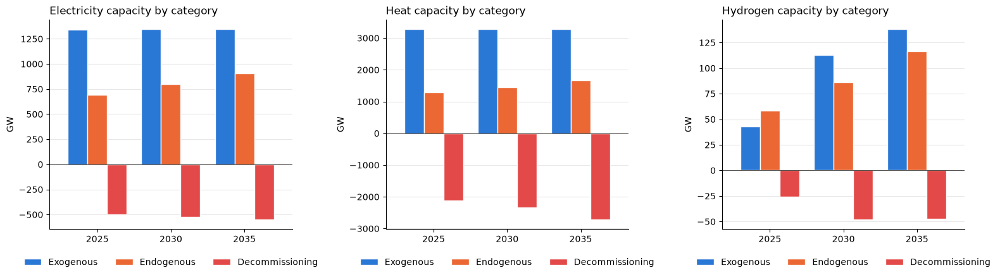

In [33]:
# 3.2 Where does the capacity come from? Exogenous, endogenous (investments) and decommissioning (GW)
CAT_COLORS = {"EXOGENOUS": "#2a78d6", "ENDOGENOUS": "#eb6834", "DECOMMISSIONING": "#e34948"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, commodity in zip(axes, ["ELECTRICITY", "HEAT", "HYDROGEN"]):
    t = cap[cap["Commodity"] == commodity].groupby(["Year", "Category"])["Value"].sum().unstack("Category").fillna(0)
    t = t[[c for c in CAT_COLORS if c in t.columns]]
    t.plot.bar(ax=ax, color=[CAT_COLORS[c] for c in t.columns], width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(f"{commodity.title()} capacity by category", loc="left"); ax.set_ylabel("GW"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(t))); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend([clean_name(c) for c in t.columns], frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, -0.1), ncol=3)
    ax.axhline(0, color="#52514e", linewidth=0.8)          # zero line drawn after the legend exists
plt.tight_layout(); plt.show()

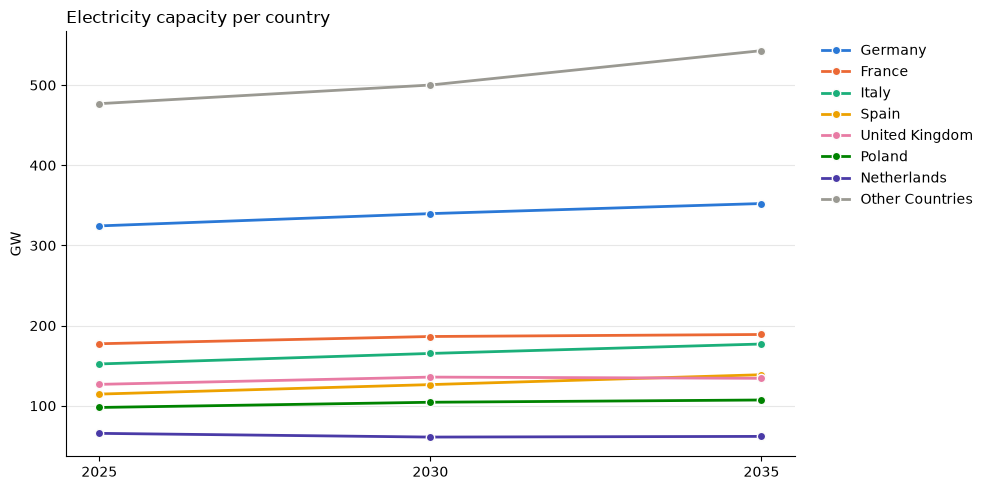

In [34]:
# 3.3 Electricity capacity per country (GW): line plot of the 7 largest countries, the rest summed as "Other countries"
cap_el = cap[cap["Commodity"] == "ELECTRICITY"]
by_country = cap_el.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0)
by_country = by_country.sort_values(by_country.columns[-1], ascending=False)

other = by_country.iloc[7:].sum().to_frame("Other countries").T
plot_df = pd.concat([by_country.head(7), other]).T            # rows = years, columns = lines

palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#9a9992"]
fig, ax = plt.subplots(figsize=(10, 5))
for name, color in zip(plot_df.columns, palette):
    ax.plot(plot_df.index, plot_df[name], marker="o", markersize=6, linewidth=2, color=color,
            markeredgecolor="#fcfcfb", label=name.replace("_", " ").title())
ax.set_title("Electricity capacity per country", loc="left")
ax.set_ylabel("GW"); ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()


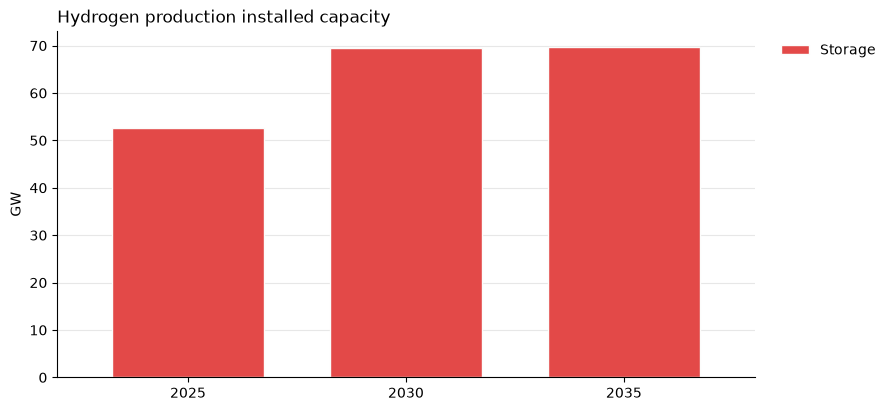

In [35]:
# 3.4 Hydrogen production capacity
cap = get("G_CAP_YCRAF")
hydrogen_cap = cap[cap["Commodity"] == "HYDROGEN"].copy()
hydrogen_cap["Technology group"] = hydrogen_cap["Technology"].map(TECH_GROUP).fillna("Other")
hydrogen_cap = hydrogen_cap.groupby(["Year", "Technology group"])["Value"].sum().unstack("Technology group").fillna(0)
stacked_bar(hydrogen_cap, GROUP_COLORS_UNPACKED, "Hydrogen production installed capacity", "GW")
plt.show()

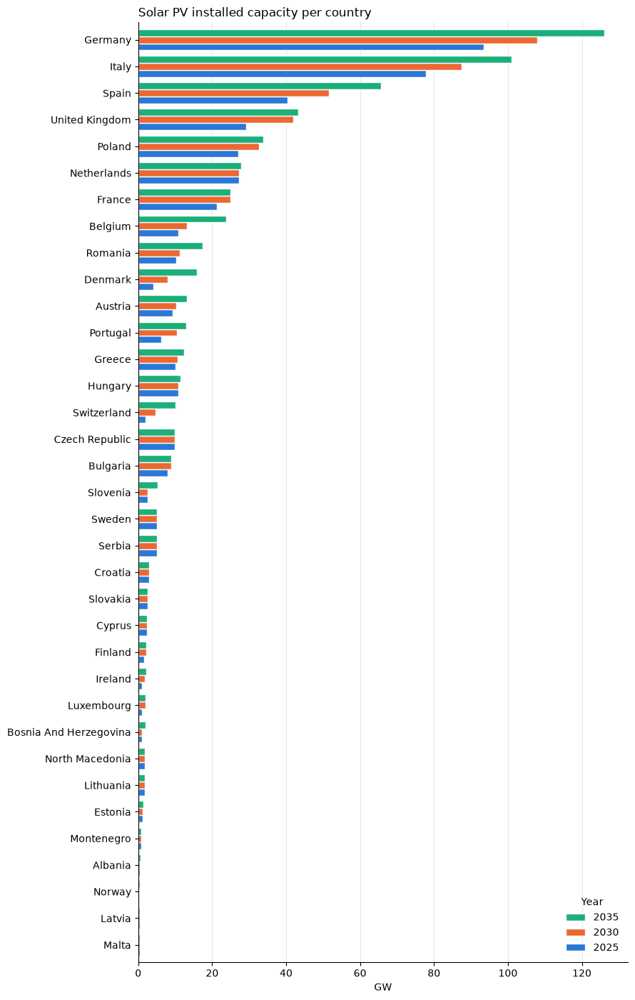

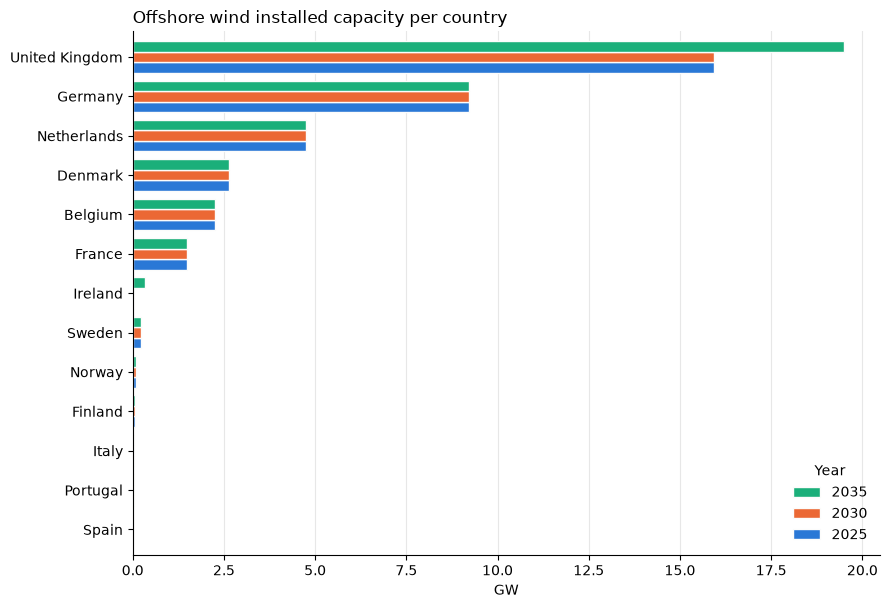

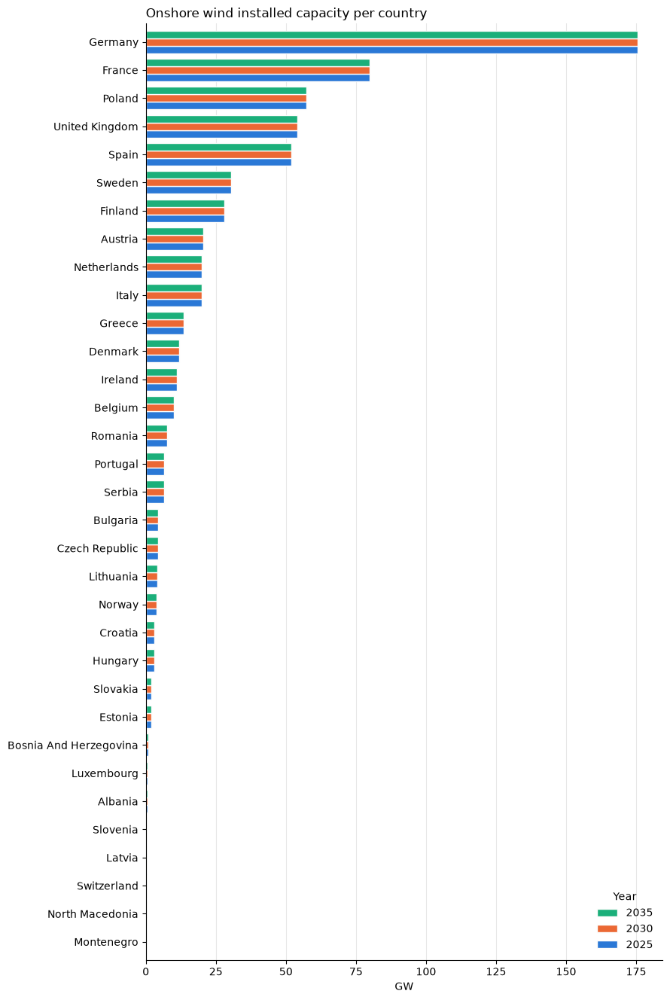

In [36]:
# 3.5 Installed solar PV, offshore wind and onshore wind capacity per country (GW), one chart per technology
# Countries sorted by capacity in the last year; countries without any capacity of the technology are left out
VRE_TECH = {"SOLAR-PV": "Solar PV", "WIND-OFF": "Offshore wind", "WIND-ON": "Onshore wind"}
vre_cap = cap[(cap["Commodity"] == "ELECTRICITY") & cap["Technology"].isin(VRE_TECH)]
vre_cap = vre_cap.groupby(["Technology", "Country", "Year"])["Value"].sum().unstack("Year").fillna(0)

for tech, label in VRE_TECH.items():
    t = vre_cap.loc[tech] if tech in vre_cap.index.get_level_values("Technology") else pd.DataFrame()
    t = t[t.abs().sum(axis=1) > 1e-6].sort_values(t.columns[-1]) if len(t) else t   # largest on top
    if t.empty:
        print(f"No {label} capacity in {SCENARIO}"); continue
    fig, ax = plt.subplots(figsize=(9, max(3, 0.12 * t.shape[1] * len(t) + 1.5)))
    t.plot.barh(ax=ax, color=year_colors(t.shape[1]), width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticklabels([clean_name(c) for c in t.index])
    ax.set_title(f"{label} installed capacity per country", loc="left"); ax.set_xlabel("GW"); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right")
    plt.tight_layout(); plt.show()

## 4. Total energy dispatched mix
`PRO_YCRAGF` is the annual production per generator (TWh), split by output commodity.

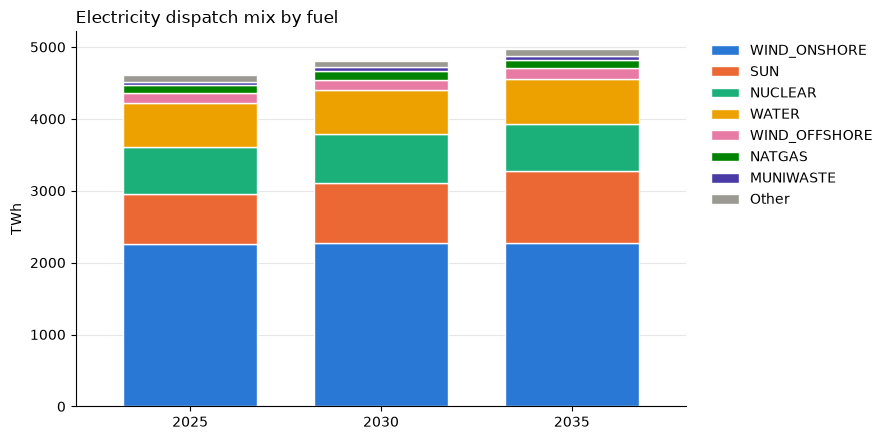

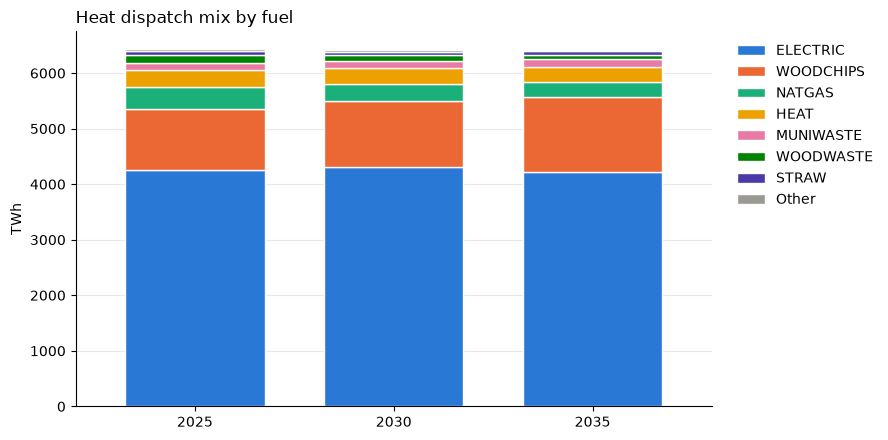

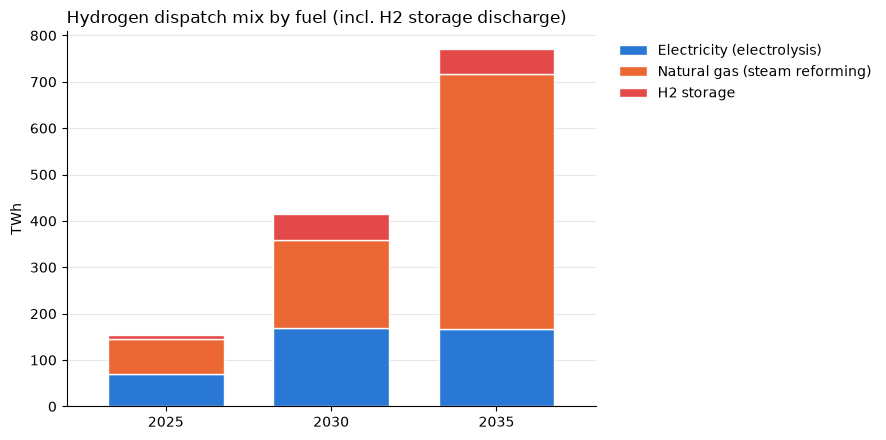

Label,Electricity (electrolysis),H2 storage,Natural gas (steam reforming)
Year,,,
2025,70.74,8.82,74.20
2030,169.22,56.31,188.85
2035,166.14,52.79,551.38


In [37]:
# 4.1 Annual production by fuel (TWh) for each commodity
pro = get("PRO_YCRAGF")
for commodity in ["ELECTRICITY", "HEAT"]:
    table = pro[pro["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} dispatch mix by fuel", "TWh")
    plt.tight_layout(); plt.show()

# Hydrogen dispatch, labelled by input fuel as in 3.1 (h2_label, h2_colors); H2 storage discharge is its own segment.
h2_pro = pro[pro["Commodity"] == "HYDROGEN"]
h2_pro_table = (h2_pro.assign(Label=h2_label(h2_pro))
                      .groupby(["Year", "Label"])["Value"].sum().unstack("Label").fillna(0))
h2_pro_colors = {**h2_colors, **{l: c for l, c in zip([l for l in h2_pro_table.columns if l not in h2_colors], PALETTE[2:])}}
stacked_bar(h2_pro_table, h2_pro_colors, "Hydrogen dispatch mix by fuel (incl. H2 storage discharge)", "TWh")
plt.tight_layout(); plt.show()
display(h2_pro_table.round(2))


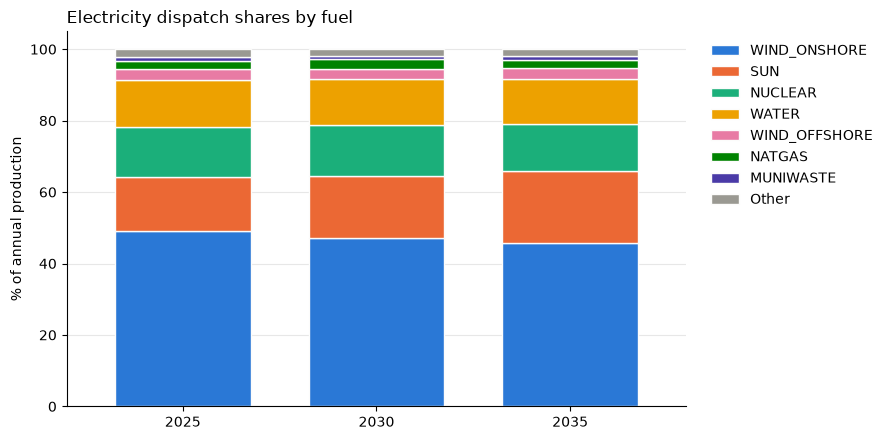

In [38]:
# 4.2 Electricity dispatch shares by fuel (% of annual electricity production)
el = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(el.div(el.sum(axis=1), axis=0) * 100, "Electricity dispatch shares by fuel", "% of annual production")
plt.tight_layout(); plt.show()

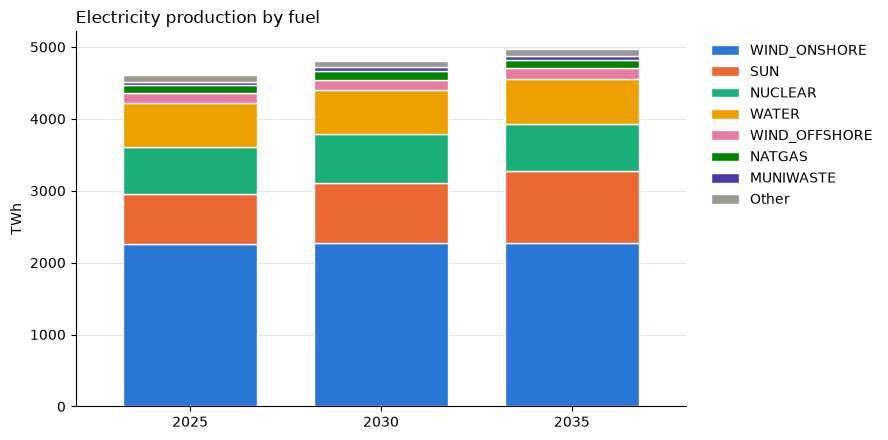

In [39]:
# 4.3 Electricity production by fuel (TWh): the 7 largest fuels, the rest summed as "Other"
fuel = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel, "Electricity production by fuel", "TWh")
plt.tight_layout(); plt.show()

Found MainResults in /work3/s243704/Balmorel/Flex_1_1h/model/MainResults.gdx


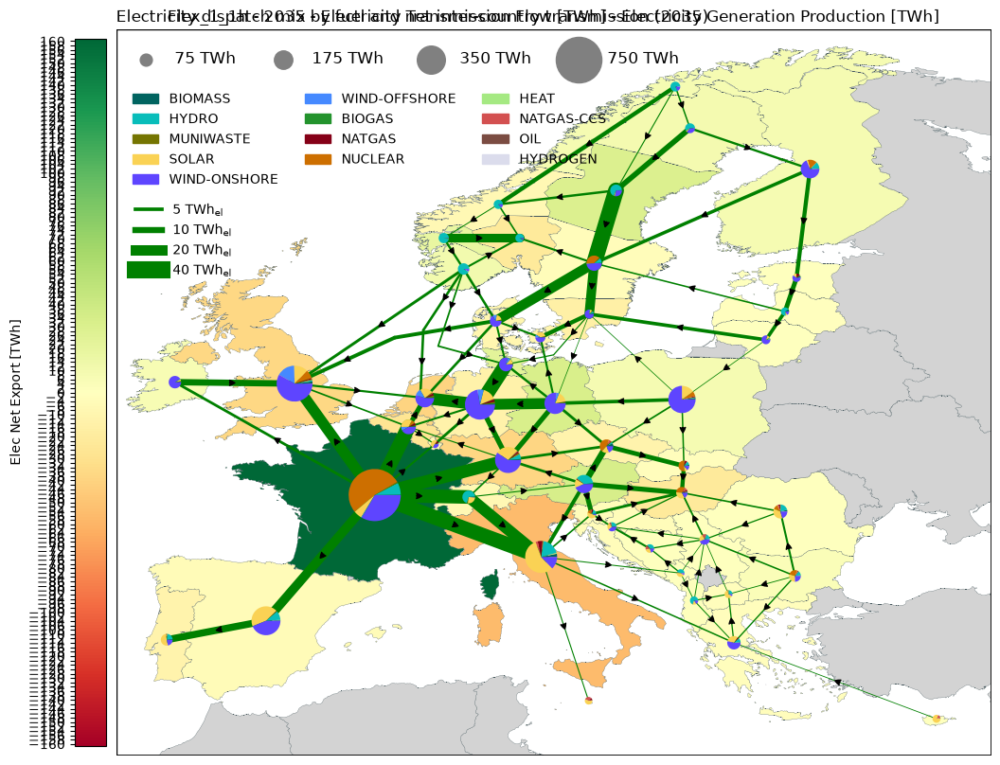

In [40]:
# 4.4 Electricity dispatch mix by fuel per country and net inter-country transmission
# FlowYear shows the annual net flow on each electricity transmission line.
# Compatibility for pybalmorel 1.2.3 with Matplotlib versions where cm.get_cmap was removed.
if not hasattr(plt.cm, "get_cmap"):
    plt.cm.get_cmap = plt.colormaps.get_cmap
MAP_YEAR = int(max(pro["Year"]))
fig, ax = res.plot_map(
    scenario=SCENARIO,
    year=MAP_YEAR,
    commodity="Electricity",
    lines="FlowYear",
    generation="Production",
    generation_var="FFF",
    background="Elec Net Export",
)
ax.set_title(f"Electricity dispatch mix by fuel and net inter-country transmission ({MAP_YEAR})", loc="left")
plt.show()

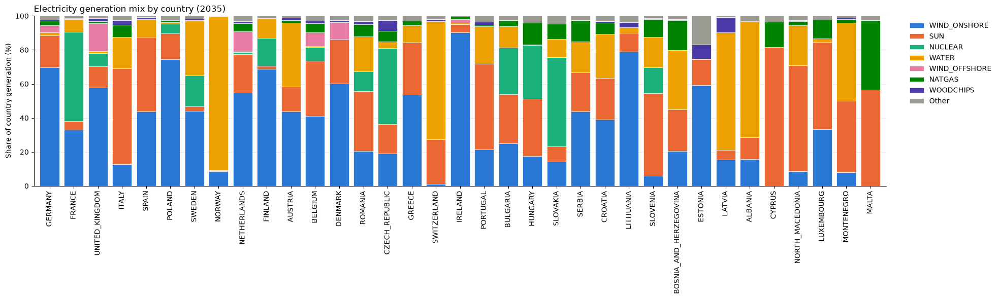

In [41]:
# 4.5 Electricity generation mix by country in the last solved year
# Regions belonging to the same country are aggregated before calculating the mix.
COUNTRY_MIX_YEAR = pro["Year"].max()
country_el = pro[(pro["Year"] == COUNTRY_MIX_YEAR) & (pro["Commodity"] == "ELECTRICITY")].copy()
country_mix = country_el.groupby(["Country", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
country_mix = country_mix.loc[country_mix.sum(axis=1).sort_values(ascending=False).index]
country_mix = country_mix.loc[:, country_mix.sum().sort_values(ascending=False).index]
country_mix = country_mix.iloc[:, :7].assign(Other=country_mix.iloc[:, 7:].sum(axis=1))
country_mix_pct = country_mix.div(country_mix.sum(axis=1), axis=0).mul(100)
fuel_colors = dict(zip(country_mix_pct.columns, PALETTE[:7] + [GREY]))
ax = country_mix_pct.plot.bar(stacked=True, figsize=(max(12, 0.45 * len(country_mix_pct) + 4), 6), color=[fuel_colors[c] for c in country_mix_pct.columns], width=0.8, edgecolor="#fcfcfb", linewidth=0.5)
ax.set_title(f"Electricity generation mix by country ({COUNTRY_MIX_YEAR})", loc="left")
ax.set_ylabel("Share of country generation (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Curtailment
`CURT_YCRAGF` gives the curtailed energy per generator (TWh). Onshore wind, offshore wind and solar values are positive curtailment.
Hydro-reservoir rows contain entries of both signs that net to about zero (reservoir balancing), so they do not add curtailment.

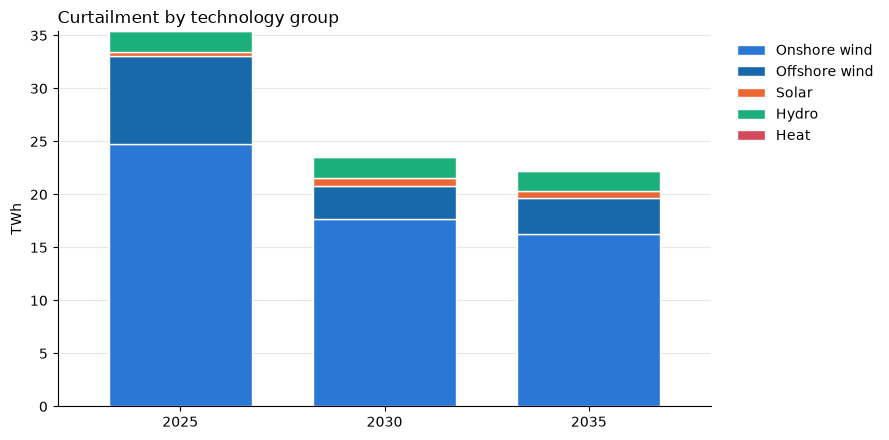

In [42]:
# 5.1 Curtailed energy by technology group (TWh)
curt = get("CURT_YCRAGF")
table = curt.assign(Group=tech_group(curt)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(table, GROUP_COLORS, "Curtailment by technology group", "TWh")
plt.tight_layout(); plt.show()


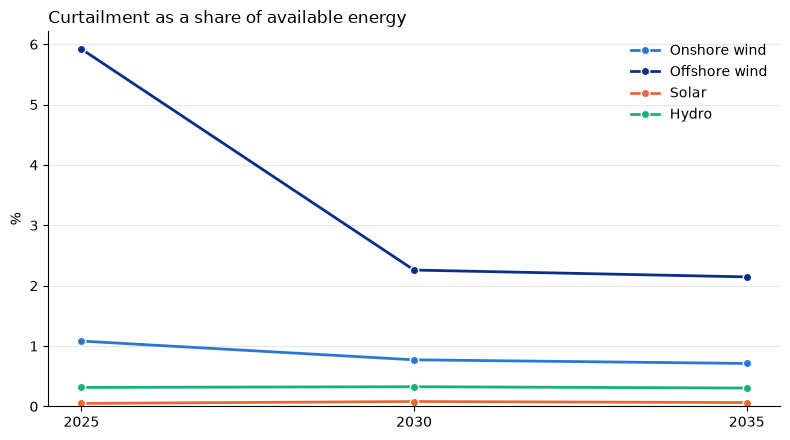

In [43]:
# 5.2 Curtailment as a share of the available energy (dispatched + curtailed), per technology group
prod_g = pro.assign(Group=tech_group(pro)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
share = table / (prod_g.reindex_like(table).fillna(0) + table) * 100      # `table` = curtailment by group from 5.1

fig, ax = plt.subplots(figsize=(8, 4.5))
LINE_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#0b2e8a"}               # distinct colours (the GROUP_COLORS winds are near-identical)
for g in ["Onshore wind", "Offshore wind", "Solar", "Hydro"]:
    series = share.get(g)
    if series is not None:
        ax.plot(series.index, series, marker="o", markersize=6, linewidth=2, color=LINE_COLORS.get(g, GROUP_COLORS.get(g)),
                markeredgecolor="#fcfcfb", label=g)
ax.set_title("Curtailment as a share of available energy", loc="left"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.set_ylim(bottom=0); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

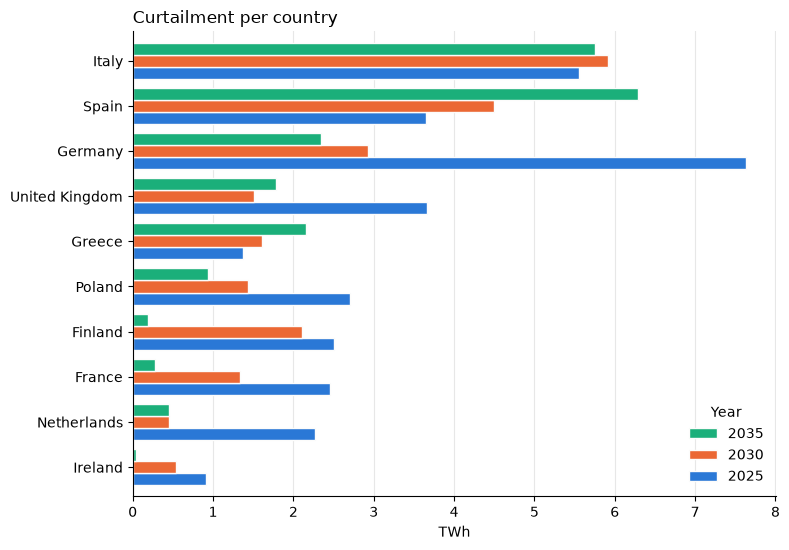

In [44]:
# 5.3 Curtailment per country (TWh): the 10 largest countries
country_bars(curt.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Curtailment per country", "TWh")
plt.tight_layout(); plt.show()

## 6. Total costs
`OBJ_YCR` holds the objective-function cost terms per year and region (Mmoney, the currency of the input data).
Cost terms are folded into five groups.

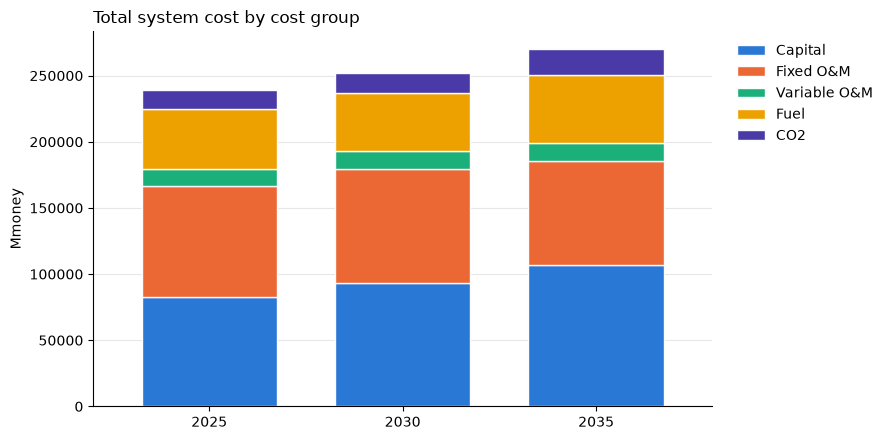

In [45]:
# 6.1 Total system cost per year and cost group (Mmoney)
obj = get("OBJ_YCR")
COST_GROUP = {
    "GENERATION_CAPITAL_COSTS": "Capital", "TRANSMISSION_CAPITAL_COSTS": "Capital", "H2_TRANSMISSION_CAPITAL_COSTS": "Capital",
    "GENERATION_FIXED_COSTS": "Fixed O&M",
    "GENERATION_OPERATIONAL_COSTS": "Variable O&M", "TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "GENERATION_FUEL_COSTS": "Fuel",
    "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2",
}
COST_COLORS = {"Capital": "#2a78d6", "Fixed O&M": "#eb6834", "Variable O&M": "#1baf7a", "Fuel": "#eda100", "CO2": "#4a3aa7"}

costs = obj.assign(Group=obj["Category"].map(COST_GROUP).fillna("Other")) \
           .groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(costs, COST_COLORS, "Total system cost by cost group", "Mmoney")
plt.tight_layout(); plt.show()


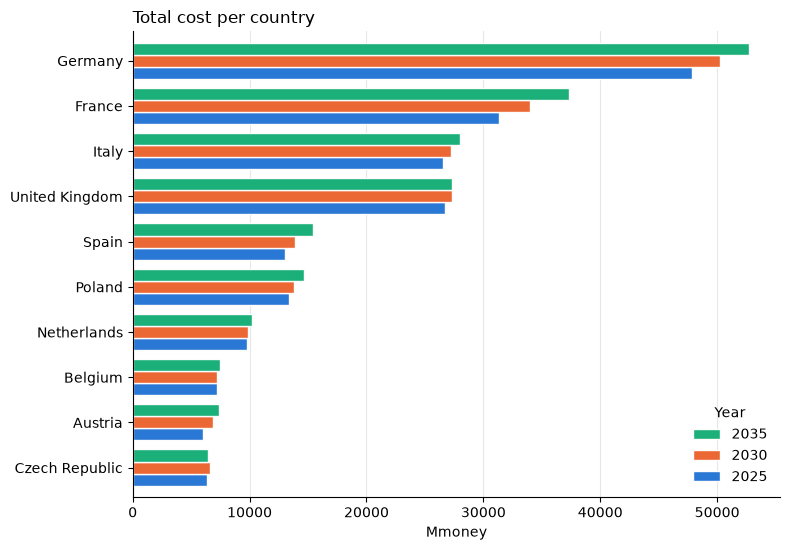

In [46]:
# 6.2 Total cost per country (Mmoney): the 10 largest countries
country_bars(obj.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Total cost per country", "Mmoney")
plt.tight_layout(); plt.show()

### 6.3 Levelised cost of energy per country
Total annual cost of a country's energy system (`OBJ_YCR`, Mmoney) divided by the energy (TWh), giving Money/MWh. The capital costs in `OBJ_YCR` are already annualised, so this is the levelised (average) cost of the energy of the country, not the LCOE of a single technology. The table has two blocks:

**Per produced MWh** (each carrier with its own costs only): the costs of the units producing a carrier divided by that carrier's production (`PRO_YCRAGF`).
- Generator costs (`ECO_G_YCRAG`) go to the carrier each generator produces. Units with more than one output (CHP, electrolysers with heat recovery) are split in proportion to their output in MWh. Each cost type is scaled per country and year so the costs add up to `OBJ_YCR` (the fuel costs in `ECO_G_YCRAG` differ slightly from `OBJ_YCR`).
- Transmission costs go to their carrier (electricity, heat or H2 transmission).
- Storage discharge is not counted as production, since the energy was already produced once. Storage costs stay with their carrier.
- Electricity bought by heat pumps, electric boilers and electrolysers is not a cost term in the objective, so heat and hydrogen are cheap here, and "All energy" counts converted electricity twice (once as electricity, once as heat or H2).

**Per final MWh** (each carrier as a final commodity): the carriers used to make other carriers (`F_CONS_YCRA`: electricity for heat and hydrogen, plus small amounts of heat into CHP and H2 into fuel cells) are moved to the carrier they end up in, both the energy (MWh) and its cost:
- The cost per MWh of each carrier includes the carriers used to make it, $c_k P_k = C_k + \sum_j F_{jk}\, c_j$ (solved per country and year, so chains such as electricity → H2 → electricity are included).
- Final use = production minus the amount used to make carriers; final cost = final use × $c_k$. The final costs add up to the same total as the produced costs, so the "All energy" column counts each MWh once.
- The final electricity LCOE equals the produced one when no other carrier is used to make electricity, because the electricity moved to heat and H2 is taken out at the average electricity cost.
- A country that uses more electricity for heat and H2 than it produces (it imports the rest) has no final electricity use and shows "–". Carriers used but not produced in a country are valued at the all-country cost.

Caveats: production and costs are those inside the country, so imports and exports are not taken into account otherwise. The calculation is the function `lcoe_by(zone)`, used per country here and per region in 6.4. `lcoe` (Money/MWh) and `lcoe_detail` (costs, production, energy used to make carriers and final use per carrier) hold every solved year and an "All countries" row.

In [47]:
# 6.3 Levelised cost of energy per country (Money/MWh = Mmoney/TWh): per produced commodity and per final commodity
LCOE_YEAR = "2035"                                           # year of all LCOE tables and maps (6.3, 6.4, 11.5); lcoe and lcoe_detail keep all solved years
if LCOE_YEAR not in set(pro["Year"].astype(str)):
    raise ValueError(f"LCOE_YEAR = {LCOE_YEAR} is not a solved year of {SCENARIO} (solved: {sorted(pro['Year'].astype(str).unique())})")
# Names start with LCOE_ so that later sections (e.g. 1.5, which defines its own CARRIERS) cannot overwrite them
LCOE_GEN_KEYS = ["Year", "Country", "Region", "Area", "Generation"]
LCOE_CARRIERS = {"ELECTRICITY": "Electricity", "HEAT": "Heat", "HYDROGEN": "Hydrogen"}
LCOE_CARRIER_NAMES = list(LCOE_CARRIERS.values())
LCOE_FUEL_CARRIER = {"ELECTRIC": "Electricity", "HEAT": "Heat", "HYDROGEN": "Hydrogen"}   # fuels that are themselves model carriers
LCOE_STORAGE_TECH = ["INTRASEASONAL-ELECT-STORAGE", "INTRASEASONAL-HEAT-STORAGE", "INTERSEASONAL-HEAT-STORAGE", "H2-STORAGE"]
LCOE_TRANSMISSION_CARRIER = {"TRANSMISSION_CAPITAL_COSTS": "Electricity", "TRANSMISSION_OPERATIONAL_COSTS": "Electricity",
                        "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Heat",
                        "H2_TRANSMISSION_CAPITAL_COSTS": "Hydrogen", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Hydrogen"}
LCOE_TOTAL_LABEL = {"Country": "All countries", "Region": "All regions"}

_lcoe_inputs, _lcoe_cache = {}, {}                           # per scenario / per (zone, scenario); reset when this cell is rerun
def lcoe_inputs(results, scenario):
    """Inputs of the LCOE calculation for one scenario (cached): production, generator and transmission costs per carrier,
    and the carriers used to make carriers."""
    if scenario in _lcoe_inputs:
        return _lcoe_inputs[scenario]
    def sym(symbol):
        t = results.get_result(symbol).rename(columns=RENAME)
        return t[t["Scenario"] == scenario]
    obj_s = sym("OBJ_YCR")
    pro_s = sym("PRO_YCRAGF")
    pro_s = pro_s.assign(Carrier=pro_s["Commodity"].map(LCOE_CARRIERS))

    # Output share of each generator per carrier (multi-output units such as CHP are split by MWh of output)
    out_g = pro_s.groupby(LCOE_GEN_KEYS + ["Carrier"])["Value"].sum()
    out_share = (out_g / out_g.groupby(level=LCOE_GEN_KEYS).transform("sum").replace(0, np.nan)).rename("Share").reset_index()
    main_carrier = pro_s.groupby(["Technology", "Carrier"])["Value"].sum().unstack(fill_value=0).idxmax(axis=1)   # for units without output

    # Generator costs per carrier (ECO_G_YCRAG) and carriers used to make carriers (F_CONS_YCRA), both split over each unit's outputs
    eco_s = sym("ECO_G_YCRAG").query("Category == 'COSTS'")
    gen_s = eco_s.merge(out_share, on=LCOE_GEN_KEYS, how="left")
    no_out = gen_s["Share"].isna()
    gen_s.loc[no_out, "Carrier"] = gen_s.loc[no_out, "Technology"].map(main_carrier).fillna("Electricity")
    gen_s["Cost"] = gen_s["Value"] * gen_s["Share"].fillna(1)
    trans_s = obj_s[obj_s["Category"].isin(LCOE_TRANSMISSION_CARRIER)]
    trans_s = trans_s.assign(Carrier=trans_s["Category"].map(LCOE_TRANSMISSION_CARRIER), Cost=trans_s["Value"])
    f_in = sym("F_CONS_YCRA").query("Fuel in @LCOE_FUEL_CARRIER and Technology not in @LCOE_STORAGE_TECH").merge(out_share, on=LCOE_GEN_KEYS)
    f_in = f_in.assign(From=f_in["Fuel"].map(LCOE_FUEL_CARRIER), To=f_in["Carrier"], TWh=f_in["Value"] * f_in["Share"])
    _lcoe_inputs[scenario] = dict(obj=obj_s, pro=pro_s, eco=eco_s, gen=gen_s, trans=trans_s, f_in=f_in)
    return _lcoe_inputs[scenario]

def unit_costs(C, P, F, c_outside):
    """Cost per MWh of each carrier including the carriers used to make it: c_k * P_k = C_k + sum_j F[j, k] * c_j.
    Carriers used but not produced in the zone are valued at c_outside (the cost over all zones of that year)."""
    made = P > 1e-9
    b = C[made] + F.loc[~made, made].T @ c_outside[~made]
    return pd.Series(np.linalg.solve(np.diag(P[made]) - F.loc[made, made].T, b), index=P.index[made]).reindex(LCOE_CARRIER_NAMES)

def lcoe_by(zone, results=res, scenario=SCENARIO):
    """LCOE per zone ('Country' or 'Region') and year of one scenario, with a total over all zones per year.
    Returns lcoe (Money/MWh, per produced and per final MWh), lcoe_detail (Mmoney and TWh per carrier) and flows
    (TWh of carrier From used to make carrier To)."""
    if (zone, scenario) in _lcoe_cache:
        return _lcoe_cache[(zone, scenario)]
    total = LCOE_TOTAL_LABEL[zone]
    d = lcoe_inputs(results, scenario)
    def add_total(df):
        levels = [l for l in df.index.names if l != zone]
        tot = pd.concat({total: df.groupby(level=levels).sum()}, names=[zone]).reorder_levels(df.index.names)
        return pd.concat([df, tot])

    # Each generator cost type is scaled per zone and year so the costs add up to OBJ_YCR
    eco_type = d["eco"].groupby(["Year", zone, "Subcategory"])["Value"].sum()
    obj_type = d["obj"].groupby(["Year", zone, "Category"])["Value"].sum().rename_axis(eco_type.index.names)
    factor = (obj_type.reindex(eco_type.index, fill_value=0) / eco_type.replace(0, np.nan)).fillna(1).rename("Factor").reset_index()
    g = d["gen"].merge(factor, on=["Year", zone, "Subcategory"], how="left")
    g["Cost"] *= g["Factor"].fillna(1)

    own = add_total(pd.concat({
        "Cost (Mmoney)": pd.concat([g, d["trans"]]).groupby(["Year", zone, "Carrier"])["Cost"].sum(),
        "Production (TWh)": d["pro"][~d["pro"]["Technology"].isin(LCOE_STORAGE_TECH)].groupby(["Year", zone, "Carrier"])["Value"].sum(),  # storage discharge left out
    }, axis=1).fillna(0))
    flows = add_total(d["f_in"].groupby(["Year", zone, "From", "To"])["TWh"].sum())
    flows_w = flows.unstack("To", fill_value=0)

    final = []
    for year in own.index.unique("Year"):
        c_all = pd.Series(0.0, index=LCOE_CARRIER_NAMES)
        for z in [total] + [z for z in own.loc[year].index.unique(zone) if z != total]:
            o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
            F = flows_w.loc[(year, z)] if (year, z) in flows_w.index.droplevel("From") else pd.DataFrame()
            F = F.reindex(index=LCOE_CARRIER_NAMES, columns=LCOE_CARRIER_NAMES, fill_value=0)
            c = unit_costs(o["Cost (Mmoney)"], o["Production (TWh)"], F, c_all)
            if z == total:
                c_all = c.fillna(0)
            use = o["Production (TWh)"] - F.sum(axis=1)      # final use = production minus what is used to make carriers
            final.append(pd.DataFrame({"Year": year, zone: z, "Carrier": LCOE_CARRIER_NAMES, "Used to make carriers (TWh)": F.sum(axis=1).to_numpy(),
                                       "Final use (TWh)": use.to_numpy(), "Final cost (Mmoney)": (c.fillna(0) * use).to_numpy()}))
    detail = own.join(pd.concat(final).set_index(["Year", zone, "Carrier"]))

    # Per produced MWh (each carrier with its own costs only) and per final MWh (incl. the carriers used to make it, removed where they were made)
    wide = detail.unstack("Carrier", fill_value=0)
    C, P, FC, FU = (wide[q].reindex(columns=LCOE_CARRIER_NAMES, fill_value=0) for q in ["Cost (Mmoney)", "Production (TWh)", "Final cost (Mmoney)", "Final use (TWh)"])
    pos = lambda s: s.where(s > 1e-9)                        # no production / no final use -> no LCOE
    lcoe = pd.concat({
        "Per produced MWh": pd.concat([(C.sum(axis=1) / pos(P.sum(axis=1))).rename("All energy"), C / pos(P)], axis=1),
        "Per final MWh": pd.concat([(FC.sum(axis=1) / pos(FU.sum(axis=1))).rename("All energy"), FC / pos(FU)], axis=1),
    }, axis=1)
    print(f"Check {scenario}, per {zone.lower()}: allocated costs differ from OBJ_YCR by at most "
          f"{(C.drop(total, level=zone).sum(axis=1) - d['obj'].groupby(['Year', zone])['Value'].sum()).abs().max():.3f} Mmoney; "
          f"final costs differ from produced costs by at most {(FC.sum(axis=1) - C.sum(axis=1)).abs().max():.3f} Mmoney")
    _lcoe_cache[(zone, scenario)] = lcoe, detail, flows
    return lcoe, detail, flows

lcoe, lcoe_detail, flows = lcoe_by("Country")

# Main table: LCOE_YEAR, countries ordered by total production (largest first)
order = lcoe_detail.xs(LCOE_YEAR, level="Year")["Production (TWh)"].groupby(level="Country").sum().sort_values(ascending=False).index
table = lcoe.xs(LCOE_YEAR, level="Year").loc[order].rename(index=clean_name)
print(f"Levelised cost of energy per country, {LCOE_YEAR} (Money/MWh)")
display(table.style.format("{:.1f}", na_rep="–").background_gradient(cmap="YlOrRd", axis=0))

# Energy and cost moved between carriers, all countries, LCOE_YEAR
moved = flows.xs((LCOE_YEAR, "All countries"), level=["Year", "Country"]).rename("Energy (TWh)").to_frame()
moved["Cost moved (Mmoney)"] = moved["Energy (TWh)"] * (lcoe_detail.xs((LCOE_YEAR, "All countries"), level=["Year", "Country"])
                                                       .eval("`Final cost (Mmoney)` / `Final use (TWh)`")
                                                       .reindex(moved.index.get_level_values("From")).to_numpy())
print(f"Carriers used to make other carriers, all countries, {LCOE_YEAR}")
display(moved.round(1))

/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact perfor

Check Flex_1_1h, per country: allocated costs differ from OBJ_YCR by at most 0.000 Mmoney; final costs differ from produced costs by at most 0.000 Mmoney
Levelised cost of energy per country, 2035 (Money/MWh)


Carriers used to make other carriers, all countries, 2035


Energy (TWh)  Cost moved (Mmoney)
From        To                                            
Electricity Heat               1290.6              27186.9
            Hydrogen            249.6               5257.0
Heat        Electricity           0.3                  8.8
            Heat                  0.4                 11.9
Hydrogen    Electricity           0.1                  2.5

### 6.4 Levelised cost of energy per region (maps)
The same calculation as 6.3 (`lcoe_by("Region")`), per Balmorel region in `LCOE_YEAR` (2035, set at the top of 6.3). Columns: electricity, heat and hydrogen. Top row: per produced MWh (each carrier with its own costs only). Bottom row: per final MWh (incl. the carriers used to make it). Each carrier has one colour scale shared by both rows, spanning the 2-98 % range of its values so that a few extreme regions do not flatten the colours. Hatched regions have no production (top) or no final use (bottom) of that carrier, e.g. a region that imports more electricity than it produces and uses it for heat. Regions are smaller than countries, so trade between regions matters more here than in 6.3. The "All regions" values can differ by about 0.1 Money/MWh from "All countries" in 6.3, because the fuel costs of `ECO_G_YCRAG` are scaled to `OBJ_YCR` per region instead of per country. `lcoe_region` and `lcoe_detail_region` hold all solved years.

/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact perfor

Check Flex_1_1h, per region: allocated costs differ from OBJ_YCR by at most 0.000 Mmoney; final costs differ from produced costs by at most 0.000 Mmoney


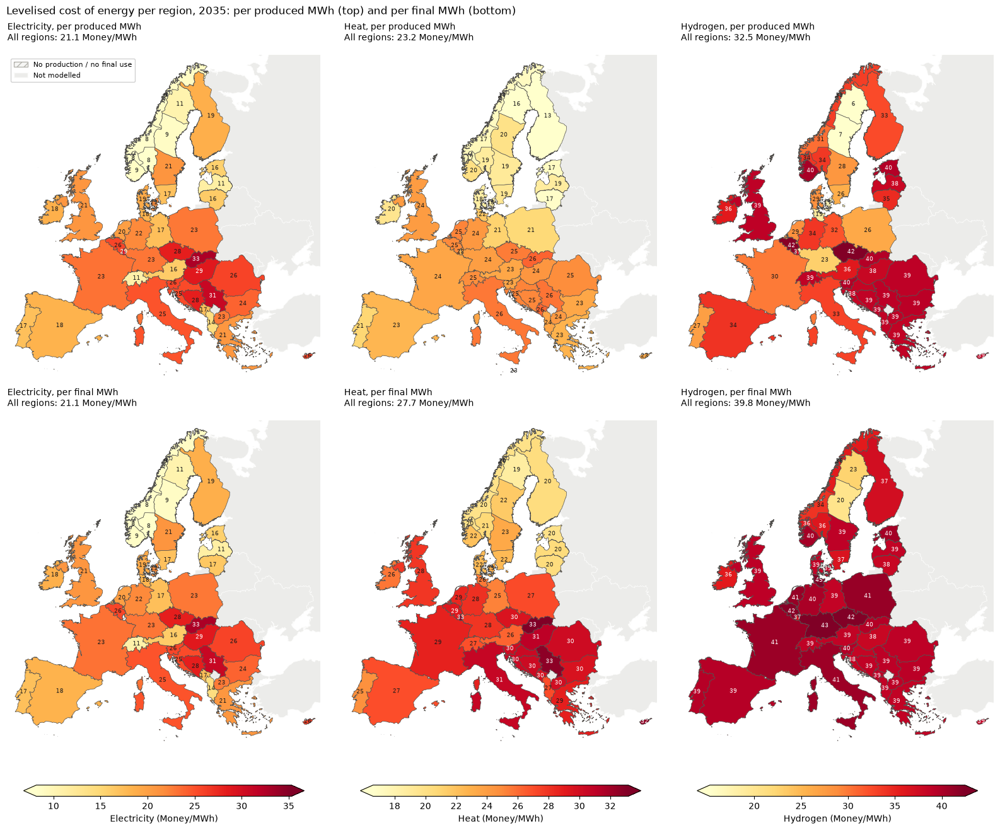

Levelised cost of energy per region, 2035 (Money/MWh)


Per produced MWh                            Per final MWh              \
             All energy Electricity  Heat Hydrogen    All energy Electricity   
Region                                                                         
AL                 19.8        14.2  23.5     38.7          21.9        14.2   
AT                 21.2        16.1  23.4     36.0          23.5        16.1   
BA                 27.4        28.3  25.1     38.8          29.9        28.3   
BE                 25.7        25.7  25.0     42.0          28.7        25.7   
BG                 24.7        24.0  23.5     39.1          28.1        24.0   
CH                 20.3        10.8  24.9     38.8          22.6        10.8   
CY                 25.0        25.7  23.2     38.6          29.8        26.1   
CZ                 26.5        28.3  25.5     42.3          29.3        28.3   
DE4-E              20.3        17.2  21.1     32.0          23.7        17.2   
DE4-N              19.6        18.1  21.6     18.8          22.0        18.1   
DE4-S              23.6        23.0  24.0     22.8          26.8        23.0   
DE4-W              24.0        21.9  24.2     33.8          27.3        21.9   
DK1                21.9        19.1  18.4     28.5          28.4        19.1   
DK2                19.4        21.6  18.3     17.1          28.2        21.6   
EE                 16.7        15.6  17.1     39.5          18.5        15.6   
ES                 21.6        18.3  22.6     34.0          25.0        18.3   
FIN                16.3        18.6  13.3     32.6          20.4        18.6   
FR                 23.8        23.2  23.5     29.8          27.1        23.2   
GR                 23.6        20.9  22.8     38.7          27.1        20.9   
HR                 26.1        25.4  25.2     38.3          29.8        25.4   
HU                 26.0        28.8  24.4     38.2          30.9        28.8   
IE                 19.4        18.5  19.6     35.7          23.0        18.5   
IT                 25.8        24.9  25.6     33.1          29.9        24.9   
LT                 18.8        16.2  16.8     34.5          21.9        16.5   
LU                 24.7        29.4  22.5     37.2          33.4         NaN   
LV                 16.7        11.3  18.8     38.1          18.6        11.3   
ME                 21.7        17.3  26.1     39.0          23.3        17.3   
MK                 25.1        22.7  24.2     39.0          28.0        22.7   
MT                 33.5        44.0  22.5     38.5          38.6        44.0   
NL                 23.6        20.1  25.2     28.5          27.3        20.1   
NO1                14.8         8.1  18.9     33.7          17.1         8.1   
NO2                24.4         8.7  20.1     40.2          25.1         8.7   
NO3                11.7         8.3  17.4     30.5          13.0         8.3   
NO4                10.9         8.7  17.2     33.3          11.7         8.7   
NO5                 9.7         8.2  17.5     33.9          10.1         8.2   
PL                 21.9        22.8  20.6     26.3          26.7        22.8   
PT                 19.9        17.1  20.9     27.2          24.0        17.1   
RO                 26.0        25.8  24.9     38.9          29.7        25.8   
RS                 29.1        31.0  25.7     39.0          32.3        31.0   
SE1                11.5        10.5  15.6      6.4          13.6        10.5   
SE2                11.4         8.7  19.9      7.0          12.3         8.7   
SE3                20.5        21.1  19.1     28.0          23.6        21.1   
SE4                19.2        17.0  19.3     25.9          22.9        17.0   
SI                 24.5        25.7  23.5     39.7          29.0        25.7   
SK                 29.5        32.8  26.3     39.5          33.8        32.8   
UK                 23.1        20.9  24.1     38.9          25.9        20.9   

                       
        Heat Hydrogen  
Region                 
AL      27.1  

In [48]:
# 6.4 Levelised cost per region in LCOE_YEAR (Money/MWh): per produced MWh (top row) and per final MWh (bottom row)
import geopandas as gpd
import pybalmorel
from matplotlib.colors import Normalize
from matplotlib.patches import Patch

lcoe_region, lcoe_detail_region, flows_region = lcoe_by("Region")
map_t = lcoe_region.xs(LCOE_YEAR, level="Year").drop("All regions")
map_total = lcoe_region.loc[(LCOE_YEAR, "All regions")]

geo_l = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
modelled = geo_l["id"].isin(map_t.index)
not_on_map = map_t.index.difference(geo_l["id"])
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)
minx, miny, maxx, maxy = geo_l.loc[modelled].geometry.apply(mainland).total_bounds
BLOCKS = ["Per produced MWh", "Per final MWh"]

fig, axes = plt.subplots(2, 3, figsize=(16, 13), layout="constrained")
for j, carrier in enumerate(LCOE_CARRIER_NAMES):
    values = map_t[[(b, carrier) for b in BLOCKS]].stack().dropna()
    # One colour scale per carrier, shared by both rows; the 2-98 % range keeps a few extreme regions from flattening the colours
    norm = Normalize(*np.nanpercentile(values, [2, 98])) if len(values) else Normalize(0, 1)
    for i, block in enumerate(BLOCKS):
        ax = axes[i, j]
        g = geo_l[modelled].assign(Value=lambda d: d["id"].map(map_t[(block, carrier)]))
        geo_l[~modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)              # outside the model
        if g["Value"].isna().any():
            g[g["Value"].isna()].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5, hatch="///")   # no production / final use
        if g["Value"].notna().any():
            g[g["Value"].notna()].plot(ax=ax, column="Value", cmap="YlOrRd", norm=norm, edgecolor="#52514e", linewidth=0.5)
        for _, row in g[g["Value"].notna()].iterrows():
            p = mainland(row.geometry).representative_point()
            ax.annotate(f"{row['Value']:.0f}", (p.x, p.y), ha="center", va="center", fontsize=6.5,
                        color="white" if norm(row["Value"]) > 0.75 else "#1a1a1a")
        ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
        ax.set_axis_off()
        ax.set_title(f"{carrier}, {block[0].lower() + block[1:]}\nAll regions: {map_total[(block, carrier)]:.1f} Money/MWh", loc="left", fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm), ax=axes[:, j], orientation="horizontal", shrink=0.85,
                 aspect=25, extend="both", label=f"{carrier} (Money/MWh)")
axes[0, 0].legend(handles=[Patch(facecolor="#f6f6f4", edgecolor="#b5b4ae", hatch="///", label="No production / no final use"),
                           Patch(facecolor="#ececea", edgecolor="#fcfcfb", label="Not modelled")],
                  loc="upper left", frameon=True, framealpha=0.9, fontsize=8)
fig.suptitle(f"Levelised cost of energy per region, {LCOE_YEAR}: per produced MWh (top) and per final MWh (bottom)", x=0.01, ha="left")
plt.show()
if len(not_on_map):
    print("Regions in the results without a polygon in the geofile (not drawn):", ", ".join(not_on_map))

print(f"Levelised cost of energy per region, {LCOE_YEAR} (Money/MWh)")
display(map_t.sort_index().round(1))

## 7. Total CO2 emissions
`EMI_YCRAG` holds annual CO2 emissions per generator (kton).

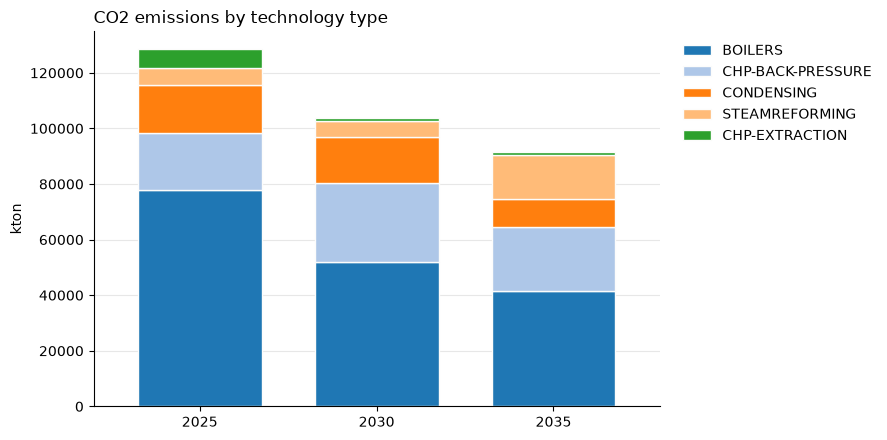

In [49]:
# 7.1 Total CO2 emissions per year by technology type (kton)
emi = get("EMI_YCRAG")
table = emi.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
table = table.loc[:, table.sum(axis=0).sort_values(ascending=False).index]
emission_colors = {technology: plt.cm.tab20(i % 20) for i, technology in enumerate(table.columns)}
stacked_bar(table, emission_colors, "CO2 emissions by technology type", "kton")
plt.tight_layout(); plt.show()


#### 7.1.1 What the emitting technologies are used for
The emissions of each technology type (`EMI_YCRAG`) split by the commodity they serve: each generator's emissions are allocated to electricity, heat and hydrogen in proportion to its output (`PRO_YCRAGF`), so CHP emissions are shared between power and heat. One panel per solved year; the table gives the same split in kton.

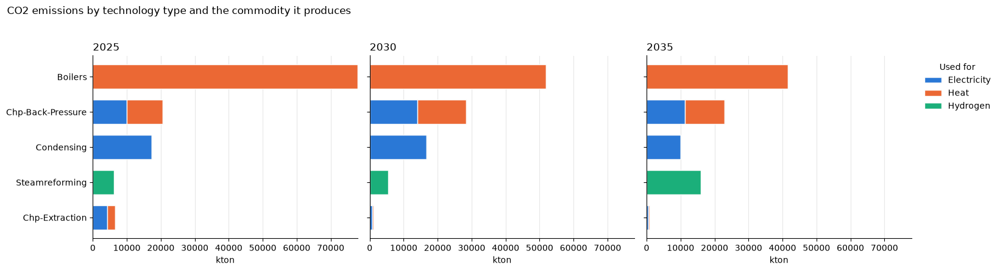

Year                     2025                          2030                    \
Use               Electricity     Heat Hydrogen Electricity     Heat Hydrogen   
Technology                                                                      
Boilers                   0.0  77936.0      0.0         0.0  51819.8      0.0   
Chp-Back-Pressure     10037.5  10459.9      0.0     13962.2  14497.4      0.0   
Condensing            17285.9      0.0      0.0     16770.4      0.0      0.0   
Steamreforming            0.0      0.0   6157.9         0.0      0.0   5448.5   
Chp-Extraction         4223.9   2401.3      0.0       709.8    434.2      0.0   

Year                     2035                    
Use               Electricity     Heat Hydrogen  
Technology                                       
Boilers                   0.0  41665.8      0.0  
Chp-Back-Pressure     11242.4  11667.3      0.0  
Condensing            10100.2      0.0      0.0  
Steamreforming            0.0      0.0  15908.2  
Chp-Extraction          500.0    467.1      0.0

In [50]:
# 7.1.1 CO2 emissions per technology type, split by the commodity it produces (kton)
EMI_KEYS = ["Year", "Region", "Area", "Generation"]
USE_COLORS = {"Electricity": "#2a78d6", "Heat": "#eb6834", "Hydrogen": "#1baf7a", "Other": GREY}

pro_all = get("PRO_YCRAGF").groupby(EMI_KEYS + ["Commodity"])["Value"].sum()
use_share = (pro_all / pro_all.groupby(level=EMI_KEYS).transform("sum").replace(0, np.nan)).rename("Share").reset_index()
emi_use = emi.merge(use_share, on=EMI_KEYS, how="left")
emi_use["Use"] = emi_use["Commodity"].fillna("OTHER").str.title()           # generators without output -> Other
emi_use["Value"] = emi_use["Value"] * emi_use["Share"].fillna(1)
tech_use = emi_use.groupby(["Year", "Technology", "Use"])["Value"].sum().unstack("Use", fill_value=0)
uses = [u for u in USE_COLORS if u in tech_use.columns]
techs = tech_use.groupby(level="Technology").sum().sum(axis=1).sort_values().index    # largest emitter on top

years = list(tech_use.index.get_level_values("Year").unique())
fig, axes = plt.subplots(1, len(years), figsize=(4.5 * len(years) + 3, 0.5 * len(techs) + 2), sharex=True, sharey=True, squeeze=False)
for ax, year in zip(axes.ravel(), years):
    t = tech_use.xs(year, level="Year").reindex(index=techs, columns=uses, fill_value=0)
    t.plot.barh(stacked=True, ax=ax, color=[USE_COLORS[u] for u in uses], width=0.7, edgecolor="#fcfcfb", linewidth=1, legend=False)
    ax.set_title(str(year), loc="left"); ax.set_xlabel("kton"); ax.set_ylabel("")
    ax.set_yticklabels([clean_name(c) for c in techs])
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
axes.ravel()[-1].legend(*axes.ravel()[0].get_legend_handles_labels(), title="Used for", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("CO2 emissions by technology type and the commodity it produces", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

display(tech_use.reindex(columns=uses).unstack("Year").swaplevel(axis=1).sort_index(axis=1, level=0)
        .reindex(techs[::-1]).rename(index=clean_name).round(1))


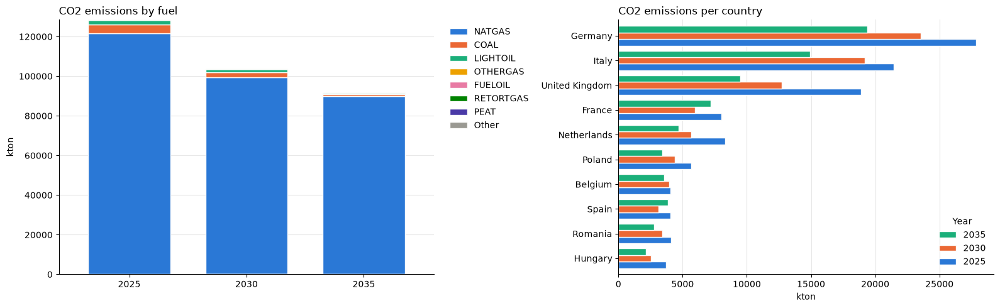

In [51]:
# 7.2 CO2 emissions by fuel (kton) and per country (kton)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fuel_e = emi.groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel_e, "CO2 emissions by fuel", "kton", ax=axes[0])
country_bars(emi.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "CO2 emissions per country", "kton", ax=axes[1])
plt.tight_layout(); plt.show()

## 8. Summary across the topics
The main metrics of sections 2 - 7 per solved year (8.1) and their development over the years (8.2).

In [52]:
# 8.1 Summary across the topics, per solved year
cap, pro = get("G_CAP_YCRAF"), get("PRO_YCRAGF")             # capacity and production tables of this scenario
# Curtailment rate = curtailed / (dispatched + curtailed) onshore wind, offshore wind and solar electricity (%). Hydro-reservoir rows of CURT_YCRAGF
# net to about zero (see section 5) and are left out.
VRE_CURT_TECH = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]
vre = "Technology in @VRE_CURT_TECH and Commodity == 'ELECTRICITY'"
vre_curt = curt.query(vre).groupby("Year")["Value"].sum()
vre_pro = pro.query(vre).groupby("Year")["Value"].sum()
vre_curt_rate = vre_curt / vre_curt.add(vre_pro, fill_value=0).replace(0, np.nan) * 100

summary = pd.DataFrame({
    "Electricity demand (TWh)": summary_demand["Electricity"],
    "Heat demand (TWh)": summary_demand["Heat"],
    "Hydrogen demand (TWh)": summary_demand["Hydrogen"],
    "EV charging (TWh)": summary_demand["EV charging (part of electricity)"],      # annual EV charging from 2.1 (the same series as `ev`)
    "Electricity capacity (GW)": cap[cap["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Electricity dispatched (TWh)": pro[pro["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Curtailment (% of onshore wind, offshore wind & solar available)": vre_curt_rate,
    "Total cost (Mmoney)": obj.groupby("Year")["Value"].sum(),
    "CO2 emissions (kton)": emi.groupby("Year")["Value"].sum(),
}).round(1)
summary["Curtailment (% of onshore wind, offshore wind & solar available)"] = vre_curt_rate.round(2)      # small shares: keep two decimals


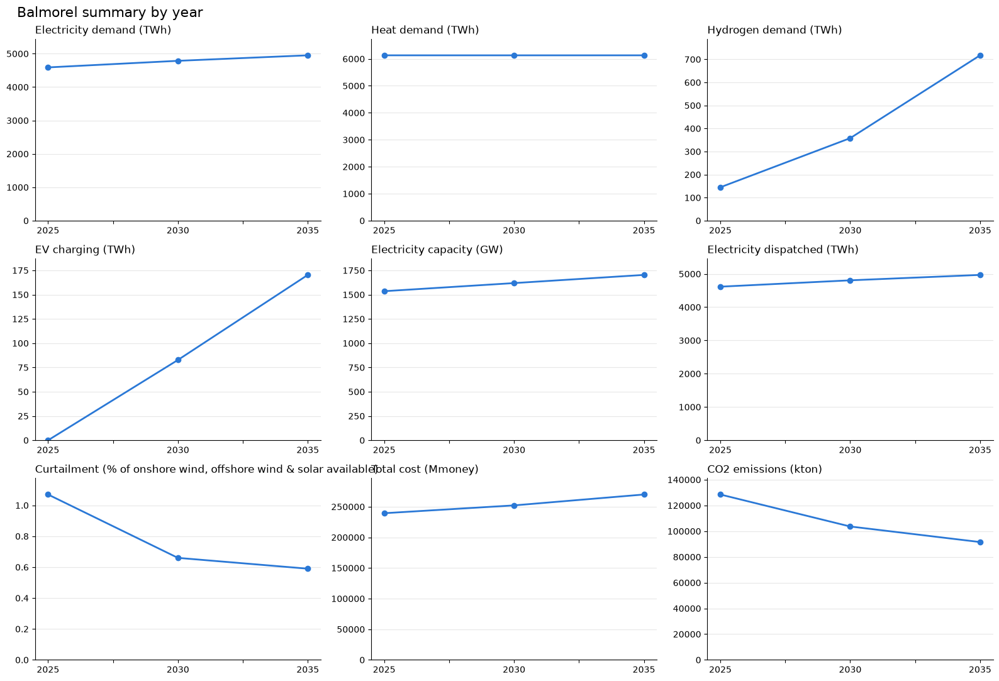

In [53]:
# 8.2 Plot the summary metrics by year
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()

for ax, column in zip(axes, summary.columns):
    summary[column].plot(
        ax=ax,
        marker="o",
        linewidth=2,
        color="#2a78d6"
    )
    ax.set_ylim(0, summary[column].max() * 1.1)
    ax.ticklabel_format(style="plain", axis="y")
    ax.set_title(column, loc="left")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

for ax in axes[len(summary.columns):]:
    ax.remove()

plt.suptitle("Balmorel summary by year", fontsize=16, x=0.02, ha="left")
plt.tight_layout()
plt.show()

## 9. Comparison with the base scenario

This part compares the scenario containing this notebook with the base scenario named by `BASE_SCENARIO` in 0.1 for every common solved year. The notebook can be copied into another scenario folder without changing these paths.

| Section | Content |
|---|---|
| 9 | Summary of the changes and helpers for the comparison charts |
| 10 System level | 10.1 capacity (10.1.1 storage capacity and flexible demand), 10.2 dispatch (with the response of the flexible demands, heat and hydrogen, curtailment, the `FOCUS_YEAR` mix and the hour-by-hour balance), 10.3 total system cost, 10.4 CO2 emissions |
| 11 Country level | 11.1 capacity, 11.2 dispatch (11.2.1 heat and hydrogen, 11.2.2 all energy together), 11.3 CO2 emissions, 11.4 total system cost and marginal electricity cost |
| 12 Bottlenecks | shadow prices of the full model, scenario vs base |

### 9.1 Summary of the changes per year

Comparing Flex_1_1h with the base scenario base_dc


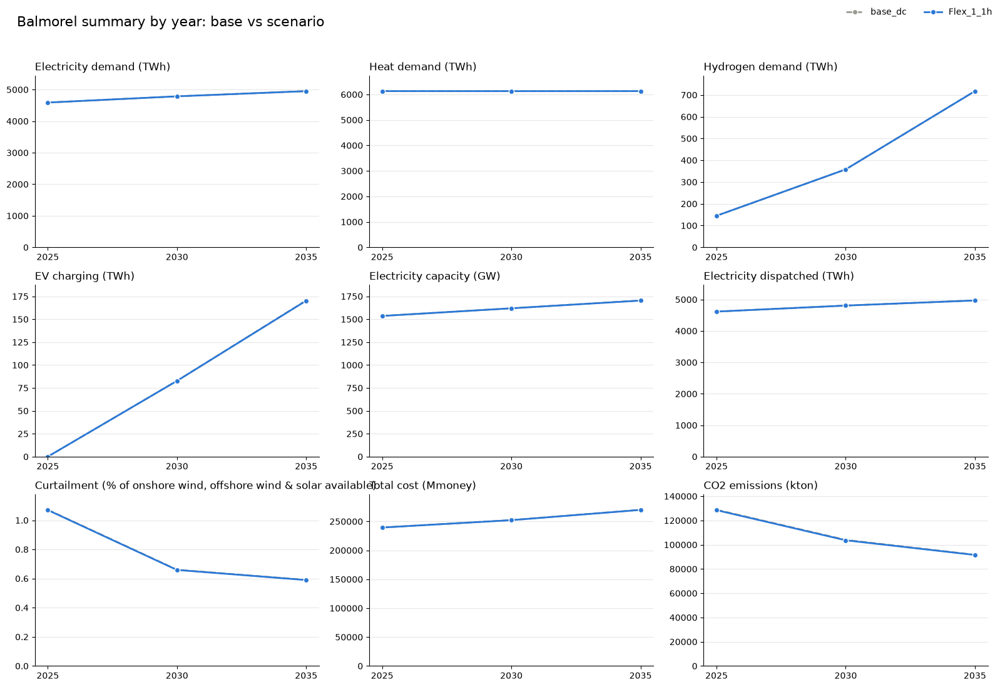

,Year,Metric,Base,Scenario,Change,Change (%)
0,2025,Total cost (Mmoney),239524.92,239441.88,-83.04,-0.03
1,2030,Total cost (Mmoney),252325.59,252206.76,-118.83,-0.05
2,2035,Total cost (Mmoney),270177.59,269967.68,-209.92,-0.08
3,2025,Electricity demand (TWh),4589.57,4589.19,-0.37,-0.01
4,2030,Electricity demand (TWh),4786.35,4786.32,-0.03,-0.00
5,2035,Electricity demand (TWh),4951.50,4951.04,-0.46,-0.01
6,2025,Transmission expansion (GW),0.00,0.00,0.00,NaN
7,2030,Transmission expansion (GW),0.00,0.00,0.00,NaN
8,2035,Transmission expansion (GW),0.00,0.00,0.00,NaN
9,2025,CO2 emissions (kton),128815.37,128502.29,-313.08,-0.24


base_dc: 4 seasons x 168 time steps, 8760 h represented per year
Flex_1_1h: 4 seasons x 168 time steps, 8760 h represented per year
Weighted seasonal sum / annual EL_DEMAND_YCR (should be close to 1):


Scenario,base_dc,Flex_1_1h
Year,,
2025,1.0058,1.0057
2030,1.0043,1.0042
2035,1.0037,1.0037


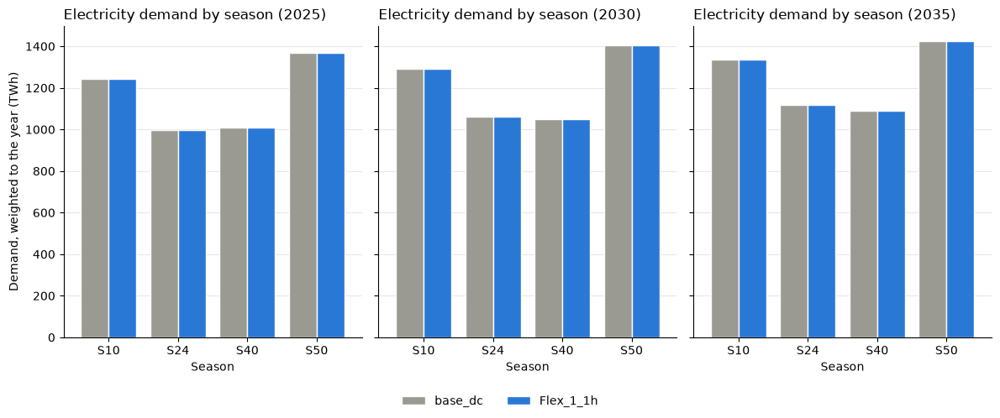

Electricity generation mix: percentage-point change (scenario minus base)


Fuel,BIOGAS,COAL,DUMMY,ELECTRIC,FUELOIL,HEAT,HYDROGEN,LIGHTOIL,MUNIWASTE,NATGAS,...,STRAW,SUN,WASTEHEAT,WATER,WIND_OFFSHORE,WIND_ONSHORE,WOOD,WOODCHIPS,WOODPELLETS,WOODWASTE
Year,,,,,,,,,,,,,,,,,,,,,
2025,-0.0,-0.0,0.0,-0.01,0.0,0.0,0.0,-0.0,0.0,-0.01,...,0.0,0.01,0.0,0.0,0.00,0.0,-0.0,0.0,0.0,-0.0
2030,0.0,0.0,0.0,-0.01,0.0,0.0,-0.0,0.0,0.0,-0.02,...,-0.0,0.05,0.0,0.0,0.00,-0.0,-0.0,0.0,0.0,-0.0
2035,0.0,0.0,0.0,-0.01,-0.0,0.0,0.0,0.0,-0.0,-0.03,...,-0.0,0.07,0.0,0.0,-0.04,0.0,-0.0,0.0,0.0,-0.0


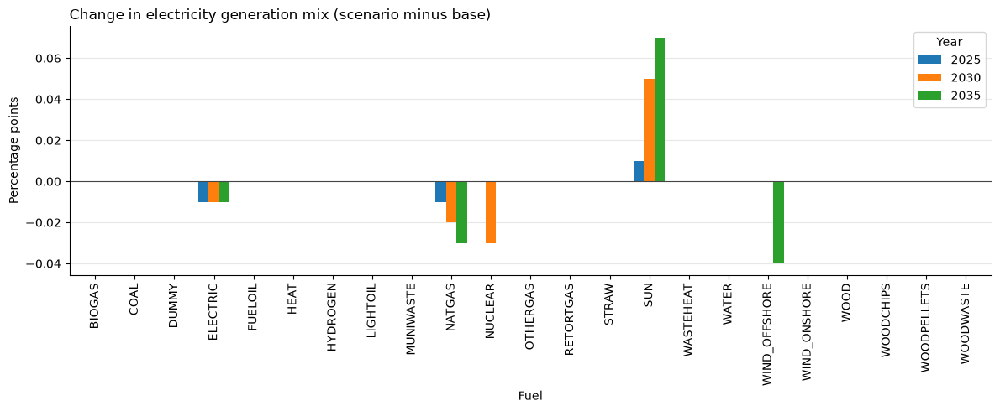

Electricity capacity mix: percentage-point change (scenario minus base)


Fuel,BIOGAS,BIOOIL,COAL,DUMMY,ELECTRIC,FUELOIL,HEAT,HYDROGEN,LIGHTOIL,LIGNITE,...,STRAW,SUN,WASTEHEAT,WATER,WIND_OFFSHORE,WIND_ONSHORE,WOOD,WOODCHIPS,WOODPELLETS,WOODWASTE
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.0,0.0,-0.01,0.0,0.0,0.00,0.0,0.0,-0.0,0.0,...,0.0,0.03,0.0,0.01,0.00,0.02,0.00,0.0,0.0,0.0
2030,-0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.0,0.10,0.0,0.00,0.00,0.00,0.00,0.0,0.0,-0.0
2035,0.0,0.0,0.00,0.0,0.0,-0.07,0.0,0.0,0.0,0.0,...,0.0,0.16,0.0,0.01,-0.02,0.03,-0.01,0.0,0.0,-0.0


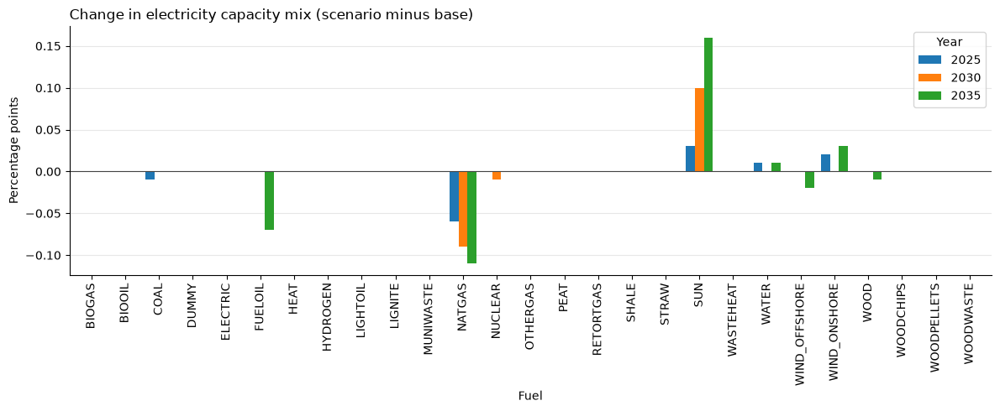

In [54]:
# 9.1 Summary comparison and changes in electricity generation/capacity mix
print(f"Comparing {SCENARIO} with the base scenario {BASE_SCENARIO}")

def scenario_result(results, scenario, symbol):
    table = results.get_result(symbol).rename(columns=RENAME)
    return split_wind_fuel(table.loc[table["Scenario"].eq(scenario)].copy())

def solved_years(results, scenario, symbol="OBJ_YCR"):
    years = scenario_result(results, scenario, symbol)["Year"].astype(str)
    return sorted(years.drop_duplicates(), key=int)

COMPARISON_YEARS = sorted(set(solved_years(res, SCENARIO)).intersection(solved_years(base_res, BASE_SCENARIO)), key=int)
if not COMPARISON_YEARS:
    raise ValueError("No common solved years found for the scenario comparison")

def curtailment_rate(results, scenario):
    """Onshore wind, offshore wind and solar curtailment per comparison year (% of available energy = dispatched + curtailed), as in 6.3."""
    def vre(symbol):
        t = scenario_result(results, scenario, symbol)
        t = t.loc[t["Technology"].isin(VRE_CURT_TECH) & t["Commodity"].eq("ELECTRICITY")]
        return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    curtailed = vre("CURT_YCRAGF")
    return curtailed / (curtailed + vre("PRO_YCRAGF")).replace(0, np.nan) * 100

def summary_by_year(results, scenario):
    """The metrics of 6.3 for one scenario, per comparison year (annual results, so independent of the time resolution)."""
    def total(symbol, query=None):
        t = scenario_result(results, scenario, symbol)
        if query is not None:
            t = t.query(query)
        return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    in_groups = "Category in @DEMAND_GROUP"                     # same demand categories as section 2 / 8.1
    return pd.DataFrame({
        "Electricity demand (TWh)": total("EL_DEMAND_YCR", in_groups),
        "Heat demand (TWh)": total("H_DEMAND_YCRA", in_groups),
        "Hydrogen demand (TWh)": total("H2_DEMAND_YCR", in_groups),
        "EV charging (TWh)": total("EL_DEMAND_YCR", "Category == 'ENDO_EV'"),
        "Electricity capacity (GW)": total("G_CAP_YCRAF", "Commodity == 'ELECTRICITY'"),
        "Electricity dispatched (TWh)": total("PRO_YCRAGF", "Commodity == 'ELECTRICITY'"),
        "Curtailment (% of onshore wind, offshore wind & solar available)": curtailment_rate(results, scenario),
        "Total cost (Mmoney)": total("OBJ_YCR"),
        "CO2 emissions (kton)": total("EMI_YCRAG"),
    })

summary_cmp = {BASE_SCENARIO: summary_by_year(base_res, BASE_SCENARIO), SCENARIO: summary_by_year(res, SCENARIO)}
CMP_STYLE = {BASE_SCENARIO: dict(color="#9a9992", linestyle="--"), SCENARIO: dict(color="#2a78d6", linestyle="-")}

# Balmorel summary by year (as 8.2): base dashed grey, this scenario solid blue
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()
for ax, column in zip(axes, summary_cmp[SCENARIO].columns):
    for name, table in summary_cmp.items():
        ax.plot(table.index, table[column], marker="o", linewidth=2, markeredgecolor="#fcfcfb", label=name, **CMP_STYLE[name])
    top = max(t[column].max() for t in summary_cmp.values())
    ax.set_ylim(0, top * 1.1 if top > 0 else 1)
    ax.ticklabel_format(style="plain", axis="y")
    ax.set_title(column, loc="left"); ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
for ax in axes[len(summary_cmp[SCENARIO].columns):]:
    ax.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
plt.suptitle("Balmorel summary by year: base vs scenario", fontsize=16, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

def yearly_total(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    return (table.assign(Year=table["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0))

def transmission_expansion(results, scenario):
    table = scenario_result(results, scenario, "X_CAP_YCR")
    table = table.loc[table["Category"].eq("ENDOGENOUS")]
    return (table.assign(Year=table["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0))

def fuel_mix(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Commodity"].eq("ELECTRICITY")].copy()
    table["Year"] = table["Year"].astype(str)
    return (table.groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0))

def price_by(results, scenario, by):
    """Demand-weighted average marginal electricity cost (Money/MWh) per year and `by` (None = whole system).
    EL_PRICE_YCR (AVERAGE) is the time-averaged marginal cost of the electricity balance per region; each region is
    weighted by its annual electricity demand (EL_DEMAND_YCR, all categories)."""
    price = scenario_result(results, scenario, "EL_PRICE_YCR")
    price = price.loc[price["Category"].eq("AVERAGE")].assign(Year=lambda d: d["Year"].astype(str))
    dem = scenario_result(results, scenario, "EL_DEMAND_YCR").assign(Year=lambda d: d["Year"].astype(str))
    dem = dem.groupby(["Year", "Region"])["Value"].sum().rename("Demand")
    t = price.set_index(["Year", "Region"]).join(dem, how="left").fillna({"Demand": 0}).reset_index()
    keys = ["Year"] + ([by] if by else [])
    t = t.assign(PxD=t["Value"] * t["Demand"]).groupby(keys)[["PxD", "Demand"]].sum()
    out = t["PxD"] / t["Demand"].replace(0, np.nan)
    return out.reindex(COMPARISON_YEARS) if by is None else out

metrics = {"Total cost (Mmoney)": "OBJ_YCR", "Electricity demand (TWh)": "EL_DEMAND_YCR", "Transmission expansion (GW)": None, "CO2 emissions (kton)": "EMI_YCRAG", "Curtailment (% of onshore wind, offshore wind & solar available)": "CURT_RATE",
           "Electricity marginal cost (Money/MWh, demand-weighted)": "PRICE"}
rows = []
for metric, symbol in metrics.items():
    if symbol is None:
        scenario_values = transmission_expansion(res, SCENARIO)
        base_values = transmission_expansion(base_res, BASE_SCENARIO)
    elif symbol == "CURT_RATE":
        scenario_values = curtailment_rate(res, SCENARIO)
        base_values = curtailment_rate(base_res, BASE_SCENARIO)
    elif symbol == "PRICE":
        scenario_values = price_by(res, SCENARIO, None)
        base_values = price_by(base_res, BASE_SCENARIO, None)
    else:
        scenario_values = yearly_total(res, SCENARIO, symbol)
        base_values = yearly_total(base_res, BASE_SCENARIO, symbol)
    for year in COMPARISON_YEARS:
        base_value = float(base_values.loc[year])
        scenario_value = float(scenario_values.loc[year])
        rows.append({"Year": int(year), "Metric": metric, "Base": base_value, "Scenario": scenario_value, "Change": scenario_value - base_value, "Change (%)": ((scenario_value - base_value) / base_value * 100 if base_value else float("nan"))})

comparison = pd.DataFrame(rows).round(2)
display(comparison)

# Seasonal electricity demand. The runs can have a different time resolution (e.g. 4 seasons x 72 h vs 4 seasons x 168 h),
# and EL_DEMAND_YCRST holds the MWh of one represented hour per slice. Summing the slices therefore scales with the number of
# hours in the run. Each slice is weighted with IHOURSINST (hours of the year it represents, sum = 8760), which gives the
# annual energy per season on the same basis as EL_DEMAND_YCR.
def slice_hours(run_dir):
    """Hours represented by each (Season, Time) slice, read from IHOURSINST in all_endofmodel.gdx (None if unavailable)."""
    try:
        import gams.transfer as gt
        container = gt.Container()
        container.read(str(endofmodel_path(run_dir)), symbols=["IHOURSINST"])
        w = container["IHOURSINST"].records
        return pd.Series(w["value"].to_numpy(), index=pd.MultiIndex.from_arrays(
            [w.iloc[:, 0].astype(str), w.iloc[:, 1].astype(str)], names=["Season", "Time"]), name="Hours")
    except Exception as exc:
        print(f"IHOURSINST not readable in {run_dir} ({exc}); assuming 8760 h spread evenly over the slices")
        return None

def seasonal_electricity_demand(results, scenario, run_dir):
    """Annual electricity demand per year and season (TWh) = sum over slices of MWh x hours represented."""
    table = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    if "Unit" in table.columns:
        table = table.loc[table["Unit"].eq("MWh")]
    table = table.assign(Year=table["Year"].astype(str), Season=table["Season"].astype(str), Time=table["Time"].astype(str))
    slices = table.groupby(["Year", "Season", "Time"])["Value"].sum().reset_index()
    hours = slice_hours(run_dir)
    if hours is None:
        n = slices.groupby("Year")["Time"].transform("size")
        slices["Hours"] = 8760 / n
    else:
        slices = slices.join(hours, on=["Season", "Time"])
        if slices["Hours"].isna().any():
            raise ValueError(f"{scenario}: {slices['Hours'].isna().sum()} demand slices have no IHOURSINST weight")
    resolution = f"{slices['Season'].nunique()} seasons x {slices['Time'].nunique()} time steps"
    print(f"{scenario}: {resolution}, {slices.groupby('Year')['Hours'].sum().iloc[0]:.0f} h represented per year")
    out = (slices.assign(Energy=slices["Value"] * slices["Hours"] / 1e6)
                 .groupby(["Year", "Season"])["Energy"].sum().rename("Demand (TWh)"))
    seasons = sorted(slices["Season"].unique())
    index = pd.MultiIndex.from_product([COMPARISON_YEARS, seasons], names=["Year", "Season"])
    return out.reindex(index, fill_value=0).reset_index()

seasonal_demand = pd.concat([
    seasonal_electricity_demand(base_res, BASE_SCENARIO, BASE_RESULTS_DIR).assign(Scenario=BASE_SCENARIO),
    seasonal_electricity_demand(res, SCENARIO, RUN_DIR).assign(Scenario=SCENARIO),
], ignore_index=True)

# Consistency check: the weighted seasons add up to the annual demand of EL_DEMAND_YCR
check = seasonal_demand.groupby(["Scenario", "Year"])["Demand (TWh)"].sum().unstack("Scenario")[[BASE_SCENARIO, SCENARIO]]
annual_el = pd.DataFrame({BASE_SCENARIO: yearly_total(base_res, BASE_SCENARIO, "EL_DEMAND_YCR"),
                          SCENARIO: yearly_total(res, SCENARIO, "EL_DEMAND_YCR")})
print("Weighted seasonal sum / annual EL_DEMAND_YCR (should be close to 1):")
display((check / annual_el).round(4))

fig, axes = plt.subplots(1, len(COMPARISON_YEARS), figsize=(max(12, 4 * len(COMPARISON_YEARS)), 5), squeeze=False, sharey=True)
for ax, year in zip(axes.ravel(), COMPARISON_YEARS):
    plot_data = seasonal_demand.loc[seasonal_demand["Year"].eq(year)]
    plot_data = plot_data.pivot(index="Season", columns="Scenario", values="Demand (TWh)")[[BASE_SCENARIO, SCENARIO]]
    plot_data.plot.bar(ax=ax, width=0.8, color=[CMP_STYLE[BASE_SCENARIO]["color"], CMP_STYLE[SCENARIO]["color"]], edgecolor="#fcfcfb")
    ax.set_title(f"Electricity demand by season ({year})", loc="left")
    ax.set_ylabel("Demand, weighted to the year (TWh)")
    ax.set_xlabel("Season")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.get_legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
for title, symbol in [("Electricity generation mix", "PRO_YCRAGF"), ("Electricity capacity mix", "G_CAP_YCRAF")]:
    scenario_mix = fuel_mix(res, SCENARIO, symbol)
    base_mix = fuel_mix(base_res, BASE_SCENARIO, symbol)
    fuels = scenario_mix.columns.union(base_mix.columns)
    scenario_mix = scenario_mix.reindex(columns=fuels, fill_value=0)
    base_mix = base_mix.reindex(columns=fuels, fill_value=0)
    scenario_pct = scenario_mix.div(scenario_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    base_pct = base_mix.div(base_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    change_pct = (scenario_pct - base_pct).fillna(0).round(2)
    print(f"{title}: percentage-point change (scenario minus base)")
    display(change_pct)
    ax = change_pct.T.plot.bar(figsize=(max(12, 0.5 * len(COMPARISON_YEARS) + 5), 5), width=0.8)
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set_title(f"Change in {title.lower()} (scenario minus base)", loc="left")
    ax.set_ylabel("Percentage points")
    ax.set_xlabel("Fuel")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

In [55]:
# 9.2 Helpers for the base-vs-scenario charts of sections 10 and 11
VRE_TECH = {"WIND-ON": "Onshore wind", "WIND-OFF": "Offshore wind", "SOLAR-PV": "Solar"}     # curtailment is only meaningful for these
SCEN_COLORS = {BASE_SCENARIO: "#9a9992", SCENARIO: "#2a78d6"}                      # base = grey, this scenario = blue

def by_year(results, scenario, symbol, by, commodity=None):
    """Year x `by` table of Value for the comparison years (optionally one output commodity)."""
    table = scenario_result(results, scenario, symbol)
    if commodity is not None:
        table = table.loc[table["Commodity"].eq(commodity)]
    table = table.assign(Year=table["Year"].astype(str))
    return table.groupby(["Year", by])["Value"].sum().unstack(by, fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

def align(base_t, scen_t, n=7):
    """Same columns in both tables: the n largest (summed over both scenarios) keep their name, the rest is 'Other'."""
    cols = base_t.columns.union(scen_t.columns)
    base_t, scen_t = base_t.reindex(columns=cols, fill_value=0), scen_t.reindex(columns=cols, fill_value=0)
    order = (base_t.abs().sum() + scen_t.abs().sum()).sort_values(ascending=False).index
    keep, rest = list(order[:n]), list(order[n:])
    def fold(t):
        return t[keep].assign(Other=t[rest].sum(axis=1)) if rest else t[keep]
    base_t, scen_t = fold(base_t), fold(scen_t)
    colors = dict(zip(base_t.columns, PALETTE[:len(keep)] + [GREY]))
    return base_t, scen_t, colors

def style(ax, title, ylabel, axis="y"):
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.grid(axis=axis, alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)

def paired_stacked(base_t, scen_t, colors, title, unit):
    """Left: per year a base bar (hatched) next to a scenario bar, stacked by column.
    Right: change per column (scenario - base), one bar per year."""
    years = list(base_t.index)
    x = np.arange(len(years))
    w = 0.38
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(max(14, 1.6 * len(years) + 10), 5), gridspec_kw={"width_ratios": [1.2, 1]})
    for offset, t, hatch in [(-w / 2 - 0.01, base_t, "//"), (w / 2 + 0.01, scen_t, None)]:
        pos, neg = np.zeros(len(years)), np.zeros(len(years))
        for col in t.columns:
            v = t[col].to_numpy(dtype=float)
            bottom = np.where(v >= 0, pos, neg)
            ax.bar(x + offset, v, w, bottom=bottom, color=colors[col], edgecolor="#fcfcfb", linewidth=0.8, hatch=hatch,
                   label=clean_name(col) if hatch is None else None)
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.set_xticks(x); ax.set_xticklabels([f"{y}\nbase | scen." for y in years])
    ax.axhline(0, color="#52514e", linewidth=0.8)
    style(ax, f"{title}: base (hatched) vs {SCENARIO}", unit)
    ax.legend(bbox_to_anchor=(1.0, 1), loc="upper left", frameon=False, fontsize=9)

    diff = scen_t - base_t
    diff.T.plot.bar(ax=ax2, color=year_colors(len(years)), width=0.8, edgecolor="#fcfcfb", linewidth=0.8)
    ax2.set_xticklabels([clean_name(c) for c in diff.columns], rotation=45, ha="right")
    ax2.axhline(0, color="#52514e", linewidth=0.8)
    style(ax2, f"Change: {title} (scenario - base)", unit)
    ax2.legend(title="Year", frameon=False)
    plt.tight_layout(); plt.show()
    return diff

def country_change(base_c, scen_c, title, unit, n=10):
    """Horizontal bars of the change per country (scenario - base) in the last common year, the n largest absolute changes."""
    d = scen_c.sub(base_c, fill_value=0)
    d = d.loc[d.abs().sort_values(ascending=False).head(n).index].iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(d) + 1.5))
    ax.barh([clean_name(c) for c in d.index], d.values, color=np.where(d.values >= 0, "#e34948", "#2a78d6"), height=0.7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    style(ax, title, "", axis="x"); ax.set_xlabel(unit)
    plt.tight_layout(); plt.show()

LAST_YEAR = COMPARISON_YEARS[-1]

def last_year_by_country(results, scenario, symbol, commodity=None, technologies=None):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Year"].astype(str).eq(LAST_YEAR)]
    if commodity is not None:
        table = table.loc[table["Commodity"].eq(commodity)]
    if technologies is not None:
        table = table.loc[table["Technology"].isin(technologies)]
    return table.groupby("Country")["Value"].sum()

def datacenter_demand(folder, year, region_country):
    """Data-center demand (TWh) per country in `year` from the DE_DATACENTER.inc used by a run (its own data folder). `region_country` maps region -> country."""
    path = folder / "data" / "DE_DATACENTER.inc"
    if path.exists():
        text = path.read_text(encoding="utf-8", errors="ignore")
        header = re.search(r"(?m)^\s*((?:20\d{2}\s+){2,}20\d{2})\s*$", text)
        years = header.group(1).split()
        rows = {}
        for line in text[header.end():].splitlines():
            parts = line.split()
            if len(parts) == len(years) + 1 and parts[0] in region_country.index:
                rows[parts[0]] = float(parts[1 + years.index(year)]) if year in years else 0.0
        return pd.Series(rows, dtype=float).groupby(region_country).sum() / 1e6
    return pd.Series(dtype=float)

# Year of the focus charts (10.2.4, 10.4.2, 11.3, 11.4): 2035, or the last common year if 2035 is not solved
FOCUS_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]


## 10. System level: base vs scenario
Totals over all countries, in the order capacity, dispatch, cost and CO2 emissions.

### 10.1 Installed capacity per fuel: base vs scenario
`G_CAP_YCRAF` (GW), installed capacity = exogenous + endogenous + decommissioning, for the commodities in `COMPARE_COMMODITIES`.
The 7 largest fuels (over both scenarios) keep their own colour, the rest is `Other`; colours are the same in both scenarios.

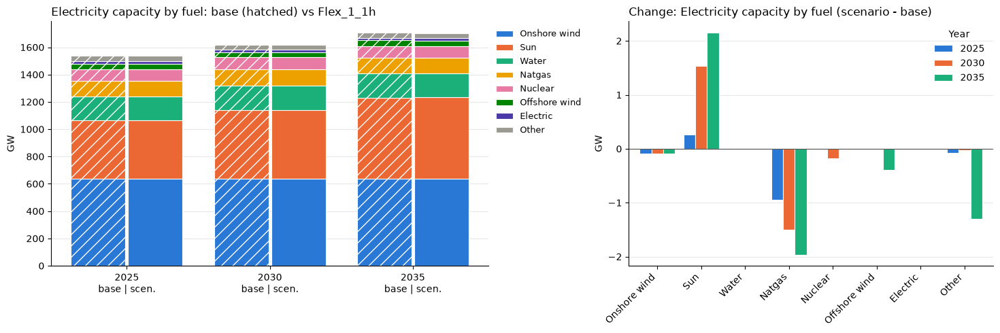

Electricity capacity: change per fuel (GW, scenario - base)


Fuel,WIND_ONSHORE,SUN,WATER,NATGAS,NUCLEAR,WIND_OFFSHORE,ELECTRIC,Other,Total
Year,,,,,,,,,
2025,-0.09,0.26,0.0,-0.95,-0.01,0.00,0.0,-0.08,-0.86
2030,-0.09,1.54,0.0,-1.50,-0.18,0.00,0.0,-0.02,-0.25
2035,-0.09,2.16,0.0,-1.96,0.00,-0.39,0.0,-1.30,-1.58


In [56]:
# 10.1 Installed capacity per fuel (GW)
COMPARE_COMMODITIES = ["ELECTRICITY"]          # add "HEAT" / "HYDROGEN" to compare those capacity mixes as well
for commodity in COMPARE_COMMODITIES:
    base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "G_CAP_YCRAF", "Fuel", commodity),
                                   by_year(res, SCENARIO, "G_CAP_YCRAF", "Fuel", commodity))
    diff = paired_stacked(base_t, scen_t, colors, f"{commodity.title()} capacity by fuel", "GW")
    print(f"{commodity.title()} capacity: change per fuel (GW, scenario - base)")
    display(diff.assign(Total=diff.sum(axis=1)).round(2))

#### 10.1.1 Storage capacity and flexible demand: base vs scenario
How much flexibility the system installs and uses, base (grey) next to scenario (blue) for every comparison year.

**Storage capacity.** `G_STO_YCRAF` gives the storage volume (GWh), which is what Balmorel invests in. `G_CAP_YCRAF` gives the unloading power (GW). For storage, the reported power is the volume divided by the fixed unloading time (`GDSTOHUNLD`) of each technology. A change in power without a change in volume therefore means a shift between storage technologies with different durations, e.g. from H₂ caverns (180 h) to H₂ tanks (0.5 h). Hydro reservoirs are left out because their volume is fixed by the data.

**Flexible demand used.** These are the annual energies of the demands that the model can schedule (`EL_DEMAND_YCR`, `H_DEMAND_YCRA`, `H2_DEMAND_YCR`, `EV_V2G_Y`):
- electricity used for power-to-heat, electrolysis, electricity-storage charging and EV charging, plus EV discharging to the grid (V2G);
- heat and H₂ used to load heat and H₂ storage.

The last two panels show the installed capacity of the flexible conversion technologies: electrolysers (H₂ output) and electric heating (heat pumps and electric boilers, heat output).

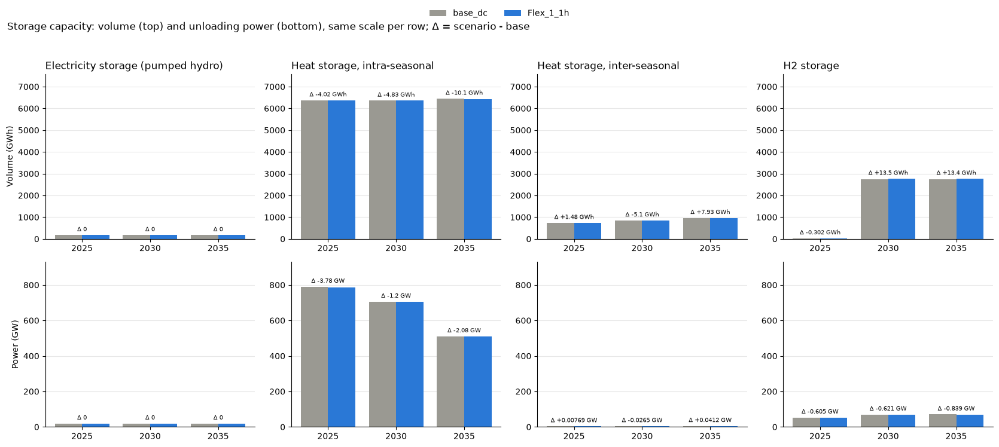

Storage capacity per type: change (scenario - base)


Volume (GWh)                               \
Technology Electricity storage (pumped hydro) Heat storage, intra-seasonal   
Year                                                                         
2025                                      0.0                        -4.02   
2030                                      0.0                        -4.83   
2035                                      0.0                       -10.09   

                                                    \
Technology Heat storage, inter-seasonal H2 storage   
Year                                                 
2025                               1.48      -0.30   
2030                              -5.10      13.54   
2035                               7.93      13.43   

                                   Power (GW)                               \
Technology Electricity storage (pumped hydro) Heat storage, intra-seasonal   
Year                                                                         
2025                                      0.0                        -3.78   
2030                                      0.0                        -1.20   
2035                                      0.0                        -2.08   

                                                    
Technology Heat storage, inter-seasonal H2 storage  
Year                                                
2025                               0.01      -0.60  
2030                              -0.03      -0.62  
2035                               0.04      -0.84

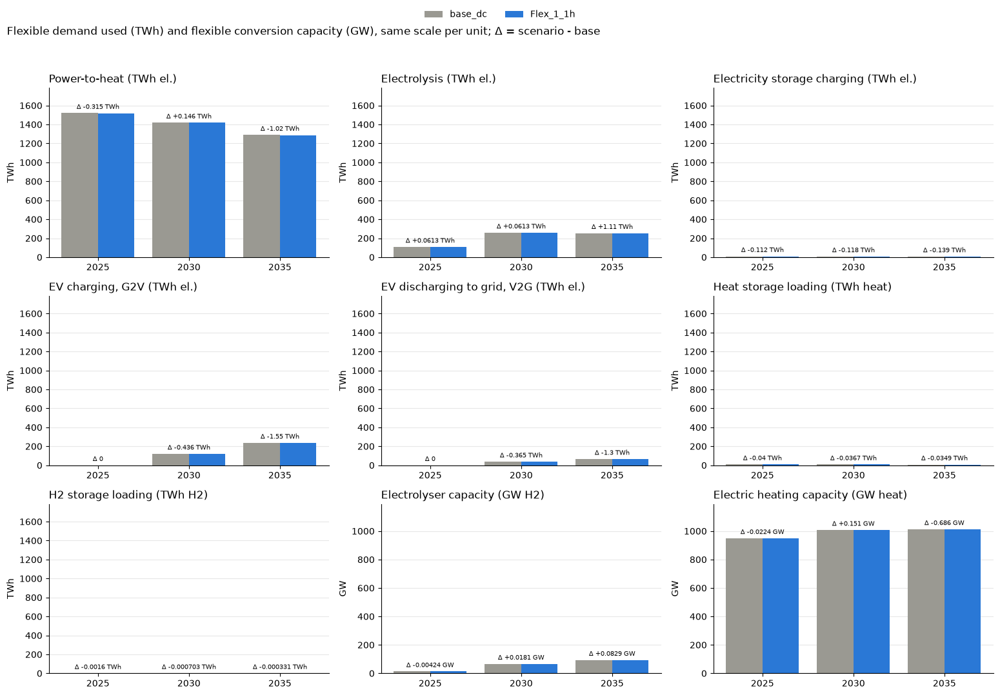

Flexible demand used (TWh) and flexible conversion capacity (GW)


base_dc  Flex_1_1h  Change  \
                                       Year                               
Power-to-heat (TWh el.)                2025  1519.37    1519.05   -0.31   
                                       2030  1418.15    1418.30    0.15   
                                       2035  1288.15    1287.13   -1.02   
Electrolysis (TWh el.)                 2025   107.83     107.89    0.06   
                                       2030   257.84     257.90    0.06   
                                       2035   251.97     253.08    1.11   
Electricity storage charging (TWh el.) 2025     9.54       9.43   -0.11   
                                       2030     7.41       7.29   -0.12   
                                       2035     6.64       6.50   -0.14   
EV charging, G2V (TWh el.)             2025     0.00       0.00    0.00   
                                       2030   120.54     120.11   -0.44   
                                       2035   235.83     234.29   -1.55   
EV discharging to grid, V2G (TWh el.)  2025     0.00       0.00    0.00   
                                       2030    37.76      37.39   -0.36   
                                       2035    65.31      64.02   -1.30   
Heat storage loading (TWh heat)        2025     8.63       8.59   -0.04   
                                       2030     7.99       7.95   -0.04   
                                       2035     7.48       7.45   -0.03   
H2 storage loading (TWh H2)            2025     0.09       0.09   -0.00   
                                       2030     0.57       0.57   -0.00   
                                       2035     0.53       0.53   -0.00   
Electrolyser capacity (GW H2)          2025    13.44      13.44   -0.00   
                                       2030    66.52      66.54    0.02   
                                       2035    93.54      93.62    0.08   
Electric heating capacity (GW heat)    2025   949.24     949.21   -0.02   
                                       2030  1006.91    1007.06    0.15   
                                       2035  1012.48    1011.80   -0.69   

                                             Change (%)  
                                       Year              
Power-to-heat (TWh el.)                2025       -0.02  
                                       2030        0.01  
                                       2035       -0.08  
Electrolysis (TWh el.)                 2025        0.06  
                                       2030        0.02  
                                       2035        0.44  
Electricity storage charging (TWh el.) 2025       -1.18  
                                       2030       -1.59  
                                       2035       -2.10  
EV charging, G2V (TWh el.)             2025         NaN  
                                       2030       -0.36  
                                       2035       -0.66  
EV discharging to grid, V2G (TWh el.)  2025         NaN  
                                       2030       -0.97  
                                       2035       -1.98  
Heat storage loading (TWh heat)        2025       -0.46  
                                       2030       -0.46  
                                       2035       -0.47  
H2 storage loading (TWh H2)            2025       -1.76  
                                       2030       -0.12  
                                       2035       -0.06  
Electrolyser capacity (GW H2)          2025       -0.03  
                                       2030        0.03  
                                       2035        0.09  
Electric heating capacity (GW heat)    2025       -0.00  
                                       2030        0.01  
                                       2035       -0.07

In [57]:
# 10.1.1 Storage capacity (GWh, GW) and flexible demand used (TWh) and installed (GW): base vs scenario
STORAGE_LABEL = {"INTRASEASONAL-ELECT-STORAGE": "Electricity storage (pumped hydro)", "INTRASEASONAL-HEAT-STORAGE": "Heat storage, intra-seasonal",
                 "INTERSEASONAL-HEAT-STORAGE": "Heat storage, inter-seasonal", "H2-STORAGE": "H2 storage"}

def by_year_where(results, scenario, symbol, mask, by=None):
    """Sum of Value per comparison year (and per `by`) for the rows selected by `mask(table)`."""
    t = scenario_result(results, scenario, symbol)
    t = t.loc[mask(t)].assign(Year=lambda d: d["Year"].astype(str))
    if by is None:
        return t.groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    return t.groupby(["Year", by])["Value"].sum().unstack(by, fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

def paired_years(ax, base, scen, title, ylabel, unit):
    """Base (grey) and scenario (blue) bars per year, labelled with the absolute change (scenario - base) in `unit`."""
    x = np.arange(len(COMPARISON_YEARS))
    base, scen = base.reindex(COMPARISON_YEARS, fill_value=0), scen.reindex(COMPARISON_YEARS, fill_value=0)
    ax.bar(x - 0.2, base, 0.4, color=SCEN_COLORS[BASE_SCENARIO], label=BASE_SCENARIO)
    ax.bar(x + 0.2, scen, 0.4, color=SCEN_COLORS[SCENARIO], label=SCENARIO)
    for xi, (b, s) in enumerate(zip(base, scen)):
        d = s - b
        text = f"Δ {d:+.3g} {unit}" if abs(d) > 1e-6 * max(abs(b), 1) else "Δ 0"      # below 1e-6 relative = solver noise
        ax.annotate(text, (xi, max(b, s, 0)), ha="center", va="bottom", fontsize=7.5, xytext=(0, 3), textcoords="offset points")
    ax.set_xticks(x); ax.set_xticklabels(COMPARISON_YEARS)
    style(ax, title, ylabel)

def same_scale(axes):
    """One y-axis range for all `axes` (panels with the same unit), with headroom for the change labels."""
    lo = min(min(ax.get_ylim()[0], 0) for ax in axes)
    hi = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes:
        ax.set_ylim(lo, hi + 0.12 * (hi - lo))

is_storage = lambda t: t["Technology"].isin(list(STORAGE_LABEL))
storage = {"Volume (GWh)": "G_STO_YCRAF", "Power (GW)": "G_CAP_YCRAF"}
sto = {(m, r): by_year_where(res_, s_, symbol, is_storage, "Technology")
       for m, symbol in storage.items() for r, (res_, s_) in {"Base": (base_res, BASE_SCENARIO), "Scenario": (res, SCENARIO)}.items()}
sto_types = [t for t in STORAGE_LABEL if any(t in sto[k].columns for k in sto)]

fig, axes = plt.subplots(2, len(sto_types), figsize=(4.2 * len(sto_types), 7.5), squeeze=False)
for row, measure in enumerate(storage):
    for col, tech in enumerate(sto_types):
        b = sto[(measure, "Base")].get(tech, pd.Series(0.0, index=COMPARISON_YEARS))
        s = sto[(measure, "Scenario")].get(tech, pd.Series(0.0, index=COMPARISON_YEARS))
        paired_years(axes[row, col], b, s, STORAGE_LABEL[tech] if row == 0 else "", measure if col == 0 else "", measure.split("(")[1].rstrip(")"))
    same_scale(axes[row])                          # one scale per row: all volumes in GWh, all powers in GW
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Storage capacity: volume (top) and unloading power (bottom), same scale per row; Δ = scenario - base", x=0.01, y=0.955, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

changes = {m: sto[(m, "Scenario")].sub(sto[(m, "Base")], fill_value=0) for m in storage}
print("Storage capacity per type: change (scenario - base)")
display(pd.concat(changes, axis=1).reindex(columns=[(m, t) for m in storage for t in sto_types], fill_value=0)
        .rename(columns=STORAGE_LABEL, level=1).round(2))

# Flexible demand used (TWh) and installed capacity of the flexible conversion technologies (GW)
cat = lambda *c: (lambda t: t["Category"].isin(c))
FLEX_ENERGY = {   # panel title: (symbol, row selection)
    "Power-to-heat (TWh el.)": ("EL_DEMAND_YCR", cat("ENDOGENOUS_ELECT2HEAT")),
    "Electrolysis (TWh el.)": ("EL_DEMAND_YCR", cat("ENDO_H2")),
    "Electricity storage charging (TWh el.)": ("EL_DEMAND_YCR", cat("ENDO_INTRASTO")),
    "EV charging, G2V (TWh el.)": ("EV_G2V_Y", lambda t: t["Value"].notna()),
    "EV discharging to grid, V2G (TWh el.)": ("EV_V2G_Y", lambda t: t["Value"].notna()),
    "Heat storage loading (TWh heat)": ("H_DEMAND_YCRA", cat("ENDO_INTRASTO", "ENDO_INTERSTO")),
    "H2 storage loading (TWh H2)": ("H2_DEMAND_YCR", cat("ENDO_INTERSTO")),
}
FLEX_CAPACITY = {
    "Electrolyser capacity (GW H2)": ("G_CAP_YCRAF", lambda t: t["Technology"].eq("ELECTROLYZER")),
    "Electric heating capacity (GW heat)": ("G_CAP_YCRAF", lambda t: t["Technology"].eq("ELECT-TO-HEAT")),
}
flex = {}
for title, (symbol, mask) in {**FLEX_ENERGY, **FLEX_CAPACITY}.items():
    try:
        flex[title] = (by_year_where(base_res, BASE_SCENARIO, symbol, mask), by_year_where(res, SCENARIO, symbol, mask))
    except Exception as exc:                       # e.g. no EV add-on in one of the runs
        print(f"{title}: not available ({exc})")

n_col = 3
n_row = int(np.ceil(len(flex) / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(5.2 * n_col, 3.6 * n_row), squeeze=False)
for ax, (title, (b, s)) in zip(axes.ravel(), flex.items()):
    unit = "GW" if title in FLEX_CAPACITY else "TWh"
    paired_years(ax, b, s, title, unit, unit)
same_scale([ax for ax, title in zip(axes.ravel(), flex) if title not in FLEX_CAPACITY])   # all energies (TWh)
same_scale([ax for ax, title in zip(axes.ravel(), flex) if title in FLEX_CAPACITY])       # all capacities (GW)
for ax in axes.ravel()[len(flex):]:
    ax.set_visible(False)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Flexible demand used (TWh) and flexible conversion capacity (GW), same scale per unit; Δ = scenario - base", x=0.01, y=0.965, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

flex_table = pd.concat({title: pd.DataFrame({BASE_SCENARIO: b, SCENARIO: s, "Change": s - b}) for title, (b, s) in flex.items()}, axis=0)
flex_table["Change (%)"] = 100 * flex_table["Change"] / flex_table[BASE_SCENARIO].where(flex_table[BASE_SCENARIO].abs() > 1e-9)
print("Flexible demand used (TWh) and flexible conversion capacity (GW)")
display(flex_table.round(2))

### 10.2 Dispatch: electricity generated per fuel, base vs scenario
`PRO_YCRAGF` (TWh) for the commodities in `COMPARE_COMMODITIES` (set in 10.1), plus the countries whose electricity generation changes most in the last common year.

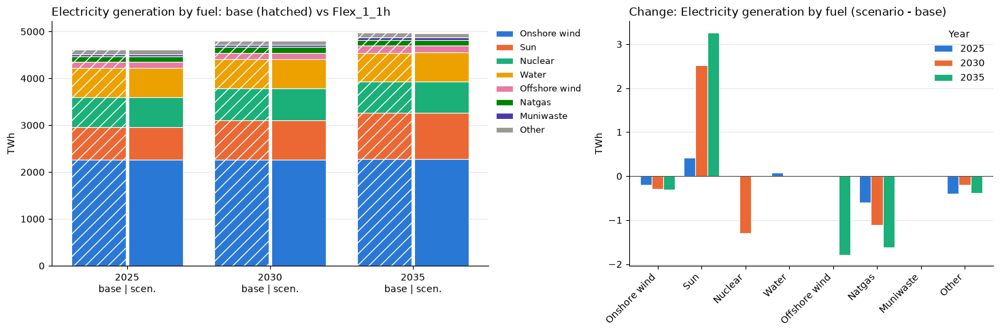

Electricity generation: change per fuel (TWh, scenario - base)


Fuel,WIND_ONSHORE,SUN,NUCLEAR,WATER,WIND_OFFSHORE,NATGAS,MUNIWASTE,Other,Total
Year,,,,,,,,,
2025,-0.20,0.41,0.02,0.07,0.00,-0.61,0.01,-0.40,-0.69
2030,-0.29,2.51,-1.29,-0.00,0.00,-1.10,0.02,-0.19,-0.36
2035,-0.30,3.27,-0.02,0.00,-1.79,-1.62,-0.02,-0.38,-0.85


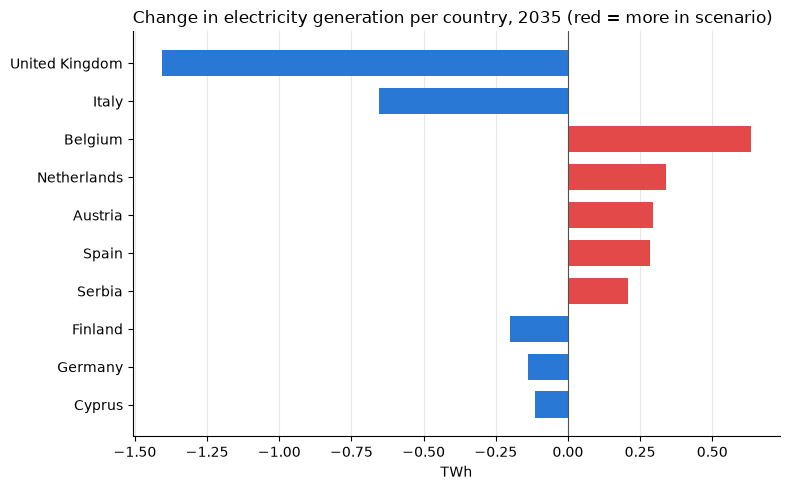

In [58]:
# 10.2 Generation per fuel (TWh)
for commodity in COMPARE_COMMODITIES:
    base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "PRO_YCRAGF", "Fuel", commodity),
                                   by_year(res, SCENARIO, "PRO_YCRAGF", "Fuel", commodity))
    diff = paired_stacked(base_t, scen_t, colors, f"{commodity.title()} generation by fuel", "TWh")
    print(f"{commodity.title()} generation: change per fuel (TWh, scenario - base)")
    display(diff.assign(Total=diff.sum(axis=1)).round(2))

country_change(last_year_by_country(base_res, BASE_SCENARIO, "PRO_YCRAGF", "ELECTRICITY"),
               last_year_by_country(res, SCENARIO, "PRO_YCRAGF", "ELECTRICITY"),
               f"Change in electricity generation per country, {LAST_YEAR} (red = more in scenario)", "TWh")

#### 10.2.1 Response of the flexible electricity demands
The data-center demand is exogenous, but most of the other electricity demand in `EL_DEMAND_YCR` is chosen by the model (power-to-heat, electrolysis, storage charging, EV charging, CCS) or follows from it (grid losses). The waterfall starts from the change in exogenous demand (scenario - base, essentially the additional data-center demand) and shows how each flexible demand responds, ending at the net change in annual electricity demand of 9.1. Red bars add demand, green bars are demand reductions. EV charging and V2G are shown as separate bars: `EL_DEMAND_YCR` only holds their net (`ENDO_EV`), so the two come from `EV_G2V_Y` and `EV_V2G_Y`, as in 13.1; they add up to the same net EV change.

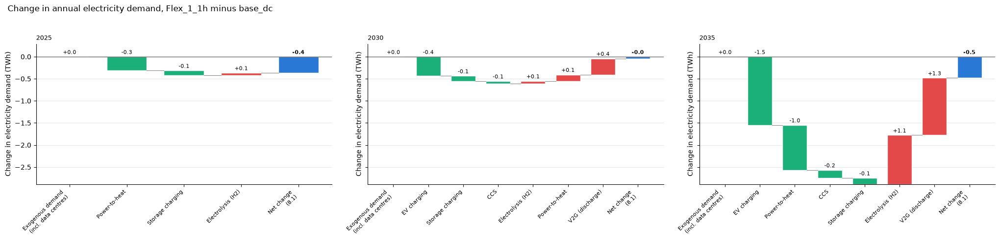

Change in annual electricity demand by category (TWh, scenario - base)


Year,2025,2030,2035
Exogenous demand (incl. data centres),0.00,0.00,0.00
CCS,-0.01,-0.06,-0.18
EV charging,0.00,-0.44,-1.55
Electrolysis (H2),0.06,0.06,1.11
Grid losses,0.00,0.01,0.02
Power-to-heat,-0.31,0.15,-1.02
Storage charging,-0.11,-0.12,-0.14
V2G (discharge),0.00,0.36,1.30
Net change,-0.37,-0.03,-0.46


In [59]:
# 10.2.1 Waterfall of the change in annual electricity demand (TWh): exogenous demand -> flexible demand response -> net change
DEMAND_RESPONSE_LABEL = {"EXOGENOUS": "Exogenous demand\n(incl. data centres)", "ENDOGENOUS_ELECT2HEAT": "Power-to-heat",
                         "ENDO_H2": "Electrolysis (H2)", "ENDO_INTRASTO": "Storage charging", "ENDO_EV": "EV charging",
                         "ENDO_CCS": "CCS", "DIST_LOSSES": "Grid losses", "TRANS_LOSSES": "Grid losses"}

V2G_LABEL = "V2G (discharge)"

def demand_by_category(results, scenario):
    t = scenario_result(results, scenario, "EL_DEMAND_YCR").assign(Year=lambda d: d["Year"].astype(str))
    t["Label"] = t["Category"].map(DEMAND_RESPONSE_LABEL).fillna(t["Category"].map(clean_name))
    out = t.groupby(["Year", "Label"])["Value"].sum().unstack("Label", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)
    ev_label = DEMAND_RESPONSE_LABEL["ENDO_EV"]
    try:                                         # ENDO_EV is the net EV exchange (charging - V2G): split it as in 13.1
        annual = lambda symbol: scenario_result(results, scenario, symbol).assign(Year=lambda d: d["Year"].astype(str)) \
                                    .groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
        g2v, v2g = annual("EV_G2V_Y"), annual("EV_V2G_Y")
        if ev_label in out and (g2v.abs().sum() + v2g.abs().sum()) > 0:
            out[ev_label], out[V2G_LABEL] = g2v, -v2g
    except Exception:                            # no EV add-on in this run
        pass
    return out

d_dem = demand_by_category(res, SCENARIO).sub(demand_by_category(base_res, BASE_SCENARIO), fill_value=0).fillna(0)
first = DEMAND_RESPONSE_LABEL["EXOGENOUS"]
flexible = [c for c in d_dem.columns if c != first]
response_years = [y for y in COMPARISON_YEARS if d_dem.loc[y].abs().max() > 1e-6]

if not response_years:
    print("The electricity demand is identical in both scenarios in all comparison years")
else:
    fig, axes = plt.subplots(1, len(response_years), figsize=(6.5 * len(response_years) + 1, 5), sharey=True, squeeze=False)
    for ax, year in zip(axes.ravel(), response_years):
        row = d_dem.loc[year]
        steps = [first] + sorted([c for c in flexible if abs(row[c]) >= 0.05], key=lambda c: row[c])   # largest reduction first; < 0.05 TWh only in the table
        level, x = 0.0, 0
        for x, label in enumerate(steps):
            v = row[label]
            ax.bar(x, v, bottom=level, color="#e34948" if v >= 0 else "#1baf7a", width=0.7, edgecolor="#fcfcfb")
            ax.annotate(f"{v:+.1f}", (x, level + max(v, 0)), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
            if x:                                                     # connector from the previous bar
                ax.plot([x - 0.65, x - 0.35], [level, level], color="#8a8984", linewidth=0.8)
            level += v
        ax.bar(x + 1, level, color="#2a78d6", width=0.7, edgecolor="#fcfcfb")
        ax.plot([x + 0.35, x + 0.65], [level, level], color="#8a8984", linewidth=0.8)
        ax.annotate(f"{level:+.1f}", (x + 1, max(level, 0)), ha="center", va="bottom", fontsize=8, fontweight="bold", xytext=(0, 2), textcoords="offset points")
        ax.set_xticks(range(len(steps) + 1))
        ax.set_xticklabels(steps + ["Net change\n(8.1)"], rotation=45, ha="right", fontsize=8)
        ax.axhline(0, color="#52514e", linewidth=0.8)
        flex_row = row[flexible].copy()
        if V2G_LABEL in flex_row:                                  # EV charging and V2G count as one flexible demand (their net) in the headline
            flex_row[DEMAND_RESPONSE_LABEL["ENDO_EV"]] += flex_row.pop(V2G_LABEL)
        reduction = flex_row.clip(upper=0).sum()
        ax.set_title(f"{year}: flexible demand offsets {-reduction:.1f} TWh ({-reduction / row[first] * 100:.0f} % of the exogenous increase)"
                     if row[first] > 0 else str(year), loc="left", fontsize=9)
        ax.set_ylabel("Change in electricity demand (TWh)")
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    lo, hi = axes.ravel()[0].get_ylim()                       # headroom for the value labels (shared y-axis)
    axes.ravel()[0].set_ylim(lo, hi + 0.1 * (hi - lo))
    fig.suptitle(f"Change in annual electricity demand, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    table = d_dem.loc[response_years, [first] + flexible].T
    table.index = [i.replace("\n", " ") for i in table.index]
    table.loc["Net change"] = table.sum()
    print("Change in annual electricity demand by category (TWh, scenario - base)")
    display(table.round(2))


#### 10.2.2 Change in heat and hydrogen dispatch
What replaces the electricity-based heat and hydrogen that is no longer produced (10.2.1): the change (scenario - base) in annual heat and hydrogen dispatch (`PRO_YCRAGF`, TWh) per fuel and technology, one bar per year. Storage discharge is included as dispatch (it shifts production in time). Items changing by less than `MIN_DISPATCH_CHANGE` TWh in every year are summed as "Other".

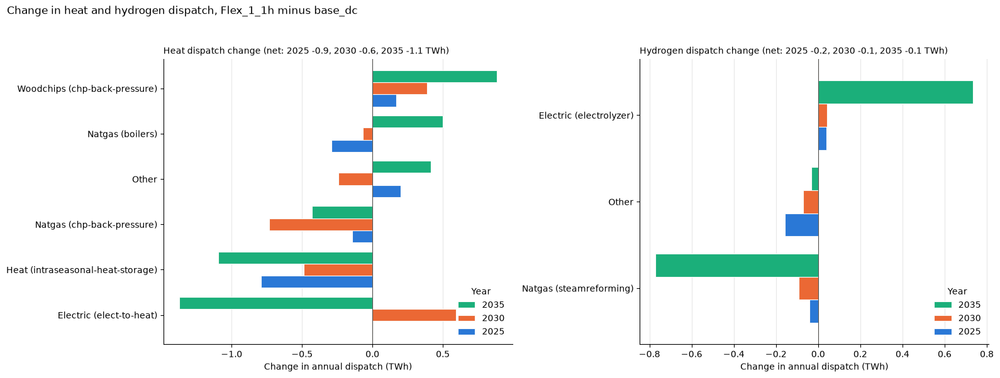

Change in heat dispatch (TWh, scenario - base)


Year,2025,2030,2035
Source,,,
Woodchips (chp-back-pressure),0.17,0.39,0.88
Natgas (boilers),-0.29,-0.07,0.50
Other,0.20,-0.24,0.42
Natgas (chp-back-pressure),-0.14,-0.73,-0.43
Heat (intraseasonal-heat-storage),-0.79,-0.49,-1.09
Electric (elect-to-heat),0.00,0.59,-1.37
Net change,-0.86,-0.55,-1.10


Change in hydrogen dispatch (TWh, scenario - base)


Year,2025,2030,2035
Source,,,
Electric (electrolyzer),0.04,0.04,0.73
Other,-0.16,-0.07,-0.03
Natgas (steamreforming),-0.04,-0.09,-0.77
Net change,-0.16,-0.12,-0.07


In [60]:
# 10.2.2 Change (scenario - base) in heat and hydrogen dispatch per fuel and technology (TWh)
MIN_DISPATCH_CHANGE = 0.5            # TWh; smaller items are summed as "Other"

def dispatch_by_source(results, scenario, commodity):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Commodity"].eq(commodity)].assign(Year=lambda d: d["Year"].astype(str))
    t["Source"] = t["Fuel"].map(clean_name) + " (" + t["Technology"].str.lower() + ")"
    return t.groupby(["Year", "Source"])["Value"].sum().unstack("Source", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

dispatch_change = {}
for commodity in ["HEAT", "HYDROGEN"]:
    d = dispatch_by_source(res, SCENARIO, commodity).sub(dispatch_by_source(base_res, BASE_SCENARIO, commodity), fill_value=0).fillna(0)
    d = d.loc[response_years] if response_years else d.iloc[:0]
    small = d.columns[d.abs().max() < MIN_DISPATCH_CHANGE]
    d = d.drop(columns=small).assign(**({"Other": d[small].sum(axis=1)} if len(small) else {}))
    dispatch_change[commodity] = d.loc[:, d.iloc[-1].sort_values().index] if len(d) else d          # largest increase on top

if not response_years:
    print("Heat and hydrogen dispatch are identical in both scenarios in all comparison years")
else:
    heights = [max(len(d.columns), 1) for d in dispatch_change.values()]
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.4 * max(heights) * len(response_years) / 2 + 2.5))
    for ax, (commodity, d) in zip(axes, dispatch_change.items()):
        d.T.plot.barh(ax=ax, color=year_colors(len(COMPARISON_YEARS))[-len(d):], width=0.8, edgecolor="#fcfcfb", linewidth=0.8)
        ax.axvline(0, color="#52514e", linewidth=0.8)
        net = d.sum(axis=1)
        ax.set_title(f"{commodity.title()} dispatch change (net: " + ", ".join(f"{y} {v:+.1f}" for y, v in net.items()) + " TWh)", loc="left", fontsize=10)
        ax.set_xlabel("Change in annual dispatch (TWh)"); ax.set_ylabel("")
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right")
    fig.suptitle(f"Change in heat and hydrogen dispatch, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    for commodity, d in dispatch_change.items():
        table = d.T.iloc[::-1]
        table.loc["Net change"] = table.sum()
        print(f"Change in {commodity.lower()} dispatch (TWh, scenario - base)")
        display(table.round(2))


#### 10.2.3 Curtailment: base vs scenario
`CURT_YCRAGF` (TWh) for onshore wind, offshore wind and solar PV only: hydro-reservoir rows net to about zero (see section 5) and are left out.
The curtailment rate is curtailed / (dispatched + curtailed) energy of the same technologies.

,base_dc (TWh),Flex_1_1h (TWh),Change (TWh),base_dc rate (%),Flex_1_1h rate (%),Change (pp)
Year,,,,,,
2025,33.50,33.44,-0.06,1.07,1.07,-0.0
2030,21.54,21.51,-0.04,0.66,0.66,-0.0
2035,20.36,20.32,-0.04,0.59,0.59,-0.0


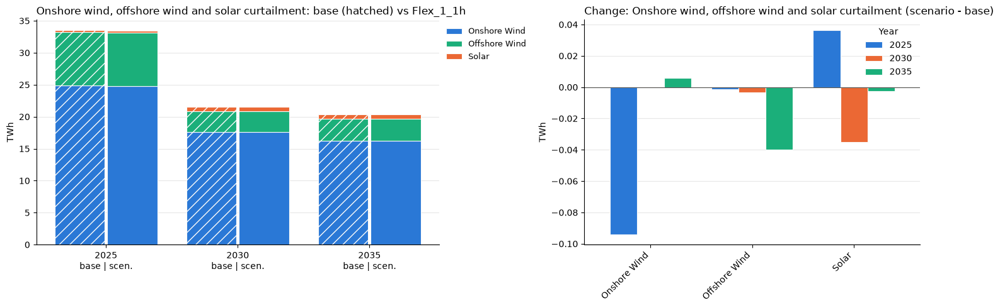

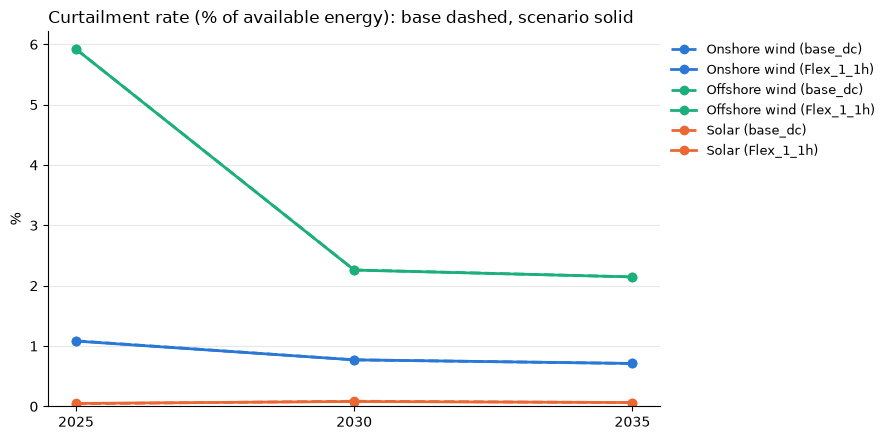

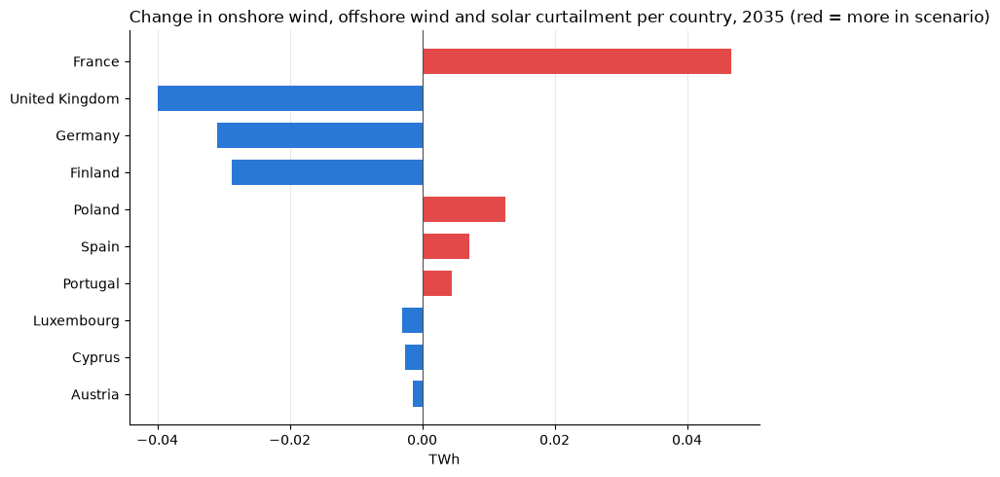

In [61]:
# 10.2.3 Onshore wind, offshore wind and solar curtailment (TWh and % of available energy)
def vre_by_year(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Technology"].isin(VRE_TECH)]
    if "Commodity" in table:
        table = table.loc[table["Commodity"].eq("ELECTRICITY")]
    table = table.assign(Year=table["Year"].astype(str), Group=table["Technology"].map(VRE_TECH))
    return table.groupby(["Year", "Group"])["Value"].sum().unstack("Group", fill_value=0).reindex(
        index=COMPARISON_YEARS, columns=list(dict.fromkeys(VRE_TECH.values())), fill_value=0)

curt_b, curt_s = vre_by_year(base_res, BASE_SCENARIO, "CURT_YCRAGF"), vre_by_year(res, SCENARIO, "CURT_YCRAGF")
prod_b, prod_s = vre_by_year(base_res, BASE_SCENARIO, "PRO_YCRAGF"), vre_by_year(res, SCENARIO, "PRO_YCRAGF")
rate_b = curt_b.sum(axis=1) / (curt_b.sum(axis=1) + prod_b.sum(axis=1)).replace(0, np.nan) * 100
rate_s = curt_s.sum(axis=1) / (curt_s.sum(axis=1) + prod_s.sum(axis=1)).replace(0, np.nan) * 100

curt_cmp = pd.DataFrame({f"{BASE_SCENARIO} (TWh)": curt_b.sum(axis=1), f"{SCENARIO} (TWh)": curt_s.sum(axis=1),
                         "Change (TWh)": curt_s.sum(axis=1) - curt_b.sum(axis=1),
                         f"{BASE_SCENARIO} rate (%)": rate_b, f"{SCENARIO} rate (%)": rate_s,
                         "Change (pp)": rate_s - rate_b})
display(curt_cmp.round(2))

VRE_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#1baf7a", "Solar": "#eb6834"}        # distinct colours (the GROUP_COLORS winds are near-identical)
paired_stacked(curt_b, curt_s, VRE_COLORS, "Onshore wind, offshore wind and solar curtailment", "TWh")

# Curtailment rate per technology group: base dashed, scenario solid
fig, ax = plt.subplots(figsize=(9, 4.5))
for g in curt_b.columns:
    for label, c, p, ls in [(BASE_SCENARIO, curt_b, prod_b, "--"), (SCENARIO, curt_s, prod_s, "-")]:
        r = c[g] / (c[g] + p[g]).replace(0, np.nan) * 100
        ax.plot(r.index, r.values, ls, marker="o", linewidth=2, color=VRE_COLORS[g], label=f"{g} ({label})")
ax.set_ylim(bottom=0)
style(ax, "Curtailment rate (% of available energy): base dashed, scenario solid", "%")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1), fontsize=9)
plt.tight_layout(); plt.show()

country_change(last_year_by_country(base_res, BASE_SCENARIO, "CURT_YCRAGF", technologies=list(VRE_TECH)),
               last_year_by_country(res, SCENARIO, "CURT_YCRAGF", technologies=list(VRE_TECH)),
               f"Change in onshore wind, offshore wind and solar curtailment per country, {LAST_YEAR} (red = more in scenario)", "TWh")

#### 10.2.4 Installed capacity and dispatch by fuel in `FOCUS_YEAR`: electricity, heat and hydrogen
Change (scenario - base) in installed capacity (`G_CAP_YCRAF`, GW) and dispatch (`PRO_YCRAGF`, TWh) by fuel in `FOCUS_YEAR` (2035, or the last common year if 2035 is not solved), in absolute terms; the tables also list the base and scenario values. H2 storage is included and shown as its own fuel ("H2 storage").

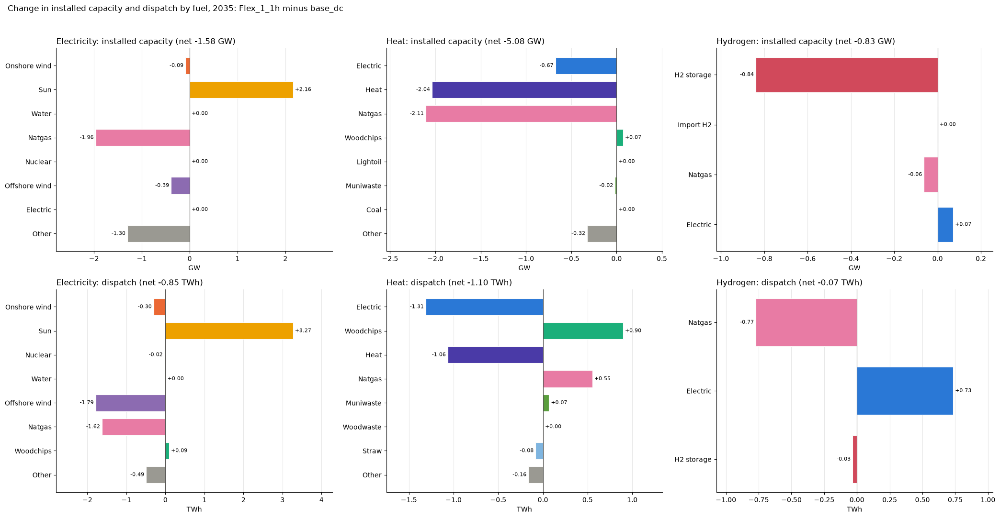

Electricity installed capacity by fuel, 2035 (GW)


,Base,Scenario,Change,Change (%)
Onshore wind,635.58,635.50,-0.09,-0.01
Sun,595.96,598.12,2.16,0.36
Water,176.21,176.21,0.00,0.00
Natgas,117.39,115.43,-1.96,-1.67
Nuclear,83.98,83.98,0.00,0.00
Offshore wind,41.03,40.65,-0.39,-0.94
Electric,19.50,19.50,0.00,0.00
Other,35.25,33.95,-1.30,-3.69
Total,1704.90,1703.32,-1.58,-0.09


Heat installed capacity by fuel, 2035 (GW)


,Base,Scenario,Change,Change (%)
Electric,1012.96,1012.28,-0.67,-0.07
Heat,515.67,513.64,-2.04,-0.39
Natgas,364.00,361.90,-2.11,-0.58
Woodchips,232.01,232.09,0.07,0.03
Lightoil,32.43,32.43,0.00,0.00
Muniwaste,21.40,21.38,-0.02,-0.07
Coal,16.63,16.63,0.00,0.00
Other,33.38,33.05,-0.32,-0.97
Total,2228.48,2223.40,-5.08,-0.23


Hydrogen installed capacity by fuel, 2035 (GW)


...

,Base,Scenario,Change,Change (%)
Onshore wind,2272.33,2272.03,-0.30,-0.01
Sun,995.05,998.32,3.27,0.33
Nuclear,662.28,662.26,-0.02,-0.00
Water,617.78,617.78,0.00,0.00
Offshore wind,157.36,155.58,-1.79,-1.13
Natgas,118.27,116.64,-1.62,-1.37
Woodchips,51.96,52.06,0.09,0.18
Other,95.00,94.51,-0.49,-0.52
Total,4970.03,4969.18,-0.85,-0.02


Heat dispatch by fuel, 2035 (TWh)


,Base,Scenario,Change,Change (%)
Electric,4218.43,4217.12,-1.31,-0.03
Woodchips,1356.07,1356.96,0.90,0.07
Heat,275.56,274.49,-1.06,-0.39
Natgas,263.19,263.74,0.55,0.21
Muniwaste,145.63,145.70,0.07,0.05
Woodwaste,67.82,67.82,0.00,0.00
Straw,66.53,66.45,-0.08,-0.12
Other,12.16,12.00,-0.16,-1.33
Total,6405.39,6404.30,-1.10,-0.02


Hydrogen dispatch by fuel, 2035 (TWh)


,Base,Scenario,Change,Change (%)
Fuel,,,,
Natgas,552.16,551.38,-0.77,-0.14
Electric,165.41,166.14,0.73,0.44
H2 storage,52.82,52.79,-0.03,-0.06
Total,770.38,770.31,-0.07,-0.01


In [62]:
# 10.2.4 Change (scenario - base) in installed capacity (GW) and dispatch (TWh) by fuel in FOCUS_YEAR for electricity, heat and hydrogen
FOCUS_COMMODITIES = ["ELECTRICITY", "HEAT", "HYDROGEN"]
FOCUS_QUANTITIES = {"Installed capacity": ("G_CAP_YCRAF", "GW"), "Dispatch": ("PRO_YCRAGF", "TWh")}
FOCUS_N_FUELS = 7                    # the largest fuels per panel keep their name, the rest is "Other"
FUEL_PALETTE = PALETTE + ["#8c6bb1", "#5a9e3d", "#d1495b", "#00a6a6", "#7fb5e0", "#a24fb8", "#c9a227", "#52514e"]

def focus_by_fuel(results, scenario, symbol, commodity):
    """Value per fuel in FOCUS_YEAR for one commodity; H2 storage (fuel HYDROGEN) is labelled as its own fuel."""
    t = scenario_result(results, scenario, symbol)
    t = t.loc[t["Year"].astype(str).eq(FOCUS_YEAR) & t["Commodity"].eq(commodity)]
    fuel = t["Fuel"].mask(t["Technology"].eq("H2-STORAGE"), "H2_STORAGE")
    return t.groupby(fuel)["Value"].sum()

# Base and scenario per panel, with the small fuels folded into "Other" (same columns in both runs)
focus_tables = {}
for quantity, (symbol, unit) in FOCUS_QUANTITIES.items():
    for commodity in FOCUS_COMMODITIES:
        t = pd.DataFrame({"Base": focus_by_fuel(base_res, BASE_SCENARIO, symbol, commodity),
                          "Scenario": focus_by_fuel(res, SCENARIO, symbol, commodity)}).fillna(0)
        t = t.loc[t.abs().sum(axis=1) > 1e-6]
        order = t.abs().sum(axis=1).sort_values(ascending=False).index
        keep_f, rest_f = list(order[:FOCUS_N_FUELS]), list(order[FOCUS_N_FUELS:])
        t = pd.concat([t.loc[keep_f], t.loc[rest_f].sum().to_frame("Other").T]) if rest_f else t.loc[keep_f]
        focus_tables[(quantity, commodity)] = t

# One colour per fuel in all six panels (the fuel largest over all panels gets the first colour)
fuel_rank = pd.concat([t.abs().sum(axis=1) for t in focus_tables.values()]).groupby(level=0).sum().drop("Other", errors="ignore")
FOCUS_FUEL_COLORS = dict(zip(fuel_rank.sort_values(ascending=False).index, FUEL_PALETTE))
FOCUS_FUEL_COLORS.update({f: GREY for f in fuel_rank.index[len(FUEL_PALETTE):]}, Other=GREY)
fuel_label = lambda f: "H2 storage" if f == "H2_STORAGE" else clean_name(f)

# Change per fuel (scenario - base) in absolute terms: one bar per fuel, net change of the panel in the title
fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for (row, (quantity, (symbol, unit))) in enumerate(FOCUS_QUANTITIES.items()):
    for col, commodity in enumerate(FOCUS_COMMODITIES):
        ax, t = axes[row, col], focus_tables[(quantity, commodity)]
        change = (t["Scenario"] - t["Base"]).iloc[::-1]                        # largest fuel on top
        y = np.arange(len(change))
        ax.barh(y, change.values, 0.7, color=[FOCUS_FUEL_COLORS[f] for f in change.index], edgecolor="#fcfcfb", linewidth=0.8)
        for yi, v in zip(y, change.values):
            ax.annotate(f"{v:+,.2f}", (v, yi), ha="left" if v >= 0 else "right", va="center", fontsize=8,
                        xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
        ax.set_yticks(y); ax.set_yticklabels([fuel_label(f) for f in change.index])
        ax.axvline(0, color="#52514e", linewidth=0.8); ax.margins(x=0.2)
        style(ax, f"{commodity.title()}: {quantity.lower()} (net {change.sum():+,.2f} {unit})", "", axis="x"); ax.set_xlabel(unit)
fig.suptitle(f"Change in installed capacity and dispatch by fuel, {FOCUS_YEAR}: {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

# Tables: base, scenario and change per fuel for each of the six panels
for (quantity, commodity), t in focus_tables.items():
    unit = FOCUS_QUANTITIES[quantity][1]
    t = t.rename(index=fuel_label)
    t.loc["Total"] = t.sum()
    print(f"{commodity.title()} {quantity.lower()} by fuel, {FOCUS_YEAR} ({unit})")
    display(t.assign(Change=t["Scenario"] - t["Base"], **{"Change (%)": (t["Scenario"] - t["Base"]) / t["Base"].replace(0, np.nan) * 100}).round(2))

#### 10.2.4.1 Change in electricity dispatch per fuel type, hour by hour
Change (scenario - base) in the electricity dispatch in every modelled hour of `FOCUS_YEAR`, summed over all regions (GW), split by fuel type: the electricity production of all technologies (`PRO_YCRAGFST`, including storage discharge). Only the difference with the base scenario is shown, one panel per season block. Increases are stacked up from zero, decreases down from zero, and the black line is the net change.
- **Fuel types** are the fuels of 10.2.4, with onshore and offshore wind separate; electricity storage is labelled as its own type because its dispatch is a discharge. The 8 fuels with the largest change keep their name, the rest is "Other". The table gives the mean change per fuel over the modelled hours; the net change is the sum of the fuels.
- To show heat and hydrogen as extra rows, add them to `DISPATCH_CARRIERS` at the top of the cell.
- The two runs must model the same hours; otherwise the cell is skipped.

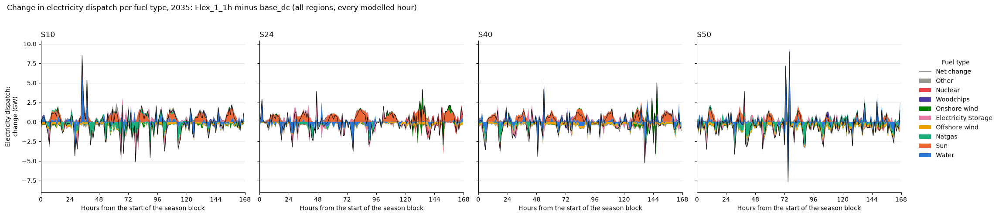

Mean change in electricity dispatch per fuel over the modelled hours (GW, scenario - base)


Commodity,Electricity
Fuel,
Water,0.000
Sun,0.373
Natgas,-0.185
Offshore wind,-0.204
Electricity Storage,-0.045
Onshore wind,-0.034
Woodchips,0.011
Nuclear,-0.002
Other,-0.011


In [63]:
# 10.2.4.1 Change (scenario - base) in electricity dispatch per fuel type in every modelled hour of FOCUS_YEAR (GW, sum over all regions)
DISPATCH_CARRIERS = {"ELECTRICITY": "Electricity"}                      # add "HEAT": "Heat", "HYDROGEN": "Hydrogen" to show the other carriers as extra rows
DISPATCH_N_FUELS = 8                                                   # per carrier, the fuels with the largest change keep their name, the rest is "Other"
DISPATCH_STEP_H = globals().get("SFLEX_STEP_H")                        # hours per time step (None: label the axis in time steps)
DISPATCH_COLORS = PALETTE + ["#8c6bb1", "#5a9e3d", "#d1495b", "#00a6a6", "#7fb5e0", "#a24fb8", "#c9a227", "#52514e"]
STORAGE_FUEL = {"H2-STORAGE": "H2_STORAGE", "INTRASEASONAL-HEAT-STORAGE": "HEAT_STORAGE_INTRASEASONAL",       # storage is dispatched from a store:
                "INTERSEASONAL-HEAT-STORAGE": "HEAT_STORAGE_INTERSEASONAL", "INTRASEASONAL-ELECT-STORAGE": "ELECTRICITY_STORAGE"}   # label it by type, not by its fuel

def hourly_dispatch(results, scenario):
    """Series (GW, all regions) of the dispatch per Season, Time, energy carrier and fuel in FOCUS_YEAR (PRO_YCRAGFST)."""
    pro = scenario_result(results, scenario, "PRO_YCRAGFST")
    pro = pro.loc[pro["Year"].astype(str).eq(FOCUS_YEAR) & pro["Commodity"].isin(DISPATCH_CARRIERS)].copy()
    pro["Fuel"] = pro["Technology"].map(STORAGE_FUEL).fillna(pro["Fuel"])
    return pro.groupby(["Commodity", "Season", "Time", "Fuel"])["Value"].sum() / 1e3                                  # MWh per hour -> GW

disp_s, disp_b = hourly_dispatch(res, SCENARIO), hourly_dispatch(base_res, BASE_SCENARIO)
hours_s, hours_b = (set(s.index.droplevel(["Commodity", "Fuel"])) for s in (disp_s, disp_b))
if hours_s != hours_b:
    print(f"10.2.4.1 skipped: the two runs model different hours ({len(hours_s)} vs {len(hours_b)} time slices), "
          "so an hour-by-hour difference is not meaningful.")
else:
    d_disp = disp_s.sub(disp_b, fill_value=0).fillna(0)
    by_carrier = d_disp.abs().groupby(level=["Commodity", "Fuel"]).sum()
    named = {f for commodity in DISPATCH_CARRIERS for f in by_carrier.xs(commodity, level="Commodity").sort_values(ascending=False).index[:DISPATCH_N_FUELS]
             if by_carrier.xs(commodity, level="Commodity")[f] > 1e-6}                      # the largest fuels of every carrier, so none is hidden in "Other"
    rank = d_disp.abs().groupby(level="Fuel").sum().sort_values(ascending=False)           # colour order: fuels by size of the change over all carriers and hours
    keep = [f for f in rank.index if f in named]
    d_disp = d_disp.rename(index=lambda f: f if f in keep else "OTHER", level="Fuel").groupby(level=["Commodity", "Season", "Time", "Fuel"]).sum()
    fuels = keep + (["OTHER"] if "OTHER" in d_disp.index.get_level_values("Fuel") else [])
    fuel_color = {f: (DISPATCH_COLORS[k] if f != "OTHER" else GREY) for k, f in enumerate(fuels)}
    fuel_name = lambda f: "Other" if f == "OTHER" else clean_name(f)
    seasons = list(dict.fromkeys(d_disp.index.get_level_values("Season")))
    fig, axes = plt.subplots(len(DISPATCH_CARRIERS), len(seasons), figsize=(4.5 * len(seasons) + 3, max(5, 3.1 * len(DISPATCH_CARRIERS) + 1)),
                             sharex="col", sharey="row", squeeze=False)
    for r, (commodity, name) in enumerate(DISPATCH_CARRIERS.items()):
        t_all = d_disp.xs(commodity, level="Commodity").unstack("Fuel", fill_value=0).reindex(columns=fuels, fill_value=0)
        for c, season in enumerate(seasons):
            ax, t = axes[r, c], t_all.xs(season, level="Season")
            x = np.arange(len(t)) * (DISPATCH_STEP_H or 1)
            pos, neg = np.zeros(len(t)), np.zeros(len(t))
            for f in fuels:                                  # increases stacked up from 0, decreases stacked down from 0
                v = t[f].to_numpy(dtype=float)
                up, down = np.clip(v, 0, None), np.clip(v, None, 0)
                ax.fill_between(x, pos, pos + up, color=fuel_color[f], linewidth=0, label=fuel_name(f))
                ax.fill_between(x, neg, neg + down, color=fuel_color[f], linewidth=0)
                pos, neg = pos + up, neg + down
            ax.plot(x, t.sum(axis=1).to_numpy(), color="#1a1a1a", linewidth=0.9, label="Net change")
            ax.axhline(0, color="#52514e", linewidth=0.8)
            ax.set_xlim(0, x[-1] if len(x) > 1 else 1)
            if DISPATCH_STEP_H:
                ax.set_xticks(np.arange(0, len(t) * DISPATCH_STEP_H + 1, 24))
            ax.set_title(season if r == 0 else "", loc="left")
            ax.set_ylabel(f"{name} dispatch:\nchange (GW)" if c == 0 else "")
            ax.set_xlabel(("Hours from the start of the season block" if DISPATCH_STEP_H else "Time step") if r == len(DISPATCH_CARRIERS) - 1 else "")
            ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
            for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, title="Fuel type")
    fig.suptitle(f"Change in electricity dispatch per fuel type, {FOCUS_YEAR}: {SCENARIO} minus {BASE_SCENARIO} (all regions, every modelled hour)", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    # Mean change per fuel over the modelled hours (GW), per energy carrier; the net change of a carrier is the sum of its fuels
    mean_d = d_disp.groupby(level=["Commodity", "Fuel"]).sum().div(len(hours_s)).unstack("Commodity", fill_value=0)
    mean_d = mean_d.reindex(index=fuels, columns=list(DISPATCH_CARRIERS), fill_value=0).rename(index=fuel_name, columns=DISPATCH_CARRIERS)
    mean_d.loc["Net change"] = mean_d.sum()
    print("Mean change in electricity dispatch per fuel over the modelled hours (GW, scenario - base)")
    display(mean_d.round(3))

#### 10.2.5 How the extra electricity demand is met, hour by hour
Change (scenario - base) in every modelled hour of `FOCUS_YEAR`, summed over all regions (GW). The stacked areas are the change in generation per fuel group (`PRO_YCRAGFST`) plus the flexible demands that are reduced (`EL_DEMAND_YCRST`, shown as supply: less electrolysis, less electric heating). In every hour they add up to the dashed line, the change in exogenous demand (in the data-centre scenarios: the extra data-centre load). EV charging and storage are moved in time, so they appear above and below zero; "Other" holds nuclear, onshore wind, biomass and waste, CCS and grid losses. The table gives the averages per season.

Largest gap between the stacked areas and the change in exogenous demand: 0.000 GW


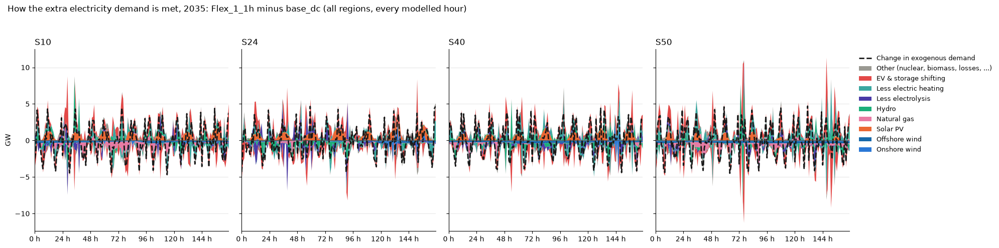

Technology,Onshore wind,Offshore wind,Solar PV,Natural gas,Hydro,Less electrolysis,Less electric heating,EV & storage shifting,"Other (nuclear, biomass, losses, ...)",Change in exogenous demand
S10,-0.04,-0.19,0.39,-0.29,0.11,-0.13,0.02,0.09,0.04,-0.0
S24,-0.02,-0.12,0.52,-0.07,-0.19,-0.11,-0.00,0.00,-0.00,-0.0
S40,-0.03,-0.22,0.38,-0.11,0.02,-0.17,0.11,0.02,-0.00,-0.0
S50,-0.04,-0.28,0.20,-0.27,0.07,-0.10,0.34,0.06,0.03,-0.0
All,-0.03,-0.20,0.37,-0.19,0.00,-0.13,0.12,0.04,0.02,-0.0


In [64]:
# 10.2.5 How the extra exogenous electricity demand is met in every modelled hour of FOCUS_YEAR (GW, sum over all regions)
# Change (scenario - base) in generation by fuel group, plus the flexible demands that are reduced (shown as supply);
# EV charging and storage are moved in time (net about zero over the year), so they appear above and below zero.
# Balance per hour: sum of the stacked areas = change in exogenous demand (mostly data centres; dashed line).
HOURLY_GEN_GROUPS = {"WIND-ON": "Onshore wind", "WIND-OFF": "Offshore wind", "SOLAR-PV": "Solar PV", "NATGAS": "Natural gas", "WATER": "Hydro",
                     "INTRASEASONAL-ELECT-STORAGE": "EV & storage shifting"}
HOURLY_DEMAND_GROUPS = {"ENDO_H2": "Less electrolysis", "ENDOGENOUS_ELECT2HEAT": "Less electric heating",
                        "ENDO_EV": "EV & storage shifting", "ENDO_INTRASTO": "EV & storage shifting"}
HOURLY_OTHER = "Other (nuclear, biomass, losses, ...)"
HOURLY_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#1769aa", "Solar PV": "#eb6834", "Natural gas": "#e87ba4", "Hydro": "#1baf7a",
                 "Less electrolysis": "#4a3aa7", "Less electric heating": "#3aa7a0", "EV & storage shifting": "#e34948",
                 HOURLY_OTHER: GREY}

def hourly_supply(results, scenario):
    """Season x Time table (GW, all regions): electricity generation by group and minus the flexible demands."""
    pro = scenario_result(results, scenario, "PRO_YCRAGFST")
    pro = pro.loc[pro["Year"].astype(str).eq(FOCUS_YEAR) & pro["Commodity"].eq("ELECTRICITY")]
    key = pro["Technology"].where(pro["Technology"].isin(HOURLY_GEN_GROUPS), pro["Fuel"])
    group = key.map(HOURLY_GEN_GROUPS).fillna(HOURLY_OTHER)
    gen = pro.groupby(["Season", "Time", group])["Value"].sum().unstack(fill_value=0)
    dem = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    dem = dem.loc[dem["Year"].astype(str).eq(FOCUS_YEAR) & dem["Category"].ne("EXOGENOUS")]
    dgroup = dem["Category"].map(HOURLY_DEMAND_GROUPS).fillna(HOURLY_OTHER)
    flex = -dem.groupby(["Season", "Time", dgroup])["Value"].sum().unstack(fill_value=0)      # less demand = supply
    exo = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    exo = exo.loc[exo["Year"].astype(str).eq(FOCUS_YEAR) & exo["Category"].eq("EXOGENOUS")].groupby(["Season", "Time"])["Value"].sum()
    return gen.add(flex, fill_value=0) / 1e3, exo / 1e3                                         # MWh per hour -> GW

supply_s, exo_s = hourly_supply(res, SCENARIO)
supply_b, exo_b = hourly_supply(base_res, BASE_SCENARIO)
if not supply_s.index.sort_values().equals(supply_b.index.sort_values()):
    raise SystemExit(f"10.2.5 skipped: the two runs model different hours ({len(supply_s)} vs {len(supply_b)} time slices), "
                     "so an hour-by-hour difference is not meaningful.")
d_supply = supply_s.sub(supply_b, fill_value=0).fillna(0)
d_supply = d_supply[[g for g in HOURLY_COLORS if g in d_supply.columns]]
d_exo = exo_s.sub(exo_b, fill_value=0).reindex(d_supply.index, fill_value=0)
closure = (d_supply.sum(axis=1) - d_exo).abs().max()
print(f"Largest gap between the stacked areas and the change in exogenous demand: {closure:.3f} GW")

seasons = list(dict.fromkeys(d_supply.index.get_level_values("Season")))
fig, axes = plt.subplots(1, len(seasons), figsize=(4.5 * len(seasons) + 2, 5), sharey=True, squeeze=False)
for ax, season in zip(axes.ravel(), seasons):
    t = d_supply.xs(season, level="Season")
    x = np.arange(len(t))
    pos, neg = np.zeros(len(t)), np.zeros(len(t))
    for g in t.columns:                                  # increases stacked up from 0, decreases stacked down from 0
        v = t[g].to_numpy(dtype=float)
        up, down = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.fill_between(x, pos, pos + up, color=HOURLY_COLORS[g], linewidth=0, label=g)
        ax.fill_between(x, neg, neg + down, color=HOURLY_COLORS[g], linewidth=0)
        pos, neg = pos + up, neg + down
    ax.plot(x, d_exo.xs(season, level="Season").to_numpy(), color="#1a1a1a", linewidth=2, linestyle="--", label="Change in exogenous demand")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_xticks(range(0, len(t) + 1, 24)); ax.set_xticklabels([f"{h} h" for h in range(0, len(t) + 1, 24)])
    ax.set_xlim(0, len(t) - 1)
    style(ax, f"{season}", "GW" if ax is axes.ravel()[0] else "")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles[::-1], labels[::-1], bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=9)
fig.suptitle(f"How the extra electricity demand is met, {FOCUS_YEAR}: {SCENARIO} minus {BASE_SCENARIO} (all regions, every modelled hour)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

# Average over the modelled hours (GW), per season and in total
display(pd.concat([d_supply.groupby(level="Season").mean(), d_supply.mean().to_frame("All").T]).assign(**{"Change in exogenous demand": pd.concat([d_exo.groupby(level="Season").mean(), pd.Series({"All": d_exo.mean()})])}).round(2))

### 10.3 Why does the total system cost change?
The change in total system cost (`OBJ_YCR`, scenario - base, Mmoney) as a waterfall over the cost groups of 6.1 (capital, fixed O&M, variable O&M, fuel, CO2 tax and transport), ending at the net change of 9.1. The panel title relates the net change to the additional exogenous electricity demand of 10.2.1 (Mmoney/TWh = Money/MWh), i.e. the average system cost of serving the new data-center demand.

The second chart splits the same change by technology type, using the generator-level costs of `ECO_G_YCRAG`; costs that are not attributed to a generator there (transmission, and the small difference in fuel cost accounting between `ECO_G_YCRAG` and `OBJ_YCR`) are shown as "Transmission & unallocated", so the bars add up to the change in `OBJ_YCR`.

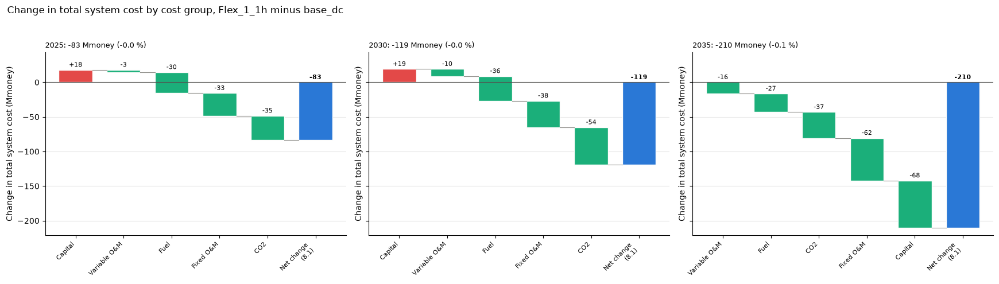

Change in total system cost by cost group (Mmoney, scenario - base)


Year,2025,2030,2035
Group,,,
Capital,17.9,19.1,-67.8
Fixed O&M,-32.7,-38.3,-61.5
Variable O&M,-3.4,-10.3,-16.4
Fuel,-30.2,-35.6,-26.8
CO2,-34.6,-53.7,-37.3
Net change,-83.0,-118.8,-209.9
Additional exogenous demand (TWh),0.0,0.0,0.0
Net change per MWh of additional exogenous demand (Money/MWh),NaN,NaN,NaN


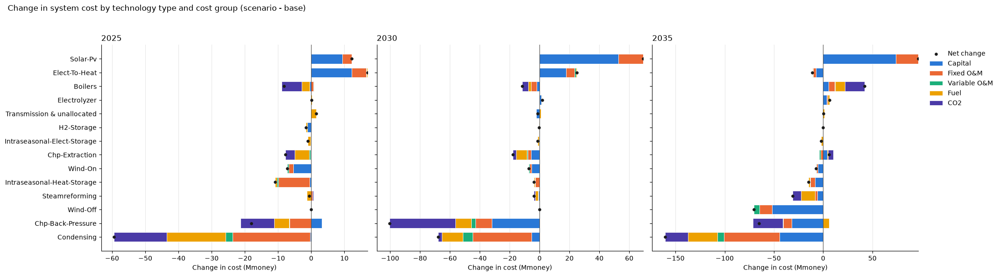

Change in system cost by technology type, 2035 (Mmoney, scenario - base)


Group,Capital,Fixed O&M,Variable O&M,Fuel,CO2,Net
Solar-Pv,73.6,23.1,0.0,0.0,0.0,96.7
Elect-To-Heat,-7.3,-2.7,-0.7,-0.2,0.0,-10.9
Boilers,5.7,6.2,0.2,10.0,19.9,41.9
Electrolyzer,3.5,1.1,0.0,1.8,0.0,6.4
Transmission & unallocated,-0.6,-0.0,0.0,1.2,-0.0,0.5
H2-Storage,-0.4,-0.0,0.0,0.1,0.0,-0.3
Intraseasonal-Elect-Storage,0.0,0.0,-0.2,-1.7,0.0,-1.9
Chp-Extraction,3.9,-2.3,-1.6,0.9,5.2,6.1
Wind-On,-5.4,-1.4,-0.6,0.0,0.0,-7.4
Intraseasonal-Heat-Storage,-8.2,-4.9,-0.6,-1.2,0.0,-14.8


In [65]:
# 10.3 Decomposition of the change in total system cost (Mmoney): by cost group (waterfall) and by technology type
COST_ORDER = ["Capital", "Fixed O&M", "Variable O&M", "Fuel", "CO2", "Other"]
ECO_SUBCATEGORY = {"GENERATION_CAPITAL_COSTS": "Capital", "GENERATION_FIXED_COSTS": "Fixed O&M", "GENERATION_OPERATIONAL_COSTS": "Variable O&M",
                   "GENERATION_FUEL_COSTS": "Fuel", "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2"}

def cost_by_group(results, scenario):
    t = scenario_result(results, scenario, "OBJ_YCR").assign(Year=lambda d: d["Year"].astype(str))
    t["Group"] = t["Category"].map(COST_GROUP).fillna("Other")
    return t.groupby(["Year", "Group"])["Value"].sum().unstack("Group", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

def cost_by_technology(results, scenario):
    t = scenario_result(results, scenario, "ECO_G_YCRAG").assign(Year=lambda d: d["Year"].astype(str))
    t = t.loc[t["Category"].eq("COSTS")]
    t["Group"] = t["Subcategory"].map(ECO_SUBCATEGORY).fillna("Other")
    return t.groupby(["Year", "Technology", "Group"])["Value"].sum()

d_cost = cost_by_group(res, SCENARIO).sub(cost_by_group(base_res, BASE_SCENARIO), fill_value=0).fillna(0)
groups = [g for g in COST_ORDER if g in d_cost.columns]
cost_years = [y for y in COMPARISON_YEARS if d_cost.loc[y].abs().max() > 1e-6]
group_colors = {**COST_COLORS, "Other": GREY}

if not cost_years:
    print("The total system cost is identical in both scenarios in all comparison years")
else:
    # --- Waterfall by cost group -----------------------------------------------------------------------------------
    fig, axes = plt.subplots(1, len(cost_years), figsize=(5.5 * len(cost_years) + 1, 5), sharey=True, squeeze=False)
    for ax, year in zip(axes.ravel(), cost_years):
        row = d_cost.loc[year, groups]
        steps = sorted([g for g in groups if abs(row[g]) >= 0.5], key=lambda g: -row[g])    # largest increase first
        level, x = 0.0, -1
        for x, g in enumerate(steps):
            v = row[g]
            ax.bar(x, v, bottom=level, color="#e34948" if v >= 0 else "#1baf7a", width=0.7, edgecolor="#fcfcfb")
            ax.annotate(f"{v:+,.0f}", (x, level + max(v, 0)), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
            if x:
                ax.plot([x - 0.65, x - 0.35], [level, level], color="#8a8984", linewidth=0.8)
            level += v
        ax.plot([x + 0.35, x + 0.65], [level, level], color="#8a8984", linewidth=0.8)
        ax.bar(x + 1, level, color="#2a78d6", width=0.7, edgecolor="#fcfcfb")
        ax.annotate(f"{level:+,.0f}", (x + 1, max(level, 0)), ha="center", va="bottom", fontsize=8, fontweight="bold", xytext=(0, 2), textcoords="offset points")
        ax.set_xticks(range(len(steps) + 1))
        ax.set_xticklabels(steps + ["Net change\n(8.1)"], rotation=45, ha="right", fontsize=8)
        ax.axhline(0, color="#52514e", linewidth=0.8)
        base_total = cost_by_group(base_res, BASE_SCENARIO).loc[year].sum()
        d_exo = d_dem.loc[year, first] if year in d_dem.index else 0
        per_mwh = f"\n= {level / d_exo:.1f} Money per MWh of additional exogenous demand" if abs(d_exo) > 1e-6 else ""
        ax.set_title(f"{year}: {level:+,.0f} Mmoney ({level / base_total * 100:+.1f} %){per_mwh}", loc="left", fontsize=9)
        ax.set_ylabel("Change in total system cost (Mmoney)")
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    lo, hi = axes.ravel()[0].get_ylim()
    axes.ravel()[0].set_ylim(min(lo, 0), hi + 0.1 * (hi - lo))
    fig.suptitle(f"Change in total system cost by cost group, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    table = d_cost.loc[cost_years, groups].T
    table.loc["Net change"] = table.sum()
    table.loc["Additional exogenous demand (TWh)"] = [d_dem.loc[y, first] if y in d_dem.index else np.nan for y in cost_years]
    table.loc["Net change per MWh of additional exogenous demand (Money/MWh)"] = table.loc["Net change"] / table.loc["Additional exogenous demand (TWh)"].replace(0, np.nan)
    print("Change in total system cost by cost group (Mmoney, scenario - base)")
    display(table.round(1))

    # --- By technology type (generator-level costs) ------------------------------------------------------------------
    d_tech = cost_by_technology(res, SCENARIO).sub(cost_by_technology(base_res, BASE_SCENARIO), fill_value=0)
    fig, axes = plt.subplots(1, len(cost_years), figsize=(6.5 * len(cost_years) + 2, 6), sharey=True, squeeze=False)
    tech_tables = {}
    for year in cost_years:
        t = d_tech.xs(year, level="Year").unstack("Group", fill_value=0).reindex(columns=groups, fill_value=0)
        t.index = [clean_name(i) for i in t.index]
        t.loc["Transmission & unallocated"] = d_cost.loc[year, groups] - t.sum()                 # closes to OBJ_YCR
        tech_tables[year] = t
    techs = pd.Index(sorted(set().union(*[t.index[t.abs().sum(axis=1) >= 1] for t in tech_tables.values()])))
    techs = sum(t.reindex(techs, fill_value=0).sum(axis=1) for t in tech_tables.values()).sort_values().index   # largest increase on top
    y = np.arange(len(techs))
    for ax, year in zip(axes.ravel(), cost_years):
        t = tech_tables[year].reindex(techs, fill_value=0)
        pos, neg = np.zeros(len(t)), np.zeros(len(t))
        for g in groups:
            v = t[g].to_numpy(dtype=float)
            ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.7, color=group_colors[g], edgecolor="#fcfcfb", linewidth=0.6, label=g)
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
        ax.scatter(t.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8)
        ax.set_yticks(y); ax.set_yticklabels(techs)
        ax.set_title(str(year), loc="left"); ax.set_xlabel("Change in cost (Mmoney)")
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    axes.ravel()[-1].legend(*axes.ravel()[0].get_legend_handles_labels(), bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    fig.suptitle("Change in system cost by technology type and cost group (scenario - base)", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    last = cost_years[-1]
    t = tech_tables[last].reindex(techs[::-1], fill_value=0)
    print(f"Change in system cost by technology type, {last} (Mmoney, scenario - base)")
    display(t.assign(Net=t.sum(axis=1)).round(1))


### 10.4 CO2 emissions: base vs scenario
`EMI_YCRAG` (kton): total emissions per year, the split by fuel, and the countries with the largest change in the last common year.

,base_dc,Flex_1_1h,Change,Change (%)
Year,,,,
2025,128815.4,128502.3,-313.1,-0.2
2030,103999.9,103642.3,-357.6,-0.3
2035,91704.1,91551.0,-153.1,-0.2


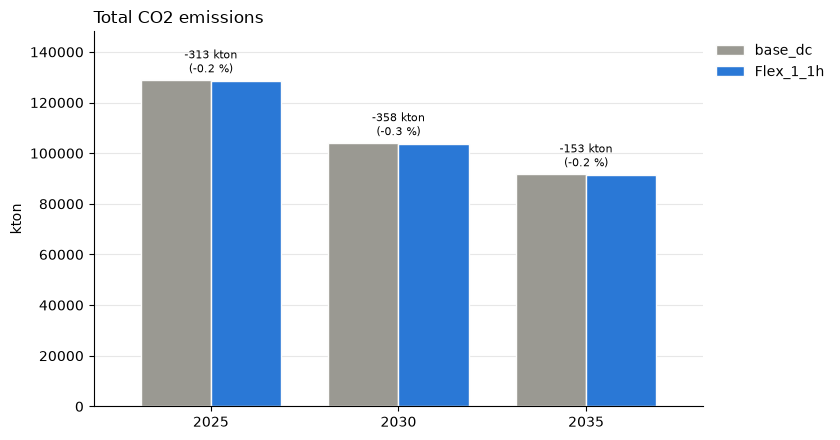

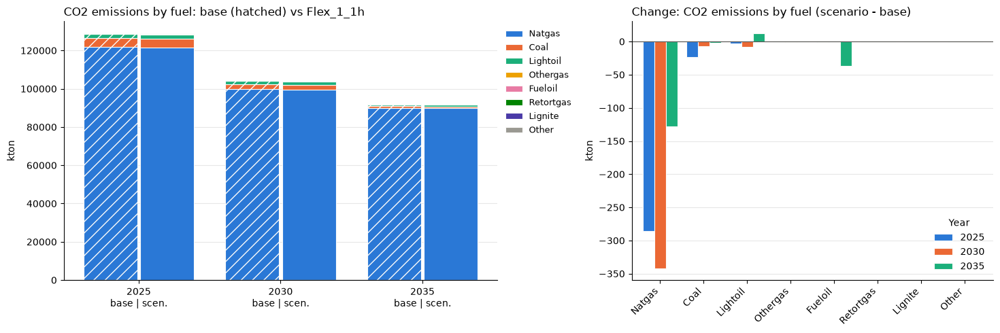

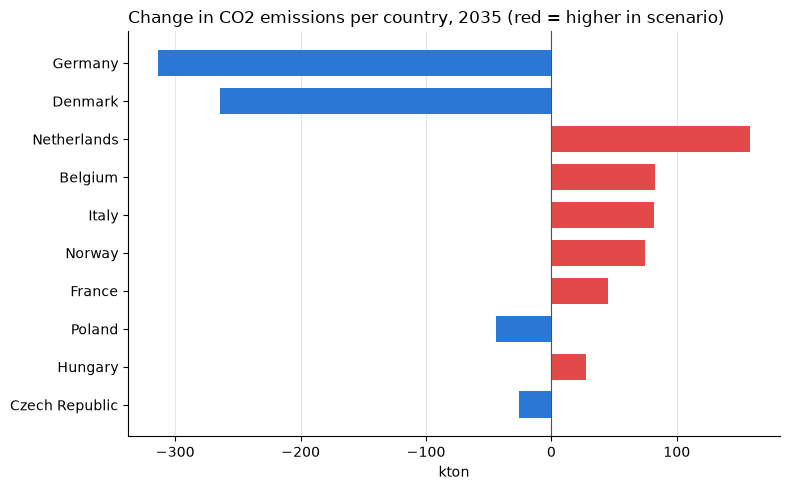

In [66]:
# 10.4 CO2 emissions comparison (kton)
emi_cmp = pd.DataFrame({BASE_SCENARIO: yearly_total(base_res, BASE_SCENARIO, "EMI_YCRAG"),
                        SCENARIO: yearly_total(res, SCENARIO, "EMI_YCRAG")})
emi_cmp["Change"] = emi_cmp[SCENARIO] - emi_cmp[BASE_SCENARIO]
emi_cmp["Change (%)"] = emi_cmp["Change"] / emi_cmp[BASE_SCENARIO].replace(0, np.nan) * 100
display(emi_cmp.round(1))

fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(COMPARISON_YEARS) + 4), 4.5))
emi_cmp[[BASE_SCENARIO, SCENARIO]].plot.bar(ax=ax, color=[SCEN_COLORS[BASE_SCENARIO], SCEN_COLORS[SCENARIO]], width=0.75, edgecolor="#fcfcfb")
for i, (change, pct) in enumerate(zip(emi_cmp["Change"], emi_cmp["Change (%)"])):
    top = emi_cmp[[BASE_SCENARIO, SCENARIO]].iloc[i].max()
    ax.annotate(f"{change:+,.0f} kton\n({pct:+.1f} %)", (i, top), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.tick_params(axis="x", rotation=0); ax.margins(y=0.15)
style(ax, "Total CO2 emissions", "kton")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1))
plt.tight_layout(); plt.show()

base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "EMI_YCRAG", "Fuel"), by_year(res, SCENARIO, "EMI_YCRAG", "Fuel"))
paired_stacked(base_t, scen_t, colors, "CO2 emissions by fuel", "kton")
country_change(last_year_by_country(base_res, BASE_SCENARIO, "EMI_YCRAG"), last_year_by_country(res, SCENARIO, "EMI_YCRAG"),
               f"Change in CO2 emissions per country, {LAST_YEAR} (red = higher in scenario)", "kton")

#### 10.4.1 Why do the emissions change?
The change in `EMI_YCRAG` (scenario - base, kton) is traced back in four steps:
1. **By end use**: each generator's emissions are allocated to the commodities it produces (electricity, heat, hydrogen) in proportion to its output (`PRO_YCRAGF`), so CHP emissions are shared between power and heat. The parts add up to the change in 10.4.
2. **By technology and fuel**: which plants emit more, next to the change in their fuel use (`F_CONS_YCRA`, TWh). A change in emissions with the same fuel use would point to a change in emission intensity (e.g. CCS), otherwise it is a change in activity.
3. **How the extra electricity was supplied** (system-wide): the change in electricity generation per fuel, the CO2 intensity of each fuel's electricity in the scenario (kg/MWh = kton/TWh) and the resulting change in CO2, with the average CO2 content of the additional electricity demand.
4. **By country** (last common year): where the emissions change, with the change in electricity demand, the part from data centres and the change in fossil electricity generation.

1. Change in CO2 emissions by end use (kton, scenario - base)


,Electricity,Heat,Hydrogen,Total,Total (8.3)
Year,,,,,
2025,-209.2,-111.1,7.2,-313.1,-313.1
2030,-164.5,-190.5,-2.7,-357.6,-357.6
2035,-158.0,27.1,-22.2,-153.1,-153.1


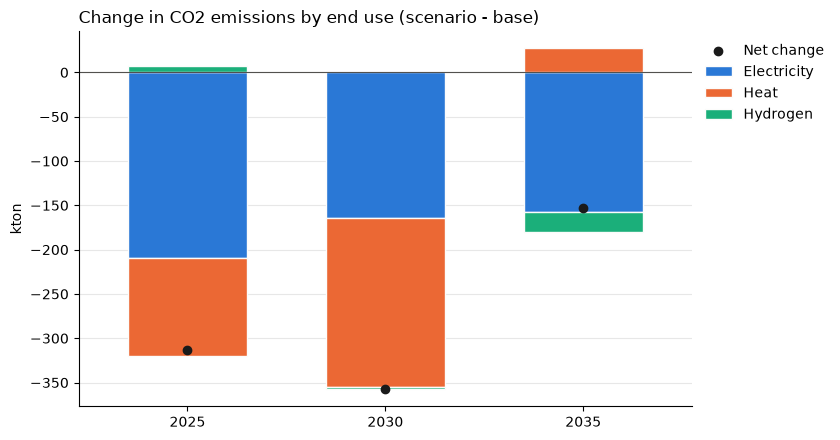

2. Change in CO2 emissions and fuel use by technology and fuel (scenario - base), largest changes in the last year first


CO2 (kton)                 Fuel use (TWh)        \
Year                              2025    2030    2035           2025  2030   
Technology        Fuel                                                        
CHP-BACK-PRESSURE NATGAS        -59.49 -314.19 -176.20          -0.29 -1.56   
BOILERS           NATGAS        -61.82  -13.28  104.83          -0.31 -0.07   
CONDENSING        NATGAS       -145.72  -10.20  -47.82          -0.72 -0.30   
                  FUELOIL         0.00    0.00  -36.08           0.00  0.00   
STEAMREFORMING    NATGAS          7.16   -2.68  -22.25          -0.06 -0.13   
CHP-EXTRACTION    NATGAS        -25.82   -1.55   13.86          -0.13 -0.43   
BOILERS           LIGHTOIL       -2.68   -8.34   12.80          -0.01 -0.03   
                  COAL            9.41   -6.57   -1.51           0.03 -0.02   
                  FUELOIL        -0.68    0.00   -0.76          -0.00  0.00   
CHP-BACK-PRESSURE COAL          -33.18    0.00    0.00          -0.10  0.00   
                  LIGHTOIL        0.13    0.26    0.00           0.00  0.00   
                  OTHERGAS       -0.09   -1.10    0.00          -0.00 -0.00   
CONDENSING        LIGHTOIL       -0.15    0.01    0.00          -0.00  0.00   
                  RETORTGAS      -0.15    0.00    0.00          -0.00  0.00   

                                   
Year                         2035  
Technology        Fuel             
CHP-BACK-PRESSURE NATGAS    -0.87  
BOILERS           NATGAS     0.52  
CONDENSING        NATGAS    -2.28  
                  FUELOIL   -0.14  
STEAMREFORMING    NATGAS    -1.10  
CHP-EXTRACTION    NATGAS     0.69  
BOILERS           LIGHTOIL   0.05  
                  COAL      -0.00  
                  FUELOIL   -0.00  
CHP-BACK-PRESSURE COAL       0.00  
                  LIGHTOIL   0.00  
                  OTHERGAS   0.00  
CONDENSING        LIGHTOIL   0.00  
                  RETORTGAS  0.00

3. How the change in electricity demand was supplied, 2025: demand -0.37 TWh, generation -0.70 TWh, CO2 from electricity -209.2 kton = 561 kg CO2 per additional MWh of demand


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Sun,0.41,0.00,0.00
Water,0.07,0.00,0.00
Nuclear,0.02,0.00,0.00
Woodchips,0.02,0.00,0.00
Lightoil,-0.00,348.13,-0.09
Retortgas,-0.00,817.92,-0.15
Othergas,-0.00,266.80,-0.07
Biogas,-0.02,0.00,0.00
Wood,-0.03,0.00,0.00
Coal,-0.05,340.56,-16.59


3. How the change in electricity demand was supplied, 2030: demand -0.03 TWh, generation -0.35 TWh, CO2 from electricity -164.5 kton = 5819 kg CO2 per additional MWh of demand


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Sun,2.51,0.00,0.00
Woodchips,0.15,0.00,0.00
Muniwaste,0.02,0.00,0.00
Biogas,0.01,0.00,0.00
Lightoil,0.00,526.16,0.13
Othergas,-0.00,266.80,-0.81
Wood,-0.02,0.00,0.00
Onshore wind,-0.29,0.00,0.00
Electric,-0.33,0.00,0.00
Natgas,-1.10,253.33,-163.82


3. How the change in electricity demand was supplied, 2035: demand -0.46 TWh, generation -0.86 TWh, CO2 from electricity -158.0 kton = 345 kg CO2 per additional MWh of demand


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Sun,3.27,0.00,0.00
Woodchips,0.09,0.00,0.00
Biogas,0.04,0.00,0.00
Woodwaste,-0.01,0.00,0.00
Muniwaste,-0.02,0.00,0.00
Nuclear,-0.02,0.00,0.00
Fueloil,-0.04,795.37,-36.08
Wood,-0.06,0.00,0.00
Onshore wind,-0.30,0.00,0.00
Electric,-0.39,0.00,0.00


4. Change in CO2 emissions per country, 2035 (scenario - base), the 15 largest absolute changes


,CO2 total (kton),CO2 electricity (kton),CO2 heat (kton),CO2 hydrogen (kton),Electricity demand (TWh),of which data centres (TWh),Fossil electricity (TWh)
Germany,-313.94,-66.22,-69.01,-178.71,-0.62,0.0,0.19
Denmark,-264.11,-16.89,-14.17,-233.05,-0.92,0.0,-0.08
Netherlands,158.67,-31.70,-20.75,211.12,0.92,0.0,-0.59
Belgium,82.73,37.25,45.36,0.12,-0.06,0.0,0.17
Italy,82.16,17.66,62.22,2.28,-0.26,0.0,-0.72
Norway,74.48,0.00,-1.53,76.01,0.29,0.0,0.00
France,44.93,-1.04,16.52,29.45,-0.19,0.0,-0.00
Poland,-44.54,-16.76,-16.59,-11.19,0.19,0.0,-0.09
Hungary,27.32,4.72,3.99,18.61,0.05,0.0,0.03
Czech Republic,-25.90,-13.42,-12.41,-0.07,0.02,0.0,-0.10


In [67]:
# 10.4.1 Decomposition of the change in CO2 emissions (kton): end use, technology and fuel, electricity supply, country
FOSSIL_FUELS = ["NATGAS", "COAL", "LIGHTOIL", "FUELOIL", "LIGNITE", "OTHERGAS"]
KEYS = ["Year", "Region", "Area", "Generation"]

def emissions_by_use(results, scenario):
    """EMI_YCRAG allocated to the output commodities of each generator, in proportion to its output (kton)."""
    e = scenario_result(results, scenario, "EMI_YCRAG").assign(Year=lambda d: d["Year"].astype(str))
    pro = scenario_result(results, scenario, "PRO_YCRAGF").assign(Year=lambda d: d["Year"].astype(str))
    pro = pro.groupby(KEYS + ["Commodity"])["Value"].sum()
    share = (pro / pro.groupby(level=KEYS).transform("sum").replace(0, np.nan)).rename("Share").reset_index()
    out = e.merge(share, on=KEYS, how="left")
    out["Commodity"] = out["Commodity"].fillna("OTHER")
    out["Value"] = out["Value"] * out["Share"].fillna(1)
    return out.loc[out["Year"].isin(COMPARISON_YEARS)]

emi_use = {BASE_SCENARIO: emissions_by_use(base_res, BASE_SCENARIO), SCENARIO: emissions_by_use(res, SCENARIO)}
def emi_change(by):
    return (emi_use[SCENARIO].groupby(by)["Value"].sum().sub(emi_use[BASE_SCENARIO].groupby(by)["Value"].sum(), fill_value=0))

# --- 1. End use --------------------------------------------------------------------------------------------------
by_use = emi_change(["Year", "Commodity"]).unstack("Commodity", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)
by_use.columns = [c.title() for c in by_use.columns]
by_use["Total"] = by_use.sum(axis=1)
by_use["Total (8.3)"] = emi_cmp["Change"].reindex(by_use.index)
print("1. Change in CO2 emissions by end use (kton, scenario - base)")
display(by_use.round(1))

fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(COMPARISON_YEARS) + 4), 4.5))
use_cols = [c for c in by_use.columns if c not in ("Total", "Total (8.3)")]
use_colors = {"Electricity": "#2a78d6", "Heat": "#eb6834", "Hydrogen": "#1baf7a", "Other": GREY}
by_use[use_cols].plot.bar(ax=ax, stacked=True, color=[use_colors.get(c, GREY) for c in use_cols], width=0.6, edgecolor="#fcfcfb")
ax.scatter(range(len(by_use)), by_use["Total"], color="#1a1a1a", zorder=3, label="Net change")
ax.axhline(0, color="#52514e", linewidth=0.8); ax.tick_params(axis="x", rotation=0)
style(ax, "Change in CO2 emissions by end use (scenario - base)", "kton")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1))
plt.tight_layout(); plt.show()

# --- 2. Technology and fuel ----------------------------------------------------------------------------------------
fuel_use = lambda r, s: (scenario_result(r, s, "F_CONS_YCRA").assign(Year=lambda d: d["Year"].astype(str))
                         .groupby(["Year", "Technology", "Fuel"])["Value"].sum())
d_fuel = fuel_use(res, SCENARIO).sub(fuel_use(base_res, BASE_SCENARIO), fill_value=0)
tech_fuel = pd.concat({"CO2 (kton)": emi_change(["Year", "Technology", "Fuel"]).unstack("Year"),
                       "Fuel use (TWh)": d_fuel.unstack("Year")}, axis=1).fillna(0)
tech_fuel = tech_fuel.loc[tech_fuel["CO2 (kton)"].abs().max(axis=1) > 0.05]
tech_fuel = tech_fuel.reindex(tech_fuel[("CO2 (kton)", COMPARISON_YEARS[-1])].abs().sort_values(ascending=False).index)
tech_fuel = tech_fuel.reindex(columns=[(q, y) for q in ("CO2 (kton)", "Fuel use (TWh)") for y in COMPARISON_YEARS], fill_value=0)
print("2. Change in CO2 emissions and fuel use by technology and fuel (scenario - base), largest changes in the last year first")
display(tech_fuel.round(2))

# --- 3. How the additional electricity was supplied (system-wide) ---------------------------------------------------
def el_generation(results, scenario):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Commodity"].eq("ELECTRICITY")].assign(Year=lambda d: d["Year"].astype(str))
    return t.groupby(["Year", "Fuel"])["Value"].sum()

el_emi = lambda s: emi_use[s].loc[emi_use[s]["Commodity"].eq("ELECTRICITY")].groupby(["Year", "Fuel"])["Value"].sum()
gen_s, gen_b = el_generation(res, SCENARIO), el_generation(base_res, BASE_SCENARIO)
supply = pd.DataFrame({"Generation change (TWh)": gen_s.sub(gen_b, fill_value=0),
                       "CO2 intensity, scenario (kg/MWh)": el_emi(SCENARIO).reindex(gen_s.index).fillna(0) / gen_s.replace(0, np.nan),
                       "CO2 change (kton)": el_emi(SCENARIO).sub(el_emi(BASE_SCENARIO), fill_value=0)}).fillna(0)
d_demand = yearly_total(res, SCENARIO, "EL_DEMAND_YCR") - yearly_total(base_res, BASE_SCENARIO, "EL_DEMAND_YCR")
for year in COMPARISON_YEARS:
    t = supply.xs(year, level="Year")
    t = t.loc[(t["Generation change (TWh)"].abs() > 0.01) | (t["CO2 change (kton)"].abs() > 0.05)]
    t = t.sort_values("Generation change (TWh)", ascending=False)
    t.index = [clean_name(f) for f in t.index]
    t.loc["Total"] = [t["Generation change (TWh)"].sum(), np.nan, t["CO2 change (kton)"].sum()]
    d_el_co2 = t.loc["Total", "CO2 change (kton)"]
    print(f"3. How the change in electricity demand was supplied, {year}: demand {d_demand[year]:+.2f} TWh, "
          f"generation {t.loc['Total', 'Generation change (TWh)']:+.2f} TWh, "
          f"CO2 from electricity {d_el_co2:+.1f} kton"
          + (f" = {d_el_co2 / d_demand[year]:.0f} kg CO2 per additional MWh of demand" if abs(d_demand[year]) > 1e-6 else ""))
    display(t.round(2))

# --- 4. Country (last common year) ---------------------------------------------------------------------------------
region_country = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
last = lambda t: t.xs(LAST_YEAR, level="Year") if LAST_YEAR in t.index.get_level_values("Year") else t.iloc[:0].droplevel("Year")
emi_country = last(emi_change(["Year", "Country", "Commodity"])).unstack("Commodity", fill_value=0)
emi_country.columns = [f"CO2 {c.lower()} (kton)" for c in emi_country.columns]
fossil_gen = lambda r, s: (scenario_result(r, s, "PRO_YCRAGF")
                          .loc[lambda d: d["Year"].astype(str).eq(LAST_YEAR) & d["Commodity"].eq("ELECTRICITY") & d["Fuel"].isin(FOSSIL_FUELS)]
                          .groupby("Country")["Value"].sum())
country_emi = pd.concat([
    emi_country.sum(axis=1).rename("CO2 total (kton)"),
    emi_country,
    (last_year_by_country(res, SCENARIO, "EL_DEMAND_YCR") - last_year_by_country(base_res, BASE_SCENARIO, "EL_DEMAND_YCR")).rename("Electricity demand (TWh)"),
    datacenter_demand(SCENARIO_DIR, LAST_YEAR, region_country).sub(datacenter_demand(BASE_DIR, LAST_YEAR, region_country), fill_value=0).rename("of which data centres (TWh)"),
    fossil_gen(res, SCENARIO).sub(fossil_gen(base_res, BASE_SCENARIO), fill_value=0).rename("Fossil electricity (TWh)"),
], axis=1).fillna(0)
country_emi = country_emi.loc[country_emi["CO2 total (kton)"].abs().sort_values(ascending=False).index].head(15)
country_emi.index = [clean_name(c) for c in country_emi.index]
print(f"4. Change in CO2 emissions per country, {LAST_YEAR} (scenario - base), the 15 largest absolute changes")
display(country_emi.round(2))


#### 10.4.2 CO2 emissions per technology type and the commodity it produces (7.1.1) in `FOCUS_YEAR`: base vs scenario

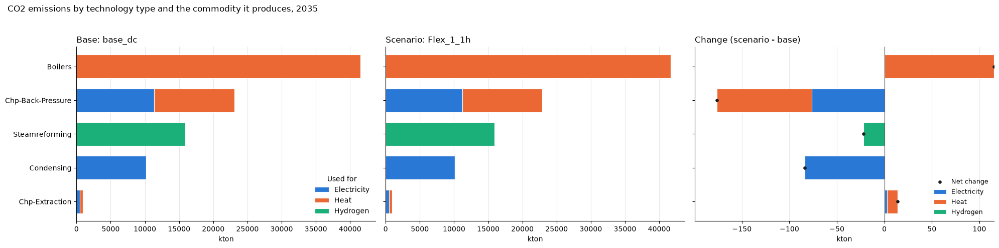

CO2 emissions by technology type and use, 2035 (kton)


Base                               Scenario           \
Use               Electricity     Heat Hydrogen    Total Electricity     Heat   
Technology                                                                      
Boilers                   0.0  41550.5      0.0  41550.5         0.0  41665.8   
Chp-Back-Pressure     11319.1  11766.8      0.0  23085.9     11242.4  11667.3   
Steamreforming            0.0      0.0  15930.5  15930.5         0.0      0.0   
Condensing            10184.1      0.0      0.0  10184.1     10100.2      0.0   
Chp-Extraction          497.4    455.8      0.0    953.2       500.0    467.1   
Total                 22000.6  53773.0  15930.5  91704.1     21842.6  53800.2   

                                         Change                         
Use               Hydrogen    Total Electricity   Heat Hydrogen  Total  
Technology                                                              
Boilers                0.0  41665.8         0.0  115.4      0.0  115.4  
Chp-Back-Pressure      0.0  22909.7       -76.7  -99.5      0.0 -176.2  
Steamreforming     15908.2  15908.2         0.0    0.0    -22.2  -22.2  
Condensing             0.0  10100.2       -83.9    0.0      0.0  -83.9  
Chp-Extraction         0.0    967.0         2.6   11.3      0.0   13.9  
Total              15908.2  91551.0      -158.0   27.1    -22.2 -153.1

In [68]:
# 10.4.2 CO2 emissions per technology type, split by the commodity it produces (as 7.1.1), in FOCUS_YEAR: base vs scenario (kton)
# Uses emissions_by_use of 10.4.1 (emissions allocated to the output commodities in proportion to the output) and USE_COLORS of 7.1.1
def tech_by_use(results, scenario):
    e = emissions_by_use(results, scenario)
    e = e.loc[e["Year"].eq(FOCUS_YEAR)].assign(Use=lambda d: d["Commodity"].str.title())
    return e.groupby(["Technology", "Use"])["Value"].sum().unstack("Use", fill_value=0)

use_b, use_s = tech_by_use(base_res, BASE_SCENARIO), tech_by_use(res, SCENARIO)
techs = use_b.index.union(use_s.index)
uses = [u for u in USE_COLORS if u in use_b.columns.union(use_s.columns)]
use_b, use_s = use_b.reindex(index=techs, columns=uses, fill_value=0), use_s.reindex(index=techs, columns=uses, fill_value=0)
use_d = use_s - use_b
techs = pd.concat([use_b.sum(axis=1), use_s.sum(axis=1)], axis=1).max(axis=1).sort_values().index    # largest emitter on top
y = np.arange(len(techs))

fig, axes = plt.subplots(1, 3, figsize=(20, 0.5 * len(techs) + 2.5), sharey=True)
x_max = max(use_b.sum(axis=1).max(), use_s.sum(axis=1).max()) * 1.05
panels = [(axes[0], use_b, f"Base: {BASE_SCENARIO}", False), (axes[1], use_s, f"Scenario: {SCENARIO}", False),
          (axes[2], use_d, "Change (scenario - base)", True)]
for ax, t, title, is_change in panels:
    t = t.reindex(techs)
    pos, neg = np.zeros(len(t)), np.zeros(len(t))
    for u in uses:
        v = t[u].to_numpy(dtype=float)
        ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.7, color=USE_COLORS[u], edgecolor="#fcfcfb", linewidth=0.8, label=u)
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    if is_change:
        ax.scatter(t.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8); ax.margins(x=0.08)
    else:
        ax.set_xlim(0, x_max)                                                # base and scenario on the same scale
    ax.set_yticks(y); ax.set_yticklabels([clean_name(c) for c in techs])
    style(ax, title, "", axis="x"); ax.set_xlabel("kton")
axes[0].legend(*axes[0].get_legend_handles_labels(), title="Used for", loc="lower right", frameon=False)
axes[2].legend(*axes[2].get_legend_handles_labels(), loc="lower right", frameon=False, fontsize=9)
fig.suptitle(f"CO2 emissions by technology type and the commodity it produces, {FOCUS_YEAR}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

table = pd.concat({"Base": use_b, "Scenario": use_s, "Change": use_d}, axis=1).reindex(techs[::-1])
for run, t in [("Base", use_b), ("Scenario", use_s), ("Change", use_d)]:
    table[(run, "Total")] = t.reindex(techs[::-1]).sum(axis=1)
table = table.reindex(columns=[(run, u) for run in ("Base", "Scenario", "Change") for u in uses + ["Total"]])
table.loc["Total"] = table.sum()
print(f"CO2 emissions by technology type and use, {FOCUS_YEAR} (kton)")
display(table.rename(index=clean_name).round(1))

## 11. Country level: base vs scenario
Where the changes happen, in the order capacity, dispatch, CO2 emissions and cost.

### 11.1 Map of the changes in installed capacity and transmission
The geographical counterpart of 4.4, showing scenario - base in `MAP_YEAR` (default: last common year) for `MAP_COMMODITY`:
- **Background**: net change in installed capacity per region (GW, red = more capacity in the scenario).
- **Pies**: gross change per region by fuel. Pie area is proportional to the sum of the absolute changes; each wedge is one fuel's share of it, and hatched wedges are decreases. Fuel colours are those of 10.1.
- **Lines**: change in transmission. With `MAP_LINES = "auto"` the map shows the change in transmission capacity, or, when the capacities are identical in both runs (e.g. no transmission investment), the change in the annual net flow between the two regions, with the arrow pointing in the direction of the additional flow.
Lines are drawn straight between region centres (pybalmorel's `coordinates_RRR.csv`), without the bypass hooks of 4.4.

Lines show the change in transmission annual net flow (TWh); 98 region pairs changed, 60 drawn (>= 5% of the largest change)


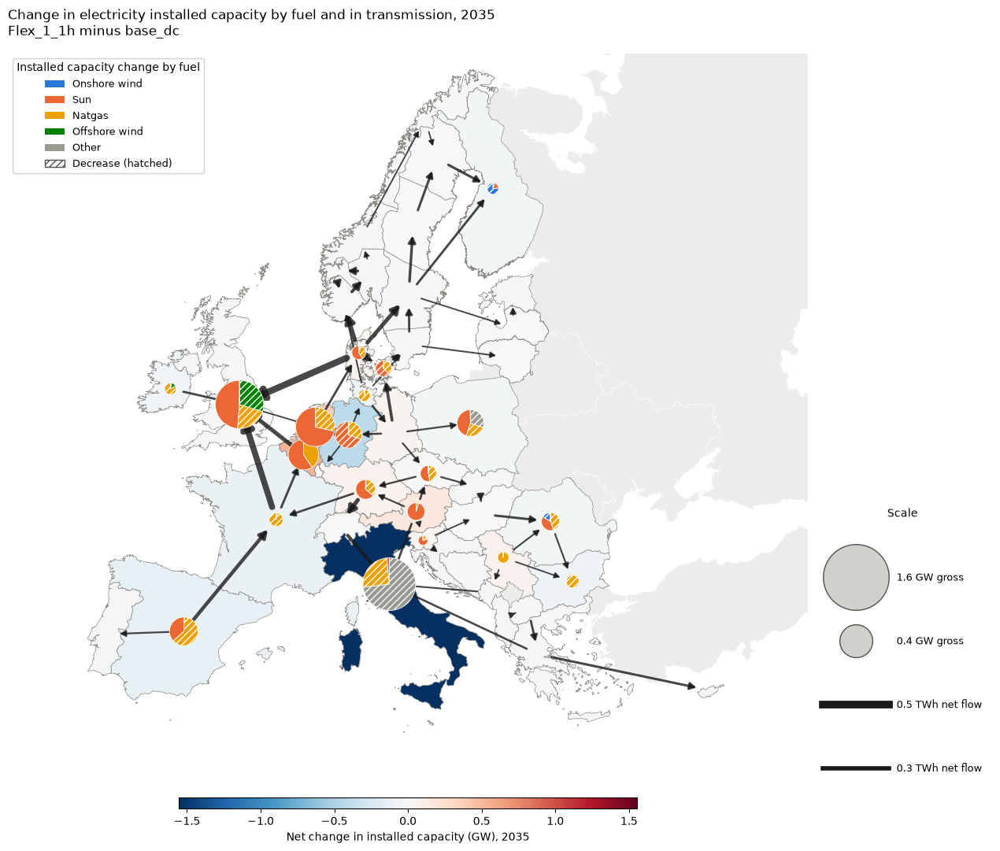

Fuel,WIND_ONSHORE,SUN,WATER,NATGAS,NUCLEAR,WIND_OFFSHORE,ELECTRIC,Other,Net,Gross
Region,,,,,,,,,,
IT,0.00,0.03,0.0,-0.40,0.0,0.0,0.0,-1.17,-1.55,1.61
UK,0.00,0.66,0.0,-0.29,0.0,-0.4,0.0,0.00,-0.02,1.35
NL,0.00,0.64,0.0,-0.25,0.0,0.0,0.0,-0.00,0.38,0.89
BE,0.00,0.32,0.0,0.22,0.0,0.0,0.0,-0.00,0.54,0.54
ES,0.00,0.17,0.0,-0.30,0.0,0.0,0.0,-0.00,-0.13,0.47
DE4-W,0.00,-0.29,0.0,-0.12,0.0,0.0,0.0,0.00,-0.41,0.42
PL,-0.00,0.18,0.0,-0.10,0.0,0.0,0.0,-0.13,-0.05,0.41
DE4-S,0.00,0.14,0.0,-0.08,0.0,0.0,0.0,-0.00,0.06,0.22
RO,-0.03,0.07,0.0,-0.08,0.0,0.0,0.0,0.00,-0.04,0.19


Largest transmission changes (TWh, positive = first region -> second region for flows):


,,Change
BE,NL,0.54
DK1,UK,0.44
FR,UK,0.40
DK1,NO2,0.25
CH,DE4-S,-0.24
BE,UK,0.24
DK1,SE3,0.23
ES,FR,0.20
CH,IT,0.18
NO1,NO2,-0.17


In [69]:
# 11.1 Map of the changes (scenario - base) in installed capacity by fuel and in transmission
import geopandas as gpd
import pybalmorel
from matplotlib.patches import Wedge, Patch, FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm

MAP_YEAR = LAST_YEAR                 # any of COMPARISON_YEARS, as a string
MAP_COMMODITY = "ELECTRICITY"        # "ELECTRICITY" or "HYDROGEN" (selects X_* or XH2_* for the lines)
MAP_LINES = "auto"                   # "Capacity", "Flow" or "auto"
MIN_CHANGE = 0.05                    # GW of gross change below which a region gets no pie
MIN_LINE_SHARE = 0.05                # lines changing less than this share of the largest line change are not drawn
CRS = "EPSG:3035"                    # equal-area projection for Europe, so pies stay round

GEO_DIR = Path(pybalmorel.__file__).parent / "geofiles"
polygons = gpd.read_file(GEO_DIR / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs(CRS)
centres = pd.read_csv(GEO_DIR / "coordinates_RRR.csv").drop_duplicates("RRR")
centres = gpd.GeoSeries(gpd.points_from_xy(centres["Lon"], centres["Lat"]), index=centres["RRR"], crs="EPSG:4326").to_crs(CRS)
xy = {r: (p.x, p.y) for r, p in centres.items()}

# Capacity change per region and fuel, with the fuels folded as in 10.1 (same colours)
def region_capacity(results, scenario):
    t = scenario_result(results, scenario, "G_CAP_YCRAF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Region", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

cap_change = region_capacity(res, SCENARIO).sub(region_capacity(base_res, BASE_SCENARIO), fill_value=0)
_, _, fuel_colors = align(by_year(base_res, BASE_SCENARIO, "G_CAP_YCRAF", "Fuel", MAP_COMMODITY),
                          by_year(res, SCENARIO, "G_CAP_YCRAF", "Fuel", MAP_COMMODITY))
keep = [f for f in fuel_colors if f != "Other"]
cap_change = cap_change.reindex(columns=cap_change.columns.union(keep), fill_value=0)
cap_change = cap_change[keep].assign(Other=cap_change.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else cap_change[keep]
net_change = cap_change.sum(axis=1)
gross_change = cap_change.abs().sum(axis=1)

# Transmission change per region pair: capacity (largest of the two directions) or net flow from the first to the second region
X_SYMBOLS = {"ELECTRICITY": ("X_CAP_YCR", "X_FLOW_YCR"), "HYDROGEN": ("XH2_CAP_YCR", "XH2_FLOW_YCR")}[MAP_COMMODITY]

def pair_values(results, scenario, symbol, net):
    t = scenario_result(results, scenario, symbol)
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR)].groupby(["From", "To"])["Value"].sum()
    out = {}
    for (a, b), v in t.items():
        key, sign = ((a, b), 1) if a < b else ((b, a), -1)
        out[key] = out.get(key, 0) + sign * v if net else max(out.get(key, 0), v)
    return pd.Series(out, dtype=float)

def pair_change(symbol, net):
    s, b = pair_values(res, SCENARIO, symbol, net), pair_values(base_res, BASE_SCENARIO, symbol, net)
    return s.sub(b, fill_value=0)

line_mode = MAP_LINES
if line_mode == "auto":
    line_mode = "Capacity" if pair_change(X_SYMBOLS[0], net=False).abs().max() > 1e-3 else "Flow"
line_change = pair_change(X_SYMBOLS[0], net=False) if line_mode == "Capacity" else pair_change(X_SYMBOLS[1], net=True)
line_unit = "GW" if line_mode == "Capacity" else "TWh"
n_changed = int((line_change.abs() > 1e-3).sum())
line_change = line_change[line_change.abs() >= MIN_LINE_SHARE * line_change.abs().max()] if n_changed else line_change.iloc[:0]
print(f"Lines show the change in transmission {'capacity' if line_mode == 'Capacity' else 'annual net flow'} ({line_unit}); "
      f"{n_changed} region pairs changed, {len(line_change)} drawn (>= {MIN_LINE_SHARE:.0%} of the largest change)")

# --- Map (also used for the change in dispatch in 11.2) ------------------------------------------------------
def pie_change_map(change, unit, min_change, lines, line_mode, line_unit, what, colors=None, commodity=None):
    """Map of a change per region and fuel (`change`: region x fuel, in `unit`): background = net change,
    pies = gross change by fuel (hatched = decrease), lines = change in transmission (`lines`, as above).
    `colors` (fuel -> colour) and `commodity` default to fuel_colors and MAP_COMMODITY of this cell."""
    colors = colors if colors is not None else fuel_colors
    commodity = commodity if commodity is not None else MAP_COMMODITY
    net, gross = change.sum(axis=1), change.abs().sum(axis=1)
    fig, ax = plt.subplots(figsize=(13, 12))
    in_model = polygons["id"].isin(net.index)
    polygons[~in_model].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    lim = max(net.abs().max(), 1e-6)
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    model_polys = polygons[in_model].assign(net=lambda d: d["id"].map(net).fillna(0))
    model_polys.plot(ax=ax, column="net", cmap="RdBu_r", norm=norm, edgecolor="#8a8984", linewidth=0.5)

    # Transmission: width proportional to the change, solid = increase, dashed = decrease (capacity);
    # for flows the arrow points to where the additional net flow goes
    max_line = lines.abs().max() if len(lines) else 1
    for (a, b), v in lines.items():
        if a not in xy or b not in xy:
            continue
        width = 1 + 6 * abs(v) / max_line
        (x0, y0), (x1, y1) = xy[a], xy[b]
        if line_mode == "Flow" and v < 0:                    # more net flow from b to a
            (x0, y0), (x1, y1) = (x1, y1), (x0, y0)
        style_kw = dict(color="#1a1a1a", linewidth=width, alpha=0.8, zorder=3)
        if line_mode == "Capacity":
            ax.plot([x0, x1], [y0, y1], linestyle="-" if v > 0 else "--", solid_capstyle="round", **style_kw)
        else:
            ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle=f"-|>,head_length={0.3 + 0.08 * width},head_width={0.15 + 0.05 * width}",
                                         shrinkA=12, shrinkB=12, mutation_scale=10, **style_kw))

    # Pies of the gross change by fuel (area proportional to the gross change)
    R_MAX = 160e3                                            # radius in metres of the largest pie
    g_max = gross.max()
    for region, row in change.iterrows():
        if gross[region] < min_change or region not in xy:
            continue
        r = R_MAX * np.sqrt(gross[region] / g_max)
        start = 90.0
        for fuel, v in row.items():
            if abs(v) < 1e-9:
                continue
            sweep = 360 * abs(v) / gross[region]
            ax.add_patch(Wedge(xy[region], r, start, start + sweep, facecolor=colors[fuel], edgecolor="#fcfcfb",
                               linewidth=0.6, hatch="////" if v < 0 else None, zorder=4))
            start += sweep

    # Extent: the centres of the modelled regions plus a margin (polygon bounds would include e.g. the Azores)
    model_xy = np.array([xy[r] for r in model_polys["id"] if r in xy])
    ax.set_xlim(model_xy[:, 0].min() - 6e5, model_xy[:, 0].max() + 6e5); ax.set_ylim(model_xy[:, 1].min() - 4e5, model_xy[:, 1].max() + 4e5)
    ax.set_axis_off()
    ax.set_title(f"Change in {commodity.lower() if commodity.isupper() else commodity} {what} by fuel" + (" and in transmission" if len(lines) else "") + f", {MAP_YEAR}\n"
                 f"{SCENARIO} minus {BASE_SCENARIO}", loc="left")

    # Legends: fuels, pie size, lines, background
    fuel_handles = [Patch(facecolor=colors[f], label=clean_name(f)) for f in change.columns if change[f].abs().max() > 1e-9]
    fuel_handles.append(Patch(facecolor="white", edgecolor="#52514e", hatch="////", label="Decrease (hatched)"))
    leg1 = ax.legend(handles=fuel_handles, title=f"{what.capitalize()} change by fuel", loc="upper left", frameon=True, framealpha=0.9, fontsize=9)
    ax.add_artist(leg1)
    plt.tight_layout()
    pt_per_m = (ax.transData.transform((R_MAX, 0))[0] - ax.transData.transform((0, 0))[0]) * 72 / fig.dpi / R_MAX   # pies drawn to scale in the legend
    size_refs = [v for v in (g_max, g_max / 4) if v >= min_change]
    size_handles = [Line2D([], [], marker="o", linestyle="", markerfacecolor="#d0d0cc", markeredgecolor="#52514e",
                           markersize=2 * R_MAX * np.sqrt(v / g_max) * pt_per_m, label=f"{v:.1f} {unit} gross") for v in size_refs]
    if len(lines):
        for v in (max_line, max_line / 2):
            size_handles.append(Line2D([], [], color="#1a1a1a", linewidth=1 + 6 * v / max_line,
                                       label=f"{v:.1f} {line_unit} {'capacity' if line_mode == 'Capacity' else 'net flow'}"))
        if line_mode == "Capacity":
            size_handles.append(Line2D([], [], color="#1a1a1a", linestyle="--", linewidth=2, label="Decrease (dashed)"))
    max_marker = max([h.get_markersize() for h in size_handles if h.get_marker() == "o"], default=10)       # points
    ax.legend(handles=size_handles, title="Scale", loc="lower left", bbox_to_anchor=(1.0, 0.0), frameon=False, fontsize=9,
              labelspacing=max(1.4, 0.8 * max_marker / 9), handlelength=max(2, max_marker / 9), borderpad=1)
    sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm)
    fig.colorbar(sm, ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40, label=f"Net change in {what} ({unit}), {MAP_YEAR}")
    plt.tight_layout(); plt.show()

pie_change_map(cap_change, "GW", MIN_CHANGE, line_change, line_mode, line_unit, "installed capacity")

# The regions with the largest gross change, for reference
top = cap_change.loc[gross_change.sort_values(ascending=False).head(10).index]
display(top.assign(Net=net_change, Gross=gross_change).round(2))
if len(line_change):
    print(f"Largest transmission changes ({line_unit}, positive = first region -> second region for flows):")
    display(line_change.reindex(line_change.abs().sort_values(ascending=False).index).head(10).round(2).rename("Change").to_frame())

#### 11.1.1 Change in installed capacity by fuel per country (2030 and 2035)
Scenario - base installed capacity (GW) per country and fuel for `MAP_COMMODITY`, with the fuels folded and coloured as in the map above (and 10.1). Bars to the right are increases, bars to the left decreases; the black dot is the net change. Only countries with a change of at least `MIN_COUNTRY_CHANGE` GW (gross) are shown.

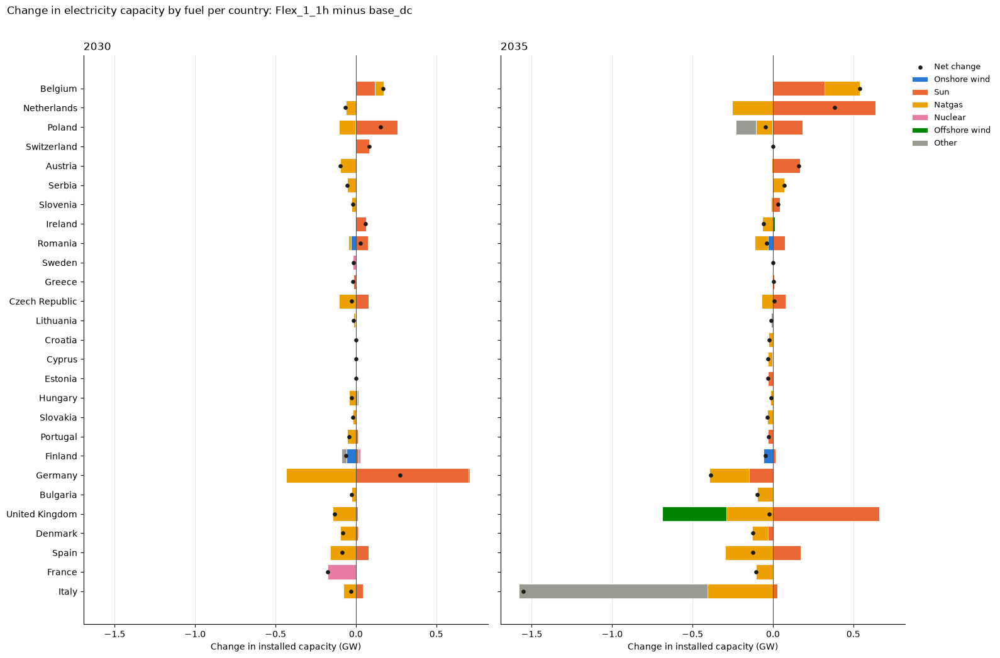

2030                                                 \
Fuel           Onshore wind   Sun Natgas Nuclear Offshore wind Other   Net   
BELGIUM                0.00  0.12   0.05    0.00           0.0 -0.00  0.17   
NETHERLANDS            0.00  0.00  -0.06    0.00           0.0 -0.01 -0.07   
POLAND                -0.00  0.26  -0.10    0.00           0.0  0.00  0.15   
SWITZERLAND            0.00  0.08  -0.00    0.00           0.0 -0.00  0.08   
AUSTRIA                0.00  0.00  -0.10    0.00           0.0 -0.00 -0.10   
SERBIA                 0.00  0.00  -0.05    0.00           0.0  0.00 -0.05   
SLOVENIA               0.00  0.01  -0.03    0.00           0.0  0.00 -0.02   
IRELAND                0.00  0.06  -0.00    0.00           0.0 -0.00  0.06   
ROMANIA               -0.03  0.08  -0.02    0.00           0.0  0.00  0.03   
SWEDEN                 0.00  0.00   0.00   -0.02           0.0  0.00 -0.02   
GREECE                 0.00 -0.01  -0.01    0.00           0.0  0.00 -0.02   
CZECH_REPUBLIC         0.00  0.08  -0.11    0.00           0.0 -0.00 -0.03   
LITHUANIA             -0.00  0.00  -0.01    0.00           0.0 -0.00 -0.01   
CROATIA                0.00  0.00   0.00    0.00           0.0  0.00  0.00   
CYPRUS                 0.00  0.00   0.00    0.00           0.0  0.00  0.00   
ESTONIA                0.00  0.00   0.00    0.00           0.0  0.00  0.00   
HUNGARY                0.00  0.01  -0.04    0.00           0.0  0.01 -0.03   
SLOVAKIA               0.00  0.00  -0.02    0.00           0.0 -0.00 -0.02   
PORTUGAL               0.00  0.01  -0.05    0.00           0.0 -0.00 -0.04   
FINLAND               -0.06  0.01   0.00    0.01           0.0 -0.03 -0.06   
GERMANY                0.00  0.70  -0.43    0.00           0.0  0.01  0.27   
BULGARIA               0.00  0.00  -0.03    0.00           0.0  0.00 -0.03   
UNITED_KINGDOM         0.00  0.00  -0.15    0.00           0.0  0.01 -0.13   
DENMARK                0.00  0.01  -0.10    0.00           0.0  0.00 -0.08   
SPAIN                  0.00  0.08  -0.16    0.00           0.0 -0.00 -0.09   
FRANCE                 0.00  0.00   0.00   -0.17           0.0  0.00 -0.17   
ITALY                  0.00  0.04  -0.08    0.00           0.0  0.00 -0.03   

                       2035                                                 
Fuel           Onshore wind   Sun Natgas Nuclear Offshore wind Other   Net  
BELGIUM                0.00  0.32   0.22     0.0          0.00 -0.00  0.54  
NETHERLANDS            0.00  0.64  -0.25     0.0          0.00 -0.00  0.38  
POLAND                -0.00  0.18  -0.10     0.0          0.00 -0.13 -0.05  
SWITZERLAND            0.00  0.00   0.00     0.0          0.00  0.00  0.00  
AUSTRIA                0.00  0.17  -0.01     0.0          0.00 -0.00  0.16  
SERBIA                 0.00  0.00   0.07     0.0          0.00  0.00  0.07  
SLOVENIA               0.00  0.04  -0.01     0.0          0.00  0.00  0.03  
IRELAND                0.00  0.00  -0.07     0.0          0.01 -0.00 -0.06  
ROMANIA               -0.03  0.07  -0.08     0.0          0.00  0.00 -0.04  
SWEDEN                 0.00  0.00   0.00     0.0          0.00  0.00  0.00  
GREECE                 0.00  0.01  -0.01     0.0          0.00  0.00  0.00  
CZECH_REPUBLIC         0.00  0.08  -0.07     0.0          0.00 -0.00  0.01  
LITHUANIA             -0.00  0.00   0.00     0.0          0.00 -0.01 -0.01  
CROATIA                0.00  0.00  -0.03     0.0          0.00  0.00 -0.03  
CYPRUS                 0.00 -0.00  -0.03     0.0          0.00  0.00 -0.03  
ESTONIA                0.00 -0.03  -0.00     0.0          0.00 -0.00 -0.03  
HUNGARY                0.00  0.00  -0.02     0.0          0.00  0.01 -0.01  
SLOVAKIA               0.00  0.00  -0.04     0.0          0.00 -0.00 -0.04  
PORTUGAL               0.00 -0.03   0.00     0.0          0.00  0.00 -0.03  
FINLAND               -0.06  0.01   0.00     0.0          0.00 -0.00 -0.05  
GERMANY                0.00 -0.15  -0.25     0.0          0.00  0.

In [70]:
# 11.1.1 Change (scenario - base) in installed capacity by fuel for each country, in 2030 and 2035
COUNTRY_CAP_YEARS = [y for y in ["2030", "2035"] if y in COMPARISON_YEARS]
MIN_COUNTRY_CHANGE = 0.01            # GW of gross change below which a country is left out

def country_capacity(results, scenario, year):
    t = scenario_result(results, scenario, "G_CAP_YCRAF")
    t = t.loc[t["Year"].astype(str).eq(year) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Country", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

def fold_fuels(t):
    """Same fuel columns and 'Other' folding as the map (keep / fuel_colors from 8.7)."""
    t = t.reindex(columns=t.columns.union(keep), fill_value=0)
    return t[keep].assign(Other=t.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else t[keep]

country_cap_change = {}
for year in COUNTRY_CAP_YEARS:
    d = fold_fuels(country_capacity(res, SCENARIO, year).sub(country_capacity(base_res, BASE_SCENARIO, year), fill_value=0))
    country_cap_change[year] = d.loc[d.abs().sum(axis=1) >= MIN_COUNTRY_CHANGE]

# One country order for all panels: largest net change (summed over the years) at the top
countries = pd.Index(sorted(set().union(*[d.index for d in country_cap_change.values()])))
if countries.empty:
    print(f"No country changes its {MAP_COMMODITY.lower()} capacity by more than {MIN_COUNTRY_CHANGE} GW in {', '.join(COUNTRY_CAP_YEARS)}")
else:
    net_total = sum(d.sum(axis=1).reindex(countries, fill_value=0) for d in country_cap_change.values())
    countries = net_total.sort_values().index                       # barh draws bottom-up, so the largest ends on top
    fuels = [f for f in keep + ["Other"] if f in fuel_colors and any(d.get(f, pd.Series(dtype=float)).abs().max() > 1e-9 for d in country_cap_change.values())]
    hi = max([d.clip(lower=0).sum(axis=1).max() for d in country_cap_change.values() if len(d)] + [0])     # same x-range in every panel
    lo = min([d.clip(upper=0).sum(axis=1).min() for d in country_cap_change.values() if len(d)] + [0])
    pad = 0.05 * (hi - lo)

    fig, axes = plt.subplots(1, len(COUNTRY_CAP_YEARS), figsize=(7 * len(COUNTRY_CAP_YEARS) + 2, 0.32 * len(countries) + 2),
                             sharey=True, squeeze=False)
    y = np.arange(len(countries))
    for ax, year in zip(axes.ravel(), COUNTRY_CAP_YEARS):
        d = country_cap_change[year].reindex(index=countries, columns=fuels, fill_value=0)
        pos, neg = np.zeros(len(d)), np.zeros(len(d))
        for fuel in fuels:
            v = d[fuel].to_numpy(dtype=float)
            ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.75, color=fuel_colors[fuel], edgecolor="#fcfcfb", linewidth=0.6,
                    label=clean_name(fuel))
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
        ax.scatter(d.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_yticks(y); ax.set_yticklabels([clean_name(c) for c in countries])
        style(ax, f"{year}", "", axis="x"); ax.set_xlabel("Change in installed capacity (GW)")
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    axes.ravel()[-1].legend(handles, labels, bbox_to_anchor=(1.0, 1), loc="upper left", frameon=False, fontsize=9)
    fig.suptitle(f"Change in {MAP_COMMODITY.lower()} capacity by fuel per country: {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

    # Table: one block of fuel columns per year, plus the net change
    table = pd.concat({year: country_cap_change[year].reindex(index=countries[::-1], columns=fuels, fill_value=0)
                             .rename(columns=clean_name).assign(Net=lambda t: t.sum(axis=1)) for year in COUNTRY_CAP_YEARS}, axis=1)
    display(table.round(2))


### 11.2 Map of the changes in dispatch and transmission flow
The dispatch counterpart of the 11.1 map: scenario - base annual dispatch (`PRO_YCRAGF`, TWh) of `MAP_COMMODITY` in `MAP_YEAR`, with the fuels folded and coloured as in 11.1.
- **Background**: net change in dispatch per region (TWh, red = more generation in the scenario).
- **Pies**: gross change per region by fuel; pie area is proportional to the sum of the absolute changes, hatched wedges are decreases. Regions changing less than `MIN_DISPATCH_CHANGE` TWh get no pie.
- **Arrows**: change in the annual net transmission flow between two regions (TWh), pointing in the direction of the additional flow.

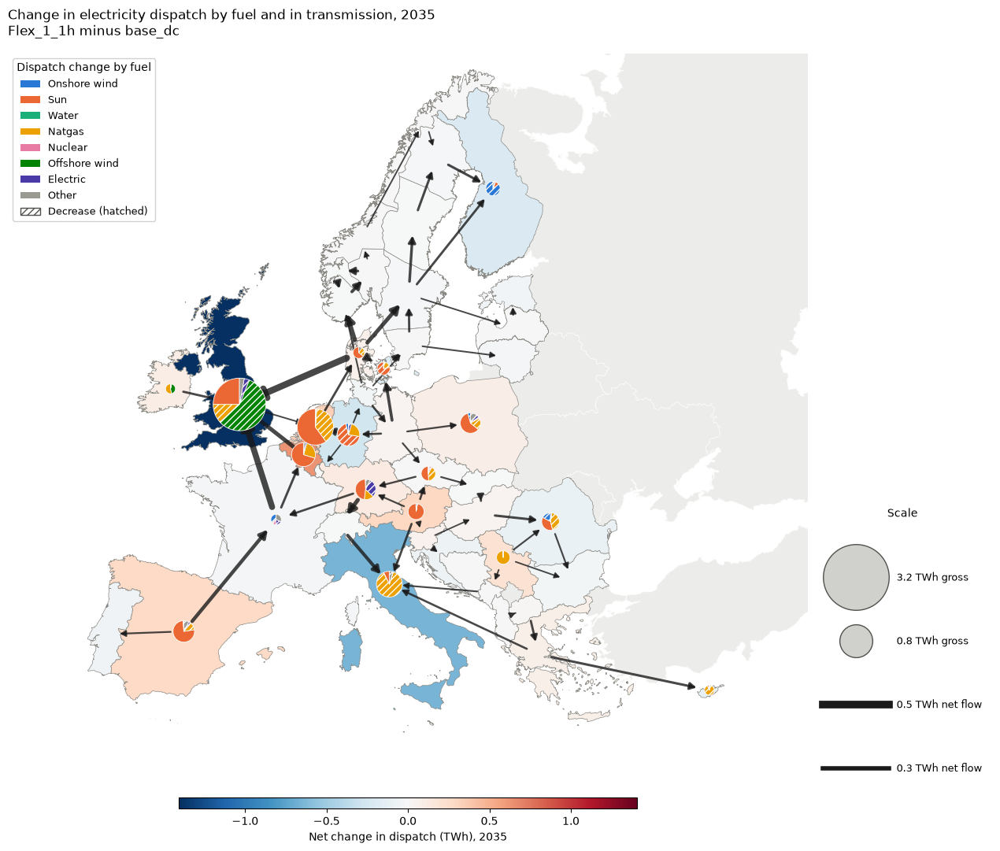

Fuel,WIND_ONSHORE,SUN,WATER,NATGAS,NUCLEAR,WIND_OFFSHORE,ELECTRIC,Other,Net,Gross
Region,,,,,,,,,,
UK,0.00,0.81,0.0,-0.38,0.01,-1.84,-0.10,0.09,-1.41,3.23
NL,0.00,0.92,0.0,-0.59,-0.01,0.00,0.00,0.01,0.34,1.54
IT,0.00,0.05,0.0,-0.68,0.00,-0.00,0.00,-0.04,-0.65,0.77
BE,0.00,0.46,0.0,0.17,0.00,0.00,-0.01,0.02,0.63,0.66
DE4-W,0.02,-0.40,0.0,0.14,0.00,0.00,-0.02,0.00,-0.27,0.59
ES,-0.01,0.41,-0.0,-0.06,0.00,0.00,-0.02,-0.04,0.28,0.54
DE4-S,0.00,0.23,0.0,0.07,0.00,0.00,-0.15,-0.03,0.13,0.49
PL,-0.02,0.29,0.0,-0.09,-0.01,0.00,-0.02,-0.05,0.10,0.48
RO,-0.06,0.13,0.0,-0.16,-0.00,0.00,0.00,-0.01,-0.10,0.36


In [71]:
# 11.2 Map of the changes (scenario - base) in annual dispatch by fuel and in the transmission net flow
# Uses MAP_YEAR, MAP_COMMODITY, the fuel folding/colours (keep, fuel_colors) and pie_change_map of 11.1
MIN_DISPATCH_CHANGE = 0.1            # TWh of gross change below which a region gets no pie

def region_dispatch(results, scenario):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Region", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

pro_change = region_dispatch(res, SCENARIO).sub(region_dispatch(base_res, BASE_SCENARIO), fill_value=0)
pro_change = pro_change.reindex(columns=pro_change.columns.union(keep), fill_value=0)
pro_change = pro_change[keep].assign(Other=pro_change.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else pro_change[keep]

# Lines: always the change in annual net flow, which is what moves with the dispatch
flow_change = pair_change(X_SYMBOLS[1], net=True)
flow_change = flow_change[flow_change.abs() >= MIN_LINE_SHARE * flow_change.abs().max()] if (flow_change.abs() > 1e-3).any() else flow_change.iloc[:0]

pie_change_map(pro_change, "TWh", MIN_DISPATCH_CHANGE, flow_change, "Flow", "TWh", "dispatch")

# The regions with the largest gross change in dispatch, for reference
pro_gross = pro_change.abs().sum(axis=1)
display(pro_change.loc[pro_gross.sort_values(ascending=False).head(10).index].assign(Net=pro_change.sum(axis=1), Gross=pro_gross).round(2))

#### 11.2.1 Maps of the changes in heat and hydrogen dispatch
The counterpart of 11.2 for the rest of the energy system: scenario - base annual dispatch (`PRO_YCRAGF`, TWh) of heat and of hydrogen in `MAP_YEAR`, read in the same way as 11.2 (background = net change per region, pies = gross change by fuel, hatched = decrease). Each commodity has its own fuel colours: its 7 largest fuels over both scenarios, the rest is `Other`.
- **Heat**: shows how heat supply shifts between fuels, e.g. from power-to-heat (`Electric`) to biomass or gas boilers when electricity becomes more expensive. Heat is balanced per area, and Balmorel's heat transmission is not drawn.
- **Hydrogen**: the arrows give the change in the annual net H2 pipeline flow between regions (`XH2_FLOW_YCR`, TWh), pointing in the direction of the additional flow. They show where hydrogen production moves to and which regions it supplies.

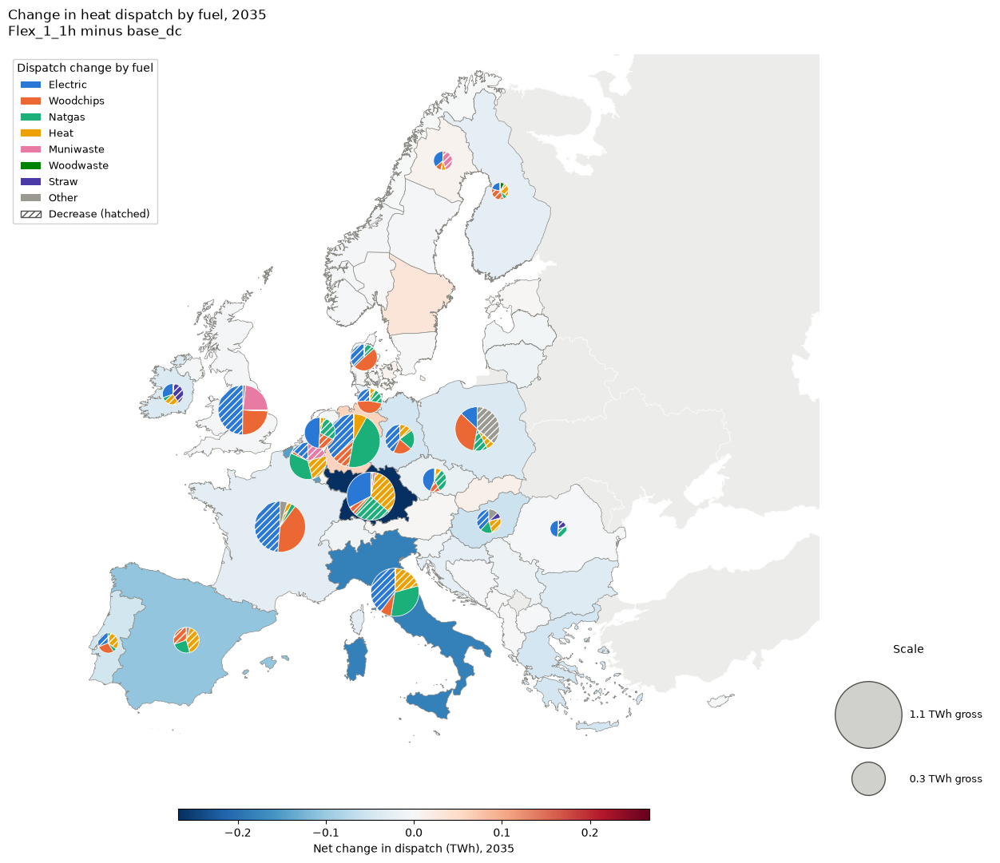

Heat: regions with the largest gross change in dispatch, 2035 (TWh)


Fuel,Electric,Woodchips,Natgas,Heat,Muniwaste,Woodwaste,Straw,Other,Net,Gross
Region,,,,,,,,,,
DE4-W,-0.39,-0.11,0.48,0.08,0.00,0.0,0.0,-0.00,0.06,1.06
FR,-0.47,0.40,0.03,-0.03,0.00,0.0,0.0,0.04,-0.03,0.96
UK,-0.46,0.23,0.00,-0.00,0.21,0.0,0.0,0.02,-0.00,0.92
IT,-0.35,0.06,0.28,-0.17,-0.00,0.0,0.0,0.00,-0.18,0.86
DE4-S,0.28,-0.05,-0.22,-0.29,0.01,0.0,0.0,-0.01,-0.27,0.86
PL,0.09,0.25,-0.08,-0.04,0.00,-0.0,-0.0,-0.26,-0.04,0.73
BE,-0.08,-0.01,0.18,-0.13,-0.11,-0.0,0.0,-0.00,-0.15,0.51
NL,0.17,-0.07,-0.10,-0.01,0.00,-0.0,-0.0,0.00,-0.01,0.35
DE4-E,-0.14,0.07,0.07,-0.05,0.00,0.0,-0.0,-0.00,-0.05,0.32


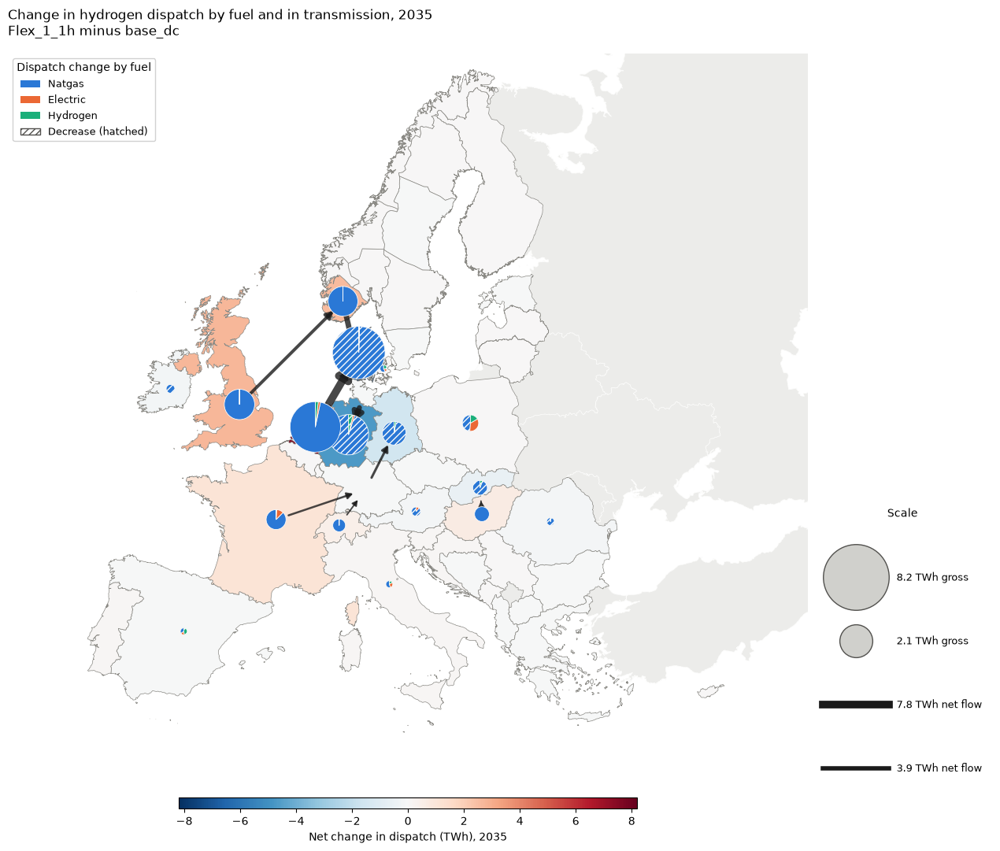

Hydrogen: regions with the largest gross change in dispatch, 2035 (TWh)


Fuel,Natgas,Electric,Hydrogen,Net,Gross
Region,,,,,
DK1,-8.17,-0.03,0.01,-8.19,8.20
NL,7.32,0.11,0.14,7.57,7.57
DE4-W,-4.57,0.07,-0.17,-4.67,4.81
UK,2.73,-0.00,0.00,2.72,2.73
NO2,2.62,-0.00,0.00,2.62,2.62
DE4-E,-1.62,0.00,0.04,-1.58,1.66
FR,1.02,0.14,-0.01,1.15,1.17
PL,-0.39,0.27,0.13,0.02,0.79
HU,0.65,-0.00,0.00,0.65,0.65


Hydrogen: largest changes in the annual net pipeline flow (TWh, positive = first region -> second region)


Change
DK1   NL      -7.82
DE4-N NO2     -5.14
      DE4-W    4.73
NO2   UK      -2.48
DE4-E DE4-S   -1.53
DE4-S FR      -1.06
HU    SK       0.47
CH    DE4-S    0.46

In [72]:
# 11.2.1 Maps of the changes (scenario - base) in heat and hydrogen dispatch by fuel, with the change in the H2 pipeline flows
# Uses MAP_YEAR, MIN_DISPATCH_CHANGE, MIN_LINE_SHARE, pair_change and pie_change_map of 11.1 - 11.2
SYSTEM_MAP_COMMODITIES = {"HEAT": None, "HYDROGEN": "XH2_FLOW_YCR"}   # commodity: flow symbol of the arrows (None = no arrows)

def region_dispatch_of(results, scenario, commodity):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR) & t["Commodity"].eq(commodity)]
    return t.groupby(["Region", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

for commodity, flow_symbol in SYSTEM_MAP_COMMODITIES.items():
    change = region_dispatch_of(res, SCENARIO, commodity).sub(region_dispatch_of(base_res, BASE_SCENARIO, commodity), fill_value=0)
    # Fuel folding and colours of this commodity (7 largest fuels over both scenarios, the rest 'Other'), as align() in 9.2
    _, _, colors = align(by_year(base_res, BASE_SCENARIO, "PRO_YCRAGF", "Fuel", commodity),
                         by_year(res, SCENARIO, "PRO_YCRAGF", "Fuel", commodity))
    kept = [f for f in colors if f != "Other"]
    change = change.reindex(columns=change.columns.union(kept), fill_value=0)
    change = change[kept].assign(Other=change.drop(columns=kept).sum(axis=1)) if "Other" in colors else change[kept]

    flows = pair_change(flow_symbol, net=True) if flow_symbol else pd.Series(dtype=float)
    flows = flows[flows.abs() >= MIN_LINE_SHARE * flows.abs().max()] if (flows.abs() > 1e-3).any() else flows.iloc[:0]

    pie_change_map(change, "TWh", MIN_DISPATCH_CHANGE, flows, "Flow", "TWh", "dispatch", colors=colors, commodity=commodity)

    gross = change.abs().sum(axis=1)
    print(f"{commodity.title()}: regions with the largest gross change in dispatch, {MAP_YEAR} (TWh)")
    display(change.loc[gross.sort_values(ascending=False).head(10).index].rename(columns=clean_name)
                  .assign(Net=change.sum(axis=1), Gross=gross).round(2))
    if len(flows):
        print(f"{commodity.title()}: largest changes in the annual net pipeline flow (TWh, positive = first region -> second region)")
        display(flows.reindex(flows.abs().sort_values(ascending=False).index).head(10).round(2).rename("Change").to_frame())

#### 11.2.2 Map of the change in the supply of all energy: electricity, heat and hydrogen together
One map for the whole energy system: the scenario - base change in `MAP_YEAR` in how each region meets its electricity, heat and hydrogen use (TWh, summed over the three carriers). The pie wedges are:
- **Fuels**: electricity, heat and hydrogen produced from each fuel or renewable source (`PRO_YCRAGF`, all non-storage units that do not run on electricity). The 6 largest fuels over both scenarios have their own colour, the rest is `Other`.
- **Power-to-heat/H2**: heat and hydrogen made from electricity (heat pumps, electric boilers, electrolysers). This is a conversion, not an additional source: the electricity used is already counted in the fuel wedges. It shows how much of the electricity supply is converted to heat and hydrogen.
- **Storage discharge**: output of electricity, heat and H2 storage.
- **V2G**: EV discharge to the grid (`V2G_FLEX_YCR`).
- **Net import**: change in the net import of electricity and hydrogen (`X_FLOW_YCR` + `XH2_FLOW_YCR`). Negative (hatched) = the region exports more or imports less.

The background is the net change in total supply per region, which equals the change in its total use of the three carriers (final demand plus conversion, storage charging and losses). Pie area is proportional to the gross change; hatched wedges are decreases. No arrows are drawn, because the flows are already included as net imports. The table below the map gives the Europe-wide totals per wedge.

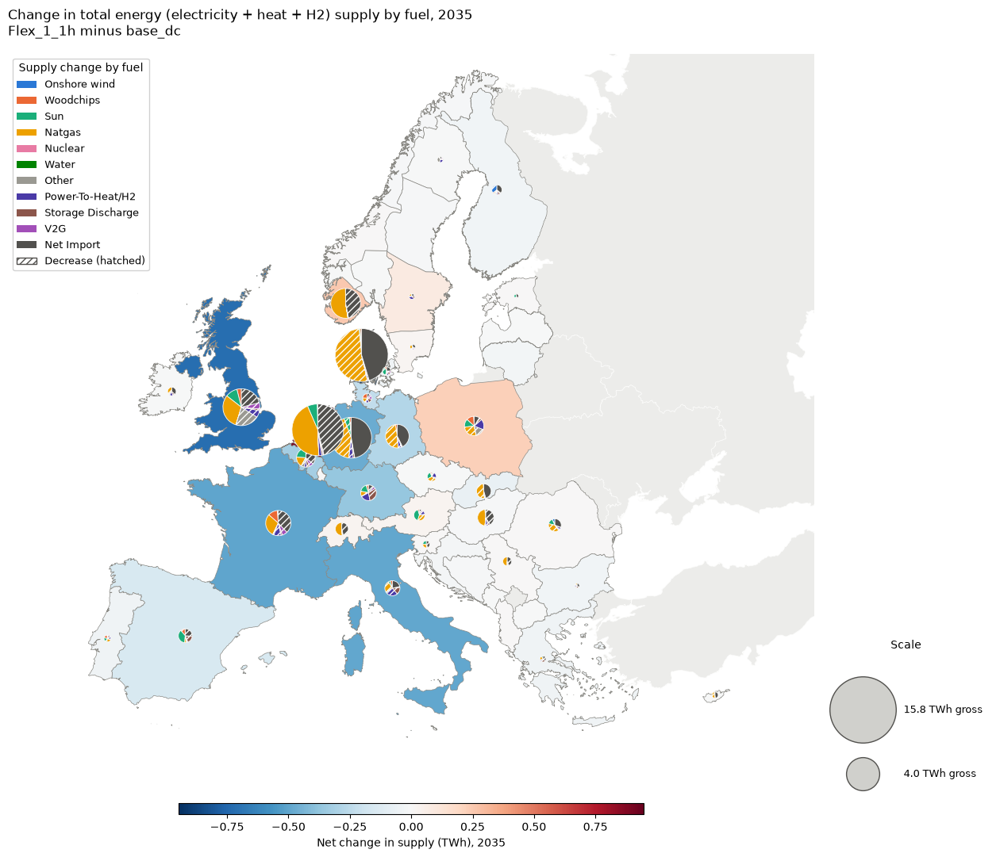

Supply of electricity, heat and hydrogen, all regions, 2035 (TWh)


,base_dc,Flex_1_1h,Change
Onshore wind,2272.33,2272.03,-0.30
Woodchips,1408.03,1409.02,0.99
Sun,996.59,999.90,3.31
Natgas,933.61,931.77,-1.84
Nuclear,662.28,662.26,-0.02
Water,617.78,617.78,0.00
Other,524.87,522.77,-2.10
Power-to-heat/H2,4383.84,4383.26,-0.58
Storage discharge,346.48,344.98,-1.49
V2G,65.31,64.02,-1.30


Regions with the largest gross change in supply, 2035 (TWh)


Group,Onshore wind,Woodchips,Sun,Natgas,Nuclear,Water,Other,Power-To-Heat/H2,Storage Discharge,V2G,Net Import,Net,Gross
Region,,,,,,,,,,,,,
DK1,0.00,0.14,0.10,-8.24,0.00,0.0,0.00,-0.13,0.01,-0.02,7.18,-0.95,15.82
NL,0.00,-0.05,0.92,6.63,-0.01,0.0,0.00,0.28,0.13,-0.07,-6.93,0.90,15.02
DE4-W,0.02,-0.11,-0.40,-3.96,0.00,0.0,0.01,-0.32,-0.11,-0.01,4.42,-0.47,9.36
UK,0.00,0.30,0.81,2.35,0.01,0.0,-1.59,-0.46,-0.11,-0.43,-1.61,-0.72,7.66
NO2,0.00,-0.02,0.00,2.61,0.00,0.0,0.00,0.02,-0.00,-0.01,-2.35,0.26,5.01
FR,-0.05,0.44,0.00,1.04,0.01,0.0,0.04,-0.33,-0.06,-0.24,-1.35,-0.50,3.57
DE4-E,0.01,0.07,0.00,-1.52,0.00,0.0,0.01,-0.13,-0.03,-0.02,1.33,-0.28,3.12
PL,-0.02,0.26,0.29,-0.56,-0.01,0.0,-0.33,0.37,0.07,-0.03,0.19,0.23,2.12
BE,0.00,0.01,0.46,0.35,0.00,0.0,-0.11,-0.08,-0.10,-0.14,-0.71,-0.32,1.97


In [73]:
# 11.2.2 Map of the change (scenario - base) in the supply of electricity, heat and hydrogen together, by fuel, storage,
# flexibility and net imports (TWh). Uses MAP_YEAR, MIN_DISPATCH_CHANGE and pie_change_map of 11.1
SUPPLY_STORAGE_TYPES = ["INTRASEASONAL-ELECT-STORAGE", "INTRASEASONAL-HEAT-STORAGE", "INTERSEASONAL-HEAT-STORAGE", "H2-STORAGE"]
SUPPLY_FIXED_COLORS = {"Power-to-heat/H2": "#4a3aa7", "Storage discharge": "#8c564b", "V2G": "#a24fb8", "Net import": "#52514e"}
N_SUPPLY_FUELS = 6                    # fuels with their own colour, the rest is 'Other'

def region_supply(results, scenario):
    """Region x group table (TWh) of the supply of electricity, heat and hydrogen in MAP_YEAR (groups as described above)."""
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR)]
    is_storage = t["Technology"].isin(SUPPLY_STORAGE_TYPES)
    is_p2x = t["Fuel"].eq("ELECTRIC") & t["Commodity"].isin(["HEAT", "HYDROGEN"]) & ~is_storage
    group = t["Fuel"].astype(str).mask(is_storage, "Storage discharge").mask(is_p2x, "Power-to-heat/H2")
    out = t.assign(Group=group).groupby(["Region", "Group"])["Value"].sum().unstack("Group", fill_value=0)

    v2g = scenario_result(results, scenario, "V2G_FLEX_YCR")
    out["V2G"] = v2g.loc[v2g["Year"].astype(str).eq(MAP_YEAR)].groupby("Region")["Value"].sum().reindex(out.index, fill_value=0)

    net_import = pd.Series(0.0, index=out.index)
    for symbol in ["X_FLOW_YCR", "XH2_FLOW_YCR"]:
        f = scenario_result(results, scenario, symbol)
        f = f.loc[f["Year"].astype(str).eq(MAP_YEAR)]
        net_import = net_import.add(f.groupby("To")["Value"].sum(), fill_value=0).sub(f.groupby("From")["Value"].sum(), fill_value=0)
    out["Net import"] = net_import.reindex(out.index.union(net_import.index), fill_value=0)
    return out.fillna(0)

supply_base, supply_scen = region_supply(base_res, BASE_SCENARIO), region_supply(res, SCENARIO)

# Fuel folding: the N_SUPPLY_FUELS largest fuels (summed over both scenarios) keep their name, the rest is 'Other'
fuel_totals = supply_base.sum().add(supply_scen.sum(), fill_value=0).drop(list(SUPPLY_FIXED_COLORS), errors="ignore")
top_fuels = list(fuel_totals.abs().sort_values(ascending=False).index[:N_SUPPLY_FUELS])

def fold_supply(t):
    t = t.reindex(columns=t.columns.union(top_fuels + list(SUPPLY_FIXED_COLORS)), fill_value=0)
    other = t.drop(columns=top_fuels + list(SUPPLY_FIXED_COLORS)).sum(axis=1)
    return t[top_fuels].assign(Other=other)[top_fuels + ["Other"]].join(t[list(SUPPLY_FIXED_COLORS)])

supply_base, supply_scen = fold_supply(supply_base), fold_supply(supply_scen)
supply_change = supply_scen.sub(supply_base, fill_value=0).fillna(0)
supply_colors = {**dict(zip(top_fuels, PALETTE[:N_SUPPLY_FUELS])), "Other": GREY, **SUPPLY_FIXED_COLORS}

pie_change_map(supply_change, "TWh", MIN_DISPATCH_CHANGE, pd.Series(dtype=float), "Flow", "TWh", "supply",
               colors=supply_colors, commodity="total energy (electricity + heat + H2)")

# Europe-wide totals per wedge (net imports sum to about zero: what one region imports, another exports)
europe = pd.DataFrame({BASE_SCENARIO: supply_base.sum(), SCENARIO: supply_scen.sum()})
europe["Change"] = europe[SCENARIO] - europe[BASE_SCENARIO]
europe.index = [clean_name(i) if i in top_fuels else i for i in europe.index]
print(f"Supply of electricity, heat and hydrogen, all regions, {MAP_YEAR} (TWh)")
display(europe.round(2))

gross = supply_change.abs().sum(axis=1)
print(f"Regions with the largest gross change in supply, {MAP_YEAR} (TWh)")
display(supply_change.loc[gross.sort_values(ascending=False).head(10).index].rename(columns=clean_name)
                     .assign(Net=supply_change.sum(axis=1), Gross=gross).round(2))

### 11.3 Change in CO2 emissions per country (kton)
Map of the change per country (scenario - base) in the CO2 emissions (`EMI_YCRAG`, kton) in `FOCUS_YEAR`. The table also gives the change in % of the base emissions of the country; a percentage exaggerates countries with small base emissions (e.g. Norway), so the map shows the absolute change.

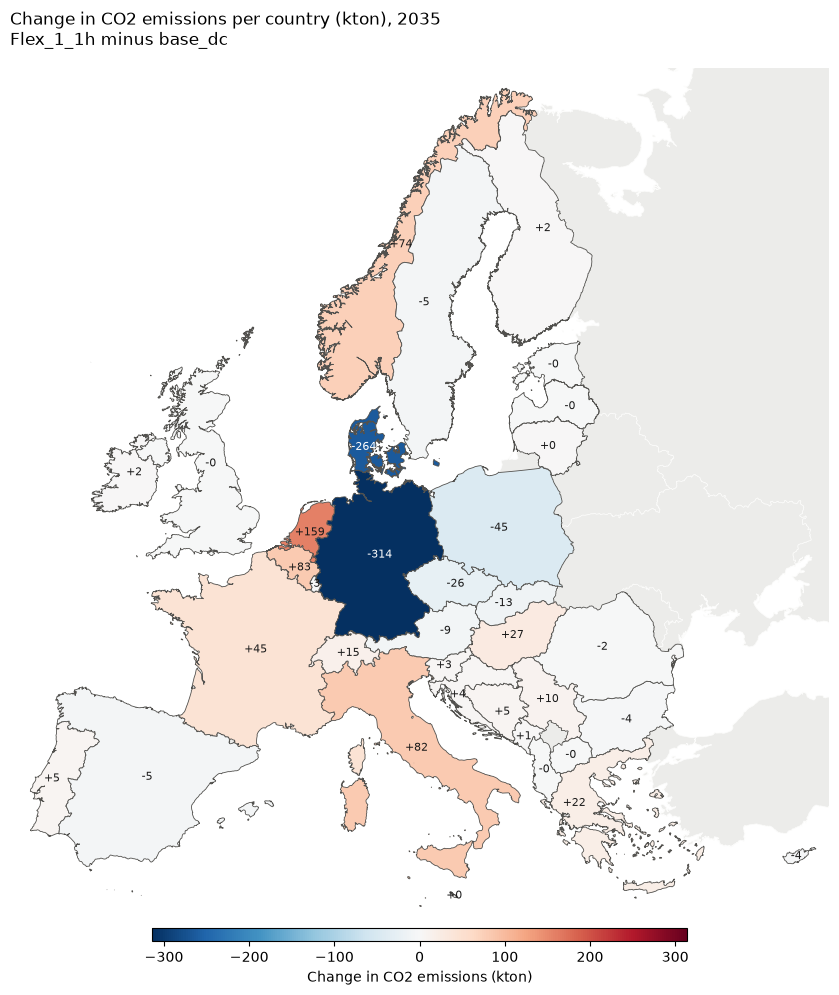

CO2 emissions per country, 2035 (kton), largest increase first


,base_dc,Flex_1_1h,Change (kton),Change (%)
Country,,,,
NETHERLANDS,4514.36,4673.04,158.67,3.51
BELGIUM,3499.53,3582.26,82.73,2.36
ITALY,14848.88,14931.04,82.16,0.55
NORWAY,1647.01,1721.49,74.48,4.52
FRANCE,7123.46,7168.39,44.93,0.63
HUNGARY,2117.33,2144.65,27.32,1.29
GREECE,1964.21,1985.97,21.76,1.11
SWITZERLAND,919.02,933.94,14.92,1.62
SERBIA,952.81,962.75,9.94,1.04


In [74]:
# 11.3 Map of the change (scenario - base) in CO2 emissions per country in FOCUS_YEAR (kton)
# The setup (country polygons, country_change_table, change_map) is reused by the cost map of 11.4
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm

def country_total(results, scenario, symbol):
    t = scenario_result(results, scenario, symbol)
    return t.loc[t["Year"].astype(str).eq(FOCUS_YEAR)].groupby("Country")["Value"].sum()

def country_change_table(symbol, unit):
    t = pd.DataFrame({BASE_SCENARIO: country_total(base_res, BASE_SCENARIO, symbol),
                      SCENARIO: country_total(res, SCENARIO, symbol)}).fillna(0)
    t[f"Change ({unit})"] = t[SCENARIO] - t[BASE_SCENARIO]
    t["Change (%)"] = t[f"Change ({unit})"] / t[BASE_SCENARIO].replace(0, np.nan) * 100
    return t

emi_focus = country_change_table("EMI_YCRAG", "kton")

# Country polygons = the region polygons of pybalmorel's geofile, merged per country (region -> country from the results)
region_country_focus = pd.concat([scenario_result(r, s, "OBJ_YCR") for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]) \
                         .drop_duplicates("Region").set_index("Region")["Country"]
geo_focus = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo_focus["Country"] = geo_focus["id"].map(region_country_focus)
country_shapes = geo_focus.dropna(subset=["Country"]).dissolve(by="Country")
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)

def change_map(values, title, label, fmt):
    """Country map of `values` (change, scenario - base) on a diverging scale centred on 0, red = higher in the scenario."""
    shapes = country_shapes.join(values.rename("Change"))
    fig, ax = plt.subplots(figsize=(11, 11))
    geo_focus[geo_focus["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)     # outside the model
    lim = max(values.abs().max(), 1e-6)
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    shapes.plot(ax=ax, column="Change", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.6,
                missing_kwds={"color": "#ececea", "edgecolor": "#52514e", "linewidth": 0.6})
    # Label every country with its change; the label sits on the largest part of the country (mainland, not islands)
    for name, row in shapes.iterrows():
        if pd.isna(row["Change"]):
            continue
        p = mainland(row.geometry).representative_point()
        ax.annotate(fmt.format(row["Change"]), (p.x, p.y), ha="center", va="center", fontsize=8,
                    color="white" if abs(row["Change"]) > 0.6 * lim else "#1a1a1a")
    minx, miny, maxx, maxy = shapes.geometry.apply(mainland).total_bounds
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    ax.set_title(f"{title}, {FOCUS_YEAR}\n{SCENARIO} minus {BASE_SCENARIO}", loc="left")
    fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40, label=label)
    plt.tight_layout(); plt.show()

change_map(emi_focus["Change (kton)"], "Change in CO2 emissions per country (kton)",
           "Change in CO2 emissions (kton)", "{:+.0f}")
print(f"CO2 emissions per country, {FOCUS_YEAR} (kton), largest increase first")
display(emi_focus.sort_values("Change (kton)", ascending=False).round(2))

### 11.4 Change in total system cost per country (Mmoney)
Map of the change per country (scenario - base) in the total system cost (`OBJ_YCR`, Mmoney) in `FOCUS_YEAR`. The table also gives the change in % of the base cost of the country. The marginal electricity cost follows in 11.4.1 - 11.4.3.

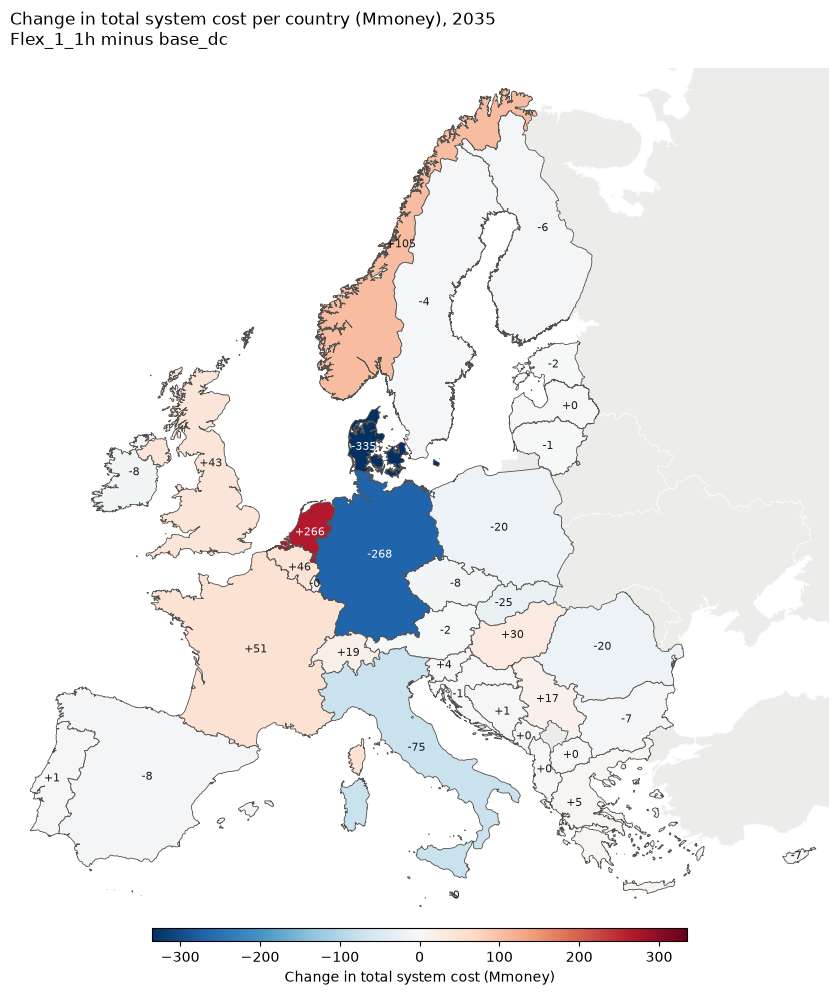

Total system cost per country, 2035 (Mmoney), largest increase first


,base_dc,Flex_1_1h,Change (Mmoney),Change (%)
Country,,,,
NETHERLANDS,9922.12,10188.05,265.93,2.68
NORWAY,4650.54,4755.22,104.68,2.25
FRANCE,37234.67,37286.05,51.39,0.14
BELGIUM,7451.50,7497.28,45.78,0.61
UNITED_KINGDOM,27245.45,27288.73,43.29,0.16
HUNGARY,4803.64,4833.25,29.61,0.62
SWITZERLAND,3575.96,3595.35,19.39,0.54
SERBIA,2176.08,2192.83,16.75,0.77
GREECE,4159.26,4164.55,5.29,0.13


In [75]:
# 11.4 Map of the change (scenario - base) in total system cost per country in FOCUS_YEAR (Mmoney)
# Uses country_change_table and change_map of 11.3
cost_focus = country_change_table("OBJ_YCR", "Mmoney")

change_map(cost_focus["Change (Mmoney)"], "Change in total system cost per country (Mmoney)",
           "Change in total system cost (Mmoney)", "{:+.0f}")
print(f"Total system cost per country, {FOCUS_YEAR} (Mmoney), largest increase first")
display(cost_focus.sort_values("Change (Mmoney)", ascending=False).round(2))

#### 11.4.1 Map of the change in marginal electricity cost per country
Change (scenario - base) in the demand-weighted average marginal cost of electricity per country in `PRICE_MAP_YEAR` (default: last common year), from `EL_PRICE_YCR` (time-averaged marginal cost of the electricity balance per region, Money/MWh). Regions of the same country are combined, weighted by their annual electricity demand. Red = more expensive in the scenario.

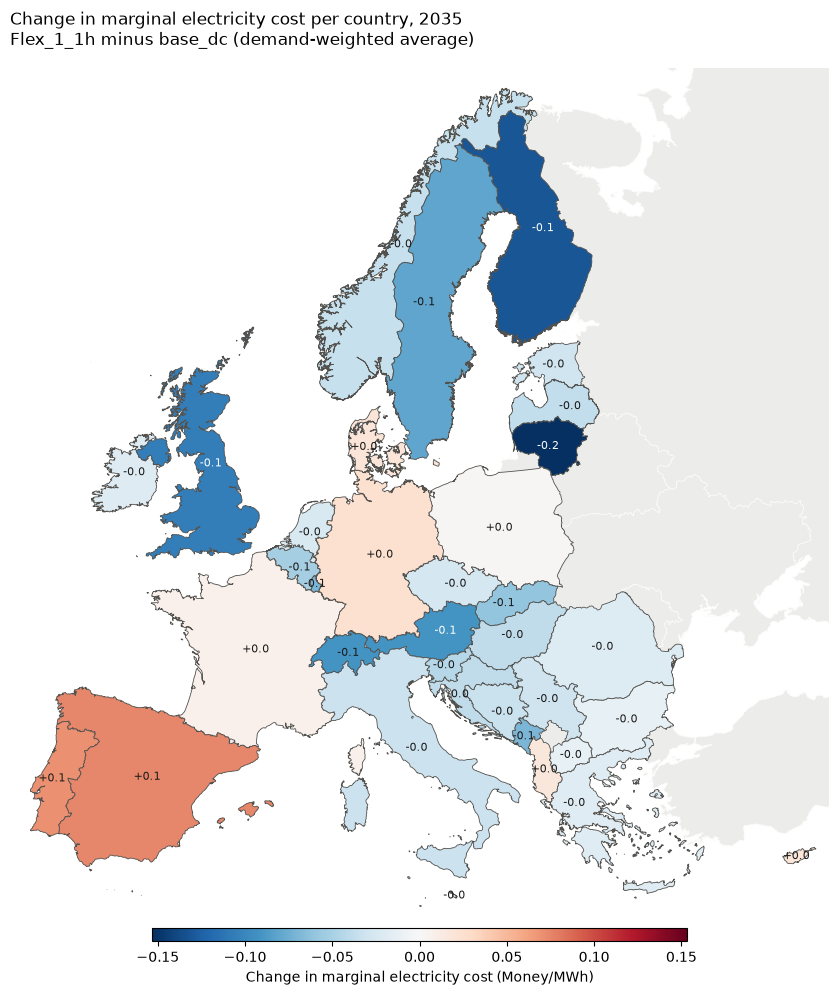

,base_dc,Flex_1_1h,Change,Change (%)
Country,,,,
SPAIN,39.15,39.23,0.08,0.19
PORTUGAL,40.37,40.44,0.07,0.17
GERMANY,43.94,43.97,0.02,0.05
DENMARK,37.37,37.39,0.02,0.05
CYPRUS,46.92,46.94,0.02,0.04
ALBANIA,42.73,42.75,0.02,0.04
FRANCE,32.51,32.52,0.01,0.02
POLAND,38.79,38.79,0.00,0.01
NORTH_MACEDONIA,46.08,46.07,-0.01,-0.03


In [76]:
# 11.4.1 Change in the demand-weighted marginal electricity cost per country (Money/MWh)
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm

PRICE_MAP_YEAR = COMPARISON_YEARS[-1]        # any of COMPARISON_YEARS, as a string

price_country = pd.DataFrame({BASE_SCENARIO: price_by(base_res, BASE_SCENARIO, "Country").xs(PRICE_MAP_YEAR, level="Year"),
                              SCENARIO: price_by(res, SCENARIO, "Country").xs(PRICE_MAP_YEAR, level="Year")})
price_country["Change"] = price_country[SCENARIO] - price_country[BASE_SCENARIO]
price_country["Change (%)"] = price_country["Change"] / price_country[BASE_SCENARIO] * 100

# Country polygons = the region polygons of pybalmorel's geofile, merged per country (region -> country from the results)
region_country = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo["Country"] = geo["id"].map(region_country)
countries = geo.dropna(subset=["Country"]).dissolve(by="Country").join(price_country)

fig, ax = plt.subplots(figsize=(11, 11))
geo[geo["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)       # outside the model
lim = max(price_country["Change"].abs().max(), 1e-6)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
countries.plot(ax=ax, column="Change", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.6)
# Label every country with its change; the label sits on the largest part of the country (mainland, not islands)
for name, row in countries.iterrows():
    part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda g: g.area)
    p = part.representative_point()
    ax.annotate(f"{row['Change']:+.1f}", (p.x, p.y), ha="center", va="center", fontsize=8,
                color="white" if abs(row["Change"]) > 0.6 * lim else "#1a1a1a")
minx, miny, maxx, maxy = countries.geometry.apply(lambda g: max(getattr(g, "geoms", [g]), key=lambda x: x.area)).total_bounds
ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
ax.set_axis_off()
ax.set_title(f"Change in marginal electricity cost per country, {PRICE_MAP_YEAR}\n{SCENARIO} minus {BASE_SCENARIO} (demand-weighted average)", loc="left")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40,
             label="Change in marginal electricity cost (Money/MWh)")
plt.tight_layout(); plt.show()

display(price_country.sort_values("Change", ascending=False).round(2))


#### 11.4.2 Marginal electricity cost per country: base, scenario and change
The demand-weighted average marginal cost of electricity per country of 11.4.1 (`EL_PRICE_YCR`, regions weighted by their annual electricity demand) in `PRICE_MAP_YEAR`, for the base (left) and the scenario (middle) on a common colour scale, and the change (right, red = more expensive in the scenario). The labels give the value per country; the numbers are those of the table in 11.4.1.

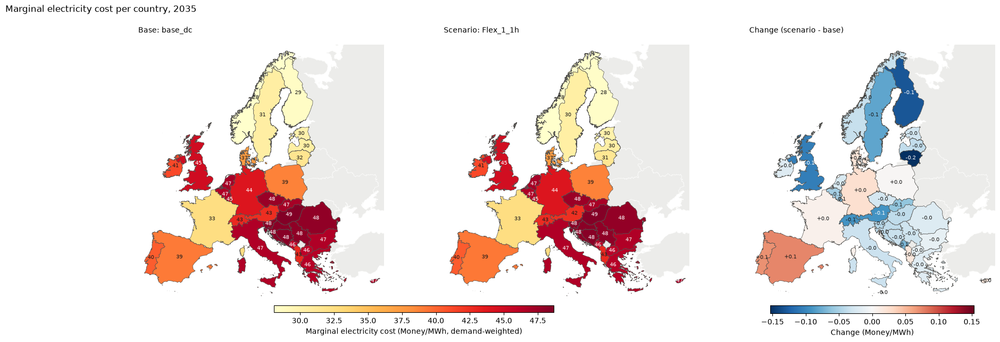

In [77]:
# 11.4.2 Marginal electricity cost per country: base, scenario and change (Money/MWh, demand-weighted), three maps
from matplotlib.colors import Normalize, TwoSlopeNorm

region_country_px = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
geo_px = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo_px["Country"] = geo_px["id"].map(region_country_px)
country_px = geo_px.dropna(subset=["Country"]).dissolve(by="Country").join(price_country)
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)

level_norm = Normalize(vmin=price_country[[BASE_SCENARIO, SCENARIO]].min().min(), vmax=price_country[[BASE_SCENARIO, SCENARIO]].max().max())
lim = max(price_country["Change"].abs().max(), 1e-6)
change_norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
panels = [(BASE_SCENARIO, f"Base: {BASE_SCENARIO}", "YlOrRd", level_norm, "{:.0f}"),
          (SCENARIO, f"Scenario: {SCENARIO}", "YlOrRd", level_norm, "{:.0f}"),
          ("Change", "Change (scenario - base)", "RdBu_r", change_norm, "{:+.1f}")]

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
minx, miny, maxx, maxy = country_px.geometry.apply(mainland).total_bounds
for ax, (col, title, cmap, norm, fmt_) in zip(axes, panels):
    geo_px[geo_px["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)     # outside the model
    country_px.plot(ax=ax, column=col, cmap=cmap, norm=norm, edgecolor="#52514e", linewidth=0.5)
    for name, row in country_px.iterrows():
        if pd.isna(row[col]):
            continue
        p = mainland(row.geometry).representative_point()
        dark = (norm(row[col]) > 0.75) if col != "Change" else abs(row[col]) > 0.6 * lim
        ax.annotate(fmt_.format(row[col]), (p.x, p.y), ha="center", va="center", fontsize=7, color="white" if dark else "#1a1a1a")
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=level_norm), ax=axes[:2], orientation="horizontal", shrink=0.5, pad=0.02, aspect=40,
             label="Marginal electricity cost (Money/MWh, demand-weighted)")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=change_norm), ax=axes[2], orientation="horizontal", shrink=0.8, pad=0.02, aspect=25,
             label="Change (Money/MWh)")
fig.suptitle(f"Marginal electricity cost per country, {PRICE_MAP_YEAR}", x=0.01, ha="left")
plt.show()


#### 11.4.3 Where does the change in marginal electricity cost come from? (2035)
The country change in 11.4.1 is $\Delta P_c = \sum_r w_r^{S} P_r^{S} - \sum_r w_r^{B} P_r^{B}$, where $P_r$ is the time-averaged hourly marginal cost of region $r$ and $w_r$ its share of the country's annual electricity demand. It is split exactly into
- **Hours priced with neighbours**: $\sum_r w_r^{B}\,\overline{\Delta p_{rt}}$ over the hours in which, in the scenario, region $r$ has (within `COUPLING_TOL`, to allow for transmission losses) the same price as a connected region in another country, i.e. the interconnector is not congested and the price is formed in a wider multi-country market;
- **Hours priced domestically**: the same term over the remaining hours, in which the borders are congested and the price is set by the country's own supply and demand;
- **Regional demand weights**: $\sum_r (w_r^{S} - w_r^{B}) P_r^{S}$, the shift of demand between the regions of a country.

The physical drivers next to it (scenario - base, annual) show what moved: demand and the part from data centres (`DE_DATACENTER.inc` of both runs), domestic generation, of which fuel-fired thermal (condensing and CHP, nuclear excluded), net imports from other countries and installed capacity.

In [78]:
# 11.4.3 Decomposition of the change in marginal electricity cost per country (2035) and its physical drivers
PRICE_DRIVER_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]
COUPLING_TOL = 0.05                  # relative price difference still counted as "same price" (transmission losses)
THERMAL_TECH = ["CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION"]   # fuel-fired plants, nuclear excluded below

def year_table(results, scenario, symbol):
    t = scenario_result(results, scenario, symbol)
    return t.loc[t["Year"].astype(str).eq(PRICE_DRIVER_YEAR)]

def region_weights(results, scenario):
    """Share of each region in its country's annual electricity demand (all categories), as in price_by."""
    d = year_table(results, scenario, "EL_DEMAND_YCR").groupby(["Country", "Region"])["Value"].sum()
    return d / d.groupby(level="Country").transform("sum").replace(0, np.nan)

def hourly_price(results, scenario):
    return year_table(results, scenario, "EL_PRICE_YCRST").set_index(["Region", "Season", "Time"])["Value"]

def coupled_hours(results, scenario, price):
    """True where a region has the same price (within COUPLING_TOL) as a connected region in another country."""
    region_country = year_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    x = year_table(results, scenario, "X_CAP_YCR").groupby(["From", "To"])["Value"].sum()
    links = pd.DataFrame([(a, b) for (a, b), v in x.items() if v > 1e-6], columns=["Region", "Neighbour"])
    links = pd.concat([links, links.rename(columns={"Region": "Neighbour", "Neighbour": "Region"})]).drop_duplicates()
    links = links.loc[links["Region"].map(region_country).ne(links["Neighbour"].map(region_country))]
    p = price.rename("P").reset_index()
    pairs = links.merge(p, on="Region").merge(p.rename(columns={"Region": "Neighbour", "P": "PN"}), on=["Neighbour", "Season", "Time"])
    pairs["Same"] = (pairs["P"] - pairs["PN"]).abs() <= COUPLING_TOL * pairs[["P", "PN"]].abs().max(axis=1) + 0.01
    return pairs.groupby(["Region", "Season", "Time"])["Same"].any().reindex(price.index, fill_value=False)

def by_country(results, scenario, symbol, mask=None):
    t = year_table(results, scenario, symbol)
    return (t if mask is None else t.loc[mask(t)]).groupby("Country")["Value"].sum()

def net_imports(results, scenario):
    """Annual imports minus exports across the country's borders (TWh)."""
    rc = year_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    f = year_table(results, scenario, "X_FLOW_YCR").assign(CFrom=lambda d: d["From"].map(rc), CTo=lambda d: d["To"].map(rc))
    f = f.loc[f["CFrom"].ne(f["CTo"])]
    return f.groupby("CTo")["Value"].sum().sub(f.groupby("CFrom")["Value"].sum(), fill_value=0)

# --- Price decomposition (Money/MWh); the three parts add up to the change of 11.4.1 --------------------------------
p_base, p_scen = hourly_price(base_res, BASE_SCENARIO), hourly_price(res, SCENARIO)
dp = p_scen.sub(p_base, fill_value=0)
coupled = coupled_hours(res, SCENARIO, p_scen).reindex(dp.index, fill_value=False)
n_hours = dp.groupby(level="Region").size()
w_base, w_scen = region_weights(base_res, BASE_SCENARIO), region_weights(res, SCENARIO)
regions = w_base.index.union(w_scen.index)
w_base, w_scen = w_base.reindex(regions).fillna(0), w_scen.reindex(regions).fillna(0)
country_of = pd.Series(regions.get_level_values("Country"), index=regions.get_level_values("Region"))

def weighted(per_region):                       # sum over the regions of a country with the base demand weights
    v = per_region.reindex(regions.get_level_values("Region")).fillna(0).to_numpy()
    return pd.Series(w_base.to_numpy() * v, index=regions).groupby(level="Country").sum()

mean_dp_coupled = dp.where(coupled, 0).groupby(level="Region").sum() / n_hours
mean_dp_domestic = dp.where(~coupled, 0).groupby(level="Region").sum() / n_hours
P_scen = p_scen.groupby(level="Region").mean()
shift = pd.Series((w_scen - w_base).to_numpy() * P_scen.reindex(regions.get_level_values("Region")).fillna(0).to_numpy(),
                  index=regions).groupby(level="Country").sum()
share_coupled = lambda c: pd.Series(c.to_numpy(), index=c.index).groupby(country_of.reindex(c.index.get_level_values("Region")).to_numpy()).mean() * 100

reference = pd.DataFrame({"Base": price_by(base_res, BASE_SCENARIO, "Country").xs(PRICE_DRIVER_YEAR, level="Year"),
                          "Scenario": price_by(res, SCENARIO, "Country").xs(PRICE_DRIVER_YEAR, level="Year")})
price_part = pd.DataFrame({
    "Base": reference["Base"],
    "Scenario": reference["Scenario"],
    "Change": reference["Scenario"] - reference["Base"],
    "Hours priced with neighbours": weighted(mean_dp_coupled),
    "Hours priced domestically": weighted(mean_dp_domestic),
    "Regional demand weights": shift,
    "Hours priced with neighbours (% base)": share_coupled(coupled_hours(base_res, BASE_SCENARIO, p_base)),
    "Hours priced with neighbours (% scen.)": share_coupled(coupled),
})
residual = price_part["Change"] - price_part[["Hours priced with neighbours", "Hours priced domestically", "Regional demand weights"]].sum(axis=1)
if residual.abs().max() > 1e-6:
    print(f"Warning: decomposition does not close, largest residual {residual.abs().max():.3g} Money/MWh")

# --- Physical drivers (scenario - base, TWh or GW) ----------------------------------------------------------------
region_country = country_of[~country_of.index.duplicated()]
thermal = lambda t: t["Commodity"].eq("ELECTRICITY") & t["Technology"].isin(THERMAL_TECH) & t["Fuel"].ne("NUCLEAR")
electricity = lambda t: t["Commodity"].eq("ELECTRICITY")
diff = lambda f: f(res, SCENARIO).sub(f(base_res, BASE_SCENARIO), fill_value=0)
drivers = pd.DataFrame({
    "Demand (TWh)": diff(lambda r, s: by_country(r, s, "EL_DEMAND_YCR")),
    "of which data centres (TWh)": datacenter_demand(SCENARIO_DIR, PRICE_DRIVER_YEAR, region_country).sub(datacenter_demand(BASE_DIR, PRICE_DRIVER_YEAR, region_country), fill_value=0),
    "Domestic generation (TWh)": diff(lambda r, s: by_country(r, s, "PRO_YCRAGF", electricity)),
    "of which fuel-fired thermal (TWh)": diff(lambda r, s: by_country(r, s, "PRO_YCRAGF", thermal)),
    "Net imports (TWh)": diff(net_imports),
    "Installed capacity (GW)": diff(lambda r, s: by_country(r, s, "G_CAP_YCRAF", electricity)),
})

price_drivers = pd.concat({f"Marginal cost (Money/MWh), {PRICE_DRIVER_YEAR}": price_part,
                           "Drivers (scenario - base)": drivers.reindex(price_part.index).fillna(0)}, axis=1)
price_drivers = price_drivers.sort_values((f"Marginal cost (Money/MWh), {PRICE_DRIVER_YEAR}", "Change"), ascending=False)
price_drivers.index = [clean_name(c) for c in price_drivers.index]
print(f"{SCENARIO} minus {BASE_SCENARIO}, {PRICE_DRIVER_YEAR}. Change = hours priced with neighbours + hours priced domestically + regional demand weights")
display(price_drivers.round(2))


Flex_1_1h minus base_dc, 2035. Change = hours priced with neighbours + hours priced domestically + regional demand weights


Marginal cost (Money/MWh), 2035                  \
                                                  Base Scenario Change   
Spain                                            39.15    39.23   0.08   
Portugal                                         40.37    40.44   0.07   
Germany                                          43.94    43.97   0.02   
Denmark                                          37.37    37.39   0.02   
Cyprus                                           46.92    46.94   0.02   
Albania                                          42.73    42.75   0.02   
France                                           32.51    32.52   0.01   
Poland                                           38.79    38.79   0.00   
North Macedonia                                  46.08    46.07  -0.01   
Bulgaria                                         46.64    46.63  -0.01   
Greece                                           46.39    46.37  -0.02   
Ireland                                          41.22    41.20  -0.02   
Malta                                            48.68    48.66  -0.02   
Romania                                          47.88    47.86  -0.02   
Netherlands                                      47.05    47.02  -0.02   
Czech Republic                                   47.57    47.55  -0.03   
Estonia                                          30.01    29.98  -0.03   
Serbia                                           48.01    47.97  -0.03   
Italy                                            46.63    46.60  -0.03   
Bosnia And Herzegovina                           48.31    48.28  -0.03   
Norway                                           28.10    28.07  -0.04   
Latvia                                           30.42    30.39  -0.04   
Hungary                                          48.55    48.51  -0.04   
Croatia                                          48.30    48.26  -0.04   
Slovenia                                         48.33    48.28  -0.04   
Belgium                                          46.64    46.59  -0.05   
Slovakia                                         47.05    46.99  -0.06   
Luxembourg                                       44.83    44.76  -0.07   
Montenegro                                       46.07    46.00  -0.07   
Sweden                                           30.55    30.47  -0.08   
Switzerland                                      42.79    42.70  -0.09   
Austria                                          42.51    42.42  -0.09   
United Kingdom                                   44.83    44.72  -0.11   
Finland                                          28.52    28.38  -0.13   
Lithuania                                        31.65    31.50  -0.15   

                                                                               \
                       Hours priced with neighbours Hours priced domestically   
Spain                                          0.07                      0.00   
Portugal                                       0.04                      0.03   
Germany                                        0.03                     -0.01   
Denmark                                        0.05                     -0.03   
Cyprus                                         0.00                      0.02   
Albania                                        0.01                      0.00   
France                                         0.03                     -0.02   
Poland                                         0.05                     -0.05   
North Macedonia                               -0.00                     -0.01   
Bulgaria                                      -0.25                      0.24   
Greece                                        -0.01                     -0.01   
Ireland                                        0.03                     -0.05   
Malta                                          0.32                     -0.35   
Romania                                       -0.02                  

### 11.5 Levelised cost per final commodity: base vs scenario
The levelised cost per final MWh of 6.3 (each carrier including the electricity, heat and hydrogen used to make it) for the base and the scenario, with the same `lcoe_by` calculation for both. All in `LCOE_YEAR` (2035, set at the top of 6.3): a table per country with the total over all countries in the first row (then sorted by the change in the all-energy cost), and a map of the change per region for electricity, heat and hydrogen (red = more expensive in the scenario; one symmetric colour scale per carrier, spanning 98 % of the absolute changes). A change in the cost per MWh can come from a change in the costs, in the energy produced, or in how much of a carrier is used to make other carriers; `lcoe_by(zone, results, scenario)[1]` gives the costs and TWh behind each number.

/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact perfor

Check base_dc, per country: allocated costs differ from OBJ_YCR by at most 0.000 Mmoney; final costs differ from produced costs by at most 0.000 Mmoney


/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact perfor

Check base_dc, per region: allocated costs differ from OBJ_YCR by at most 0.000 Mmoney; final costs differ from produced costs by at most 0.000 Mmoney
Levelised cost per final MWh per country, 2035 (Money/MWh): base_dc (base) vs Flex_1_1h (scenario)


/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact performance.
  o = own.loc[(year, z)].reindex(LCOE_CARRIER_NAMES, fill_value=0)
/tmp/ipykernel_855840/3094611269.py:85: PerformanceWarning: indexing past lexsort depth may impact perfor

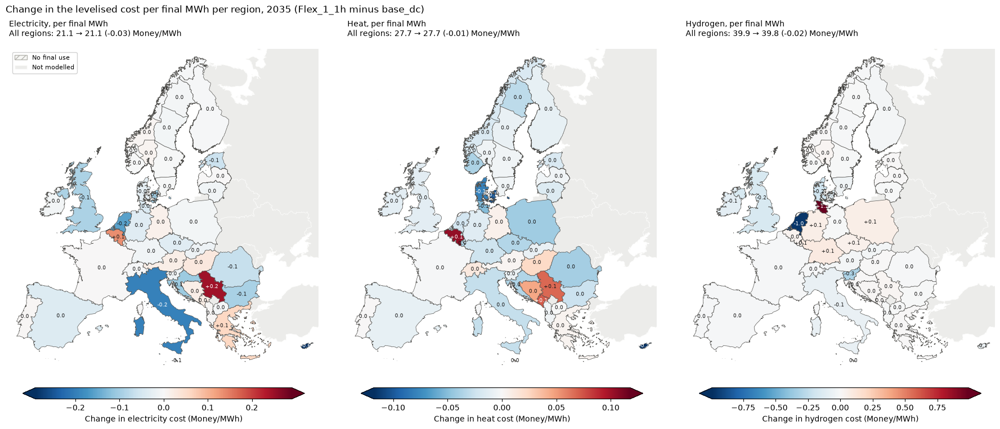

In [79]:
# 11.5 Levelised cost per final commodity: base vs scenario (Money/MWh), per country and per region in LCOE_YEAR (set in 6.3)
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

FINAL_COLS = ["All energy"] + LCOE_CARRIER_NAMES
cmp = {}                                                      # zone -> {"Base": ..., "Scenario": ...}, per final MWh
for zone in ["Country", "Region"]:
    cmp[zone] = {label: lcoe_by(zone, r, s)[0]["Per final MWh"][FINAL_COLS]
                 for label, r, s in [("Base", base_res, BASE_SCENARIO), ("Scenario", res, SCENARIO)]}

def lcoe_change(zone, year):
    """Base, scenario and change (Money/MWh) per zone in one year, columns (carrier, Base/Scenario/Change)."""
    b, s = (cmp[zone][k].xs(year, level="Year") for k in ("Base", "Scenario"))
    t = pd.concat({"Base": b, "Scenario": s, "Change": s.sub(b)}, axis=1).swaplevel(axis=1)
    return t.reindex(columns=pd.MultiIndex.from_product([FINAL_COLS, ["Base", "Scenario", "Change"]]))

# 1) Per country in LCOE_YEAR, all countries first, then by the largest change in the all-energy cost
t = lcoe_change("Country", LCOE_YEAR)
t = pd.concat([t.loc[["All countries"]], t.drop("All countries").sort_values(("All energy", "Change"), ascending=False)])
change_cols = [(c, "Change") for c in FINAL_COLS]
lim_c = np.nanmax(np.abs(t[change_cols].to_numpy())) or 1
print(f"Levelised cost per final MWh per country, {LCOE_YEAR} (Money/MWh): {BASE_SCENARIO} (base) vs {SCENARIO} (scenario)")
display(t.rename(index=clean_name).style.format("{:.1f}", na_rep="–").format("{:+.2f}", subset=change_cols, na_rep="–")
         .background_gradient(cmap="RdBu_r", vmin=-lim_c, vmax=lim_c, subset=change_cols))

# 2) Maps of the change per region in LCOE_YEAR, one per carrier (red = more expensive in the scenario)
chg = lcoe_change("Region", LCOE_YEAR).drop("All regions").xs("Change", axis=1, level=1)
chg_total = lcoe_change("Region", LCOE_YEAR).loc["All regions"]
geo_c = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
modelled = geo_c["id"].isin(chg.index)
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)
minx, miny, maxx, maxy = geo_c.loc[modelled].geometry.apply(mainland).total_bounds

fig, axes = plt.subplots(1, 3, figsize=(18, 7.5), layout="constrained")
for ax, carrier in zip(axes, LCOE_CARRIER_NAMES):
    g = geo_c[modelled].assign(Value=lambda d: d["id"].map(chg[carrier]))
    lim = np.nanpercentile(g["Value"].abs(), 98) if g["Value"].notna().any() else 0
    norm = TwoSlopeNorm(vmin=-max(lim, 1e-3), vcenter=0, vmax=max(lim, 1e-3))  # symmetric; 98 % of |change| so outliers do not flatten the colours
    geo_c[~modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)              # outside the model
    if g["Value"].isna().any():
        g[g["Value"].isna()].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5, hatch="///")   # no final use in base or scenario
    if g["Value"].notna().any():
        g[g["Value"].notna()].plot(ax=ax, column="Value", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.5)
    for _, row in g[g["Value"].notna()].iterrows():
        p = mainland(row.geometry).representative_point()
        ax.annotate(f"{row['Value']:+.1f}" if abs(row["Value"]) >= 0.05 else "0.0", (p.x, p.y), ha="center", va="center", fontsize=6.5,
                    color="white" if abs(row["Value"]) > 0.6 * lim else "#1a1a1a")
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    ax.set_title(f"{carrier}, per final MWh\nAll regions: {chg_total[(carrier, 'Base')]:.1f} → {chg_total[(carrier, 'Scenario')]:.1f} "
                 f"({chg_total[(carrier, 'Change')]:+.2f}) Money/MWh", loc="left", fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.85, aspect=25,
                 extend="both", label=f"Change in {carrier.lower()} cost (Money/MWh)")
axes[0].legend(handles=[Patch(facecolor="#f6f6f4", edgecolor="#b5b4ae", hatch="///", label="No final use"),
                        Patch(facecolor="#ececea", edgecolor="#fcfcfb", label="Not modelled")],
               loc="upper left", frameon=True, framealpha=0.9, fontsize=8)
fig.suptitle(f"Change in the levelised cost per final MWh per region, {LCOE_YEAR} ({SCENARIO} minus {BASE_SCENARIO})", x=0.01, ha="left")
plt.show()

## 12. Bottleneck screening with the shadow prices of the full model
Which constraints make the scenario more expensive? Balmorel writes the complete model, with the shadow price (dual) of every equation and variable bound, to `all_endofmodel.gdx`. A binding constraint with a non-zero shadow price is a bottleneck: its shadow price is the reduction in system cost that one more unit of the limit would give. This section compares these shadow prices between the scenario and the base in `BOTTLENECK_YEAR`.

**Units.** The model is solved for all years at once with the years weighted in the objective, so each dual is converted to annual money with `OMONEY / (IDISCOUNTFACTOR(Y) * IWEIGHTY(Y))`, the conversion Balmorel uses for `EL_PRICE_YCRST` (which in addition divides by `IHOURSINST` to obtain Money/MWh). Step 0 checks that the converted electricity-balance dual reproduces `EL_PRICE_YCRST`.

**Scarcity rent** (Mmoney/yr) is the shadow price times the quantity that the constraint limits, so that constraints of different kinds can be compared:
1. **Screening of all equation families**: number of binding rows, and the rent on the right-hand side (shadow price x the exogenous limit, e.g. a potential or an existing capacity). Families whose limit is endogenous have no right-hand-side rent and are covered by the detailed tables.
2. **Investment potentials** (`QKSUBTECHGROUPR`, `QKTECHGROUPR`): value of one more MW of potential (Money/MW/yr) x potential, per region, technology group and resource grade.
3. **Fuel use limits** (`QGMAXCF`, `QGMAXRFS`): value of one more GJ x limit, per country and fuel.
4. **Cross-border congestion**: dual of the fixed transmission capacity (bound on `VX_T`) x flow, checked against the price spreads between the regions.
5. **Generation capacity** (`QGKE_UP`): dual of the capacity constraint x electricity output in the slices where it binds, per technology and fuel.
6. **Totals** per category and per technology group, and 7. a **ranking** of the largest changes.

These rents are a screening, not an exact decomposition of the cost change: shadow prices are marginal values (valid for small changes of a limit), and they need not be unique when the LP is degenerate. The candidates found here should be confirmed with relaxation runs (step 3 of the proposed methodology). Reading the two GDX files takes about a minute and some 2 GB of memory.

Unit check base_dc: largest difference to EL_PRICE_YCRST 2.27e-13 Money/MWh
Unit check Flex_1_1h: largest difference to EL_PRICE_YCRST 2.27e-13 Money/MWh
1. Equation families with binding rows in 2035, largest change in RHS rent first


Description  \
                                                                           
Equation                                                                   
QEEQ                           Electricity generation equals demand (MW)   
QGKE_UP                Capacity constraint on electricity generation ...   
QHSTOVOLTLIM            Intra-seasonal Heat storage capacity limit (MWh)   
QEV_BEV_BEBALANCE      *'Batter Energy balance of the BEV fleet all e...   
QHSTOLOADTLIM          Intra-seasonal Upper limit to heat storage loa...   
...                                                                  ...   
QTRANSPEAKDEMAND                                        Peak demand (MW)   
QTRANSPEAKDEMANDLIMIT                            Peak demand limited(MW)   
QXH2INVSYMMETRY         H2 Transmission investments are set symetric(MW)   
QXH2KNACCUMNET         NOT FINISHED, TODO, Accumulated new H2 transmi...   
QXH2K_UP                        H2 transmission capacity constraint (MW)   

                      Binding rows                   RHS rent (Mmoney/yr)  \
                              Base Scenario   Change                 Base   
Equation                                                                    
QEEQ                       30840.0    30840      0.0             130924.4   
QGKE_UP                   689060.0   629387 -59673.0              47646.4   
QHSTOVOLTLIM                3365.0     4326    961.0               7465.9   
QEV_BEV_BEBALANCE          18144.0    18144      0.0               8043.7   
QHSTOLOADTLIM              22183.0    18640  -3543.0               1005.3   
...                            ...      ...      ...                  ...   
QTRANSPEAKDEMAND           14143.0    14077    -66.0                  0.0   
QTRANSPEAKDEMANDLIMIT         42.0       42      0.0                  0.0   
QXH2INVSYMMETRY               92.0       92      0.0                  0.0   
QXH2KNACCUMNET               162.0      161     -1.0                  0.0   
QXH2K_UP                   29749.0    29832     83.0                  0.0   

                                        
                       Scenario Change  
Equation                                
QEEQ                   130787.0 -137.4  
QGKE_UP                 47611.8  -34.6  
QHSTOVOLTLIM             7433.7  -32.2  
QEV_BEV_BEBALANCE        8069.3   25.6  
QHSTOLOADTLIM             980.3  -25.0  
...                         ...    ...  
QTRANSPEAKDEMAND            0.0    0.0  
QTRANSPEAKDEMANDLIMIT       0.0    0.0  
QXH2INVSYMMETRY             0.0    0.0  
QXH2KNACCUMNET              0.0    0.0  
QXH2K_UP                    0.0    0.0  

[61 rows x 7 columns]

2. Investment potentials that bind (QKSUBTECHGROUPR, QKTECHGROUPR): rent = value of one more MW x potential, Mmoney/yr, 2035


Base  Scenario  Change  \
Region Technology group    Resource grade                             
NL     WINDTURBINE_ONSHORE RG3             1200.9    1205.4     4.5   
UK     WINDTURBINE_ONSHORE RG3             4190.8    4186.3    -4.5   
                           RG2             1913.4    1909.2    -4.2   
DE4-W  WINDTURBINE_ONSHORE RG3             3194.6    3190.9    -3.7   
ES     WINDTURBINE_ONSHORE RG2              683.8     686.3     2.5   
DE4-S  WINDTURBINE_ONSHORE RG3             2518.6    2516.5    -2.2   
DE4-N  WINDTURBINE_ONSHORE RG3              741.8     739.7    -2.1   
UK     SOLARPV             RG2              723.7     725.4     1.7   
BE     WINDTURBINE_ONSHORE RG3              617.9     619.6     1.7   
NL     WINDTURBINE_ONSHORE RG2              385.1     386.6     1.5   
BE     WINDTURBINE_ONSHORE RG2              255.7     257.0     1.4   
GR     WINDTURBINE_ONSHORE RG2              490.4     489.2    -1.2   
AT     WINDTURBINE_ONSHORE RG2             1627.0    1625.8    -1.2   
DK1    WINDTURBINE_ONSHORE RG3              474.9     473.8    -1.1   
BG     WINDTURBINE_ONSHORE RG2              384.7     383.6    -1.1   

                                           Value per MW, base (Money/MW/yr)  \
Region Technology group    Resource grade                                     
NL     WINDTURBINE_ONSHORE RG3                                     120094.2   
UK     WINDTURBINE_ONSHORE RG3                                     155216.3   
                           RG2                                     177662.9   
DE4-W  WINDTURBINE_ONSHORE RG3                                     105258.1   
ES     WINDTURBINE_ONSHORE RG2                                      32455.9   
DE4-S  WINDTURBINE_ONSHORE RG3                                      91357.4   
DE4-N  WINDTURBINE_ONSHORE RG3                                     103919.1   
UK     SOLARPV             RG2                                      30047.1   
BE     WINDTURBINE_ONSHORE RG3                                     123579.3   
NL     WINDTURBINE_ONSHORE RG2                                     136086.0   
BE     WINDTURBINE_ONSHORE RG2                                     140250.2   
GR     WINDTURBINE_ONSHORE RG2                                      59268.0   
AT     WINDTURBINE_ONSHORE RG2                                      99208.4   
DK1    WINDTURBINE_ONSHORE RG3                                     115620.1   
BG     WINDTURBINE_ONSHORE RG2                                     106859.2   

                                           Value per MW, scen. (Money/MW/yr)  \
Region Technology group    Resource grade                                      
NL     WINDTURBINE_ONSHORE RG3                                      120543.4   
UK     WINDTURBINE_ONSHORE RG3                                      155049.9   
                           RG2                                      177270.5   
DE4-W  WINDTURBINE_ONSHORE RG3                                      105135.3   
ES     WINDTURBINE_ONSHORE RG2                                       32573.6   
DE4-S  WINDTURBINE_ONSHORE RG3                                       91278.7   
DE4-N  WINDTURBINE_ONSHORE RG3                                      103621.3   
UK     SOLARPV             RG2                                       30118.3   
BE     WINDTURBINE_ONSHORE RG3                                      123912.6   
NL     WINDTURBINE_ONSHORE RG2                                      136609.1   
BE     WINDTURBINE_ONSHORE RG2                                      141003.4   
GR     WINDTURBINE_ONSHORE RG2                                       59118.9   
AT     WINDTURBINE_ONSHORE RG2                                       99133.6   
DK1    WINDTURBINE_ONSHORE RG3                                      115352.8   
BG     WINDTURBINE_ONSHORE RG2                                      106562.6   

                                           Potential (MW)  
Region Technology group    Resource grade                  
NL     WINDT

3. Fuel use limits that bind (QGMAXCF per country, QGMAXRFS per region and season, summed per country), Mmoney/yr, 2035


...

   Check Flex_1_1h: congestion rent from duals 11,337 Mmoney/yr, from price spreads 13,015 Mmoney/yr (same order of magnitude; the duals exclude the part of the spread due to transmission losses and costs)
5. Scarcity rent of electricity generation capacity (QGKE_UP binding), per technology and fuel, Mmoney/yr, 2035


Base  Scenario  Change
Technology        Fuel                                
CHP-BACK-PRESSURE WOODCHIPS    919.8     776.1  -143.7
CONDENSING        NATGAS      2697.6    2618.8   -78.8
                  FUELOIL       28.4       4.8   -23.6
CHP-BACK-PRESSURE NATGAS      2387.5    2372.3   -15.3
CHP-EXTRACTION    NATGAS         0.0      14.4    14.4
ELECTROLYZER      ELECTRIC    1425.2    1438.6    13.3
CONDENSING        NUCLEAR    15998.5   15989.5    -9.0
CHP-BACK-PRESSURE MUNIWASTE    255.4     249.1    -6.3
CONDENSING        BIOGAS       136.9     139.7     2.8
                  MUNIWASTE    443.8     442.9    -0.8
CHP-BACK-PRESSURE STRAW         15.0      15.8     0.8
                  WOODWASTE     73.2      73.6     0.4
CONDENSING        WOOD          83.3      83.5     0.2
CHP-BACK-PRESSURE BIOGAS         6.8       7.0     0.2
CONDENSING        WASTEHEAT    209.2     209.1    -0.1

6. Total scarcity rent per category and of the investment potentials per technology group, Mmoney/yr, 2035


,Base,Scenario,Change
Investment potentials,32407.6,32395.0,-12.6
Fuel limits,4192.0,4185.5,-6.5
Cross-border congestion,10085.9,10101.9,16.0
Generation capacity,24763.2,24517.7,-245.5


,Base,Scenario,Change,"Binding regions/grades, base","Binding regions/grades, scen."
Technology group,,,,,
SOLARPV,2155.0,2158.5,3.5,55,55
WINDTURBINE_ONSHORE,30252.6,30236.5,-16.1,109,109


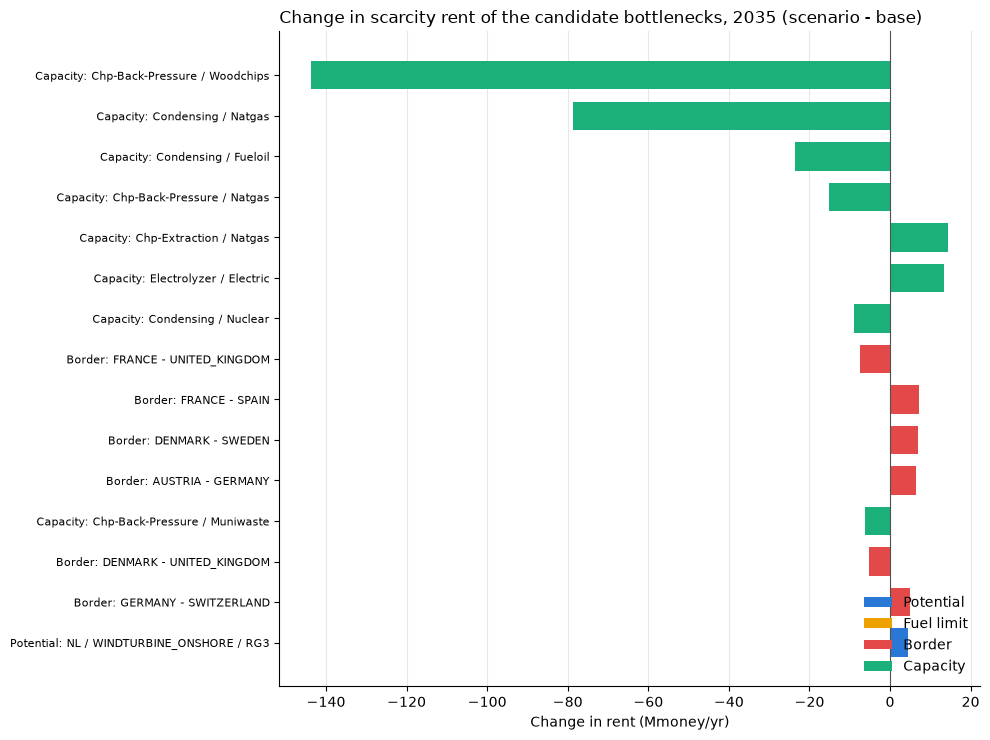

In [80]:
# 12.0 Bottleneck screening: shadow prices of the full model (all_endofmodel.gdx), scenario vs base
import gams.transfer as gt
from matplotlib.patches import Patch

BOTTLENECK_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]
TOP_N = 15                            # rows shown in the detailed tables and in the ranking

def load_endofmodel(run_dir, year):
    """Shadow prices of one run for `year`, converted to annual money: marginal * OMONEY / (IDISCOUNTFACTOR * IWEIGHTY),
    the same conversion Balmorel uses for EL_PRICE_YCRST (which additionally divides by IHOURSINST to get Money/MWh).
    Returns the screening of all equation families and the records needed for the detailed tables."""
    c = gt.Container(str(endofmodel_path(run_dir)))           # ENDOFMODEL for this scenario, all_endofmodel.gdx for the base
    scalar = lambda n: float(c[n].records["value"].iloc[0])
    by_y = lambda n: c[n].records.assign(Y=lambda d: d["Y"].astype(str)).set_index("Y")["value"]
    conv = scalar("OMONEY") / (by_y("IDISCOUNTFACTOR")[year] * by_y("IWEIGHTY")[year])
    hours = c["IHOURSINST"].records.astype({"SSS": str, "TTT": str}).set_index(["SSS", "TTT"])["value"]

    def records(name, kind="marginal"):
        r = c[name].records
        r = r.loc[r["Y"].astype(str).eq(year)].copy()
        for col in r.columns[:len(c[name].domain_names)]:
            r[col] = r[col].astype(str)
        r["value"] = r["marginal"] * conv                         # annual money per unit of the constraint
        return r

    # Screening of every equation family that has a year index
    rows = []
    for s in c.data.values():
        if not isinstance(s, gt.Equation) or s.records is None or "Y" not in s.domain_names or s.name == "QOBJ":
            continue
        r = s.records.loc[s.records["Y"].astype(str).eq(year)]
        if r.empty:
            continue
        m = r["marginal"].to_numpy() * conv
        b = (r["lower"] if s.type == "geq" else r["upper"]).to_numpy()
        rhs = np.isfinite(b) & (np.abs(b) > 1e-9)
        rows.append({"Equation": s.name, "Description": (s.description or "")[:70], "Rows": len(r),
                     "Binding": int((np.abs(m) > 1e-9).sum()),
                     "RHS rent (Mmoney)": np.abs(m[rhs] * b[rhs]).sum() / 1e6})
    screen = pd.DataFrame(rows).set_index("Equation")

    out = {"screen": screen, "conv": conv, "hours": hours}
    out["QEEQ"] = records("QEEQ")
    for n in ["QKSUBTECHGROUPR", "QKTECHGROUPR", "QGMAXCF", "QGMAXRFS", "QGKE_UP", "QWNDDISPATCH", "QSOLEDISPATCH", "QESTOVGETLIM"]:
        out[n] = records(n)
    out["VX_T"] = records("VX_T")
    vge = c["VGE_T"].records
    vge = vge.loc[vge["Y"].astype(str).eq(year)]
    out["VGE_T"] = vge.astype({col: str for col in ["Y", "AAA", "G", "SSS", "TTT"] if col in vge}).rename(columns={"SSS": "S", "TTT": "T"})
    del c
    return out

duals = {BASE_SCENARIO: load_endofmodel(BASE_RESULTS_DIR, BOTTLENECK_YEAR), SCENARIO: load_endofmodel(RUN_DIR, BOTTLENECK_YEAR)}

# --- 0. Unit check: the converted electricity-balance dual must reproduce EL_PRICE_YCRST ------------------------------
for scen, r in [(BASE_SCENARIO, base_res), (SCENARIO, res)]:
    q = duals[scen]["QEEQ"].rename(columns={"RRR": "Region", "S": "Season", "T": "Time"})
    q["Price"] = q["value"] / q.set_index(["Season", "Time"]).index.map(duals[scen]["hours"]).to_numpy()
    p = scenario_result(r, scen, "EL_PRICE_YCRST").assign(Year=lambda d: d["Year"].astype(str))
    p = p.loc[p["Year"].eq(BOTTLENECK_YEAR)].set_index(["Region", "Season", "Time"])["Value"]
    err = (q.set_index(["Region", "Season", "Time"])["Price"] - p).abs().max()
    print(f"Unit check {scen}: largest difference to EL_PRICE_YCRST {err:.2e} Money/MWh")

# --- 1. Screening of all equation families ------------------------------------------------------------------------
sb, ss = duals[BASE_SCENARIO]["screen"], duals[SCENARIO]["screen"]
screen = pd.concat({"Binding rows": pd.DataFrame({"Base": sb["Binding"], "Scenario": ss["Binding"]}),
                    "RHS rent (Mmoney/yr)": pd.DataFrame({"Base": sb["RHS rent (Mmoney)"], "Scenario": ss["RHS rent (Mmoney)"]})}, axis=1).fillna(0)
screen[("Binding rows", "Change")] = screen[("Binding rows", "Scenario")] - screen[("Binding rows", "Base")]
screen[("RHS rent (Mmoney/yr)", "Change")] = screen[("RHS rent (Mmoney/yr)", "Scenario")] - screen[("RHS rent (Mmoney/yr)", "Base")]
screen = screen.reindex(columns=[(a, b) for a in ("Binding rows", "RHS rent (Mmoney/yr)") for b in ("Base", "Scenario", "Change")])
screen.insert(0, "Description", ss["Description"].reindex(screen.index).fillna(sb["Description"]))
screen = screen.loc[screen[[("Binding rows", "Base"), ("Binding rows", "Scenario")]].max(axis=1) > 0]
screen = screen.reindex(screen[("RHS rent (Mmoney/yr)", "Change")].abs().sort_values(ascending=False).index)
print(f"1. Equation families with binding rows in {BOTTLENECK_YEAR}, largest change in RHS rent first")
display(screen.round(1))

# --- Maps from the results: area -> country, generator -> technology and fuel, region -> country -------------------
gmap = pd.concat([scenario_result(r, s, "G_CAP_YCRAF")[["Country", "Area", "Generation", "Technology", "Fuel"]]
                  for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]).drop_duplicates(["Area", "Generation"])
area_country = gmap.drop_duplicates("Area").set_index("Area")["Country"]
region_country = pd.concat([scenario_result(r, s, "EL_PRICE_YCR") for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]) \
                   .drop_duplicates("Region").set_index("Region")["Country"]

def compare(f, keys):
    """Base and scenario rent (Mmoney/yr) of a detailed family, with the change, largest change first."""
    t = pd.DataFrame({"Base": f(duals[BASE_SCENARIO]), "Scenario": f(duals[SCENARIO])}).fillna(0)
    t["Change"] = t["Scenario"] - t["Base"]
    t = t.loc[t[["Base", "Scenario"]].abs().max(axis=1) > 1e-3]
    t.index.names = keys
    return t.reindex(t["Change"].abs().sort_values(ascending=False).index)

# --- 2. Investment potentials (Mmoney/yr = value of one more MW x potential) ---------------------------------------
def potential_rent(d):
    parts = []
    for n, keys in [("QKSUBTECHGROUPR", ["RRR", "TECH_GROUP", "SUBTECH_GROUP"]), ("QKTECHGROUPR", ["RRR", "TECH_GROUP"])]:
        r = d[n].copy()
        if "SUBTECH_GROUP" not in r:
            r["SUBTECH_GROUP"] = "(all)"
        r["Rent"] = (-r["value"]).clip(lower=0) * r["upper"] / 1e6
        parts.append(r.groupby(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["Rent"].sum())
    return pd.concat(parts)
potentials = compare(potential_rent, ["Region", "Technology group", "Resource grade"])
def potential_value(d):
    r = d["QKSUBTECHGROUPR"]
    return r.set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["value"].mul(-1)
pv = pd.DataFrame({"Value per MW, base (Money/MW/yr)": potential_value(duals[BASE_SCENARIO]),
                   "Value per MW, scen. (Money/MW/yr)": potential_value(duals[SCENARIO]),
                   "Potential (MW)": duals[SCENARIO]["QKSUBTECHGROUPR"].set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["upper"]})
pv.index.names = potentials.index.names
print(f"2. Investment potentials that bind (QKSUBTECHGROUPR, QKTECHGROUPR): rent = value of one more MW x potential, Mmoney/yr, {BOTTLENECK_YEAR}")
display(potentials.join(pv).head(TOP_N).round(1))

# --- 3. Fuel and resource limits (Mmoney/yr = value of one more GJ x limit) -----------------------------------------
def fuel_rent(d):
    a = d["QGMAXCF"].assign(Rent=lambda r: (-r["value"]).clip(lower=0) * r["upper"] / 1e6).groupby(["C", "FFF"])["Rent"].sum()
    b = d["QGMAXRFS"].assign(C=lambda r: r["RRR"].map(region_country),
                             Rent=lambda r: (-r["value"]).clip(lower=0) * r["upper"] / 1e6).groupby(["C", "FFF"])["Rent"].sum()
    return a.add(b, fill_value=0)
fuels = compare(fuel_rent, ["Country", "Fuel"])
print(f"3. Fuel use limits that bind (QGMAXCF per country, QGMAXRFS per region and season, summed per country), Mmoney/yr, {BOTTLENECK_YEAR}")
display(fuels.head(TOP_N).round(1))

# --- 4. Transmission congestion (fixed line capacities: bound on VX_T), Mmoney/yr -------------------------------------
def congestion_rent(d, by_country=True):
    x = d["VX_T"].copy()
    x["Rent"] = x["value"].abs() * x["level"] / 1e6               # value of one more MW in the slice x flow (MW)
    if by_country:
        x["From"], x["To"] = x["IRRRE"].map(region_country), x["IRRRI"].map(region_country)
        x = x.loc[x["From"].ne(x["To"])]
    else:
        x["From"], x["To"] = x["IRRRE"], x["IRRRI"]
    pair = [tuple(sorted(p)) for p in zip(x["From"], x["To"])]
    return x.assign(Pair=[f"{a} - {b}" for a, b in pair]).groupby("Pair")["Rent"].sum()
lines = compare(congestion_rent, ["Border"])
hours_congested = lambda d: (d["VX_T"].assign(B=lambda r: r["value"].abs() > 1e-9)
                             .assign(Pair=lambda r: [" - ".join(sorted((region_country.get(a, a), region_country.get(b, b)))) for a, b in zip(r["IRRRE"], r["IRRRI"])])
                             .groupby("Pair")["B"].mean() * 100)
lines = lines.join(pd.DataFrame({"Congested slices, base (%)": hours_congested(duals[BASE_SCENARIO]),
                                 "Congested slices, scen. (%)": hours_congested(duals[SCENARIO])}))
print(f"4. Congestion rent on cross-border lines (|dual of the capacity bound| x flow, both directions), Mmoney/yr, {BOTTLENECK_YEAR}")
display(lines.head(TOP_N).round(1))

# Check of 4 against prices: congestion rent should be close to sum |price difference| x flow x hours (losses aside)
d = duals[SCENARIO]
p = d["QEEQ"].assign(P=lambda r: r["value"] / r.set_index(["S", "T"]).index.map(d["hours"]).to_numpy()).set_index(["RRR", "S", "T"])["P"]
x = d["VX_T"]
spread = (x.set_index(["IRRRI", "S", "T"]).index.map(p).to_numpy() - x.set_index(["IRRRE", "S", "T"]).index.map(p).to_numpy())
from_prices = np.nansum(np.abs(spread) * x["level"].to_numpy() * x.set_index(["S", "T"]).index.map(d["hours"]).to_numpy()) / 1e6
print(f"   Check {SCENARIO}: congestion rent from duals {x['value'].abs().mul(x['level']).sum() / 1e6:,.0f} Mmoney/yr, "
      f"from price spreads {from_prices:,.0f} Mmoney/yr (same order of magnitude; the duals exclude the part of the spread due to transmission losses and costs)")

# --- 5. Generation capacity scarcity (QGKE_UP: dual x electricity output in the binding slices), Mmoney/yr -----------
def capacity_rent(d):
    q = d["QGKE_UP"].loc[lambda r: r["value"].abs() > 1e-9, ["AAA", "G", "S", "T", "value"]]
    v = d["VGE_T"][["AAA", "G", "S", "T", "level"]]
    q = q.merge(v, on=["AAA", "G", "S", "T"], how="left")
    q["Rent"] = q["value"].abs() * q["level"].fillna(0) / 1e6
    q = q.merge(gmap[["Area", "Generation", "Technology", "Fuel"]], left_on=["AAA", "G"], right_on=["Area", "Generation"], how="left")
    return q.groupby([q["Technology"].fillna("?"), q["Fuel"].fillna("?")])["Rent"].sum()
capacity = compare(capacity_rent, ["Technology", "Fuel"])
print(f"5. Scarcity rent of electricity generation capacity (QGKE_UP binding), per technology and fuel, Mmoney/yr, {BOTTLENECK_YEAR}")
display(capacity.head(TOP_N).round(1))

# --- 6. Totals per category, and the potentials per technology group -------------------------------------------------
totals = pd.DataFrame({cat: t[["Base", "Scenario", "Change"]].sum() for cat, t in
                       [("Investment potentials", potentials), ("Fuel limits", fuels), ("Cross-border congestion", lines), ("Generation capacity", capacity)]}).T
pot_groups = potentials.groupby(level="Technology group")[["Base", "Scenario", "Change"]].sum().sort_values("Change", ascending=False)
pot_groups["Binding regions/grades, base"] = duals[BASE_SCENARIO]["QKSUBTECHGROUPR"].loc[lambda r: r["value"].abs() > 1e-9].groupby("TECH_GROUP").size()
pot_groups["Binding regions/grades, scen."] = duals[SCENARIO]["QKSUBTECHGROUPR"].loc[lambda r: r["value"].abs() > 1e-9].groupby("TECH_GROUP").size()
print(f"6. Total scarcity rent per category and of the investment potentials per technology group, Mmoney/yr, {BOTTLENECK_YEAR}")
display(totals.round(1))
display(pot_groups.fillna(0).round(1))

# --- 7. Ranking of the candidate bottlenecks ---------------------------------------------------------------------------
def fmt(t, cat):
    label = lambda i: " / ".join(clean_name(v) if cat == "Capacity" else str(v) for v in (i if isinstance(i, tuple) else (i,)))
    return pd.Series(t["Change"].to_numpy(), index=[f"{cat}: {label(i)}" for i in t.index])
ranking = pd.concat([fmt(potentials, "Potential"), fmt(fuels, "Fuel limit"), fmt(lines, "Border"), fmt(capacity, "Capacity")])
ranking = ranking.reindex(ranking.abs().sort_values(ascending=False).index).head(TOP_N)
cat_colors = {"Potential": "#2a78d6", "Fuel limit": "#eda100", "Border": "#e34948", "Capacity": "#1baf7a"}
fig, ax = plt.subplots(figsize=(10, 0.4 * len(ranking) + 1.5))
ax.barh(range(len(ranking))[::-1], ranking.values, color=[cat_colors[i.split(":")[0]] for i in ranking.index], height=0.7)
ax.set_yticks(range(len(ranking))[::-1]); ax.set_yticklabels(ranking.index, fontsize=8)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.legend(handles=[Patch(facecolor=c, label=k) for k, c in cat_colors.items()], frameon=False, loc="lower right")
ax.set_title(f"Change in scarcity rent of the candidate bottlenecks, {BOTTLENECK_YEAR} (scenario - base)", loc="left")
ax.set_xlabel("Change in rent (Mmoney/yr)")
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()


### 12.1 Shadow price of the electricity generation capacity
The value of one more MW of installed electricity capacity for every generator, including onshore wind, offshore wind, solar, hydro and storage, in `BOTTLENECK_YEAR` (kMoney/MW/yr, the annual system cost saving). For each generator and time slice it takes the dual of the constraint that ties the output to the capacity: `QGKE_UP` for dispatchable plants with investment or decommissioning options, `QWNDDISPATCH` and `QSOLEDISPATCH` for onshore wind, offshore wind and solar, `QESTOVGETLIM` for electricity storage, and the upper or fixed bound of `VGE_T` for generators whose capacity is purely exogenous. In a slice where that constraint holds, output = capacity x availability (or x the onshore/offshore wind and solar profile), so -dual x output / installed capacity, summed over the slices, is the saving from one more installed MW. For a dispatchable plant at full output this is the electricity price minus its variable cost, for onshore wind, offshore wind and solar the market value of the energy one more MW would produce.

The values are averaged per technology and fuel weighted by installed capacity; the labels give the share of time slices in which the output is at its capacity limit (non-zero dual with positive output), and the table also gives the maximum over the generators. All generators share the same unit and can be compared directly; for technologies the model invests in, the value should be close to their annualised investment and fixed cost (zero profit at the optimum), and clearly above it where an investment potential binds. Hydro reservoirs are additionally limited by their water (`QHYRSSEQ`), which is not included here.

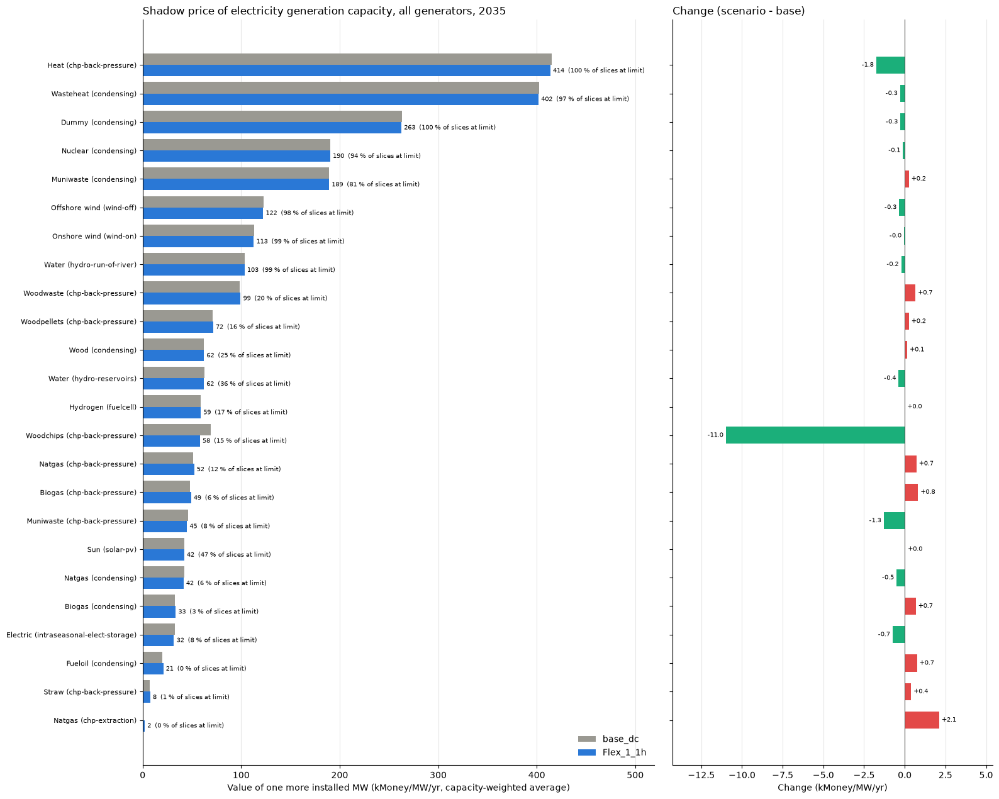

Value of one more MW of electricity generation capacity per technology and fuel (kMoney/MW/yr; capacity-weighted average and maximum over the generators), share of time slices in which the output is at its capacity limit, installed capacity, 2035


Base                     \
                                        Value    Max Binding (%)   
Heat (chp-back-pressure)                415.5  415.5       100.0   
Wasteheat (condensing)                  402.1  402.6        96.5   
Dummy (condensing)                      262.9  262.9       100.0   
Nuclear (condensing)                    190.5  298.2        93.7   
Muniwaste (condensing)                  189.0  555.5        80.5   
Offshore wind (wind-off)                122.7  166.3        98.4   
Onshore wind (wind-on)                  112.9  225.8        98.7   
Water (hydro-run-of-river)              103.7  165.4        99.4   
Woodwaste (chp-back-pressure)            98.7  293.0        20.0   
Woodpellets (chp-back-pressure)          71.3   71.3        15.2   
Wood (condensing)                        62.1   72.5        24.7   
Water (hydro-reservoirs)                 62.5  162.7        36.5   
Hydrogen (fuelcell)                      59.0   59.0        17.4   
Woodchips (chp-back-pressure)            69.2  387.7        16.5   
Natgas (chp-back-pressure)               51.5   67.0        11.3   
Biogas (chp-back-pressure)               48.3   48.3         5.8   
Muniwaste (chp-back-pressure)            46.3  729.4         8.0   
Sun (solar-pv)                           42.1   57.3        46.8   
Natgas (condensing)                      42.0  116.1         6.1   
Biogas (condensing)                      32.8   41.5         2.6   
Electric (intraseasonal-elect-storage)   32.5   50.3         8.0   
Fueloil (condensing)                     20.2   22.1         0.4   
Straw (chp-back-pressure)                 7.3  117.7         0.9   
Natgas (chp-extraction)                   0.0    0.1         0.0   

                                                     Scenario         \
                                       Capacity (GW)    Value    Max   
Heat (chp-back-pressure)                         0.0    413.8  413.8   
Wasteheat (condensing)                           0.5    401.8  402.3   
Dummy (condensing)                               0.2    262.7  262.7   
Nuclear (condensing)                            84.0    190.4  297.9   
Muniwaste (condensing)                           2.3    189.3  555.5   
Offshore wind (wind-off)                        41.0    122.3  166.3   
Onshore wind (wind-on)                         635.6    112.8  224.9   
Water (hydro-run-of-river)                      73.5    103.4  164.4   
Woodwaste (chp-back-pressure)                    0.7     99.4  294.5   
Woodpellets (chp-back-pressure)                  0.2     71.5   71.5   
Wood (condensing)                                1.3     62.3   72.6   
Water (hydro-reservoirs)                       102.7     62.1  162.7   
Hydrogen (fuelcell)                              0.0     59.0   59.0   
Woodchips (chp-back-pressure)                   13.2     58.2  387.7   
Natgas (chp-back-pressure)                      46.3     52.2   67.4   
Biogas (chp-back-pressure)                       0.1     49.1   49.1   
Muniwaste (chp-back-pressure)                    4.6     45.0  729.7   
Sun (solar-pv)                                 595.9     42.1   57.3   
Natgas (condensing)                             64.2     41.5  116.1   
Biogas (condensing)                              4.2     33.4   42.4   
Electric (intraseasonal-elect-storage)          19.5     31.8   48.7   
Fueloil (condensing)                             1.4     21.0   22.2   
Straw (chp-back-pressure)                        2.1      7.7  118.0   
Natgas (chp-extraction)                          6.8      2.1   17.7   

                                                                 Change  
                                       Binding (%) Capacity (GW)  Value  
Heat (chp-back-pressure)                     100.0           0.0   -1.8  
Wasteheat (condensing)                        96.5           0.5   -0.3  
Dummy (condensing)                           100.0           0.2   -0.3  
Nuclear (condensing)         

In [81]:
# 12.1 Shadow price of the electricity generation capacity of all generators: value of one more installed MW, base vs scenario
MIN_GEN_CAPACITY = 0.01              # GW; generators with less installed capacity are left out

OUTPUT_LIMITS = ["QGKE_UP", "QWNDDISPATCH", "QSOLEDISPATCH", "QESTOVGETLIM"]   # equations that tie a generator's output to its capacity

def generator_value(d, results, scenario):
    """Per generator: value of one more MW of installed electricity capacity (Money/MW/yr) = -sum over the time slices of
    (dual of the constraint that limits its output) x output / installed capacity. The limiting constraint is QGKE_UP for
    dispatchable plants, QWNDDISPATCH / QSOLEDISPATCH for onshore wind, offshore wind and solar, QESTOVGETLIM for storage, and the bound on VGE_T
    for generators without investment or decommissioning options (their capacity enters as VGE_T.UP or VGE_T.FX).
    In a slice where the constraint holds, output = capacity x availability (or profile), so this is the dual times the
    capacity coefficient, i.e. the cost saving of one more MW. Also returns the share of slices in which the output is at its limit."""
    keys = ["AAA", "G", "S", "T"]
    v = d["VGE_T"][keys + ["level", "marginal"]].copy()
    v["Dual"] = v["marginal"] * d["conv"]                                  # bound on VGE_T, annual money
    for n in OUTPUT_LIMITS:
        q = d[n][keys + ["value"]].groupby(keys)["value"].sum().rename(n)
        v = v.join(q, on=keys)
        v["Dual"] += v[n].fillna(0)
    v["Saving"] = -v["Dual"] * v["level"]                                  # Money/yr per generator and slice
    v["B"] = (v["Dual"].abs() > 1e-9) & (v["level"] > 1e-6)              # output limited (a dual at zero output is a lower bound)
    g = v.groupby(["AAA", "G"]).agg(Saving=("Saving", "sum"), Binding=("B", "mean"))
    cap = scenario_result(results, scenario, "G_CAP_YCRAF")
    cap = cap.loc[cap["Year"].astype(str).eq(BOTTLENECK_YEAR) & cap["Commodity"].eq("ELECTRICITY")].groupby(["Area", "Generation"])["Value"].sum()
    cap.index.names = ["AAA", "G"]
    g = g.join(cap.rename("Capacity (GW)"), how="inner")
    g = g.loc[g["Capacity (GW)"] >= MIN_GEN_CAPACITY]
    g["Value"] = g["Saving"] / (g["Capacity (GW)"] * 1e3)                  # Money per installed MW per year
    g = g.reset_index()
    return g.merge(gmap[["Area", "Generation", "Technology", "Fuel", "Country"]], left_on=["AAA", "G"], right_on=["Area", "Generation"], how="left")

def by_tech(g):
    """Capacity-weighted average per technology and fuel (kMoney/MW/yr and % of slices binding), plus the maximum."""
    w = g["Capacity (GW)"]
    g = g.assign(VW=g["Value"] * w, BW=g["Binding"] * w)
    t = g.groupby(["Technology", "Fuel"]).agg(VW=("VW", "sum"), BW=("BW", "sum"), W=("Capacity (GW)", "sum"), Max=("Value", "max"))
    return pd.DataFrame({"Value": t["VW"] / t["W"] / 1e3, "Max": t["Max"] / 1e3, "Binding (%)": t["BW"] / t["W"] * 100, "Capacity (GW)": t["W"]})

gen_value = {s: generator_value(duals[s], r, s) for s, r in [(BASE_SCENARIO, base_res), (SCENARIO, res)]}
gen_tech = pd.concat({"Base": by_tech(gen_value[BASE_SCENARIO]), "Scenario": by_tech(gen_value[SCENARIO])}, axis=1)
gen_tech[("Change", "Value")] = gen_tech[("Scenario", "Value")].fillna(0) - gen_tech[("Base", "Value")].fillna(0)
gen_tech = gen_tech.loc[gen_tech[[("Base", "Value"), ("Scenario", "Value")]].abs().max(axis=1) > 0.05]
gen_tech = gen_tech.sort_values(("Scenario", "Value"))
labels = [f"{clean_name(f)} ({t.lower()})" for t, f in gen_tech.index]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 0.45 * len(gen_tech) + 2), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(gen_tech))
ax.barh(y + 0.2, gen_tech[("Base", "Value")].fillna(0), height=0.4, color="#9a9992", label=BASE_SCENARIO)
ax.barh(y - 0.2, gen_tech[("Scenario", "Value")].fillna(0), height=0.4, color="#2a78d6", label=SCENARIO)
for i, (v, b) in enumerate(zip(gen_tech[("Scenario", "Value")].fillna(0), gen_tech[("Scenario", "Binding (%)")].fillna(0))):
    ax.annotate(f"{v:,.0f}  ({b:.0f} % of slices at limit)", (v, i - 0.2), va="center", fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Value of one more installed MW (kMoney/MW/yr, capacity-weighted average)")
ax.set_title(f"Shadow price of electricity generation capacity, all generators, {BOTTLENECK_YEAR}", loc="left")
ax.legend(frameon=False, loc="lower right")
ch = gen_tech[("Change", "Value")]
ax2.barh(y, ch, height=0.6, color=np.where(ch >= 0, "#e34948", "#1baf7a"))
for i, v in enumerate(ch):
    ax2.annotate(f"{v:+,.1f}", (v, i), va="center", ha="left" if v >= 0 else "right", fontsize=7, xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("Change (kMoney/MW/yr)"); ax2.set_title("Change (scenario - base)", loc="left")
for a in (ax, ax2):
    a.grid(axis="x", alpha=0.3); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
ax.margins(x=0.25); ax2.margins(x=0.25)
plt.tight_layout(); plt.show()

print(f"Value of one more MW of electricity generation capacity per technology and fuel (kMoney/MW/yr; capacity-weighted average "
      f"and maximum over the generators), share of time slices in which the output is at its capacity limit, installed capacity, {BOTTLENECK_YEAR}")
t = gen_tech.iloc[::-1].copy()
t.index = labels[::-1]
display(t.round(1))


### 12.2 Map of the binding investment potentials
Where the investment potential of `POTENTIAL_GROUP` (default: onshore wind) binds in `BOTTLENECK_YEAR`, from the shadow prices of `QKSUBTECHGROUPR` loaded in 12. 
- **Colour and label**: the value of one more MW of potential (kMoney/MW/yr, the annual system cost saving, on top of the cost of the turbine), averaged over the region's resource grades with non-binding grades counted as zero; in brackets the number of binding grades (non-zero shadow price). Both panels share the colour scale; the table also gives the value in the most valuable grade.
- **Light grey**: no grade of the region binds. **Black outline**: the region binds only in the scenario (all other coloured regions bind in both runs).

The average is not weighted by potential, because the right-hand side of `QKSUBTECHGROUPR` is the remaining potential (potential minus existing capacity): grades already filled by existing turbines have zero remaining potential but can have a high shadow price (e.g. Malta, Cyprus, Norway). For the same reason their scarcity rent in 12.0 (shadow price x remaining potential) is zero.

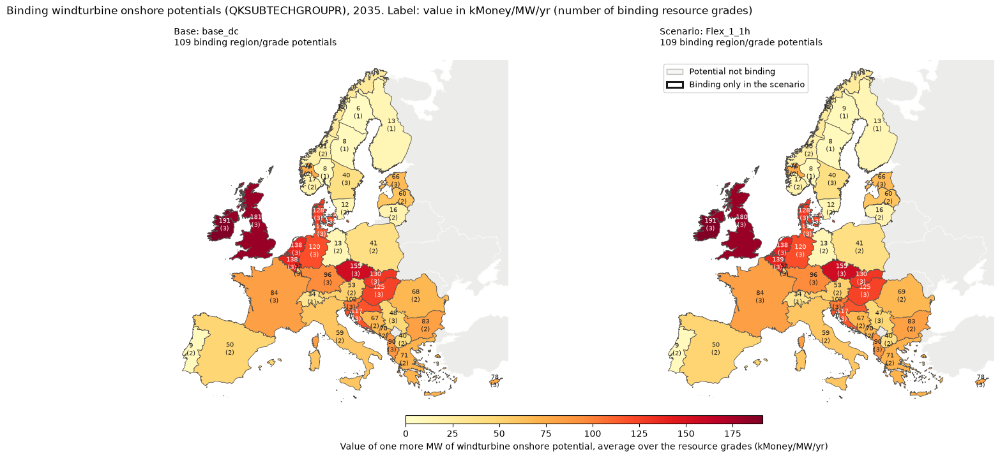

Value of one more MW of windturbine onshore potential (kMoney/MW/yr: average over the grades and most valuable grade) and number of binding grades per region


Base                   Scenario            \
                             Value Max grade Binding    Value Max grade   
SE1 (Sweden)                   5.6      16.7       1      9.0      26.9   
BE (Belgium)                 138.4     151.3       3    139.0     152.1   
NL (Netherlands)             137.5     156.3       3    138.0     156.8   
MT (Malta)                   139.1     141.3       3    139.4     141.6   
ES (Spain)                    49.9     117.2       2     50.1     117.6   
PT (Portugal)                  8.7      23.6       2      8.8      23.7   
RO (Romania)                  68.5     152.1       2     68.6     152.3   
FR (France)                   84.0     126.1       3     84.0     126.2   
AL (Albania)                  89.6     119.6       3     89.6     119.7   
IE (Ireland)                 190.8     204.8       3    190.8     204.8   
SI (Slovenia)                101.5     135.3       3    101.5     135.4   
LV (Latvia)                   60.3      94.5       2     60.3      94.5   
MK (North Macedonia)          40.3      74.3       2     40.3      74.2   
FIN (Finland)                 13.2      39.6       1     13.2      39.6   
NO1 (Norway)                   7.9      23.6       1      7.9      23.6   
BA (Bosnia And Herzegovina)   67.2     102.3       2     67.2     102.3   
LT (Lithuania)                15.8      39.2       2     15.8      39.2   
AT (Austria)                  52.7      99.2       2     52.7      99.1   
PL (Poland)                   40.6      93.9       2     40.6      93.8   
CZ (Czech Republic)          155.4     190.1       3    155.3     190.0   
CY (Cyprus)                   77.8      89.2       3     77.7      89.2   
CH (Switzerland)              33.9     101.8       1     33.9     101.7   
EE (Estonia)                  66.4      97.7       3     66.4      97.7   
RS (Serbia)                   47.5      68.0       3     47.5      68.0   
NO2 (Norway)                  17.4      40.6       2     17.4      40.5   
ME (Montenegro)               70.1     122.8       2     70.0     122.7   
SK (Slovakia)                130.2     154.4       3    130.1     154.3   
LU (Luxembourg)               51.8     103.0       3     51.7     102.9   
NO4 (Norway)                  26.9      48.4       2     26.8      48.3   
HU (Hungary)                 124.7     146.4       3    124.6     146.5   
SE3 (Sweden)                  39.8      77.0       3     39.8      77.0   
DE4-S (Germany)               95.7     136.5       3     95.6     136.4   
DE4-E (Germany)               12.9      30.3       2     12.8      30.2   
IT (Italy)                    59.2     128.2       2     59.1     128.0   
NO3 (Norway)                  20.6      45.5       2     20.5      45.2   
GR (Greece)                   71.0     153.8       2     70.9     153.5   
SE4 (Sweden)                  12.1      29.9       2     11.9      29.8   
DE4-W (Germany)              119.8     135.3       3    119.7     135.1   
DK2 (Denmark)                120.9     133.0       3    120.8     132.8   
NO5 (Norway)                  75.9     123.6       2     75.7     123.3   
BG (Bulgaria)                 83.4     143.4       2     83.2     143.1   
DK1 (Denmark)                128.1     141.8       3    127.9     141.6   
SE2 (Sweden)                   8.2      24.7       1      8.0      23.9   
HR (Croatia)                 117.2     151.9       3    116.9     151.6   
DE4-N (Germany)              117.0     128.8       3    116.6     128.5   
UK (United Kingdom)          181.0     210.0       3    180.5     209.1   

                                    Change  
                            Binding  Value  
SE1 (Sweden)                      1    3.4  
BE (Belgium)                      3    0.6  
NL (Netherlands)                  3    0.5  
MT (Malta)                        3    0.3  
ES (Spain)                        2    0.2  
PT (Portugal)                     2    0.1  
RO (Romania)                      2    0.1  
FR (France)             

In [82]:
# 12.2 Map of the binding investment potentials of one technology group: value of one more MW, base vs scenario
import geopandas as gpd
import pybalmorel
from matplotlib.colors import Normalize

POTENTIAL_GROUP = "WINDTURBINE_ONSHORE"      # any TECH_GROUP of QKSUBTECHGROUPR, e.g. "SOLARPV"

def potential_by_region(d):
    """Per region: value of one more MW of potential averaged over the resource grades (non-binding grades count as 0,
    kMoney/MW/yr), the value in the most valuable grade, and the number of binding grades (non-zero shadow price).
    A simple average is used because the right-hand side of QKSUBTECHGROUPR is the remaining potential (potential minus
    existing capacity), which is zero or negative for grades already filled by existing turbines although their shadow
    price can be high, so it cannot serve as a weight."""
    r = d["QKSUBTECHGROUPR"].loc[lambda t: t["TECH_GROUP"].eq(POTENTIAL_GROUP)].assign(V=lambda t: (-t["value"]).clip(lower=0))
    g = r.groupby("RRR")["V"]
    return pd.DataFrame({"Value": g.mean() / 1e3, "Max grade": g.max() / 1e3,
                         "Binding": r.loc[r["V"] > 1e-6].groupby("RRR").size()}).fillna({"Binding": 0})

pot_map = {s: potential_by_region(duals[s]) for s in (BASE_SCENARIO, SCENARIO)}
geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
modelled = geo["id"].isin(region_country.index)
vmax = max(t["Value"].max() for t in pot_map.values()) or 1
norm = Normalize(vmin=0, vmax=vmax)
newly = pot_map[SCENARIO].index[(pot_map[SCENARIO]["Binding"] > 0) & (pot_map[BASE_SCENARIO]["Binding"].reindex(pot_map[SCENARIO].index, fill_value=0) == 0)]

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
for ax, scen in zip(axes, (BASE_SCENARIO, SCENARIO)):
    t = pot_map[scen]
    g = geo[modelled].assign(Value=lambda d: d["id"].map(t["Value"]).fillna(0), Binding=lambda d: d["id"].map(t["Binding"]).fillna(0))
    geo[~modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    g.loc[g["Binding"].eq(0)].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5)              # potential not binding
    g.loc[g["Binding"].gt(0)].plot(ax=ax, column="Value", cmap="YlOrRd", norm=norm, edgecolor="#52514e", linewidth=0.6)
    if scen == SCENARIO and len(newly):
        g.loc[g["id"].isin(newly)].boundary.plot(ax=ax, color="#1a1a1a", linewidth=2.2)                     # binding only in the scenario
    for _, row in g.loc[g["Binding"].gt(0)].iterrows():
        part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda p: p.area)
        pt = part.representative_point()
        ax.annotate(f"{row['Value']:.0f}\n({int(row['Binding'])})", (pt.x, pt.y), ha="center", va="center", fontsize=7,
                    color="white" if row["Value"] > 0.6 * vmax else "#1a1a1a")
    minx, miny, maxx, maxy = g.geometry.apply(lambda x: max(getattr(x, "geoms", [x]), key=lambda p: p.area)).total_bounds
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    n_bind = int(t["Binding"].sum())
    ax.set_title(f"{'Base' if scen == BASE_SCENARIO else 'Scenario'}: {scen}\n{n_bind} binding region/grade potentials", loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm), ax=axes, orientation="horizontal", shrink=0.4, pad=0.02, aspect=40,
             label=f"Value of one more MW of {clean_name(POTENTIAL_GROUP).lower()} potential, average over the resource grades (kMoney/MW/yr)")
axes[1].legend(handles=[Patch(facecolor="#f6f6f4", edgecolor="#b5b4ae", label="Potential not binding"),
                        Patch(facecolor="white", edgecolor="#1a1a1a", linewidth=2.2, label="Binding only in the scenario")],
               loc="upper left", frameon=True, framealpha=0.9, fontsize=9)
fig.suptitle(f"Binding {clean_name(POTENTIAL_GROUP).lower()} potentials (QKSUBTECHGROUPR), {BOTTLENECK_YEAR}. "
             "Label: value in kMoney/MW/yr (number of binding resource grades)", x=0.01, ha="left")
plt.show()

table = pd.concat({"Base": pot_map[BASE_SCENARIO], "Scenario": pot_map[SCENARIO]}, axis=1).fillna(0)
table = table.loc[table[[("Base", "Binding"), ("Scenario", "Binding")]].max(axis=1) > 0]
table[("Change", "Value")] = table[("Scenario", "Value")] - table[("Base", "Value")]
table = table.sort_values(("Change", "Value"), ascending=False)
table.index = [f"{r} ({clean_name(region_country.get(r, ''))})" for r in table.index]
print(f"Value of one more MW of {clean_name(POTENTIAL_GROUP).lower()} potential (kMoney/MW/yr: average over the grades and most valuable grade) and number of binding grades per region")
display(table.round(1))


### 12.3 Renewable investment potentials: potential vs installed capacity
For onshore wind, offshore wind and solar PV, the investment potential of each country (`SUBTECHGROUPKPOT`, summed over its regions and resource grades) next to the capacity installed in the base and in the scenario in `BOTTLENECK_YEAR` (GW). The installed capacity is existing plus new capacity counted against the potential, taken from `QKSUBTECHGROUPR` (installed = potential - remaining room). "Regions full" counts the regions in which every resource grade is fully used in the scenario (less than 0.1 % or 1 MW left). **Highlighted**: the whole national potential of that technology is installed in the scenario, in orange if it was already fully installed in the base and in red if it becomes full only in the scenario. Countries with at least one fully used technology are listed first.

In [83]:
# 12.3 Renewable investment potentials: potential vs installed capacity per country, base and scenario (GW)
POTENTIAL_GROUPS = {"WINDTURBINE_ONSHORE": "Onshore wind", "WINDTURBINE_OFFSHORE": "Offshore wind", "SOLARPV": "Solar PV"}
FULL_TOLERANCE = 0.001               # a region/grade counts as full when less than 0.1 % (or 1 MW) of its potential is left

kpot = gt.Container()
kpot.read(str(RUN_DIR / ENDOFMODEL), symbols=["SUBTECHGROUPKPOT"])
kpot = kpot["SUBTECHGROUPKPOT"].records.astype({"CCCRRRAAA": str, "TECH_GROUP": str, "SUBTECH_GROUP": str}) \
           .rename(columns={"CCCRRRAAA": "RRR", "value": "Potential"}).set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["Potential"]

def installed_by_grade(d):
    """Installed capacity per region, technology group and grade (MW), from QKSUBTECHGROUPR:
    existing + new capacity <= potential, where GAMS moves the existing capacity to the right-hand side, so
    installed = potential - (right-hand side - level) = potential - remaining room."""
    q = d["QKSUBTECHGROUPR"].set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])
    return (kpot.reindex(q.index) - (q["upper"] - q["level"])).rename("Installed")

grades = pd.concat({"Potential": kpot, "Base": installed_by_grade(duals[BASE_SCENARIO]),
                    "Scenario": installed_by_grade(duals[SCENARIO])}, axis=1).dropna(subset=["Potential"])
grades = grades.loc[grades.index.get_level_values("TECH_GROUP").isin(POTENTIAL_GROUPS)].fillna(0)
is_full = lambda col: (grades["Potential"] - grades[col]) <= np.maximum(1.0, FULL_TOLERANCE * grades["Potential"])
grades["Full"], grades["FullBase"] = is_full("Scenario"), is_full("Base")

# Per region (summed over the grades): full when every grade with potential is full
regions = grades.groupby(level=["RRR", "TECH_GROUP"]).agg(Potential=("Potential", "sum"), Base=("Base", "sum"),
                                                           Scenario=("Scenario", "sum"), Full=("Full", "all"), FullBase=("FullBase", "all"))
regions = regions.loc[regions["Potential"] > 1e-6]
regions["Country"] = regions.index.get_level_values("RRR").map(region_country)

# Per country: GW, share of the potential installed, number of regions that are full in the scenario
country = regions.groupby(["Country", regions.index.get_level_values("TECH_GROUP")]).agg(
    Potential=("Potential", "sum"), Base=("Base", "sum"), Scenario=("Scenario", "sum"),
    Full_regions=("Full", "sum"), Full_regions_base=("FullBase", "sum"), Regions=("Full", "size"))
country[["Potential", "Base", "Scenario"]] /= 1e3                                   # GW
country["Scenario (% of potential)"] = country["Scenario"] / country["Potential"] * 100
country["Full in scenario"] = country["Full_regions"] == country["Regions"]
country["Full in base"] = country["Full_regions_base"] == country["Regions"]
country["Regions full (scen.)"] = country["Full_regions"].astype(int).astype(str) + "/" + country["Regions"].astype(str)

cols = ["Potential", "Base", "Scenario", "Scenario (% of potential)", "Regions full (scen.)"]
pot_table = country[cols].unstack("TECH_GROUP")
pot_table.columns = pot_table.columns.swaplevel(0, 1)
pot_table = pot_table.reindex(columns=[(g, c) for g in POTENTIAL_GROUPS if g in country.index.get_level_values(1) for c in cols])
pot_table = pot_table.rename(columns=POTENTIAL_GROUPS, level=0)
flag = lambda col: country[col].unstack("TECH_GROUP").reindex(columns=list(POTENTIAL_GROUPS)).rename(columns=POTENTIAL_GROUPS).fillna(False).astype(bool)
full, full_base = flag("Full in scenario"), flag("Full in base")
pot_table.index = [clean_name(c) for c in pot_table.index]
full.index = [clean_name(c) for c in full.index]
full_base.index = [clean_name(c) for c in full_base.index]
pot_table = pot_table.loc[full.any(axis=1).sort_values(ascending=False).index]          # countries with a full technology first

def highlight_full(df):
    """Technology block of a country where the whole potential is installed in the scenario: orange if it was already
    full in the base, red if it becomes full only in the scenario."""
    style = pd.DataFrame("", index=df.index, columns=df.columns)
    for tech in full.columns:
        if tech in df.columns.get_level_values(0):
            both = full.index[full[tech] & full_base[tech].reindex(full.index, fill_value=False)].intersection(df.index)
            new = full.index[full[tech] & ~full_base[tech].reindex(full.index, fill_value=False)].intersection(df.index)
            style.loc[both, tech] = "background-color: #f9c8a7; font-weight: bold"
            style.loc[new, tech] = "background-color: #e34948; color: white; font-weight: bold"
    return style

n_full, n_new = full.sum(), (full & ~full_base.reindex_like(full).fillna(False)).sum()
print(f"Renewable potentials and installed capacity (GW), {BOTTLENECK_YEAR}. Highlighted: the whole national potential of the technology is "
      f"installed in the scenario; orange = already full in the base, red = full only in the scenario. "
      + "; ".join(f"{t}: {n} countries full, of which {n_new[t]} new" for t, n in n_full.items()))
fmt = {c: ("{:.0f} %" if c[1].startswith("Scenario (%") else "{}" if c[1].startswith("Regions") else "{:,.1f}") for c in pot_table.columns}
display(pot_table.style.apply(highlight_full, axis=None).format(fmt, na_rep="-"))


Renewable potentials and installed capacity (GW), 2035. Highlighted: the whole national potential of the technology is installed in the scenario; orange = already full in the base, red = full only in the scenario. Onshore wind: 15 countries full, of which 0 new; Offshore wind: 0 countries full, of which 0 new; Solar PV: 6 countries full, of which 0 new


### 12.4 Scale of the potential bottlenecks per type of constraint
Shadow prices have different units for different constraints (Money/MW of potential, Money/GJ of fuel, Money/MW in a time slice, ...), so they are compared through the **scarcity rent**: |shadow price| x the exogenous limit of the constraint (Mmoney/yr), i.e. the right-hand-side rent of 12.0 part 1, with the equation families grouped into types of bottleneck (`BOTTLENECK_TYPE`). For transmission the limit is the fixed line capacity (upper bound of `VX_T`, all lines). Energy balances, onshore/offshore wind and solar dispatch definitions and transport balances are left out, because their duals value demand or existing output rather than a limit.

The rent measures how valuable the limit is at the margin, summed over the whole limit; it is not a cost paid by the system, and the rents of different types should be read as orders of magnitude, not added up.

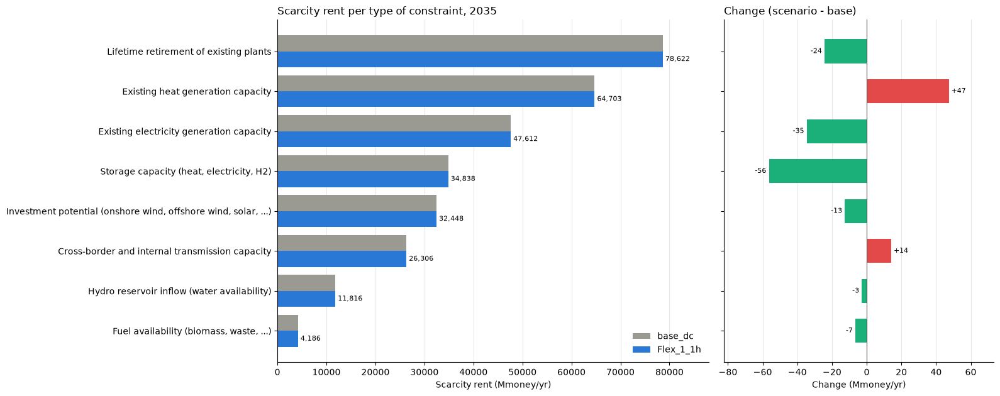

Scarcity rent (Mmoney/yr) and number of binding rows per type of constraint, 2035


,Base,Scenario,Change,"Binding rows, base","Binding rows, scen."
Type of constraint,,,,,
Lifetime retirement of existing plants,78646.6,78622.3,-24.3,1237,1237
Existing heat generation capacity,64655.3,64702.6,47.3,1207848,1199641
Existing electricity generation capacity,47646.4,47611.8,-34.6,689060,629387
"Storage capacity (heat, electricity, H2)",34894.6,34838.2,-56.4,186188,183713
"Investment potential (onshore wind, offshore wind, solar, ...)",32460.8,32448.2,-12.6,251,251
Cross-border and internal transmission capacity,26291.4,26305.5,14.1,109147,109269
Hydro reservoir inflow (water availability),11818.3,11815.5,-2.8,120,120
"Fuel availability (biomass, waste, ...)",4192.0,4185.5,-6.5,157,160


In [84]:
# 12.4 Scale of the potential bottlenecks: scarcity rent per type of constraint (Mmoney/yr), base vs scenario
# Equation families grouped into bottleneck types. Rent = |shadow price| x exogenous limit (right-hand side), as in 12.0 part 1;
# for transmission the limit is the fixed line capacity (upper bound of VX_T).
BOTTLENECK_TYPE = {
    "QKSUBTECHGROUPR": "Investment potential (onshore wind, offshore wind, solar, ...)", "QKTECHGROUPR": "Investment potential (onshore wind, offshore wind, solar, ...)",
    "QGMAXCF": "Fuel availability (biomass, waste, ...)", "QGMAXRFS": "Fuel availability (biomass, waste, ...)",
    "QGKE_UP": "Existing electricity generation capacity", "QGKH_UP": "Existing heat generation capacity",
    "QGCVGEXT": "Existing heat generation capacity", "QGCBGBPRBYPASS2": "Existing heat generation capacity",
    "QDECOM_EXO_ACCUM_REST": "Lifetime retirement of existing plants", "QDECOM_ENDO_ACCUM_REST": "Lifetime retirement of existing plants",
    "QHYRSSEQ": "Hydro reservoir inflow (water availability)",
    "QHSTOVGHTLIM": "Storage capacity (heat, electricity, H2)", "QHSTOVOLTLIM": "Storage capacity (heat, electricity, H2)",
    "QHSTOLOADTLIM": "Storage capacity (heat, electricity, H2)", "QESTOVGETLIM": "Storage capacity (heat, electricity, H2)",
    "QESTOVOLTLIM": "Storage capacity (heat, electricity, H2)", "QESTOLOADTLIM": "Storage capacity (heat, electricity, H2)",
    "QHYDROGEN_STOMAXCON": "Storage capacity (heat, electricity, H2)", "QHYDROGEN_STOMAXUNLD": "Storage capacity (heat, electricity, H2)",
    "QXH2K_UP": "H2 transmission capacity",
}
# Not bottlenecks, left out: energy balances (QEEQ, QHEQ, QHYDROGEN_EQ value the demand), onshore/offshore wind and solar dispatch definitions
# (QWNDDISPATCH, QSOLEDISPATCH, QSOLHDISPATCH value the output of existing VRE), transport and EV balances, and the
# upper limit on retiring existing plants (QDECOM_EXO_LIM: the model would retire more capacity than exists).

def rent_by_type(d):
    s = d["screen"]
    t = s.loc[s.index.isin(BOTTLENECK_TYPE.keys()), "RHS rent (Mmoney)"].groupby(lambda n: BOTTLENECK_TYPE[n]).sum()
    x = d["VX_T"]
    t["Cross-border and internal transmission capacity"] = (x["value"].abs() * x["upper"].where(np.isfinite(x["upper"]), 0)).sum() / 1e6
    n = s.loc[s.index.isin(BOTTLENECK_TYPE.keys()), "Binding"].groupby(lambda e: BOTTLENECK_TYPE[e]).sum()
    n["Cross-border and internal transmission capacity"] = int((x["value"].abs() > 1e-9).sum())
    return t, n

(rb, nb_), (rs, ns) = rent_by_type(duals[BASE_SCENARIO]), rent_by_type(duals[SCENARIO])
types = pd.DataFrame({"Base": rb, "Scenario": rs}).fillna(0)
types["Change"] = types["Scenario"] - types["Base"]
types["Binding rows, base"], types["Binding rows, scen."] = nb_, ns
types = types.loc[types[["Base", "Scenario"]].max(axis=1) > 0.5].sort_values("Scenario")
types.index.name = "Type of constraint"

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 0.55 * len(types) + 2), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(types))
ax.barh(y + 0.2, types["Base"], height=0.4, color="#9a9992", label=BASE_SCENARIO)
ax.barh(y - 0.2, types["Scenario"], height=0.4, color="#2a78d6", label=SCENARIO)
for i, (b, s) in enumerate(zip(types["Base"], types["Scenario"])):
    ax.annotate(f"{s:,.0f}", (s, i - 0.2), va="center", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_yticks(y); ax.set_yticklabels(types.index)
ax.set_xlabel("Scarcity rent (Mmoney/yr)")
ax.set_title(f"Scarcity rent per type of constraint, {BOTTLENECK_YEAR}", loc="left")
ax.legend(frameon=False, loc="lower right")
ch = types["Change"]
ax2.barh(y, ch, height=0.6, color=np.where(ch >= 0, "#e34948", "#1baf7a"))
for i, v in enumerate(ch):
    ax2.annotate(f"{v:+,.0f}", (v, i), va="center", ha="left" if v >= 0 else "right", fontsize=8, xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("Change (Mmoney/yr)")
ax2.set_title("Change (scenario - base)", loc="left")
for a in (ax, ax2):
    a.grid(axis="x", alpha=0.3); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
ax.margins(x=0.12); ax2.margins(x=0.25)
plt.tight_layout(); plt.show()

print(f"Scarcity rent (Mmoney/yr) and number of binding rows per type of constraint, {BOTTLENECK_YEAR}")
display(types.iloc[::-1].round(1))


## 13. Flexible loads: base vs scenario
The electricity demands whose timing is chosen by the model, i.e. the flexible loads of this setup (`base/model/balopt.opt`), compared between the base and the scenario:

| Flexible load | Category in `EL_DEMAND_YCR(ST)` | Where the flexibility comes from |
|---|---|---|
| EV charging and V2G | `ENDO_EV` (net of V2G) | Smart charging within the EV battery limits (`EV`, `EV_INTERSEASONAL`), discharging to the grid (`V2G`) |
| Power-to-heat | `ENDOGENOUS_ELECT2HEAT` | Heat pumps and electric boilers (`ELECT-TO-HEAT`) with heat storage |
| Electrolysis | `ENDO_H2` | Electrolysers with H2 storage and the H2 grid; the H2 demand itself is fixed |
| Storage charging | `ENDO_INTRASTO` | Charging of the electricity storage (`INTRASEASONAL-ELECT-STORAGE`) |

Not flexible here: the exogenous demand (fixed profile), CCS (follows the CCS plants), and the switched-off options `DEMANDRESPONSE`, `DFLEXQUANT`, `flexible_h2_space` and `DCFLEX`.

The time-step results (`*_YCRST`) are MWh per hour of the step, i.e. average MW, so the two runs can be compared directly even when their time steps differ in length: a step lasts `FLEX_STEP_H` hours (`CHRONOHOUR`, from 13.1 in a CHRONOHOUR study, otherwise from each run's `data/CHRONOHOUR.inc` or `base/data`), and a season block covers card(T) × `FLEX_STEP_H` hours. The regional EV demand per step is net of V2G, so its positive part is shown as charging and its negative part as V2G. The hourly charts, the price metrics and the maps are for `FLEX_YEAR` (= `FOCUS_YEAR`, 2035).

In [85]:
# 13.0 Flexible loads: settings and the time-step results of both runs in FLEX_YEAR
import gams.transfer as gt
import geopandas as gpd
import pybalmorel
from matplotlib.colors import Normalize, TwoSlopeNorm

FLEX_YEAR = FOCUS_YEAR                                       # year of the hourly charts, the price metrics and the maps
FLEX_LOADS = {"ENDOGENOUS_ELECT2HEAT": "Power-to-heat", "ENDO_H2": "Electrolysis", "ENDO_EV": "EV charging",
              "ENDO_INTRASTO": "Storage charging"}           # flexible categories of EL_DEMAND_YCR / EL_DEMAND_YCRST
FLEX_ORDER = list(FLEX_LOADS.values())                       # stacking order; V2G is drawn below zero
FLEX_COLORS = {"Power-to-heat": "#1baf7a", "Electrolysis": "#4a3aa7", "EV charging": "#eb6834",
               "Storage charging": "#e34948", "V2G": "#f2a477"}
FLEX_SOC = {"INTRASEASONAL-HEAT-STORAGE": "Heat storage (intra-seasonal)", "H2-STORAGE": "H2 storage",
            "INTRASEASONAL-ELECT-STORAGE": "Electricity storage"}   # storage types with a level in STORAGE_LEVEL
FLEX_VRE = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]
FLEX_RUNS = {BASE_SCENARIO: BASE_RESULTS_DIR / BASE_RESULTS, SCENARIO: RUN_DIR / RESULTS}
FLEX_SYMBOLS = ["EL_DEMAND_YCRST", "EL_PRICE_YCRST", "PRO_YCRAGFST", "STORAGE_LEVEL"]
FLEX_RENAME = {**RENAME, "SSS": "Season", "TTT": "Time", "VARIABLE_CATEGORY": "Category", "value": "Value"}
FLEX_KEYS = ["Region", "Season", "Time"]

def flex_read(path):
    """FLEX_SYMBOLS of one run in FLEX_YEAR, with string labels and the column names of 0.2."""
    c = gt.Container()
    c.read(str(path), symbols=FLEX_SYMBOLS)
    out = {}
    for s in FLEX_SYMBOLS:
        r = c[s].records
        r = r.loc[r["Y"].astype(str).eq(FLEX_YEAR)]
        out[s] = r.astype({col: str for col in r.columns[:-1]}).rename(columns=FLEX_RENAME)
    out["PRO_YCRAGFST"] = out["PRO_YCRAGFST"].loc[lambda d: d["Technology"].isin(FLEX_VRE)]
    del c
    return out

flex_raw = {run: flex_read(path) for run, path in FLEX_RUNS.items()}
FLEX_SEASONS = sorted(flex_raw[SCENARIO]["EL_PRICE_YCRST"]["Season"].unique())
FLEX_TIMES = {run: sorted(flex_raw[run]["EL_PRICE_YCRST"]["Time"].unique()) for run in FLEX_RUNS}   # time steps of each run
# Hours per time step (CHRONOHOUR) of each run: from 13.1 in a CHRONOHOUR study (where both runs share the same data/),
# otherwise CHRONOHOUR(S,T) of the run's data/CHRONOHOUR.inc with card(T) filled in
def flex_step_hours(data_dir, n_t):
    inc = data_dir / "CHRONOHOUR.inc"
    m = re.search(r"(?im)^\s*CHRONOHOUR\(S,T\)\s*=\s*([^;]+);", inc.read_text()) if inc.exists() else None
    if m:
        expr = re.sub(r"(?i)card\(T\)", str(n_t), m.group(1))
        if re.fullmatch(r"[\d.\s+\-*/()]+", expr):
            return float(eval(expr))
    return 168 / n_t

FLEX_STEP_H = globals().get("CH_STEP") or {BASE_SCENARIO: flex_step_hours(BASE_DIR / "data", len(FLEX_TIMES[BASE_SCENARIO])),
                                           SCENARIO: flex_step_hours(SCENARIO_DIR / "data", len(FLEX_TIMES[SCENARIO]))}

def flex_hourly(run):
    """Per region, season and time step (MW): the flexible loads (EV charging and V2G = positive and negative part of the
    regional net EV demand), the total electricity demand and the onshore + offshore wind + solar generation; and the price (Money/MWh)."""
    d = flex_raw[run]
    price = d["EL_PRICE_YCRST"].set_index(FLEX_KEYS)["Value"]
    dem = d["EL_DEMAND_YCRST"].pivot_table(index=FLEX_KEYS, columns="Category", values="Value", aggfunc="sum", fill_value=0)
    dem = dem.reindex(price.index, fill_value=0)
    ev = dem["ENDO_EV"] if "ENDO_EV" in dem else pd.Series(0.0, index=dem.index)
    t = pd.DataFrame({name: dem[cat] if cat in dem else 0.0 for cat, name in FLEX_LOADS.items() if cat != "ENDO_EV"}, index=dem.index)
    t["EV charging"] = ev.clip(lower=0)
    t["V2G"] = -ev.clip(upper=0)
    t["Total demand"] = dem.sum(axis=1)
    t["Onshore + offshore wind + solar"] = d["PRO_YCRAGFST"].groupby(FLEX_KEYS)["Value"].sum().reindex(t.index, fill_value=0)
    t["Price"] = price
    return t

flex_h = {run: flex_hourly(run) for run in FLEX_RUNS}
for run in FLEX_RUNS:
    print(f"{run}: {FLEX_STEP_H[run]:.3f} h per step, {len(FLEX_SEASONS)} seasons x {len(FLEX_TIMES[run])} steps in {FLEX_YEAR}")

base_dc: 1.000 h per step, 4 seasons x 168 steps in 2035
Flex_1_1h: 1.000 h per step, 4 seasons x 168 steps in 2035


### 13.1 Overview: how much energy goes through the flexible loads?
Annual results per comparison year (independent of the time resolution): the electricity used by each flexible load, the EV energy charged from and discharged to the grid, the capacity of the power-to-heat units and electrolysers, the storage volume behind the flexibility, and the flexible share of the electricity demand. The table gives base, scenario and change; the chart shows the annual energy per load.

Flexible loads per year: base_dc (base) vs Flex_1_1h (scenario)


2025                     2030  \
                                             Base Scenario Change     Base   
Power-to-heat (TWh)                       1519.37  1519.05  -0.31  1418.15   
Electrolysis (TWh)                         107.83   107.89   0.06   257.84   
EV charging from the grid (TWh)              0.00     0.00   0.00   120.54   
V2G (TWh)                                    0.00     0.00   0.00    37.76   
EV net demand = charging - V2G (TWh)         0.00     0.00   0.00    82.79   
Storage charging (TWh)                       9.54     9.43  -0.11     7.41   
Flexible share of electricity demand (%)    35.66    35.66  -0.01    36.90   
Power-to-heat capacity (GW)                949.24   949.21  -0.02  1006.91   
Electrolyser capacity (GW)                  13.44    13.44  -0.00    66.52   
Heat storage volume (GWh)                 7102.44  7099.91  -2.53  7207.54   
H2 storage volume (GWh)                     26.62    26.32  -0.30  2753.51   
Electricity storage volume (GWh)           175.12   175.12   0.00   175.12   

                                                             2035           \
                                         Scenario Change     Base Scenario   
Power-to-heat (TWh)                       1418.30   0.15  1288.15  1287.13   
Electrolysis (TWh)                         257.90   0.06   251.97   253.08   
EV charging from the grid (TWh)            120.11  -0.44   235.83   234.29   
V2G (TWh)                                   37.39  -0.36    65.31    64.02   
EV net demand = charging - V2G (TWh)        82.72  -0.07   170.52   170.27   
Storage charging (TWh)                       7.29  -0.12     6.64     6.50   
Flexible share of electricity demand (%)    36.90   0.00    34.68    34.68   
Power-to-heat capacity (GW)               1007.06   0.15  1012.48  1011.80   
Electrolyser capacity (GW)                  66.54   0.02    93.54    93.62   
Heat storage volume (GWh)                 7197.62  -9.93  7400.26  7398.09   
H2 storage volume (GWh)                   2767.05  13.54  2753.70  2767.13   
Electricity storage volume (GWh)           175.12   0.00   175.11   175.11   

                                                 
                                         Change  
Power-to-heat (TWh)                       -1.02  
Electrolysis (TWh)                         1.11  
EV charging from the grid (TWh)           -1.55  
V2G (TWh)                                 -1.30  
EV net demand = charging - V2G (TWh)      -0.25  
Storage charging (TWh)                    -0.14  
Flexible share of electricity demand (%)  -0.00  
Power-to-heat capacity (GW)               -0.69  
Electrolyser capacity (GW)                 0.08  
Heat storage volume (GWh)                 -2.17  
H2 storage volume (GWh)                   13.43  
Electricity storage volume (GWh)           0.00

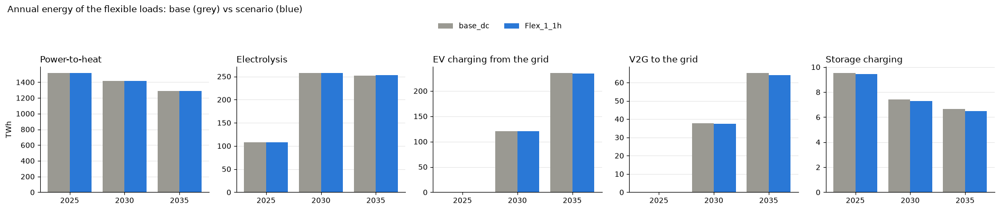

In [86]:
# 13.1 Annual energy of the flexible loads (TWh), the capacity (GW) and storage volume (GWh) behind them, flexible share (%)
def flex_annual(results, scenario):
    """Metric x year table of the flexible loads of one scenario (annual results)."""
    def total(symbol, query=None):
        try:
            t = scenario_result(results, scenario, symbol)
        except Exception:                                    # symbol not in this run (e.g. no EV add-on)
            return pd.Series(0.0, index=COMPARISON_YEARS)
        t = t.query(query) if query else t
        return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    rows = {f"{name} (TWh)": total("EL_DEMAND_YCR", f"Category == '{cat}'") for cat, name in FLEX_LOADS.items() if cat != "ENDO_EV"}
    rows["EV charging (TWh)"] = total("EV_G2V_Y")
    rows["V2G (TWh)"] = total("EV_V2G_Y")
    rows["EV net demand = charging - V2G (TWh)"] = total("EL_DEMAND_YCR", "Category == 'ENDO_EV'")
    rows["Flexible share of electricity demand (%)"] = 100 * total("EL_DEMAND_YCR", "Category in @FLEX_LOADS") / total("EL_DEMAND_YCR")
    rows["Power-to-heat capacity (GW)"] = total("G_CAP_YCRAF", "Technology == 'ELECT-TO-HEAT'")
    rows["Electrolyser capacity (GW)"] = total("G_CAP_YCRAF", "Technology == 'ELECTROLYZER'")
    rows["Heat storage volume (GWh)"] = total("G_STO_YCRAF", "Technology.str.contains('HEAT-STORAGE')")
    rows["H2 storage volume (GWh)"] = total("G_STO_YCRAF", "Technology == 'H2-STORAGE'")
    rows["Electricity storage volume (GWh)"] = total("G_STO_YCRAF", "Technology == 'INTRASEASONAL-ELECT-STORAGE'")
    return pd.DataFrame(rows).T

flex_ann = {BASE_SCENARIO: flex_annual(base_res, BASE_SCENARIO), SCENARIO: flex_annual(res, SCENARIO)}
table = pd.concat({"Base": flex_ann[BASE_SCENARIO], "Scenario": flex_ann[SCENARIO],
                   "Change": flex_ann[SCENARIO] - flex_ann[BASE_SCENARIO]}, axis=1).swaplevel(axis=1)
table = table.reindex(columns=pd.MultiIndex.from_product([COMPARISON_YEARS, ["Base", "Scenario", "Change"]]))
table = table.rename(index={"EV charging (TWh)": "EV charging from the grid (TWh)"})   # EV_G2V_Y
order = ["Power-to-heat (TWh)", "Electrolysis (TWh)", "EV charging from the grid (TWh)", "V2G (TWh)", "EV net demand = charging - V2G (TWh)",
         "Storage charging (TWh)", "Flexible share of electricity demand (%)", "Power-to-heat capacity (GW)", "Electrolyser capacity (GW)",
         "Heat storage volume (GWh)", "H2 storage volume (GWh)", "Electricity storage volume (GWh)"]
print(f"Flexible loads per year: {BASE_SCENARIO} (base) vs {SCENARIO} (scenario)")
display(table.reindex(order).round(2))

panels = [("Power-to-heat (TWh)", "Power-to-heat"), ("Electrolysis (TWh)", "Electrolysis"), ("EV charging (TWh)", "EV charging from the grid"),
          ("V2G (TWh)", "V2G to the grid"), ("Storage charging (TWh)", "Storage charging")]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels) + 1, 4))
x = np.arange(len(COMPARISON_YEARS))
for ax, (row, title) in zip(axes, panels):
    for i, run in enumerate(FLEX_RUNS):
        ax.bar(x + (i - 0.5) * 0.4, flex_ann[run].loc[row], 0.4, color=SCEN_COLORS[run], label=run)
    ax.set_xticks(x); ax.set_xticklabels(COMPARISON_YEARS)
    style(ax, title, "TWh" if ax is axes[0] else "")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.93))
fig.suptitle("Annual energy of the flexible loads: base (grey) vs scenario (blue)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.86)); plt.show()

### 13.2 Hour by hour: how do the flexible loads change?
The change (scenario − base) in the flexible loads summed over all regions in `FLEX_YEAR` (GW): one line per load (V2G positive = more energy to the grid), the net flexible demand (black: all flexible loads minus V2G), and the change in the demand-weighted European electricity price (dashed grey, right axis). One panel per season. When both runs have the same time steps, the change is shown per time step on real hours from the start of the season block. When the step lengths differ (e.g. a CHRONOHOUR study), the steps cover different hours, so the change is taken between the average days of the season instead.

KeyboardInterrupt: 

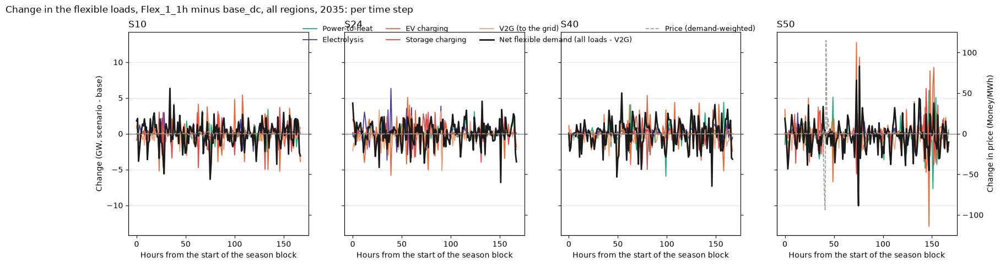

In [87]:
# 13.2 Change (scenario - base) in the flexible loads per time step, all of Europe, in FLEX_YEAR (GW), with the change in price
FLEX_CHANGE_COLS = FLEX_ORDER + ["V2G", "Net flexible demand", "Price"]
flex_eu = {}
for run in FLEX_RUNS:
    h = flex_h[run]
    eu = h.drop(columns="Price").groupby(level=["Season", "Time"]).sum() / 1e3                          # GW
    eu["Net flexible demand"] = eu[FLEX_ORDER].sum(axis=1) - eu["V2G"]                                  # EV charging minus V2G = net EV demand
    eu["Price"] = (h["Price"] * h["Total demand"]).groupby(level=["Season", "Time"]).sum() / h["Total demand"].groupby(level=["Season", "Time"]).sum()
    flex_eu[run] = eu

# Same time steps in both runs: change per time step. Different step lengths (e.g. a CHRONOHOUR study): the steps cover different
# hours, so the change is taken between the average days of the season (hour of the day, gaps between longer steps interpolated)
flex_same_steps = FLEX_STEP_H[BASE_SCENARIO] == FLEX_STEP_H[SCENARIO] and FLEX_TIMES[BASE_SCENARIO] == FLEX_TIMES[SCENARIO]

def flex_profile(run, season):
    e = flex_eu[run].xs(season, level="Season").reindex(FLEX_TIMES[run], fill_value=0)[FLEX_CHANGE_COLS]
    if flex_same_steps:
        return e.set_axis(np.arange(len(e)) * FLEX_STEP_H[run])                                         # real hours
    hour = np.floor(np.arange(len(e)) * FLEX_STEP_H[run] % 24).astype(int)
    return e.groupby(hour).mean().reindex(range(24)).interpolate(limit_direction="both")              # average day

fig, axes = plt.subplots(1, len(FLEX_SEASONS), figsize=(4.6 * len(FLEX_SEASONS) + 1, 4.8), sharey=True, squeeze=False)
twins = []
for k, (ax, season) in enumerate(zip(axes.ravel(), FLEX_SEASONS)):
    d = flex_profile(SCENARIO, season) - flex_profile(BASE_SCENARIO, season)
    for col in FLEX_ORDER + ["V2G"]:
        ax.plot(d.index, d[col], color=FLEX_COLORS[col], linewidth=1.3, label="V2G (to the grid)" if col == "V2G" else col)
    ax.plot(d.index, d["Net flexible demand"], color="#1a1a1a", linewidth=2, label="Net flexible demand (all loads - V2G)")
    ax.axhline(0, color="#52514e", linewidth=0.6)
    tw = ax.twinx()
    tw.plot(d.index, d["Price"], color="#9a9992", linewidth=1.2, linestyle="--", label="Price (demand-weighted)")
    twins.append(tw)
    style(ax, season, "Change (GW, scenario - base)" if k == 0 else "")
    ax.set_xlabel("Hours from the start of the season block" if flex_same_steps else "Hour of the day (average day of the season)")
    if not flex_same_steps:
        ax.set_xticks(range(0, 24, 4)); ax.set_xlim(0, 23)
lim = max(max(abs(v) for v in a.get_ylim()) for a in axes.ravel())
axes[0, 0].set_ylim(-lim, lim)                                                                          # symmetric around zero
lim_p = max(max(abs(v) for v in t.get_ylim()) for t in twins)
for k, tw in enumerate(twins):
    tw.set_ylim(-lim_p, lim_p)
    tw.set_ylabel("Change in price (Money/MWh)" if k == len(twins) - 1 else "")
    if k < len(twins) - 1:
        tw.tick_params(labelright=False)
handles = axes[0, 0].get_legend_handles_labels()[0] + twins[0].get_legend_handles_labels()[0]
labels = axes[0, 0].get_legend_handles_labels()[1] + twins[0].get_legend_handles_labels()[1]
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.93), fontsize=9)
how = "per time step" if flex_same_steps else f"average day per season (time steps of {FLEX_STEP_H[BASE_SCENARIO]:.2f} h vs {FLEX_STEP_H[SCENARIO]:.2f} h)"
fig.suptitle(f"Change in the flexible loads, {SCENARIO} minus {BASE_SCENARIO}, all regions, {FLEX_YEAR}: {how}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.82)); plt.show()

### 13.3 Do the flexible loads use cheap and renewable hours?
Per flexible load in `FLEX_YEAR`, over all regions and time steps:
- **Average price** paid (Money/MWh) = Σ load × regional price / Σ load, and the same **relative to the average price of all electricity demand** (below 100 % = the load runs in cheaper hours than demand on average). For V2G it is the price received, so above 100 % is good.
- **Share in below-median-price hours**: the share of the load's energy in time steps where the regional price is below that region's median price.
- **Correlation with the net load** (total demand minus onshore wind, offshore wind and solar, European sum per step): negative = the load runs when onshore wind, offshore wind and solar are plentiful.

The time steps carry equal weight within a run, so these are annual averages of the modelled year. A difference between base and scenario shows how much the time resolution changes the value of the flexibility.

In [ ]:
# 13.3 Price paid per MWh, share in below-median-price hours and correlation with the net load, per flexible load, FLEX_YEAR
FLEX_METRIC_LOADS = FLEX_ORDER + ["V2G", "Total demand"]

def flex_metrics(run):
    """Price and timing metrics per flexible load of one run (see the text above)."""
    h = flex_h[run]
    p = h["Price"]
    avg = (p * h["Total demand"]).sum() / h["Total demand"].sum()
    cheap = p < p.groupby(level="Region").transform("median")
    eu = h.groupby(level=["Season", "Time"]).sum()
    net_load = eu["Total demand"] - eu["Onshore + offshore wind + solar"]
    rows = {}
    for load in FLEX_METRIC_LOADS:
        e = h[load]
        if e.sum() <= 0:
            continue
        paid = (p * e).sum() / e.sum()
        rows[load] = {"Average price (Money/MWh)": paid,
                      "Relative to all demand (%)": 100 * paid / avg,
                      "Share in below-median-price hours (%)": 100 * e[cheap].sum() / e.sum(),
                      "Correlation with the net load": eu[load].corr(net_load)}
    return pd.DataFrame(rows).T

flex_m = {run: flex_metrics(run) for run in FLEX_RUNS}
metrics = pd.concat({"Base": flex_m[BASE_SCENARIO], "Scenario": flex_m[SCENARIO],
                     "Change": flex_m[SCENARIO] - flex_m[BASE_SCENARIO]}, axis=1).swaplevel(axis=1)
metrics = metrics.reindex(columns=pd.MultiIndex.from_product([flex_m[SCENARIO].columns, ["Base", "Scenario", "Change"]]))
print(f"Price and timing of the flexible loads, {FLEX_YEAR} (V2G: price received)")
display(metrics.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, ref, unit in [(axes[0], "Relative to all demand (%)", 100, "%"), (axes[1], "Share in below-median-price hours (%)", 50, "%"),
                           (axes[2], "Correlation with the net load", 0, "")]:
    loads = [l for l in FLEX_METRIC_LOADS if l in flex_m[SCENARIO].index]
    y = np.arange(len(loads))
    for i, run in enumerate(FLEX_RUNS):
        ax.barh(y + (0.5 - i) * 0.38, flex_m[run].reindex(loads)[col], 0.38, color=SCEN_COLORS[run], label=run)
    ax.axvline(ref, color="#52514e", linewidth=0.8, linestyle="--")
    ax.set_yticks(y); ax.set_yticklabels(loads); ax.invert_yaxis()
    style(ax, col, "", axis="x"); ax.set_xlabel(unit)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.93))
fig.suptitle(f"Timing of the flexible loads, {FLEX_YEAR}: dashed line = demand on average / median / no correlation", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.86)); plt.show()

### 13.4 Electric vehicles: daily profile and V2G per region
Left: the average EV charging (solid) and V2G (dashed, below zero) over the hours of the day, all regions, `FLEX_YEAR` (GW). The steps are placed at their real starting hour (steps longer than an hour fall on every few hours). Right: the annual V2G energy per region in the scenario (`V2G_FLEX_YCR`, TWh) and its change from the base; regions without V2G are hatched.

In [ ]:
# 13.4 EVs: average daily charging and V2G profile (GW) and V2G energy per region (TWh), FLEX_YEAR
fig, ax = plt.subplots(figsize=(10, 4.5))
for run in FLEX_RUNS:
    eu = flex_h[run][["EV charging", "V2G"]].groupby(level=["Season", "Time"]).sum() / 1e3
    hour = np.floor(eu.groupby(level="Season").cumcount().to_numpy() * FLEX_STEP_H[run] % 24).astype(int)
    prof = eu.groupby(hour).mean()
    ax.plot(prof.index, prof["EV charging"], color=SCEN_COLORS[run], linewidth=2, marker="o", markersize=3, label=f"Charging, {run}")
    ax.plot(prof.index, -prof["V2G"], color=SCEN_COLORS[run], linewidth=2, linestyle="--", marker="o", markersize=3, label=f"V2G, {run}")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5)
style(ax, f"EV charging and V2G by hour of the day, all regions, {FLEX_YEAR}", "GW (V2G below zero)")
ax.set_xlabel("Hour of the day")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

def flex_v2g(results, scenario):
    try:
        t = scenario_result(results, scenario, "V2G_FLEX_YCR")
    except Exception:
        return pd.Series(dtype=float)
    return t.loc[t["Year"].astype(str).eq(FLEX_YEAR)].groupby("Region")["Value"].sum()

v2g = pd.DataFrame({"Base": flex_v2g(base_res, BASE_SCENARIO), "Scenario": flex_v2g(res, SCENARIO)}).fillna(0)
v2g["Change"] = v2g["Scenario"] - v2g["Base"]
flex_geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
flex_modelled = flex_geo["id"].isin(flex_h[SCENARIO].index.unique("Region"))
flex_mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)
FLEX_BOUNDS = flex_geo.loc[flex_modelled].geometry.apply(flex_mainland).total_bounds

def flex_map(ax, values, cmap, norm, fmt, title):
    """Choropleth of `values` (indexed by region) on the modelled regions; regions without a value are hatched."""
    g = flex_geo[flex_modelled].assign(Value=lambda d: d["id"].map(values))
    flex_geo[~flex_modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    if g["Value"].isna().any():
        g[g["Value"].isna()].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5, hatch="///")
    if g["Value"].notna().any():
        g[g["Value"].notna()].plot(ax=ax, column="Value", cmap=cmap, norm=norm, edgecolor="#52514e", linewidth=0.5)
    for _, row in g[g["Value"].notna()].iterrows():
        p = flex_mainland(row.geometry).representative_point()
        v = norm(row["Value"])
        dark = v > 0.75 or (isinstance(norm, TwoSlopeNorm) and v < 0.25)       # white text on the dark ends of the scale
        ax.annotate(fmt.format(row["Value"]), (p.x, p.y), ha="center", va="center", fontsize=6.5, color="white" if dark else "#1a1a1a")
    minx, miny, maxx, maxy = FLEX_BOUNDS
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off(); ax.set_title(title, loc="left", fontsize=10)

has_v2g = v2g[["Base", "Scenario"]].max(axis=1) > 1e-6
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), layout="constrained")
level_norm = Normalize(0, max(v2g["Scenario"].max(), 1e-6))
lim = max(v2g["Change"].abs().max(), 1e-6)
change_norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
flex_map(axes[0], v2g.loc[has_v2g, "Scenario"], "YlOrRd", level_norm, "{:.1f}", f"V2G energy per region, scenario, {FLEX_YEAR} (TWh)")
flex_map(axes[1], v2g.loc[has_v2g, "Change"], "RdBu_r", change_norm, "{:+.2f}", f"Change in V2G energy (scenario - base), {FLEX_YEAR} (TWh)")
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=level_norm), ax=axes[0], orientation="horizontal", shrink=0.7, label="TWh")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=change_norm), ax=axes[1], orientation="horizontal", shrink=0.7, label="TWh")
plt.show()
print(f"V2G energy per region, {FLEX_YEAR} (TWh), largest first")
display(v2g.loc[has_v2g].sort_values("Scenario", ascending=False).round(2))

### 13.5 The storage behind the flexibility
State of charge (% of the installed volume, all regions) per time step in `FLEX_YEAR` of the heat storage that lets power-to-heat shift, the H2 storage behind the electrolysers, and the electricity storage. One column per season, base (grey) and scenario (blue) on the same real-hour axis (a run with longer time steps covers more hours). Storage that cycles within a day shows the flexibility is used daily; a slow drift shows it is used across days.

In [ ]:
# 13.5 State of charge (% of volume) of the heat, H2 and electricity storage per time step, all regions, FLEX_YEAR
def flex_volume(results, scenario):
    t = scenario_result(results, scenario, "G_STO_YCRAF")
    t = t.loc[t["Year"].astype(str).eq(FLEX_YEAR) & t["Technology"].isin(FLEX_SOC)]
    return t.groupby("Technology")["Value"].sum() * 1e3                       # GWh -> MWh

flex_vol = {BASE_SCENARIO: flex_volume(base_res, BASE_SCENARIO), SCENARIO: flex_volume(res, SCENARIO)}
fig, axes = plt.subplots(len(FLEX_SOC), len(FLEX_SEASONS), figsize=(4.4 * len(FLEX_SEASONS) + 1, 3 * len(FLEX_SOC) + 1),
                         sharey=True, squeeze=False)
for i, (tech, name) in enumerate(FLEX_SOC.items()):
    for j, season in enumerate(FLEX_SEASONS):
        ax = axes[i, j]
        for run in FLEX_RUNS:
            lvl = flex_raw[run]["STORAGE_LEVEL"]
            lvl = lvl.loc[lvl["Technology"].eq(tech) & lvl["Season"].eq(season)].groupby("Time")["Value"].sum().reindex(FLEX_TIMES[run], fill_value=0)
            vol = flex_vol[run].get(tech, np.nan)
            ax.plot(np.arange(len(lvl)) * FLEX_STEP_H[run], 100 * lvl / vol, color=SCEN_COLORS[run], linewidth=1.5, label=run)
        ax.set_ylim(0, 100)
        style(ax, f"{name}, {season}", "% of volume" if j == 0 else "")
        if i == len(FLEX_SOC) - 1:
            ax.set_xlabel("Hours from the start of the season block")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
fig.suptitle(f"State of charge of the storage behind the flexible loads, all regions, {FLEX_YEAR}", x=0.01, ha="left", y=1.0)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

### 13.6 Map: flexible share of the electricity demand per region
The flexible loads (power-to-heat, electrolysis, net EV demand and storage charging) as a share of each region's annual electricity demand (`EL_DEMAND_YCR`) in `FLEX_YEAR`: base, scenario (same colour scale) and change in percentage points.

In [ ]:
# 13.6 Flexible share of the annual electricity demand per region (%), base, scenario and change, FLEX_YEAR
def flex_share(results, scenario):
    t = scenario_result(results, scenario, "EL_DEMAND_YCR")
    t = t.loc[t["Year"].astype(str).eq(FLEX_YEAR)]
    return 100 * t.loc[t["Category"].isin(FLEX_LOADS)].groupby("Region")["Value"].sum() / t.groupby("Region")["Value"].sum()

share = pd.DataFrame({"Base": flex_share(base_res, BASE_SCENARIO), "Scenario": flex_share(res, SCENARIO)})
share["Change (pp)"] = share["Scenario"] - share["Base"]
level_norm = Normalize(0, share[["Base", "Scenario"]].max().max())
lim = max(share["Change (pp)"].abs().max(), 1e-6)
change_norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
fig, axes = plt.subplots(1, 3, figsize=(20, 7.5), layout="constrained")
flex_map(axes[0], share["Base"], "YlGnBu", level_norm, "{:.0f}", f"Base: {BASE_SCENARIO}")
flex_map(axes[1], share["Scenario"], "YlGnBu", level_norm, "{:.0f}", f"Scenario: {SCENARIO}")
flex_map(axes[2], share["Change (pp)"], "RdBu_r", change_norm, "{:+.1f}", "Change (scenario - base)")
fig.colorbar(plt.cm.ScalarMappable(cmap="YlGnBu", norm=level_norm), ax=axes[:2], orientation="horizontal", shrink=0.5,
             label="Flexible share of the electricity demand (%)")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=change_norm), ax=axes[2], orientation="horizontal", shrink=0.8, label="Percentage points")
fig.suptitle(f"Flexible share of the electricity demand per region, {FLEX_YEAR}", x=0.01, ha="left")
plt.show()
print(f"Flexible share of the electricity demand per region, {FLEX_YEAR} (%), largest share first")
display(share.sort_values("Scenario", ascending=False).round(1))